# Global Multi-Asset Momentum and Adaptive Risk Allocation

> Final product: ** Ji-chul . At the centre of the dynamic Top10 asset selection layer, the fully dynamic double-tier risk budget and the strict EWMA risk parity, the category of distributed attack sleeves was dynamically adjusted to range from 0 to 30 per cent, depending on trends.

# Part I. Data, Parameters, and Calibration

### 1.1 Parameters, Dynamic Warden and Sample Division


- Data source: Yahoo Finance ' s compound price;
- Monetary currency: Singapore dollar (ZXQ0QZ);
- Core asset pool: a total of 18 targets, including Yen FXY and Euro FXE; all ETF except Bitcoin;
- Top10 main signal: 12-1 momentum; contrast signal: cumulative gain over the past 126 trading days;
- Collegium window: 252 trading days; EWMA decay factor: 0.94;
- Check every 15 transaction days; the date $t$ closes only using data up to $t$ to form a signal, with the target weights effective from the revenue range of the next transaction date; the daily frequency return is measured to collect the receipt close to the next transaction date and cannot be interpreted as an accurate open transaction;
- ERC trigger: the maximum risk contribution deviation, for example, exceeds 5 percentage points;
- Other strategy triggers: maximum asset weight deviation from target by more than 3 percentage points;
- Basic transaction costs: the actual purchase and sale value per unit is charged 0.05 per cent; the actual implementation strategy is divided by the difference in the value of assets and conservative exchange costs;
- No-risk rate: use of SORA days and one-day delay on available information;
- Sample endpoint: 2024-12-31; external starting point: 2025-01-01.
- Double risk budget: use of base risk budget for 40 per cent of equities, 35 per cent of bonds, 15 per cent of commodities, 5 per cent of foreign exchange, 5 per cent of encrypted assets; dynamic distribution of momentum and trend multipliers within categories.
- GARCH strategy: Project by item for the motor Top10 to be combined with GARCH (1,1) to forecast the differences in the matrix structure of 252 days;
- All-asset static pool strategy: no assets are screened, all 18 assets are configured and recommenced once a month.

In [1]:
import warnings
warnings.filterwarnings('ignore')

from pathlib import Path
import os
import sys

# Resolve the archived research directory when launched from the project root,
# a notebook frontend, or the command-line runner on another computer.
_research_candidates = []
if '__file__' in globals():
    _research_candidates.append(Path(__file__).resolve().parent)
for _parent in (Path.cwd(), *Path.cwd().parents):
    _research_candidates.extend([_parent, _parent / 'explore'])
PROJECT_ROOT = next((_candidate for _candidate in _research_candidates
                     if (_candidate / 'SORA_daily.csv').is_file()
                     and (_candidate / 'strategies.py').is_file()), None)
if PROJECT_ROOT is None:
    raise RuntimeError('Cannot locate the research folder. Open the project or explore directory.')
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from IPython import get_ipython
if get_ipython() is not None:
    get_ipython().run_line_magic('matplotlib', 'inline')
import yfinance as yf
from arch import arch_model

plt.style.use('seaborn-v0_8-white')
plt.rcParams['figure.figsize'] = (13, 6)
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'Arial Unicode MS', 'DejaVu Sans']
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 180)
pd.set_option('display.float_format', lambda value: f'{value:.2f}')

# The asset class is colored consistently in the ownership and contribution maps.
ASSET_CLASS_COLORS = {
    'Equities': '#C7253D', 'Bonds': '#2878B8', 'Commodities': '#F18713',
    'FX': '#67CDB4', 'Crypto': '#5C22D4', 'Cash': '#A7ADB4',
    'Trading Friction': '#6B4C3B', 'Other': '#C9CED4',
}

# Project-wide uniform product name, colour and chart layout. The policy logic uses the official name and the chart uses short labels.
STRATEGY_NAMES = {
    'inverse_vol': 'Global Momentum Inverse Volatility (GMI-IV)',
    'classic_erc': 'Global Momentum Classic Risk Parity (GMI-CRP)',
    'ewma_erc': 'Global Momentum EWMA Risk Parity (GMI-ERP)',
    'downside_erc': 'Global Momentum Downside Risk Parity (GMI-DRP)',
    'equal_weight': 'Global Multi-Asset Equal Weight (GMA-EW)',
    'single_dynamic': 'Global Momentum Dynamic Risk Budget (GMI-DRB)',
    'static_hierarchical': 'Global Momentum Static Hierarchical Risk Budget (GMI-SHRB)',
    'garch_erc': 'Global Momentum GARCH Risk Parity (GMI-GRP)',
    'fully_dynamic': 'Global Momentum Adaptive Hierarchical Risk Budget (GMI-AHRB)',
    'fixed_attack': 'Global Momentum Fixed Offensive Allocation (GMI-FOA)',
    'dynamic_attack': 'Global Momentum Adaptive Defense and Growth (GMI-ADG)',
    'monthly_erc': 'Global Multi-Asset Classic Risk Parity (GMA-CRP)',
}
STRATEGY_LABELS = {
    STRATEGY_NAMES['inverse_vol']: 'GMI-IV',
    STRATEGY_NAMES['classic_erc']: 'GMI-CRP',
    STRATEGY_NAMES['ewma_erc']: 'GMI-ERP',
    STRATEGY_NAMES['downside_erc']: 'GMI-DRP',
    STRATEGY_NAMES['equal_weight']: 'GMA-EW',
    STRATEGY_NAMES['single_dynamic']: 'GMI-DRB',
    STRATEGY_NAMES['static_hierarchical']: 'GMI-SHRB',
    STRATEGY_NAMES['garch_erc']: 'GMI-GRP',
    STRATEGY_NAMES['fully_dynamic']: 'GMI-AHRB',
    STRATEGY_NAMES['fixed_attack']: 'GMI-FOA',
    STRATEGY_NAMES['dynamic_attack']: 'GMI-ADG',
    STRATEGY_NAMES['monthly_erc']: 'GMA-CRP',
}
STRATEGY_COLORS = {
    STRATEGY_NAMES['inverse_vol']: '#45A3B8',
    STRATEGY_NAMES['classic_erc']: '#2A9D8F',
    STRATEGY_NAMES['ewma_erc']: '#5B8FD1',
    STRATEGY_NAMES['downside_erc']: '#78A083',
    STRATEGY_NAMES['equal_weight']: '#333333',
    STRATEGY_NAMES['single_dynamic']: '#E07A5F',
    STRATEGY_NAMES['static_hierarchical']: '#9C89B8',
    STRATEGY_NAMES['garch_erc']: '#7656A8',
    STRATEGY_NAMES['fully_dynamic']: '#3366A3',
    STRATEGY_NAMES['fixed_attack']: '#E6A23C',
    STRATEGY_NAMES['dynamic_attack']: '#9D2235',
    STRATEGY_NAMES['monthly_erc']: '#B07D4F',
}
MARKET_BENCHMARK_COLORS = {
    'ES3.SI': '#287271',
    'VT': '#3D518C',
}
plt.rcParams['axes.grid'] = False


def strategy_label(name):
    """Return compact strategy labels for every reader-facing chart element."""
    label = str(name)
    for full_name, abbreviation in sorted(
        STRATEGY_LABELS.items(), key=lambda item: len(item[0]), reverse=True
    ):
        label = label.replace(full_name, abbreviation)
    return label


def style_axis(ax, axis='both'):
    ax.grid(False)
    ax.set_facecolor('white')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_color('#AEB6BF')
    ax.spines['bottom'].set_color('#AEB6BF')
    return ax


def place_legend(ax, item_count=None, handles=None, labels=None):
    """Shows single rows when the legend is smaller; four rows at the top of the figure for more items."""
    if handles is None or labels is None:
        handles, labels = ax.get_legend_handles_labels()
    labels = [strategy_label(label) for label in labels]
    pairs = [(h, l) for h, l in zip(handles, labels) if l and not l.startswith('_')]
    if not pairs:
        return None
    handles, labels = map(list, zip(*pairs))
    count = len(labels) if item_count is None else item_count
    if count <= 6:
        return ax.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, -0.14),
                         ncol=count, fontsize=9, frameon=False)
    return ax.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, -0.14),
                     ncol=min(4, count), fontsize=8, frameon=False)

YF_CACHE = Path.cwd() / '.yf_cache'
YF_CACHE.mkdir(exist_ok=True)
yf.set_tz_cache_location(str(YF_CACHE.resolve()))

DOWNLOAD_START = '1990-01-01'
DOWNLOAD_END = '2026-10-02'
LOOKBACK = 252
VOL_LOOKBACK = 63
MOMENTUM_SKIP = 21
MOMENTUM_6M = 126
MA_WINDOW = 200
EWMA_LAMBDA = 0.94
TOP_N = 10
COST = 0.0005
INITIAL_CAPITAL_SGD = 1_000_000.0  # Initial funding assumed by currency P&L
# Real cost assumptions for manual fixation. The value is a proportion of the amount of the unilateral transaction and does not represent an itemized quote from the history of the holder.
MARKET_COMMISSION_RATE = {
    'United States': 0.00020, 'Germany': 0.00080, 'United Kingdom': 0.00050, 'Japan': 0.00050,
    'China': 0.00030, 'Hong Kong SAR': 0.00080, 'Singapore': 0.00060,
    'Global': 0.00040, 'Euro Area': 0.00040,
}
MARKET_SPREAD_SLIPPAGE_RATE = {
    'United States': 0.00030, 'Germany': 0.00080, 'United Kingdom': 0.00080, 'Japan': 0.00060,
    'China': 0.00100, 'Hong Kong SAR': 0.00080, 'Singapore': 0.00080,
    'Global': 0.00050, 'Euro Area': 0.00050,
}
FX_CONVERSION_RATE = {
    'SGD': 0.0, 'USD': 0.0010, 'EUR': 0.0015, 'GBP': 0.0015,
    'JPY': 0.0015, 'CNY': 0.0020, 'HKD': 0.0015,
}
# Annualized withholding tax drag agent: assumed allocation rate x applied withholding rate; non-distributed asset set to zero.
ANNUAL_WITHHOLDING_TAX_DRAG = {
    'SPY': 0.0036, 'QQQ': 0.0018, 'IWM': 0.0036, 'EXS1.DE': 0.0038,
    'ISF.L': 0.0, '1308.T': 0.0030, '510300.SS': 0.0025,
    '2800.HK': 0.0, 'ES3.SI': 0.0, 'IEF': 0.0105,
    '511010.SS': 0.0020, 'USO': 0.0, 'DBB': 0.0, 'GLD': 0.0,
    'UUP': 0.0015, 'FXY': 0.0015, 'FXE': 0.0015, 'BTC-USD': 0.0,
}
IMPACT_LOOKBACK = 20
IMPACT_COEFFICIENT = 0.10
MAX_IMPACT_RATE = 0.01
TRADING_DAYS = 252
IN_SAMPLE_END = pd.Timestamp('2024-12-31')
OOS_START = pd.Timestamp('2025-01-01')
HOLDOUT_START = pd.Timestamp('2026-08-01')
HOLDOUT_END = pd.Timestamp('2026-10-01')
RESEARCH_END = HOLDOUT_START - pd.Timedelta(days=1)
RC_TRIGGER = 0.05
WEIGHT_TRIGGER = 0.03
CHECK_INTERVAL = 15

print(
    f'Configuration loaded: formal one-way cost={COST:.2%}; '
    f'realistic costs are a separate scenario; Top N={TOP_N}; '
    'all signals execute no earlier than the next trading-day close.'
)


Configuration loaded: formal one-way cost=0.05%; realistic costs are a separate scenario; Top N=10; all signals execute no earlier than the next trading-day close.


### 1.2 Daily SORA Risk-Free Rate Used by All Strategies


The fixed 1.40 per cent risk-free rate has been deleted. All strategies use `SORA_daily.csv` for cash gains, leverage financing costs, Sharp ratio and Sotino ratio. The original SORA value is an annual percentage; in order to avoid future information, only SORA, which was formed on the previous Singapore business day, is used for the return date. Cash gains are calculated on the basis of the actual calendar days and the ACT/365 caliber; the lock-in test period SORA is allowed to be loaded only in the final test module.

In [2]:
SORA_FILE = Path.cwd() / 'SORA_daily.csv'


def load_sora_daily(max_date):
    if not SORA_FILE.exists():
        raise FileNotFoundError(f'Missing day SORA file:{SORA_FILE}')
    frame = pd.read_csv(SORA_FILE)
    required_columns = {'Date', 'SORA'}
    if not required_columns.issubset(frame.columns):
        raise ValueError(f'SORA files must contain columns:{sorted(required_columns)}')
    frame = frame[['Date', 'SORA']].copy()
    frame['Date'] = pd.to_datetime(frame['Date'], errors='raise')
    if frame['Date'].duplicated().any():
        duplicated = frame.loc[frame['Date'].duplicated(keep=False), 'Date'].dt.date.tolist()[:5]
        raise ValueError(f'SORA has repeated dates, for example:{duplicated}')
    frame['SORA'] = pd.to_numeric(frame['SORA'], errors='raise')
    if frame['SORA'].isna().any() or (frame['SORA'] <= -100.0).any():
        raise ValueError('SORA contains missing values or an unlikely annualized interest rate.')
    frame = frame.sort_values('Date').set_index('Date').loc[:pd.Timestamp(max_date)].copy()
    frame = frame.rename(columns={'SORA': 'SORA annualized rate (%)'})
    # SORA is the overnight interest rate; in order to avoid a dispute as to the date of publication, only the last formed SORA is used.
    frame['Annualized SORA interest rate available for retrospect (%)'] = frame['SORA annualized rate (%)'].shift(1)
    frame['Single-day risk-free rate of return (ACT/365)'] = frame['Annualized SORA interest rate available for retrospect (%)'] / 100.0 / 365.0
    frame = frame.dropna(subset=['Annualized SORA interest rate available for retrospect (%)', 'Single-day risk-free rate of return (ACT/365)'])
    if frame.empty:
        raise RuntimeError('Day SORA data is empty.')
    return frame


def align_sora_returns(index, sora_frame, allow_holdout=False, annual_spread=0.0):
    index = pd.DatetimeIndex(index)
    if len(index) == 0:
        return pd.Series(dtype=float, index=index, name='Day-free rate of return')
    if index.max() >= HOLDOUT_START and not allow_holdout:
        raise RuntimeError('The reading of SORA data outside the locked sample is prohibited at the research stage.')
    if sora_frame.index.max() >= HOLDOUT_START and not allow_holdout:
        raise RuntimeError('SORA DataFrame, which was introduced during the research phase, contains lock-in data.')
    annual_rate = (
        sora_frame['Annualized SORA interest rate available for retrospect (%)'].reindex(index).ffill() / 100.0
        + float(annual_spread)
    )
    if annual_rate.isna().any():
        missing_dates = annual_rate.index[annual_rate.isna()][:5].date.tolist()
        raise RuntimeError(f'SORA cannot overwrite the policy date. Example:{missing_dates}')
    calendar_days = index.to_series().diff().dt.days.astype(float)
    calendar_days.iloc[0] = 1.0
    if (calendar_days <= 0).any():
        raise RuntimeError('The strategic dates must be strictly incremental in order to calculate SORA against ACT/365.')
    daily = annual_rate * calendar_days.to_numpy() / 365.0
    label = 'Rate of return on day financing' if annual_spread else 'Day-free rate of return'
    return pd.Series(daily.to_numpy(), index=index, name=label)


# The physical cut-off at the research stage does not leave SORA in the study of DataFrame.
sora_daily_df = load_sora_daily(RESEARCH_END)
assert sora_daily_df.index.max() < HOLDOUT_START
display(sora_daily_df.tail())
print(f'Research-period SORA: {sora_daily_df.index.min().date()} to {sora_daily_df.index.max().date()}; no fixed risk-free-rate proxy is used.')


,SORA annualized rate (%),Annualized SORA interest rate available for retrospect (%),Single-day risk-free rate of return (ACT/365)
Date,,,
2026-07-27,1.06,1.17,0.00
2026-07-28,0.95,1.06,0.00
2026-07-29,0.91,0.95,0.00
2026-07-30,0.97,0.91,0.00
2026-07-31,0.83,0.97,0.00


Research-period SORA: 2010-01-05 to 2026-07-31; no fixed risk-free-rate proxy is used.


### 1.3 Asset Universe and ETF Mapping

In [3]:
asset_rows = [
    ('Equities', 'United States', 'S&P 500', 'SPY', 'SPDR S&P 500 ETF Trust', 'USD'),
    ('Equities', 'United States', 'NASDAQ 100', 'QQQ', 'Invesco QQQ Trust', 'USD'),
    ('Equities', 'United States', 'Russell 2000', 'IWM', 'iShares Russell 2000 ETF', 'USD'),
    ('Equities', 'Germany', 'DAX, Germany', 'EXS1.DE', 'iShares Core DAX UCITS ETF', 'EUR'),
    ('Equities', 'United Kingdom', 'FTSE 100', 'ISF.L', 'iShares Core FTSE 100 UCITS ETF', 'GBP'),
    ('Equities', 'Japan', 'TOPIX', '1308.T', 'Listed Index Fund TOPIX', 'JPY'),
    ('Equities', 'China', 'CSI 300', '510300.SS', 'Huatai-PineBridge CSI 300 ETF', 'CNY'),
    ('Equities', 'Hong Kong SAR', 'Hang Seng Index', '2800.HK', 'Tracker Fund of Hong Kong', 'HKD'),
    ('Equities', 'Singapore', 'Straits Times Index', 'ES3.SI', 'SPDR Straits Times Index ETF', 'SGD'),
    ('Bonds', 'United States', 'United States Treasury 7-10 years', 'IEF', 'iShares 7-10 Year Treasury Bond ETF', 'USD'),
    ('Bonds', 'China', 'China 5-Year Government Bond', '511010.SS', 'Government Bond ETF', 'CNY'),
    ('Commodities', 'Global', 'Energy (oil)', 'USO', 'United States Oil Fund', 'USD'),
    ('Commodities', 'Global', 'Industrial metals', 'DBB', 'Invesco DB Base Metals Fund', 'USD'),
    ('Commodities', 'Global', 'Gold', 'GLD', 'SPDR Gold Shares', 'USD'),
    ('FX', 'United States', 'United States dollar index', 'UUP', 'Invesco DB US Dollar Index Bullish Fund', 'USD'),
    ('FX', 'Japan', 'Japanese yen', 'FXY', 'Invesco CurrencyShares Japanese Yen Trust', 'USD'),
    ('FX', 'Euro Area', 'Euro', 'FXE', 'Invesco CurrencyShares Euro Trust', 'USD'),
    ('Crypto', 'Global', 'Bitcoin', 'BTC-USD', 'Bitcoin', 'USD'),
]

assets = pd.DataFrame(asset_rows, columns=['Asset Class', 'Market', 'Asset Name', 'Code', 'ETF English Name', 'Local Currency']).set_index('Code')
display(assets)

ALL_ASSETS = assets.index.tolist()
EQUITIES = assets.query("`Asset Class` == 'Equities'").index.tolist()
BONDS = assets.query("`Asset Class` == 'Bonds'").index.tolist()

print(f'Equities: {len(EQUITIES)}; bonds: {len(BONDS)}; total risky assets: {len(ALL_ASSETS)}.')


PORTFOLIO_ASSETS = ALL_ASSETS.copy()
asset_metadata = assets.copy()

print(f'Formal asset universe: {len(PORTFOLIO_ASSETS)} instruments.')


,Asset Class,Market,Asset Name,ETF English Name,Local Currency
Code,,,,,
SPY,Equities,United States,S&P 500,SPDR S&P 500 ETF Trust,USD
QQQ,Equities,United States,NASDAQ 100,Invesco QQQ Trust,USD
IWM,Equities,United States,Russell 2000,iShares Russell 2000 ETF,USD
EXS1.DE,Equities,Germany,"DAX, Germany",iShares Core DAX UCITS ETF,EUR
ISF.L,Equities,United Kingdom,FTSE 100,iShares Core FTSE 100 UCITS ETF,GBP
1308.T,Equities,Japan,TOPIX,Listed Index Fund TOPIX,JPY
510300.SS,Equities,China,CSI 300,Huatai-PineBridge CSI 300 ETF,CNY
2800.HK,Equities,Hong Kong SAR,Hang Seng Index,Tracker Fund of Hong Kong,HKD
ES3.SI,Equities,Singapore,Straits Times Index,SPDR Straits Times Index ETF,SGD


Equities: 9; bonds: 2; total risky assets: 18.
Formal asset universe: 18 instruments.


### 1.4 Tradable Prices, FX Conversion, and the Global Valuation Calendar


Yahoo Finance's ETF prices are denominated in the respective market currency. Each local currency price is multiplied by the corresponding exchange rate of “how much SDD is convertible per unit of foreign currency” and the net value of SSD assets is uniformly obtained.

Inter-market break days vary, so the global valuation calendar is used from Monday to Friday, with up to five working days in advance only for the most recent prices that have occurred. That treatment would not use future prices; bitcoin would also be valued only on working days, and the cumulative change over weekends would be reflected in the next working day.

In [4]:
FX_DOWNLOAD = ['SGD=X', 'EURSGD=X', 'GBPSGD=X', 'JPY=X', 'CNY=X', 'HKDSGD=X']
VIX_TICKERS = ['^VIX', '^VIX3M']
MARKET_BENCHMARK_TICKERS = ['VT']
download_tickers = PORTFOLIO_ASSETS + FX_DOWNLOAD + VIX_TICKERS + MARKET_BENCHMARK_TICKERS
raw = yf.download(
    download_tickers,
    start=DOWNLOAD_START,
    end=DOWNLOAD_END,
    auto_adjust=True,
    progress=False,
    threads=False,
    group_by='column'
)

if raw.empty:
    raise RuntimeError('Yahoo Finance does not return the data, please check the network connection and restart.')

close_local = raw['Close'].reindex(columns=ALL_ASSETS)
volume_local = raw['Volume'].reindex(columns=ALL_ASSETS)
fx_close = raw['Close'].reindex(columns=FX_DOWNLOAD)
vix_close = raw['Close'].reindex(columns=VIX_TICKERS)
market_benchmark_close_local = raw['Close'].reindex(columns=MARKET_BENCHMARK_TICKERS)

coverage = pd.DataFrame({
    'Minimum Effective Date': close_local.apply(lambda s: s.first_valid_index()),
    'Last effective date': close_local.apply(lambda s: s.last_valid_index()),
    'Effective observations': close_local.notna().sum(),
}).join(assets[['Asset Class', 'Asset Name', 'Local Currency']])
coverage = coverage[['Asset Class', 'Asset Name', 'Local Currency', 'Minimum Effective Date', 'Last effective date', 'Effective observations']]
display(coverage)

missing = coverage.index[coverage['Effective observations'].eq(0)].tolist()
if missing:
    raise RuntimeError(f'No data available for:{missing}')

calendar_start = min(close_local.apply(lambda s: s.first_valid_index()))
calendar_end = max(close_local.apply(lambda s: s.last_valid_index()))
calendar = pd.bdate_range(calendar_start, calendar_end)

local_bday = close_local.reindex(calendar).ffill(limit=5)
volume_bday = volume_local.reindex(calendar)
fx_bday = fx_close.reindex(calendar).ffill(limit=5)
vix_bday = vix_close.reindex(calendar).ffill(limit=5)
vix_open = raw['Open'].reindex(columns=VIX_TICKERS)
vix_open_bday = vix_open.reindex(calendar).ffill(limit=5)

# Yahoo's JPYSGD=X, CNYSGD=X history occasionally returns only the latest day and is constructed using the United States dollar cross-exchange rate.
# SGD=X, JPY=X, CNY=X, CNY=X each of the corresponding SGD, JPY, and CNY numbers.
fx_to_sgd = pd.DataFrame(index=calendar)
fx_to_sgd['USD'] = fx_bday['SGD=X']
fx_to_sgd['EUR'] = fx_bday['EURSGD=X']
fx_to_sgd['GBP'] = fx_bday['GBPSGD=X']
fx_to_sgd['JPY'] = fx_bday['SGD=X'] / fx_bday['JPY=X']
fx_to_sgd['CNY'] = fx_bday['SGD=X'] / fx_bday['CNY=X']
fx_to_sgd['HKD'] = fx_bday['HKDSGD=X']

prices_sgd = pd.DataFrame(index=calendar, columns=ALL_ASSETS, dtype=float)
for ticker, row in assets.iterrows():
    ccy = row['Local Currency']
    if ccy == 'SGD':
        prices_sgd[ticker] = local_bday[ticker]
    else:
        prices_sgd[ticker] = local_bday[ticker] * fx_to_sgd[ccy]

# All assets have common areas after the available prices; they are not filled backwards or artificially prolonged.
common_start = max(prices_sgd[col].first_valid_index() for col in ALL_ASSETS)
common_end = min(prices_sgd[col].last_valid_index() for col in ALL_ASSETS)
prices_sgd = prices_sgd.loc[common_start:common_end].dropna(how='any')
dollar_volume_sgd = prices_sgd * volume_bday.reindex(prices_sgd.index)
returns = prices_sgd.pct_change(fill_method=None).dropna(how='any')

# The investmentable market benchmark is converted uniformly to the total SSD return; VT is the United States dollar ETF, ES3.SI itself traded with SGD.
market_benchmark_local_bday = market_benchmark_close_local.reindex(calendar).ffill(limit=5)
benchmark_prices_sgd = pd.DataFrame(index=prices_sgd.index, dtype=float)
benchmark_prices_sgd['ES3.SI'] = prices_sgd['ES3.SI']
benchmark_prices_sgd['VT'] = (
    market_benchmark_local_bday['VT'].reindex(prices_sgd.index)
    * fx_to_sgd['USD'].reindex(prices_sgd.index)
)
if benchmark_prices_sgd[['ES3.SI', 'VT']].isna().all().any():
    raise RuntimeError('ZXQ0QZSI or VT market benchmarks do not have available SGD prices.')
benchmark_returns_sgd = benchmark_prices_sgd.pct_change(fill_method=None).dropna(how='any')

portfolio_prices_sgd = prices_sgd.copy()
portfolio_returns_for_backtest = returns.copy()
# VIX retains a combination of the independent history prior to the start, so that the full three-year score can also be used for the first transaction date.
vix_data = vix_bday.loc[:returns.index[-1]].dropna(how='any')
if vix_data.empty or not returns.index.isin(vix_data.index).all():
    raise RuntimeError('The VIX pressure indicator does not cover all of the return dates.')

if len(returns) <= LOOKBACK:
    raise RuntimeError(f'Common effective benefits only{len(returns)}Shit, that\'s not enough.{LOOKBACK}Day risk estimation window.')

strategy_start = returns.index[LOOKBACK]
data_summary = pd.DataFrame({
    'Value': [common_start.date(), common_end.date(), strategy_start.date(), len(prices_sgd), len(returns)]
}, index=['Common price starting point', 'Common price destination', 'Practical starting point for the strategy (including 252-day pre-heat)', 'Common price observations', 'Co-benefit observations'])
display(data_summary)


,Asset Class,Asset Name,Local Currency,Minimum Effective Date,Last effective date,Effective observations
Ticker,,,,,,
SPY,Equities,S&P 500,USD,1993-01-29,2026-10-01,8476
QQQ,Equities,NASDAQ 100,USD,1999-03-10,2026-10-01,6934
IWM,Equities,Russell 2000,USD,2000-05-26,2026-10-01,6626
EXS1.DE,Equities,"DAX, Germany",EUR,2008-01-02,2026-10-01,4761
ISF.L,Equities,FTSE 100,GBP,2009-01-02,2026-10-01,4483
1308.T,Equities,TOPIX,JPY,2008-01-04,2026-10-01,4600
510300.SS,Equities,CSI 300,CNY,2012-05-04,2026-09-30,3489
2800.HK,Equities,Hang Seng Index,HKD,2008-01-02,2026-09-30,4619
ES3.SI,Equities,Straits Times Index,SGD,2008-01-02,2026-10-01,4703


,Value
Common price starting point,2014-09-17
Common price destination,2026-10-01
Practical starting point for the strategy (including 252-day pre-heat),2015-09-07
Common price observations,3134
Co-benefit observations,3133


# Part II. Signals, Risk Models, and Portfolio Optimization

This section is organized by “Note-Code”. Each subsection defines only the signal, risk model or weight function described in the heading; all inputs are from historical data already available at the decision-making point of the warehouse.

### 2.1 Momentum and Trend Variables

Define a six-month drive, 12-1 momentum and MA200 trend state for asset screening and dynamic risk budgeting.

In [5]:
def momentum_6m(history):
    return (1.0 + history.iloc[-MOMENTUM_6M:]).prod() - 1.0


def momentum_12_1(history):
    return (1.0 + history.iloc[-LOOKBACK:-MOMENTUM_SKIP]).prod() - 1.0


def above_ma200(history):
    normalized_price = (1.0 + history).cumprod()
    return normalized_price.iloc[-1] > normalized_price.iloc[-MA_WINDOW:].mean()


### 2.2 EWMA and Downside Risk Models

The EWMA Annual Difference Matrix and the following line zero yield are estimated to be the threshold of the annualized bottom-up matrix.

In [6]:
def ewma_covariance(history, decay=EWMA_LAMBDA):
    x = history.astype(float)
    raw_weights = decay ** np.arange(len(x) - 1, -1, -1)
    weights = raw_weights / raw_weights.sum()
    mean = np.average(x.values, axis=0, weights=weights)
    centered = x.values - mean
    denominator = max(1.0 - np.sum(weights ** 2), 1e-12)
    covariance = (centered * weights[:, None]).T @ centered / denominator
    return pd.DataFrame(covariance * TRADING_DAYS, index=x.columns, columns=x.columns)


def downside_second_moment(history):
    downside = np.minimum(history.astype(float).values, 0.0)
    matrix = downside.T @ downside / len(downside)
    return pd.DataFrame(matrix * TRADING_DAYS, index=history.columns, columns=history.columns)


### 2.3 Strict ERC Solver

Calculated the share of asset risk contribution and verified errors in target contribution through a rigorous risk budget.

In [7]:
def risk_contribution_share(weights, covariance):
    w = pd.Series(weights, dtype=float).reindex(covariance.index).fillna(0.0)
    variance = float(w.values @ covariance.values @ w.values)
    if variance <= 0 or not np.isfinite(variance):
        return pd.Series(np.nan, index=covariance.index)
    return w * (covariance @ w) / variance


def strict_risk_budget(covariance, budget=None, tol=1e-8, max_iter=5000):
    cov = pd.DataFrame(covariance, dtype=float).copy()
    cov = (cov + cov.T) / 2
    n = len(cov)
    if budget is None:
        budget = pd.Series(1.0 / n, index=cov.index)
    budget = pd.Series(budget, dtype=float).reindex(cov.index)
    budget = budget / budget.sum()
    if n == 1:
        return pd.Series(1.0, index=cov.index)

    eig_min = np.linalg.eigvalsh(cov.values).min()
    if eig_min <= 1e-10:
        cov.values[np.diag_indices_from(cov.values)] += 1e-10 - eig_min

    sigma = cov.values
    b = budget.values
    x = np.sqrt(b) / np.sqrt(np.maximum(np.diag(sigma), 1e-12))
    x = np.maximum(x, 1e-12)

    for _ in range(max_iter):
        old = x.copy()
        sx = sigma @ x
        for i in range(n):
            cross = sx[i] - sigma[i, i] * x[i]
            x_new = (-cross + np.sqrt(cross * cross + 4 * sigma[i, i] * b[i])) / (2 * sigma[i, i])
            delta = x_new - x[i]
            x[i] = max(x_new, 1e-12)
            sx += sigma[:, i] * delta
        if np.max(np.abs(x - old)) < tol:
            break

    weights = pd.Series(x / x.sum(), index=cov.index)
    error = float((risk_contribution_share(weights, cov) - budget).abs().max())
    if not np.isfinite(error) or error > 1e-4:
        raise RuntimeError(f'Strict risk budget verification failed, maximum error ={error:.4%}')
    return weights


def strict_erc(covariance):
    return strict_risk_budget(covariance)


### 2.4 Top-10 Selection and Baseline Target Weights

Top10 is selected at 12-1 momentum and gives rise to a negative impact of volatility, classic ERC, ZXQ0QZ ZXQ1QZ, downline risk ERC and full assets.

In [8]:
def select_top10(history):
    score = momentum_12_1(history)
    return score.nlargest(TOP_N).index.tolist(), score


def target_momentum_inverse_vol(history):
    selected, score = select_top10(history)
    vol = history[selected].iloc[-VOL_LOOKBACK:].std(ddof=1) * np.sqrt(TRADING_DAYS)
    weights = (1.0 / vol.clip(lower=1e-8))
    weights /= weights.sum()
    return weights.reindex(ALL_ASSETS, fill_value=0.0), selected, score


def target_momentum_erc(history):
    selected, score = select_top10(history)
    weights = strict_erc(history[selected].cov() * TRADING_DAYS)
    return weights.reindex(ALL_ASSETS, fill_value=0.0), selected, score


def target_momentum_ewma_erc(history):
    selected, score = select_top10(history)
    weights = strict_erc(ewma_covariance(history[selected]))
    return weights.reindex(ALL_ASSETS, fill_value=0.0), selected, score


def target_momentum_downside_erc(history):
    selected, score = select_top10(history)
    weights = strict_erc(downside_second_moment(history[selected]))
    return weights.reindex(ALL_ASSETS, fill_value=0.0), selected, score


def target_equal_weight(history):
    return pd.Series(1.0 / len(ALL_ASSETS), index=ALL_ASSETS), ALL_ASSETS, pd.Series(np.nan, index=ALL_ASSETS)


### 2.5 Single-Level and Static Hierarchical Dynamic Risk Budgets

An asset-level dynamic risk budget is first defined, followed by a two-tiered risk budget with a fixed category budget and a dynamic distribution within the class.

In [9]:
def dynamic_risk_budget(history, selected, score):
    six_month = momentum_6m(history[selected])
    ma_signal = above_ma200(history[selected])
    rank_multiplier = 0.75 + 0.50 * score[selected].rank(pct=True)
    trend_multiplier = pd.Series(
        np.select([((six_month > 0) & ma_signal), ((six_month > 0) | ma_signal)],
                  [1.50, 1.00], default=0.50),
        index=selected,
    )
    raw_budget = rank_multiplier * trend_multiplier
    return raw_budget / raw_budget.sum()


def target_momentum_ewma_dynamic_budget(history):
    selected, score = select_top10(history)
    budget = dynamic_risk_budget(history, selected, score)
    weights = strict_risk_budget(ewma_covariance(history[selected]), budget)
    return weights.reindex(ALL_ASSETS, fill_value=0.0), selected, score

CLASS_RISK_BUDGET = pd.Series({
    'Equities': 0.40,
    'Bonds': 0.35,
    'Commodities': 0.15,
    'FX': 0.05,
    'Crypto': 0.05,
})


def hierarchical_dynamic_risk_budget(history, selected, score):
    """The base budget is allocated between categories and is distributed internally according to dynamics and trends."""
    selected = list(selected)
    final_budget = pd.Series(0.0, index=selected, dtype=float)
    selected_classes = assets.loc[selected, 'Asset Class']
    active_classes = [asset_class for asset_class in CLASS_RISK_BUDGET.index
                      if (selected_classes == asset_class).any()]
    active_class_budget = CLASS_RISK_BUDGET.loc[active_classes]
    active_class_budget = active_class_budget / active_class_budget.sum()

    for asset_class, class_budget in active_class_budget.items():
        class_assets = selected_classes.index[selected_classes == asset_class].tolist()
        six_month = momentum_6m(history[class_assets])
        ma_signal = above_ma200(history[class_assets])
        rank_multiplier = 0.75 + 0.50 * score[class_assets].rank(pct=True)
        trend_multiplier = pd.Series(
            np.select(
                [((six_month > 0) & ma_signal), ((six_month > 0) | ma_signal)],
                [1.50, 1.00],
                default=0.50,
            ),
            index=class_assets,
            dtype=float,
        )
        internal_budget = rank_multiplier * trend_multiplier
        internal_budget = internal_budget / internal_budget.sum()
        final_budget.loc[class_assets] = float(class_budget) * internal_budget

    final_budget = final_budget / final_budget.sum()
    return final_budget


def target_momentum_ewma_hierarchical_budget(history):
    selected, score = select_top10(history)
    budget = hierarchical_dynamic_risk_budget(history, selected, score)
    covariance = ewma_covariance(history[selected])
    weights = strict_risk_budget(covariance, budget)
    return weights.reindex(ALL_ASSETS, fill_value=0.0), selected, score


### 2.6 GARCH(1,1) Risk Model

A single variable, GARCH (1,1) is used to forecast the rate of fluctuations for the next period for each asset and is combined with a historically relevant matrix into an annual reconciliation matrix.

In [10]:
GARCH_VOL_CACHE = {}
GARCH_FIT_DIAGNOSTICS = []


def garch11_forecast_volatility(history):
    """The proceeds from the collection up to the signal date are to be matched to GARCH (1,1) and return to the rate of fluctuations in the conditions of the following day."""
    key = (pd.Timestamp(history.index[-1]), tuple(history.columns), len(history))
    if key in GARCH_VOL_CACHE:
        return GARCH_VOL_CACHE[key].copy()

    forecasts = {}
    for ticker in history.columns:
        series = history[ticker].dropna().astype(float) * 100.0
        model = arch_model(
            series, mean='Constant', vol='GARCH', p=1, o=0, q=1,
            dist='normal', rescale=False,
        )
        fitted = model.fit(disp='off', show_warning=False, options={'maxiter': 500})
        convergence_flag = int(fitted.convergence_flag)
        forecast_variance = np.nan
        if convergence_flag == 0:
            forecast_variance = float(
                fitted.forecast(horizon=1, reindex=False).variance.iloc[-1, 0]
            ) / 10000.0
        used_fallback = convergence_flag != 0 or not np.isfinite(forecast_variance) or forecast_variance <= 0
        if used_fallback:
            # The numerical optimization of individual windows may fail. The comparison strategy should not interrupt the entire study.
            # Therefore, the EWMA-day margin reserve for the same signal day is used only for failed assets.
            forecast_variance = float(
                ewma_covariance(history[[ticker]]).iloc[0, 0] / TRADING_DAYS
            )
        if not np.isfinite(forecast_variance) or forecast_variance <= 0:
            raise RuntimeError(f'{ticker}The difference between the GARCH and the EWMA reserve projection is not valid.')
        forecasts[ticker] = np.sqrt(forecast_variance)
        GARCH_FIT_DIAGNOSTICS.append({
            'Estimated date': history.index[-1], 'Assets': ticker,
            'Depress marks': convergence_flag, 'Use EWMA backup': used_fallback,
        })

    result = pd.Series(forecasts, index=history.columns, dtype=float)
    GARCH_VOL_CACHE[key] = result.copy()
    return result


def garch11_covariance(history):
    daily_volatility = garch11_forecast_volatility(history)
    correlation = history.corr().reindex(index=history.columns, columns=history.columns)
    correlation = correlation.fillna(0.0)
    correlation = ((correlation + correlation.T) / 2.0).copy()
    correlation_array = correlation.to_numpy(copy=True)
    np.fill_diagonal(correlation_array, 1.0)
    correlation = pd.DataFrame(correlation_array, index=history.columns, columns=history.columns)
    daily_covariance = correlation.mul(daily_volatility, axis=0).mul(daily_volatility, axis=1)
    return daily_covariance * TRADING_DAYS


def target_momentum_garch_erc(history):
    selected, score = select_top10(history)
    covariance = garch11_covariance(history[selected])
    weights = strict_erc(covariance)
    return weights.reindex(ALL_ASSETS, fill_value=0.0), selected, score


### 2.7 Fully Adaptive Hierarchical Risk Budget

The allocation of risk budgets between and within categories is based on the dynamics of momentum, trends and rankings, followed by the use of the EWMA agreement to resolve strict risk budget weights.

In [11]:
FULLY_DYNAMIC_BUDGET_NAME = STRATEGY_NAMES['fully_dynamic']


def fully_dynamic_class_budget(history, selected, score):
    """Outer layer: Class risk budgets vary according to category dynamic + category trends (as distinct from static CLASS_RISK_BUDGET)."""
    selected = list(selected)
    selected_classes = assets.loc[selected, 'Asset Class']
    active_classes = list(dict.fromkeys(selected_classes.tolist()))
    class_momentum = {}
    class_trend = {}
    for asset_class in active_classes:
        class_assets = selected_classes.index[selected_classes == asset_class].tolist()
        class_momentum[asset_class] = momentum_12_1(history[class_assets]).mean()
        six_month = momentum_6m(history[class_assets])
        ma_signal = above_ma200(history[class_assets])
        class_trend[asset_class] = float(((six_month > 0) & ma_signal).mean())
    momentum_series = pd.Series(class_momentum)
    rank_multiplier = 0.75 + 0.50 * momentum_series.rank(pct=True)
    trend_series = pd.Series(class_trend)
    trend_multiplier = pd.Series(
        np.select([trend_series >= 0.5, trend_series >= 0.25], [1.50, 1.00], default=0.50),
        index=trend_series.index,
    )
    raw = rank_multiplier * trend_multiplier
    return raw / raw.sum()


def fully_dynamic_budget(history, selected, score):
    """Full dynamic double layer: budgets within dynamic categories x budgets within dynamic categories."""
    selected = list(selected)
    class_budget = fully_dynamic_class_budget(history, selected, score)
    selected_classes = assets.loc[selected, 'Asset Class']
    final_budget = pd.Series(0.0, index=selected, dtype=float)
    for asset_class, class_weight in class_budget.items():
        class_assets = selected_classes.index[selected_classes == asset_class].tolist()
        six_month = momentum_6m(history[class_assets])
        ma_signal = above_ma200(history[class_assets])
        rank_multiplier = 0.75 + 0.50 * score[class_assets].rank(pct=True)
        trend_multiplier = pd.Series(
            np.select([((six_month > 0) & ma_signal), ((six_month > 0) | ma_signal)],
                      [1.50, 1.00], default=0.50),
            index=class_assets,
        )
        internal = rank_multiplier * trend_multiplier
        internal = internal / internal.sum()
        final_budget.loc[class_assets] = float(class_weight) * internal
    return final_budget / final_budget.sum()


def target_momentum_ewma_fulldynamic_budget(history):
    selected, score = select_top10(history)
    budget = fully_dynamic_budget(history, selected, score)
    weights = strict_risk_budget(ewma_covariance(history[selected]), budget)
    return weights.reindex(ALL_ASSETS, fill_value=0.0), selected, score


# Part III. Formal Strategy Construction and Trade Execution

### 3.1 Generic No Future Information Recovering Engine and Nine Basic Strategies


The 12 current formal strategies are non-leveraging: 100 per cent of the combined risk assets and cash weights. The code retains `funding_daily` fields to harmonize the result structure, but there is no negative cash position and no actual trigger cost of financing. If leverage is added in the future, financing spreads above SORA must be set and disclosed separately.

In [12]:
def sample_covariance(history):
    return history.cov() * TRADING_DAYS


DYNAMIC_BUDGET_NAME = STRATEGY_NAMES['single_dynamic']
HIERARCHICAL_BUDGET_NAME = STRATEGY_NAMES['static_hierarchical']
GARCH_MOMENTUM_NAME = STRATEGY_NAMES['garch_erc']

strategy_specs = {
    STRATEGY_NAMES['inverse_vol']: (target_momentum_inverse_vol, None),
    STRATEGY_NAMES['classic_erc']: (target_momentum_erc, sample_covariance),
    STRATEGY_NAMES['ewma_erc']: (target_momentum_ewma_erc, ewma_covariance),
    STRATEGY_NAMES['downside_erc']: (target_momentum_downside_erc, downside_second_moment),
    STRATEGY_NAMES['equal_weight']: (target_equal_weight, None),
    DYNAMIC_BUDGET_NAME: (target_momentum_ewma_dynamic_budget, None),
    HIERARCHICAL_BUDGET_NAME: (target_momentum_ewma_hierarchical_budget, None),
    GARCH_MOMENTUM_NAME: (target_momentum_garch_erc, garch11_covariance),
    FULLY_DYNAMIC_BUDGET_NAME: (target_momentum_ewma_fulldynamic_budget, None),
}


def prepare_target(name, target):
    target = pd.Series(target, dtype=float).reindex(PORTFOLIO_ASSETS).fillna(0.0).clip(lower=0.0)
    if target.sum() <= 0:
        raise RuntimeError(f'{name}Target weights are empty.')
    target /= target.sum()
    return target


def run_dynamic_backtest(
    name, allocator, covariance_function=None, end_date=RESEARCH_END,
    sora_frame=None, allow_holdout=False,
):
    """Scroll back: a signal is formed after the t-day closing, the t-+1-day closing is concluded and the new weight begins to yield benefits between the subsequent closing and the closing area.

(a) The transactional cost of the closing date is only deducted from the transaction cost of the closing date and does not allow new weights to yield the benefit before the transaction is made;
The calibre does not give new weights the benefit of signal dayst, but it is not equivalent to using real t+1 openings for sale.
"""
    if pd.Timestamp(end_date) >= HOLDOUT_START and not allow_holdout:
        raise RuntimeError('The study backsight prohibits reading outlet for locked samples.')
    sora_frame = sora_daily_df if sora_frame is None else sora_frame
    test_returns = portfolio_returns_for_backtest.loc[strategy_start:end_date].copy()
    cash_returns = align_sora_returns(test_returns.index, sora_frame, allow_holdout=allow_holdout)
    funding_returns = align_sora_returns(
        test_returns.index, sora_frame, allow_holdout=allow_holdout, annual_spread=0.0
    )
    current_w = pd.Series(0.0, index=PORTFOLIO_ASSETS)
    initialized = False
    pending_order = None
    start_position = returns.index.get_loc(strategy_start)

    daily_records, turnover_records, trade_leg_records, cost_records = [], [], [], []
    weight_records, selection_records, trigger_records = [], [], []
    pre_return_weight_records, end_of_day_weight_records, trade_delta_records = [], [], []

    for date in test_returns.index:
        position = returns.index.get_loc(date)
        # The revenue per day is the amount received from the previous collection to the same day. This is the first time that we can get the proceeds from the old warehouse.
        # The order is then collected on the same day to execute the order formed on the date of the previous transaction.
        pre_return_weight_records.append(current_w.rename(date))
        day = test_returns.loc[date]
        cash_weight = 1.0 - float(current_w.sum())
        cash_rate = cash_returns.loc[date] if cash_weight >= 0 else funding_returns.loc[date]
        before_cost_return = float(current_w @ day) + cash_weight * cash_rate
        denominator = 1.0 + before_cost_return
        if denominator <= 0:
            raise RuntimeError(f'{date.date()}Group net value is not positive.')
        current_w = current_w * (1.0 + day) / denominator

        cost_rate = 0.0
        if pending_order is not None:
            if not pending_order['Signal Date'] < date:
                raise RuntimeError(f'{date.date()}The order was not delayed until the next transaction date.')
            target = pending_order['Target weights']
            delta = target - current_w
            turnover = float(delta.abs().sum())
            trade_legs = int((delta.abs() > 1e-10).sum())
            cost_rate = COST * turnover
            current_w = target.copy()
            initialized = True
            turnover_records.append((date, turnover))
            trade_leg_records.append((date, trade_legs))
            cost_records.append((date, cost_rate))
            trade_delta_records.append(delta.rename(date))
            weight_records.append(current_w.rename(date))
            trigger_records.append({
                'Signal Date': pending_order['Signal Date'], 'Execution Date': date,
                'Reason': pending_order['Reason'], 'Trigger deviation': pending_order['Trigger deviation'],
                'Total asset weights': float(current_w.sum()), 'Transaction cost rate': cost_rate,
            })
            selection_records.extend([
                {'Rebalance Date': date, 'Signal Date': pending_order['Signal Date'], 'Policy': name,
                 'Code': ticker, 'Asset Name': asset_metadata.loc[ticker, 'Asset Name'],
                 'Motion Score': pending_order['Motion Score'].get(ticker, np.nan),
                 'Target weights': current_w[ticker]}
                for ticker in pending_order['Selected assets']
            ])
            pending_order = None

        net_return = (1.0 - cost_rate) * (1.0 + before_cost_return) - 1.0
        daily_records.append((date, net_return))
        end_of_day_weight_records.append(current_w.rename(date))

        history = returns.iloc[position - LOOKBACK + 1:position + 1]
        if len(history) != LOOKBACK or history.index.max() != date:
            raise RuntimeError(f'{date.date()}The signal window does not strictly close to the signal day closing or insufficient length.')
        check_today = (not initialized) or (position - start_position) % CHECK_INTERVAL == 0
        if check_today and pending_order is None:
            if name == STRATEGY_NAMES['equal_weight']:
                scores = pd.Series(np.nan, index=ALL_ASSETS)
                selected = ALL_ASSETS
            else:
                scores = momentum_12_1(history)
                selected = scores.nlargest(TOP_N).index.tolist()

            should_rebalance, reason, deviation = False, '', np.nan
            if not initialized:
                should_rebalance, reason = True, 'Initial buildup'
            elif set(selected) != set(current_w[current_w.abs() > 1e-8].index):
                should_rebalance, reason = True, 'Change in selected asset members'
            elif covariance_function is not None and selected:
                covariance = covariance_function(history[selected])
                rc_share = risk_contribution_share(current_w[selected], covariance)
                deviation = float((rc_share - 1.0 / len(selected)).abs().max())
                if deviation > RC_TRIGGER:
                    should_rebalance, reason = True, 'Risk contribution deviation threshold'
            else:
                preview, _, _ = allocator(history)
                preview = prepare_target(name, preview)
                deviation = float((current_w - preview).abs().max())
                if deviation > WEIGHT_TRIGGER:
                    should_rebalance, reason = True, 'weight deviation threshold'

            if should_rebalance:
                target, selected, scores = allocator(history)
                target = prepare_target(name, target)
                pending_order = {
                    'Signal Date': date, 'Target weights': target, 'Selected assets': list(selected),
                    'Motion Score': scores.copy(), 'Reason': reason, 'Trigger deviation': deviation,
                }

    result = {
        'name': name, 'returns': pd.Series(dict(daily_records), name=name),
        'trade_legs': pd.Series(dict(trade_leg_records), name=name, dtype=float),
        'turnover': pd.Series(dict(turnover_records), name=name, dtype=float),
        'transaction_cost': pd.Series(dict(cost_records), name='Transaction cost rate', dtype=float),
        'weights': pd.DataFrame(weight_records), 'selections': pd.DataFrame(selection_records),
        'pre_return_weights': pd.DataFrame(pre_return_weight_records),
        'end_of_day_weights': pd.DataFrame(end_of_day_weight_records),
        'trade_deltas': pd.DataFrame(trade_delta_records),
        'triggers': pd.DataFrame(trigger_records), 'risk_free_daily': cash_returns,
        'funding_daily': funding_returns,
        'asset_cost_rate': pd.Series(COST, index=PORTFOLIO_ASSETS, dtype=float),
    }
    if not result['triggers'].empty and not (
        pd.to_datetime(result['triggers']['Signal Date']) < pd.to_datetime(result['triggers']['Execution Date'])
    ).all():
        raise RuntimeError(f'{name}There are signals coming together or future information leaks.')
    return result

results = {name: run_dynamic_backtest(name, allocator, covariance_function)
           for name, (allocator, covariance_function) in strategy_specs.items()}
strategy_returns = pd.concat([obj['returns'] for obj in results.values()], axis=1).dropna()

print(f'Study the walk:{strategy_returns.index.min().date()}to{strategy_returns.index.max().date()}')
print(f'Sample endpoint:{IN_SAMPLE_END.date()};validation interval:{OOS_START.date()}to{RESEARCH_END.date()}')
print(f'Validation of the day of transaction:{len(strategy_returns.loc[OOS_START:RESEARCH_END])}')
assert strategy_returns.index.max() < HOLDOUT_START, 'Lock test data leak into the research back.'


Study the walk:2015-09-07to2026-07-31
Sample endpoint:2024-12-31;validation interval:2025-01-01to2026-07-31
Validation of the day of transaction:410


### 3.2 Fixed 70% Core plus 30% Diversified Offensive Sleeve


The strategy does not cover the original innovation strategy. The core component uses a dynamic Top10, the EWMA margin and a fully dynamic two-tier risk budget; the offensive component selects two to three assets from the core Top10 with a trend of two to three, with priority given to asset classes, and requires any two of the past 60 days to have absolute correlation coefficients below 0.75.

- Normality: 70% core + 30% offensive;
- VIX crisis state: 70 per cent of SSD cash transferred to daily SORA interest rate, and 30 per cent of attacks maintained;
- Delaying of the VIX signal to the next combined trading date;
- The core and offensive sleeves are combined into the final weight of the securities, and the change of hands and costs are calculated in a uniform manner based on changes in net weights;
- The result is a visible recording of cash, total securities openings, hand exchanges, trading legs, offensive assets and signal dates.

The goal weights that are common to the core, offensive and VIX states will be unified on the next transaction date.

In [13]:
CASH_ASSET = 'Cash (SGD)'
VIX_CASH_HIGH = 30.0
VIX_CASH_LOW = 25.0
vix_open_daily = vix_open_bday['^VIX'].reindex(returns.index)

CORE_ATTACK_NAME = STRATEGY_NAMES['fixed_attack']
CORE_SHARE = 0.70
ATTACK_SHARE = 0.30
ATTACK_MAX_ASSETS = 3
ATTACK_CORRELATION_LIMIT = 0.75


def select_diversified_attack_assets(history, selected, score):
    selected = list(selected)
    six_month = momentum_6m(history[selected])
    ma_signal = above_ma200(history[selected])
    eligible = [ticker for ticker in selected if six_month[ticker] > 0.0 and bool(ma_signal[ticker])]
    ranked = sorted(eligible, key=lambda ticker: float(score[ticker]), reverse=True)
    if not ranked:
        return []

    correlation = history[ranked].iloc[-60:].corr()
    chosen, used_classes = [], set()
    # The first priority cross-category; the second allows for the same category, but always enforces the ceiling on relevance.
    for require_new_class in (True, False):
        for ticker in ranked:
            if ticker in chosen:
                continue
            asset_class = assets.loc[ticker, 'Asset Class']
            if require_new_class and asset_class in used_classes:
                continue
            if chosen and any(
                abs(float(correlation.loc[ticker, existing])) >= ATTACK_CORRELATION_LIMIT
                for existing in chosen
            ):
                continue
            chosen.append(ticker)
            used_classes.add(asset_class)
            if len(chosen) >= ATTACK_MAX_ASSETS:
                return chosen
    return chosen


def core_attack_target(history, core_in_market):
    selected, score = select_top10(history)
    target_budget = fully_dynamic_budget(history, selected, score)
    core_weights = strict_risk_budget(ewma_covariance(history[selected]), target_budget)
    core_weights = core_weights.reindex(ALL_ASSETS, fill_value=0.0)

    attack_assets = select_diversified_attack_assets(history, selected, score)
    attack_weights = pd.Series(0.0, index=ALL_ASSETS)
    if attack_assets:
        attack_weights.loc[attack_assets] = 1.0 / len(attack_assets)
    else:
        # There is no trend of qualified assets not being forced to attack, with 30 per cent returning to core configurations.
        attack_weights = core_weights.copy()

    target = pd.Series(0.0, index=ALL_ASSETS + [CASH_ASSET])
    target.loc[ALL_ASSETS] = ATTACK_SHARE * attack_weights
    if core_in_market:
        target.loc[ALL_ASSETS] += CORE_SHARE * core_weights
    else:
        target[CASH_ASSET] = CORE_SHARE
    target = target.clip(lower=0.0)
    target /= target.sum()
    return target, selected, score, attack_assets, core_weights, attack_weights


def run_core_attack_backtest(
    name=CORE_ATTACK_NAME, end_date=RESEARCH_END, sora_frame=None, allow_holdout=False,
):
    """70/30 Core offensive strategy; all targets are implemented on the next trading date after the signal formation."""
    if pd.Timestamp(end_date) >= HOLDOUT_START and not allow_holdout:
        raise RuntimeError('Add a new strategy study to re-examine the off-site range of locked samples.')
    sora_frame = sora_daily_df if sora_frame is None else sora_frame
    test_returns = returns.loc[strategy_start:end_date].copy()
    cash_returns = align_sora_returns(test_returns.index, sora_frame, allow_holdout=allow_holdout)
    funding_returns = align_sora_returns(test_returns.index, sora_frame, allow_holdout=allow_holdout)
    instrument_returns = test_returns.copy()
    instrument_returns[CASH_ASSET] = cash_returns
    position_assets = ALL_ASSETS + [CASH_ASSET]
    current_weights = pd.Series(0.0, index=position_assets)
    current_weights[CASH_ASSET] = 1.0
    last_model_target, pending_order = None, None
    last_selected, last_attack_assets = [], []
    in_market, previous_in_market = True, True
    start_position = returns.index.get_loc(strategy_start)
    nav = 1.0
    daily_records, turnover_records, trade_leg_records, cost_records = [], [], [], []
    weight_records, selection_records, trigger_records = [], [], []
    cash_records, exposure_records, state_records = [], [], []
    pre_return_weight_records, end_of_day_weight_records, trade_delta_records = [], [], []

    for date in test_returns.index:
        position = returns.index.get_loc(date)
        pre_return_weight_records.append(current_weights.rename(date))
        day_returns = instrument_returns.loc[date].fillna(0.0)
        gross_return = float(current_weights @ day_returns)
        if 1.0 + gross_return <= 0:
            raise RuntimeError('The net 70/30 strategy is not positive.')
        current_weights = current_weights * (1.0 + day_returns) / (1.0 + gross_return)
        current_weights /= current_weights.sum()

        cost_rate = 0.0
        if pending_order is not None:
            if not pending_order['Signal Date'] < date:
                raise RuntimeError('The 70/30 strategic order was not delayed until the next transaction date.')
            target = pending_order['Target weights']
            security_delta = target[ALL_ASSETS] - current_weights[ALL_ASSETS]
            turnover = float(security_delta.abs().sum())
            trade_legs = int((security_delta.abs() > 1e-10).sum())
            cost_rate = COST * turnover
            current_weights = target.copy()
            turnover_records.append((date, turnover))
            trade_leg_records.append((date, trade_legs))
            cost_records.append((date, cost_rate))
            trade_delta_records.append(security_delta.rename(date))
            weight_records.append(current_weights.rename(date))
            trigger_records.append({
                'Signal Date': pending_order['Signal Date'], 'Execution Date': date,
                'Reason': pending_order['Reason'], 'VIX signal date': pending_order['VIX signal date'],
                'VIX start value': pending_order['VIX start value'], 'Is the core present?': pending_order['Is the core present?'],
                'Proportion of total bilateral turnover of securities': turnover, 'Transaction cost rate': cost_rate,
                'Cash weights': float(current_weights[CASH_ASSET]),
                'Total exposure to risk securities mouth': float(current_weights[ALL_ASSETS].sum()),
                'Attack assets': ','.join(pending_order['Attack assets']), 'Policy net value (before transaction)': nav,
            })
            selection_records.extend([
                {'Rebalance Date': date, 'Signal Date': pending_order['Signal Date'], 'Policy': name,
                 'Code': ticker, 'Asset Name': asset_metadata.loc[ticker, 'Asset Name'],
                 'Asset Class': assets.loc[ticker, 'Asset Class'],
                 'Motion Score': pending_order['Motion Score'].get(ticker, np.nan),
                 'Whether to attack assets': ticker in pending_order['Attack assets'],
                 'Final net weight': current_weights[ticker]}
                for ticker in current_weights[ALL_ASSETS][current_weights[ALL_ASSETS] > 1e-10].index
            ])
            pending_order = None

        net_return = (1.0 - cost_rate) * (1.0 + gross_return) - 1.0
        daily_records.append((date, net_return))
        cash_records.append((date, float(pre_return_weight_records[-1][CASH_ASSET])))
        exposure_records.append((date, float(pre_return_weight_records[-1][ALL_ASSETS].abs().sum())))
        nav *= 1.0 + net_return
        end_of_day_weight_records.append(current_weights.rename(date))

        history = returns.iloc[position - LOOKBACK + 1:position + 1]
        if len(history) != LOOKBACK or history.index.max() != date:
            raise RuntimeError('The 70/30 policy history window did not strictly close to the signal day closing.')
        observed_vix = vix_open_daily.get(date, np.nan)
        if pd.notna(observed_vix):
            if observed_vix > VIX_CASH_HIGH:
                in_market = False
            elif observed_vix < VIX_CASH_LOW:
                in_market = True
        state_changed = in_market != previous_in_market

        check_today = last_model_target is None or (position - start_position) % CHECK_INTERVAL == 0
        model_changed = False
        proposed_score = pd.Series(dtype=float)
        if check_today or state_changed:
            proposed_target, proposed_selected, proposed_score, proposed_attack, _, _ = core_attack_target(history, in_market)
            if last_model_target is None:
                model_changed = True
            elif check_today:
                model_changed = (
                    set(proposed_selected) != set(last_selected)
                    or float((proposed_target[ALL_ASSETS] - last_model_target[ALL_ASSETS]).abs().max()) > WEIGHT_TRIGGER
                )
            if model_changed or state_changed:
                last_model_target = proposed_target.copy()
                last_selected = list(proposed_selected)
                last_attack_assets = list(proposed_attack)

        if last_model_target is None:
            raise RuntimeError('The 70/30 strategy did not generate target weights.')
        if model_changed or state_changed:
            reasons = []
            if len(weight_records) == 0:
                reasons.append('Initial buildup')
            if state_changed:
                reasons.append('VIX restore core next trading date' if in_market else 'Core cash transfer for VIX next transaction date')
            if model_changed and 'Initial buildup' not in reasons:
                reasons.append('Top10 or target weight update')
            pending_order = {
                'Signal Date': date, 'Target weights': last_model_target.copy(),
                'Reason': '；'.join(reasons), 'VIX signal date': date, 'VIX start value': observed_vix,
                'Is the core present?': in_market, 'Attack assets': list(last_attack_assets),
                'Motion Score': proposed_score.copy(),
            }

        state_records.append({
            'Date': date, 'VIX signal date': date, 'VIX start value': observed_vix,
            'Is the core present?': in_market,
            'Cash weights between areas of return': float(pre_return_weight_records[-1][CASH_ASSET]),
            'Total risk securities in the yield zone mouth': float(pre_return_weight_records[-1][ALL_ASSETS].sum()),
            'Cash weight after closing': float(current_weights[CASH_ASSET]),
            'After closing, risk securities are all open. mouth': float(current_weights[ALL_ASSETS].sum()),
            'Attack assets': ','.join(last_attack_assets), 'Policy net value (after closing)': nav,
        })
        previous_in_market = in_market

    result = {
        'name': name, 'returns': pd.Series(dict(daily_records), name=name),
        'turnover': pd.Series(dict(turnover_records), name=name, dtype=float),
        'trade_legs': pd.Series(dict(trade_leg_records), name=name, dtype=float),
        'transaction_cost': pd.Series(dict(cost_records), name='Transaction cost rate', dtype=float),
        'weights': pd.DataFrame(weight_records).reindex(columns=position_assets, fill_value=0.0),
        'pre_return_weights': pd.DataFrame(pre_return_weight_records).reindex(columns=position_assets, fill_value=0.0),
        'end_of_day_weights': pd.DataFrame(end_of_day_weight_records).reindex(columns=position_assets, fill_value=0.0),
        'trade_deltas': pd.DataFrame(trade_delta_records).reindex(columns=ALL_ASSETS, fill_value=0.0),
        'selections': pd.DataFrame(selection_records), 'triggers': pd.DataFrame(trigger_records),
        'cash_weight': pd.Series(dict(cash_records), name='Cash weights', dtype=float),
        'gross_exposure': pd.Series(dict(exposure_records), name='Total exposure to risk securities mouth', dtype=float),
        'state_history': pd.DataFrame(state_records).set_index('Date'),
        'risk_free_daily': cash_returns, 'funding_daily': funding_returns,
        'trade_assets': list(ALL_ASSETS), 'instrument_returns': test_returns,
        'instrument_prices': prices_sgd.reindex(test_returns.index),
        'asset_cost_rate': pd.Series(COST, index=ALL_ASSETS, dtype=float),
    }
    if not result['triggers'].empty and not (
        result['triggers']['Signal Date'] < result['triggers']['Execution Date']
    ).all():
        raise RuntimeError('The 70/30 strategy is implemented on the same day or future data leakage.')
    return result

results[CORE_ATTACK_NAME] = run_core_attack_backtest()
strategy_returns = pd.concat(
    [results[name]['returns'].rename(name) for name in results], axis=1
).dropna(how='any')

core_attack_audit = pd.DataFrame({
    'Value': [
        results[CORE_ATTACK_NAME]['returns'].index.max().date(),
        sora_daily_df.index.max().date(),
        float(results[CORE_ATTACK_NAME]['turnover'].sum()),
        int(len(results[CORE_ATTACK_NAME]['turnover'])),
        float(results[CORE_ATTACK_NAME]['cash_weight'].mean()),
    ]
}, index=['Final date of research findings', 'Study of SORA final date', 'Proportion of total bilateral turnover of cumulative securities', 'Number of redeployments', 'Average cash weights'])
display(core_attack_audit)
assert results[CORE_ATTACK_NAME]['returns'].index.max() < HOLDOUT_START
assert sora_daily_df.index.max() < HOLDOUT_START
print(f'New official strategy completed:{CORE_ATTACK_NAME}')


,Value
Final date of research findings,2026-07-31
Study of SORA final date,2026-07-31
Proportion of total bilateral turnover of cumulative securities,100.49
Number of redeployments,203
Average cash weights,0.07


New official strategy completed:Global Momentum Fixed Offensive Allocation (GMI-FOA)


### 3.3 Dynamic 0%-30% Diversified Offensive Sleeve


The strategy is a formal improvement on the fixed 70 per cent core + 30 per cent offensive version, but does not cover the original version in order to retain auditable comparisons.

1. The core portfolio maintains a 100 per cent investmentable framework, with the continued use of the motor Top10, the fully dynamic two-tier risk budget and the strict risk parity of EWMA;
An offensive sleeve cap of 30 per cent, determined by the dynamicity of Top10 to meet the ratio of assets “six months of positive earnings, with prices above MA200 and 20 days of volatility not significantly above 126 days of fluctuations”;
3. The VIX crisis only eliminates the offensive cuffs and does not define the empty core composition;
4. Reduction of the offensive ceiling when the combined withdrawal reaches 5 per cent, 8 per cent and 12 per cent, respectively;
5. Risk-adjusted drive ranking of offensive assets, priority cross-category, and 60 days absolute correlation coefficient must be below 0.75;
Top10 members will be fully implemented as they change; only 50 per cent of model weight changes will be implemented when the list remains unchanged and minor adjustments within 2 percentage points will be ignored;
7. Core and offensive weights are combined, followed by turnover and cost based on net account transactions;
8. All signals are executed on the next transaction date and the results of the study are not allowed to read the lock slot after 2026-08-01.

In [14]:
DYNAMIC_ATTACK_NAME = STRATEGY_NAMES['dynamic_attack']
DYNAMIC_ATTACK_MAX_SHARE = 0.30
DYNAMIC_ATTACK_VOL_SHOCK_MULTIPLIER = 1.50
DYNAMIC_ATTACK_NO_TRADE_BAND = 0.02
DYNAMIC_ATTACK_PARTIAL_EXECUTION = 0.50


def dynamic_attack_state(history, selected, vix_crisis, portfolio_drawdown):
    """Only the price history up to the signal date and the combination withdrawal achieved on that date were used to determine the upper limit of the attack."""
    six_month = momentum_6m(history[selected])
    ma_signal = above_ma200(history[selected])
    volatility_20 = history[selected].iloc[-20:].std(ddof=1)
    volatility_126 = history[selected].iloc[-126:].std(ddof=1).clip(lower=1e-8)
    no_volatility_shock = (
        volatility_20 <= DYNAMIC_ATTACK_VOL_SHOCK_MULTIPLIER * volatility_126
    )
    qualified = (six_month > 0.0) & ma_signal & no_volatility_shock
    breadth = float(qualified.mean())

    if breadth < 0.30:
        attack_share = 0.00
    elif breadth < 0.50:
        attack_share = 0.10
    elif breadth < 0.70:
        attack_share = 0.20
    else:
        attack_share = DYNAMIC_ATTACK_MAX_SHARE

    if portfolio_drawdown <= -0.12:
        attack_share = 0.00
    elif portfolio_drawdown <= -0.08:
        attack_share = min(attack_share, 0.10)
    elif portfolio_drawdown <= -0.05:
        attack_share = min(attack_share, 0.20)
    if vix_crisis:
        attack_share = 0.00
    return qualified, breadth, float(attack_share)


def select_dynamic_attack_assets(history, selected, qualified):
    candidates = [ticker for ticker in selected if bool(qualified[ticker])]
    if not candidates:
        return [], pd.Series(dtype=float)
    six_month = momentum_6m(history[candidates])
    twelve_one = momentum_12_1(history[candidates])
    volatility = (
        history[candidates].iloc[-63:].std(ddof=1).clip(lower=1e-8)
        * np.sqrt(TRADING_DAYS)
    )
    risk_adjusted_momentum = (0.50 * six_month + 0.50 * twelve_one) / volatility
    ranked = risk_adjusted_momentum.sort_values(ascending=False).index.tolist()
    correlation = history[ranked].iloc[-60:].corr()
    chosen, used_classes = [], set()
    for require_new_class in (True, False):
        for ticker in ranked:
            if ticker in chosen:
                continue
            asset_class = assets.loc[ticker, 'Asset Class']
            if require_new_class and asset_class in used_classes:
                continue
            if chosen and any(
                abs(float(correlation.loc[ticker, old])) >= ATTACK_CORRELATION_LIMIT
                for old in chosen
            ):
                continue
            chosen.append(ticker)
            used_classes.add(asset_class)
            if len(chosen) >= ATTACK_MAX_ASSETS:
                return chosen, risk_adjusted_momentum
    return chosen, risk_adjusted_momentum


def run_dynamic_attack_backtest(
    name=DYNAMIC_ATTACK_NAME, end_date=RESEARCH_END,
    sora_frame=None, allow_holdout=False,
):
    """Dynamic offensive strategy; all model targets are implemented on the next transaction date after the signal is formed."""
    if pd.Timestamp(end_date) >= HOLDOUT_START and not allow_holdout:
        raise RuntimeError('Dynamic offensive research backsight prohibits the reading of locked samples outside.')
    sora_frame = sora_daily_df if sora_frame is None else sora_frame
    test_returns = returns.loc[strategy_start:end_date, ALL_ASSETS].copy()
    cash_returns = align_sora_returns(test_returns.index, sora_frame, allow_holdout=allow_holdout)
    funding_returns = align_sora_returns(test_returns.index, sora_frame, allow_holdout=allow_holdout)
    current_weights = pd.Series(0.0, index=ALL_ASSETS, dtype=float)
    pending_order = None
    last_selected = []
    vix_crisis = False
    nav = peak_nav = 1.0
    start_position = returns.index.get_loc(strategy_start)

    daily_records, turnover_records, trade_leg_records, cost_records = [], [], [], []
    weight_records, selection_records, trigger_records, state_records = [], [], [], []
    cash_records, exposure_records = [], []
    pre_return_weight_records, end_of_day_weight_records, trade_delta_records = [], [], []

    for date in test_returns.index:
        position = returns.index.get_loc(date)
        pre_return_weight_records.append(current_weights.rename(date))
        day_return = test_returns.loc[date]
        cash_weight = 1.0 - float(current_weights.sum())
        gross_return = float(current_weights @ day_return) + cash_weight * float(cash_returns.loc[date])
        if 1.0 + gross_return <= 0:
            raise RuntimeError('The dynamic offensive portfolio is not positive.')
        current_weights = current_weights * (1.0 + day_return) / (1.0 + gross_return)

        cost_rate = 0.0
        if pending_order is not None:
            if not pending_order['Signal Date'] < date:
                raise RuntimeError('Dynamic offensive orders are not delayed until the next trading date.')
            target = pending_order['Target weights']
            delta = target - current_weights
            turnover = float(delta.abs().sum())
            trade_legs = int((delta.abs() > 1e-10).sum())
            cost_rate = COST * turnover
            current_weights = target.copy()
            turnover_records.append((date, turnover))
            trade_leg_records.append((date, trade_legs))
            cost_records.append((date, cost_rate))
            trade_delta_records.append(delta.rename(date))
            weight_records.append(current_weights.rename(date))
            trigger_records.append({
                'Signal Date': pending_order['Signal Date'], 'Execution Date': date,
                'Reason': pending_order['Reason'], 'Offensive Allocation': pending_order['Offensive Allocation'],
                'Qualified Trend Breadth': pending_order['Qualified Trend Breadth'],
                'Portfolio Drawdown': pending_order['Portfolio Drawdown'], 'VIX Crisis': pending_order['VIX Crisis'],
                'Top10 Change': pending_order['Top10 Change'],
                'Attack assets': ','.join(pending_order['Attack assets']),
                'Proportion of total bilateral turnover of securities': turnover, 'Transaction cost rate': cost_rate,
            })
            selection_records.extend([
                {
                    'Rebalance Date': date, 'Signal Date': pending_order['Signal Date'], 'Policy': name,
                    'Code': ticker, 'Asset Name': assets.loc[ticker, 'Asset Name'],
                    'Asset Class': assets.loc[ticker, 'Asset Class'],
                    'Whether to attack assets': ticker in pending_order['Attack assets'],
                    'Final net weight': current_weights[ticker],
                }
                for ticker in current_weights.index[current_weights > 1e-10]
            ])
            pending_order = None

        net_return = (1.0 - cost_rate) * (1.0 + gross_return) - 1.0
        daily_records.append((date, net_return))
        cash_records.append((date, cash_weight))
        exposure_records.append((date, float(pre_return_weight_records[-1].abs().sum())))
        nav *= 1.0 + net_return
        peak_nav = max(peak_nav, nav)
        portfolio_drawdown = nav / peak_nav - 1.0
        end_of_day_weight_records.append(current_weights.rename(date))

        observed_vix = vix_open_daily.get(date, np.nan)
        if pd.notna(observed_vix):
            if observed_vix > VIX_CASH_HIGH:
                vix_crisis = True
            elif observed_vix < VIX_CASH_LOW:
                vix_crisis = False

        check_today = (position - start_position) % CHECK_INTERVAL == 0
        if check_today:
            history = returns.iloc[position - LOOKBACK + 1:position + 1][ALL_ASSETS]
            if len(history) != LOOKBACK or history.index.max() != date:
                raise RuntimeError('The dynamic attack history window does not strictly close to signal day closing.')
            selected, momentum_score = select_top10(history)
            core_budget = fully_dynamic_budget(history, selected, momentum_score)
            core_weights = strict_risk_budget(
                ewma_covariance(history[selected]), core_budget,
            ).reindex(ALL_ASSETS, fill_value=0.0)

            qualified, breadth, attack_share = dynamic_attack_state(
                history, selected, vix_crisis, portfolio_drawdown,
            )
            attack_assets, _ = select_dynamic_attack_assets(
                history, selected, qualified,
            )
            if not attack_assets:
                attack_share = 0.0
            elif len(attack_assets) == 1:
                attack_share = min(attack_share, 0.15)

            attack_weights = pd.Series(0.0, index=ALL_ASSETS)
            if attack_assets:
                attack_weights.loc[attack_assets] = 1.0 / len(attack_assets)
            raw_target = (1.0 - attack_share) * core_weights + attack_share * attack_weights
            raw_target = raw_target.clip(lower=0.0)
            raw_target /= raw_target.sum()

            membership_changed = set(selected) != set(last_selected)
            if membership_changed or not last_selected:
                target = raw_target.copy()
                reason = 'Initial build-up or Top10 member change, complete'
            else:
                target = current_weights + DYNAMIC_ATTACK_PARTIAL_EXECUTION * (
                    raw_target - current_weights
                )
                small_trade = (target - current_weights).abs() < DYNAMIC_ATTACK_NO_TRADE_BAND
                target.loc[small_trade] = current_weights.loc[small_trade]
                target = target.clip(lower=0.0)
                target /= target.sum()
                reason = 'The list remains unchanged, half-speed implementation and non-tradable area application'

            pending_order = {
                'Signal Date': date, 'Target weights': target, 'Reason': reason,
                'Offensive Allocation': attack_share, 'Qualified Trend Breadth': breadth,
                'Portfolio Drawdown': portfolio_drawdown, 'VIX Crisis': vix_crisis,
                'Top10 Change': membership_changed, 'Attack assets': list(attack_assets),
            }
            last_selected = list(selected)

        state_records.append({
            'Date': date, 'VIX start value': observed_vix, 'VIX Crisis': vix_crisis,
            'Portfolio Drawdown': portfolio_drawdown,
            'Cash weights between areas of return': cash_weight,
            'Total risk securities in the yield zone mouth': float(pre_return_weight_records[-1].sum()),
            'Cash weight after closing': 1.0 - float(current_weights.sum()),
            'After closing, risk securities are all open. mouth': float(current_weights.sum()),
        })

    result = {
        'name': name, 'returns': pd.Series(dict(daily_records), name=name),
        'turnover': pd.Series(dict(turnover_records), name=name, dtype=float),
        'trade_legs': pd.Series(dict(trade_leg_records), name=name, dtype=float),
        'transaction_cost': pd.Series(dict(cost_records), name='Transaction cost rate', dtype=float),
        'weights': pd.DataFrame(weight_records).reindex(columns=ALL_ASSETS, fill_value=0.0),
        'pre_return_weights': pd.DataFrame(pre_return_weight_records).reindex(columns=ALL_ASSETS, fill_value=0.0),
        'end_of_day_weights': pd.DataFrame(end_of_day_weight_records).reindex(columns=ALL_ASSETS, fill_value=0.0),
        'trade_deltas': pd.DataFrame(trade_delta_records).reindex(columns=ALL_ASSETS, fill_value=0.0),
        'selections': pd.DataFrame(selection_records), 'triggers': pd.DataFrame(trigger_records),
        'state_history': pd.DataFrame(state_records).set_index('Date'),
        'cash_weight': pd.Series(dict(cash_records), name='Cash weights', dtype=float),
        'gross_exposure': pd.Series(dict(exposure_records), name='Total exposure to risk securities mouth', dtype=float),
        'risk_free_daily': cash_returns, 'funding_daily': funding_returns,
        'trade_assets': list(ALL_ASSETS), 'instrument_returns': test_returns,
        'instrument_prices': prices_sgd.reindex(test_returns.index),
        'asset_cost_rate': pd.Series(COST, index=ALL_ASSETS, dtype=float),
    }
    if not result['triggers'].empty and not (
        result['triggers']['Signal Date'] < result['triggers']['Execution Date']
    ).all():
        raise RuntimeError('A dynamic offensive strategy exists on the same day or future data leaks.')
    if not np.allclose(result['weights'].sum(axis=1), 1.0, atol=1e-10):
        raise RuntimeError('The implementation weight of the dynamic offensive strategy was not maintained at 100 per cent.')
    return result


results[DYNAMIC_ATTACK_NAME] = run_dynamic_attack_backtest()
SUBMISSION_STRATEGY = DYNAMIC_ATTACK_NAME
strategy_returns = pd.concat(
    [results[name]['returns'].rename(name) for name in results], axis=1
).dropna(how='any')

dynamic_attack_audit = pd.DataFrame({
    'Value': [
        results[DYNAMIC_ATTACK_NAME]['returns'].index.max().date(),
        len(results[DYNAMIC_ATTACK_NAME]['turnover']),
        0.5 * float(results[DYNAMIC_ATTACK_NAME]['turnover'].sum()),
        float(results[DYNAMIC_ATTACK_NAME]['triggers']['Offensive Allocation'].mean()),
        float(results[DYNAMIC_ATTACK_NAME]['triggers']['Offensive Allocation'].eq(0.0).mean()),
        float(results[DYNAMIC_ATTACK_NAME]['triggers']['Offensive Allocation'].eq(0.30).mean()),
    ]
}, index=[
    'Final date of research findings', 'Number of redeployments', 'Cumulative unilateral turnover rate', 'Average attack rate',
    'Zero-aggression ratio.', '30% of attacks',
])
display(dynamic_attack_audit)
assert results[DYNAMIC_ATTACK_NAME]['returns'].index.max() < HOLDOUT_START
print(f'Official strategy registration is complete:{DYNAMIC_ATTACK_NAME}')


,Value
Final date of research findings,2026-07-31
Number of redeployments,190
Cumulative unilateral turnover rate,38.52
Average attack rate,0.19
Zero-aggression ratio.,0.17
30% of attacks,0.49


Official strategy registration is complete:Global Momentum Adaptive Defense and Growth (GMI-ADG)


### 3.4 Global Multi-Asset Classic Risk Parity

In [15]:
STATIC_CLASSIC_NAME = STRATEGY_NAMES['monthly_erc']


def target_all_asset_classic(history):
    return strict_erc(sample_covariance(history)).reindex(ALL_ASSETS)


def run_all_asset_monthly_backtest(
    name, allocator, end_date=RESEARCH_END, sora_frame=None, allow_holdout=False,
):
    """The target was set at the beginning of the month and the closing date of the next transaction was implemented to avoid the receipt of new weights to the receipt proceeds before they were delivered."""
    if pd.Timestamp(end_date) >= HOLDOUT_START and not allow_holdout:
        raise RuntimeError('The monthly policy study returns to prohibit access to the outer range of locked samples.')
    sora_frame = sora_daily_df if sora_frame is None else sora_frame
    test_returns = returns.loc[strategy_start:end_date].copy()
    cash_returns = align_sora_returns(test_returns.index, sora_frame, allow_holdout=allow_holdout)
    funding_returns = align_sora_returns(test_returns.index, sora_frame, allow_holdout=allow_holdout)
    current_weights = pd.Series(0.0, index=ALL_ASSETS)
    month_starts = set(test_returns.groupby(test_returns.index.to_period('M')).head(1).index)
    pending_order = None
    daily_records, turnover_records, trade_leg_records, cost_records = [], [], [], []
    weight_records, selection_records, trigger_records = [], [], []
    pre_return_weight_records, end_of_day_weight_records, trade_delta_records = [], [], []

    for date in test_returns.index:
        pre_return_weight_records.append(current_weights.rename(date))
        day_return = test_returns.loc[date]
        cash_weight = 1.0 - float(current_weights.sum())
        cash_rate = cash_returns.loc[date] if cash_weight >= 0 else funding_returns.loc[date]
        gross_return = float(current_weights @ day_return) + cash_weight * cash_rate
        denominator = 1.0 + gross_return
        if denominator <= 0:
            raise RuntimeError('The net monthly strategy is not positive.')
        current_weights = current_weights * (1.0 + day_return) / denominator

        cost_rate = 0.0
        if pending_order is not None:
            if not pending_order['Signal Date'] < date:
                raise RuntimeError('Monthly strategic orders were not delayed until the next transaction date.')
            target = pending_order['Target weights']
            delta = target - current_weights
            turnover = float(delta.abs().sum())
            trade_legs = int((delta.abs() > 1e-10).sum())
            cost_rate = COST * turnover
            current_weights = target.copy()
            turnover_records.append((date, turnover))
            trade_leg_records.append((date, trade_legs))
            cost_records.append((date, cost_rate))
            trade_delta_records.append(delta.rename(date))
            weight_records.append(current_weights.rename(date))
            trigger_records.append({
                'Signal Date': pending_order['Signal Date'], 'Execution Date': date,
                'Reason': 'Monthly rebalancing (receivable on next transaction date)', 'Trigger deviation': np.nan,
                'Total asset weights': float(current_weights.sum()), 'Transaction cost rate': cost_rate,
            })
            selection_records.extend([
                {'Rebalance Date': date, 'Signal Date': pending_order['Signal Date'], 'Policy': name,
                 'Code': ticker, 'Asset Name': assets.loc[ticker, 'Asset Name'],
                 'Motion Score': np.nan, 'Target weights': current_weights[ticker]}
                for ticker in current_weights.index[current_weights > 1e-12]
            ])
            pending_order = None

        net_return = (1.0 - cost_rate) * (1.0 + gross_return) - 1.0
        daily_records.append((date, net_return))
        end_of_day_weight_records.append(current_weights.rename(date))

        position = returns.index.get_loc(date)
        history = returns.iloc[position - LOOKBACK + 1:position + 1]
        if date in month_starts and pending_order is None:
            target = pd.Series(allocator(history), dtype=float).reindex(ALL_ASSETS).fillna(0.0)
            target = target.clip(lower=0.0)
            target /= target.sum()
            pending_order = {'Signal Date': date, 'Target weights': target}

    return {
        'name': name, 'returns': pd.Series(dict(daily_records), name=name),
        'trade_legs': pd.Series(dict(trade_leg_records), name=name, dtype=float),
        'turnover': pd.Series(dict(turnover_records), name=name, dtype=float),
        'transaction_cost': pd.Series(dict(cost_records), name='Transaction cost rate', dtype=float),
        'weights': pd.DataFrame(weight_records), 'selections': pd.DataFrame(selection_records),
        'pre_return_weights': pd.DataFrame(pre_return_weight_records),
        'end_of_day_weights': pd.DataFrame(end_of_day_weight_records),
        'trade_deltas': pd.DataFrame(trade_delta_records),
        'triggers': pd.DataFrame(trigger_records), 'risk_free_daily': cash_returns,
        'funding_daily': funding_returns,
        'asset_cost_rate': pd.Series(COST, index=ALL_ASSETS, dtype=float),
    }



static_monthly_results = {
    STATIC_CLASSIC_NAME: run_all_asset_monthly_backtest(STATIC_CLASSIC_NAME, target_all_asset_classic),
}
results.update(static_monthly_results)
strategy_returns = pd.concat([obj['returns'] for obj in results.values()], axis=1).dropna()

print('All-asset monthly classic risk parity policy is complete:')
for strategy_name, strategy_result in static_monthly_results.items():
    print(f'{strategy_name}Monthly changes{len(strategy_result["turnover"])}Minor')

# The classification implementation experiment strategy has been removed from the official research code.


def realistic_static_cost_rates(asset_list):
    """Returns fixed unilateral cost decomposition based on listed market and currency of trade."""
    metadata = assets.reindex(asset_list)
    commission = metadata['Market'].map(MARKET_COMMISSION_RATE).astype(float)
    spread = metadata['Market'].map(MARKET_SPREAD_SLIPPAGE_RATE).astype(float)
    fx = metadata['Local Currency'].map(FX_CONVERSION_RATE).astype(float)
    if commission.isna().any() or spread.isna().any() or fx.isna().any():
        raise RuntimeError('Real cost parameters do not cover the entire asset market or the currency of the transaction.')
    # Bitcoin is not ETF and uses a broader transaction fee and price differential assumption separately.
    if 'BTC-USD' in asset_list:
        commission.loc['BTC-USD'] = 0.0015
        spread.loc['BTC-USD'] = 0.0015
    return pd.DataFrame({'Commissions and transaction costs': commission, 'FX Conversion Costs': fx, 'Bid-Ask Spread and Slippage': spread})


def apply_realistic_cost_model(result):
    """The inclusion of sub-market costs, shocks and withholding taxes in the freeze on hold and trade routes does not change signals."""
    output = dict(result)
    dates = result['returns'].index
    asset_list = list(result.get('trade_assets', ALL_ASSETS))
    asset_list = [ticker for ticker in asset_list if ticker in ALL_ASSETS]
    deltas = result['trade_deltas'].reindex(index=dates, columns=asset_list, fill_value=0.0).fillna(0.0)
    held = result['pre_return_weights'].reindex(index=dates, columns=asset_list, fill_value=0.0).fillna(0.0)
    old_cost = result['transaction_cost'].reindex(dates).fillna(0.0)
    old_net = result['returns'].reindex(dates).astype(float)
    if (old_cost >= 1.0).any():
        raise RuntimeError('The original transaction cost rate was abnormal and it was not possible to rebuild gross gains.')
    gross_before_new_cost = (1.0 + old_net) / (1.0 - old_cost) - 1.0

    static_rates = realistic_static_cost_rates(asset_list)
    tax_annual = pd.Series(ANNUAL_WITHHOLDING_TAX_DRAG, dtype=float).reindex(asset_list).fillna(0.0)
    lagged_adv = dollar_volume_sgd[asset_list].shift(1).rolling(
        IMPACT_LOOKBACK, min_periods=5
    ).median().reindex(dates)
    lagged_vol = returns[asset_list].shift(1).rolling(
        IMPACT_LOOKBACK, min_periods=5
    ).std().reindex(dates).fillna(0.0)

    nav = INITIAL_CAPITAL_SGD
    component_rows, effective_rate_rows, net_rows = [], [], []
    for date in dates:
        absolute_delta = deltas.loc[date].abs()
        commission = float(absolute_delta @ static_rates['Commissions and transaction costs'])
        fx_cost = float(absolute_delta @ static_rates['FX Conversion Costs'])
        spread = float(absolute_delta @ static_rates['Bid-Ask Spread and Slippage'])
        order_value = absolute_delta * nav
        adv = lagged_adv.loc[date].replace(0.0, np.nan)
        participation = (order_value / adv).replace([np.inf, -np.inf], np.nan).fillna(0.0).clip(lower=0.0)
        impact_unit_rate = (
            IMPACT_COEFFICIENT * lagged_vol.loc[date] * np.sqrt(participation)
        ).clip(lower=0.0, upper=MAX_IMPACT_RATE)
        market_impact = float(absolute_delta @ impact_unit_rate)
        effective_asset_rate = static_rates.sum(axis=1) + impact_unit_rate
        withholding_tax = float(held.loc[date] @ (tax_annual / TRADING_DAYS))
        transaction_cost = commission + fx_cost + spread + market_impact
        after_tax_gross = float(gross_before_new_cost.loc[date]) - withholding_tax
        net_return = (1.0 - transaction_cost) * (1.0 + after_tax_gross) - 1.0
        component_rows.append(pd.Series({
            'Commissions and transaction costs': commission, 'FX Conversion Costs': fx_cost,
            'Bid-Ask Spread and Slippage': spread, 'Market Impact': market_impact,
            'Obsessed taxes': withholding_tax,
        }, name=date))
        effective_rate_rows.append(effective_asset_rate.rename(date))
        net_rows.append((date, net_return))
        nav *= 1.0 + net_return

    components = pd.DataFrame(component_rows).fillna(0.0)
    output['uniform_cost_returns'] = old_net.copy()
    output['returns'] = pd.Series(dict(net_rows), name=result['name'], dtype=float)
    output['transaction_cost'] = components[
        ['Commissions and transaction costs', 'FX Conversion Costs', 'Bid-Ask Spread and Slippage', 'Market Impact']
    ].sum(axis=1).rename('Actual transaction cost rate')
    output['withholding_tax_drag'] = components['Obsessed taxes'].rename('Obsessed taxes')
    output['cost_components'] = components
    output['asset_cost_rate'] = static_rates.sum(axis=1)
    output['effective_asset_cost_rate'] = pd.DataFrame(effective_rate_rows).reindex(
        index=dates, columns=asset_list
    ).fillna(0.0)
    output['cost_model'] = 'Real cost scenarios for independent sub-markets'
    return output


REALISTIC_COST_ASSUMPTIONS = realistic_static_cost_rates(ALL_ASSETS).join(
    pd.Series(ANNUAL_WITHHOLDING_TAX_DRAG, name='Annual withholding tax drag agent')
)
# The formal result continues to be a unified unilateral 0.05 per cent. The cost of the difference in reality is only an independent copy of the final strategy.
# Results cannot be covered or the subsequent official retrospect, pressure testing and comparison of the official strategy cannot be changed.
realistic_submission_result = apply_realistic_cost_model(results[SUBMISSION_STRATEGY])
strategy_returns = pd.concat(
    [results[name]['returns'].rename(name) for name in results], axis=1
).dropna(how='any')


All-asset monthly classic risk parity policy is complete:
Global Multi-Asset Classic Risk Parity (GMA-CRP)Monthly changes131Minor


# Part IV. Performance Metrics and Portfolio Diagnostics

### 4.1 Harmonized indicator function


This section defines only harmonized performance indicators and evaluation areas. When all 12 formal policy definitions are completed, the table of indicators and visualization are centralized in Part VI to avoid different versions of the policy set being read in different cells.

In [16]:
def drawdown_series(r):
    r = pd.Series(r, dtype=float).dropna()
    wealth = (1.0 + r).cumprod()
    running_peak = wealth.cummax().clip(lower=1.0)
    return wealth / running_peak - 1.0


def compute_metrics(result, start=None, end=None):
    r = result['returns'].loc[start:end].dropna()
    turnover = result['turnover'].loc[start:end]
    trade_legs = result.get('trade_legs', pd.Series(dtype=float)).loc[start:end]
    weights = result['weights'].loc[start:end]
    n = len(r)
    if n < 2:
        return pd.Series(dtype=float)
    years = n / TRADING_DAYS
    total_return = float((1.0 + r).prod() - 1.0)
    ending_value_sgd = INITIAL_CAPITAL_SGD * (1.0 + total_return)
    cumulative_pnl_sgd = ending_value_sgd - INITIAL_CAPITAL_SGD
    annual_return = (1.0 + total_return) ** (1.0 / years) - 1.0
    annual_vol = r.std(ddof=1) * np.sqrt(TRADING_DAYS)
    if 'risk_free_daily' not in result:
        raise RuntimeError(f"{result.get('name', 'Policy')}Lack of SORA daily risk-free rate of return.")
    rf_daily_series = result['risk_free_daily'].reindex(r.index).ffill()
    if rf_daily_series.isna().any():
        raise RuntimeError(f"{result.get('name', 'Policy')}SORA coverage is incomplete.")
    excess = r - rf_daily_series
    annual_rf = float((1.0 + rf_daily_series).prod() ** (1.0 / years) - 1.0)
    sharpe = excess.mean() / excess.std(ddof=1) * np.sqrt(TRADING_DAYS)
    downside = np.sqrt(np.mean(np.minimum(excess, 0.0) ** 2)) * np.sqrt(TRADING_DAYS)
    sortino = (annual_return - annual_rf) / downside if downside > 0 else np.nan
    max_dd = drawdown_series(r).min()
    calmar = annual_return / abs(max_dd) if max_dd < 0 else np.nan
    annual_traded_notional = turnover.sum() / years
    annual_turnover = 0.5 * annual_traded_notional
    gross_exposure = result.get('gross_exposure', pd.Series(dtype=float)).loc[start:end]
    avg_gross = (gross_exposure.mean() if not gross_exposure.empty
                 else (weights.abs().sum(axis=1).mean() if not weights.empty else np.nan))

    return pd.Series({
        'Initial funding (SGD)': INITIAL_CAPITAL_SGD, 'End of period net value (SGD)': ending_value_sgd,
        'Cumulative gains and losses (SGD)': cumulative_pnl_sgd,
        'Cumulative Return': total_return, 'Annualized Return': annual_return, 'Annualized Volatility': annual_vol,
        'Sharpe Ratio': sharpe, 'Sortino Ratio': sortino, 'Maximum Drawdown': max_dd,
        'Calmar Ratio': calmar, 'Positive-Day Ratio': (r > 0).mean(), 'Annual One-Way Turnover': annual_turnover,
        'Annual Two-Way Traded Notional': annual_traded_notional,
        'Number of Rebalances': len(turnover), 'Number of Trade Legs': int(trade_legs.sum()),
        'Average Gross Exposure': avg_gross,
    })


periods = {
    'In Sample (through 2024-12-31)': (None, IN_SAMPLE_END),
    'Validation (2025-01-01 to 2026-07-31)': (OOS_START, RESEARCH_END),
    'Full Research Period (excluding holdout)': (None, RESEARCH_END),
}


### 4.2 Holdings Diagnostics for the Core Dynamic Strategies


This section shows only the state-of-the-art of the core strategy that needs to be explained in terms of momentum screening, leverage or dynamic risk budgeting, and does not assume the "total strategy aggregation" function. For a harmonized performance comparison of all 12 strategies, see the harmonized performance summary in Part VI.

,Policy,Code,Asset Name,Motion Score,Real weight at end of period,Warehousing record date
0,Global Momentum Inverse Volatility (GMI-IV),SPY,S&P 500,19.41%,13.80%,2026-07-31
1,Global Momentum Inverse Volatility (GMI-IV),QQQ,NASDAQ 100,27.97%,7.36%,2026-07-31
2,Global Momentum Inverse Volatility (GMI-IV),IWM,Russell 2000,38.51%,10.09%,2026-07-31
3,Global Momentum Inverse Volatility (GMI-IV),ISF.L,FTSE 100,14.06%,13.62%,2026-07-31
4,Global Momentum Inverse Volatility (GMI-IV),1308.T,TOPIX,23.54%,9.24%,2026-07-31
...,...,...,...,...,...,...
95,Global Momentum Adaptive Defense and Growth (G...,510300.SS,CSI 300,—,5.89%,2026-07-31
96,Global Momentum Adaptive Defense and Growth (G...,ES3.SI,Straits Times Index,—,19.43%,2026-07-31
97,Global Momentum Adaptive Defense and Growth (G...,USO,Energy (oil),—,15.61%,2026-07-31
98,Global Momentum Adaptive Defense and Growth (G...,DBB,Industrial metals,—,12.88%,2026-07-31


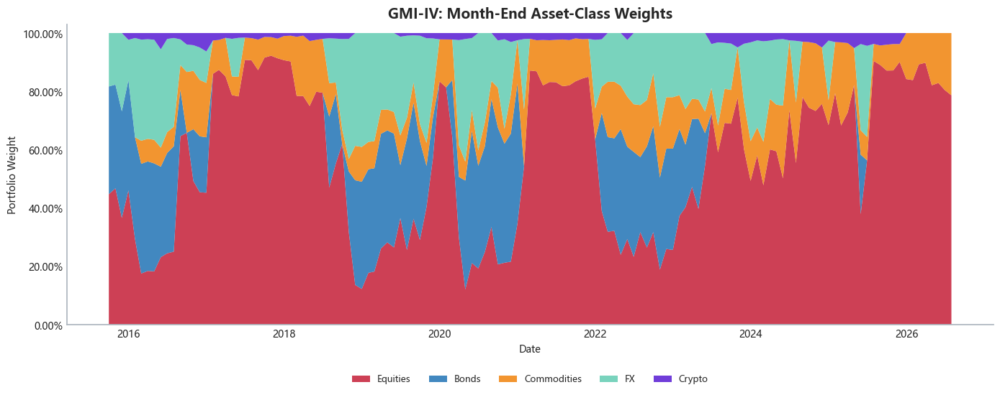

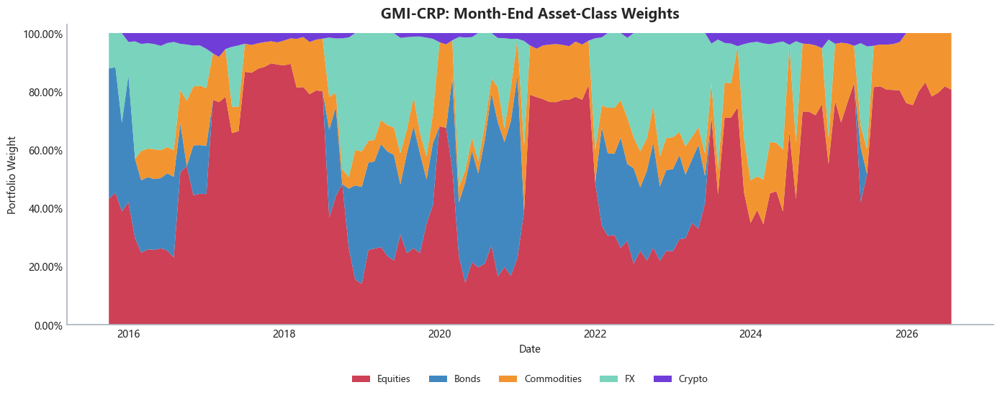

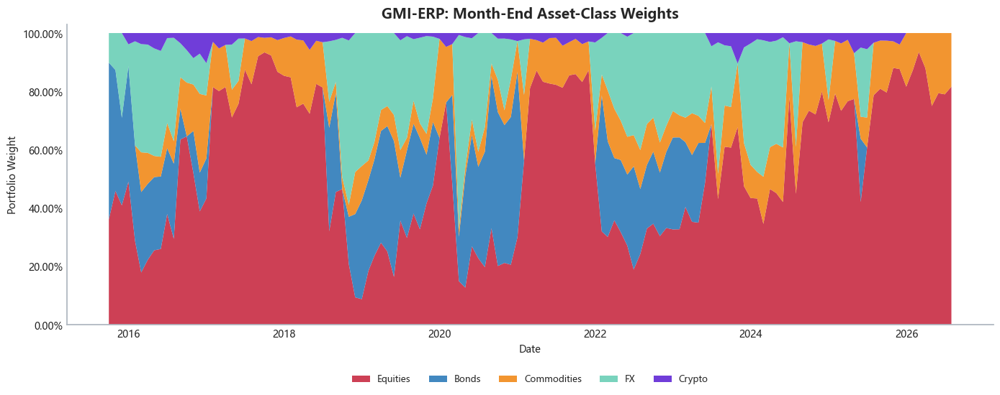

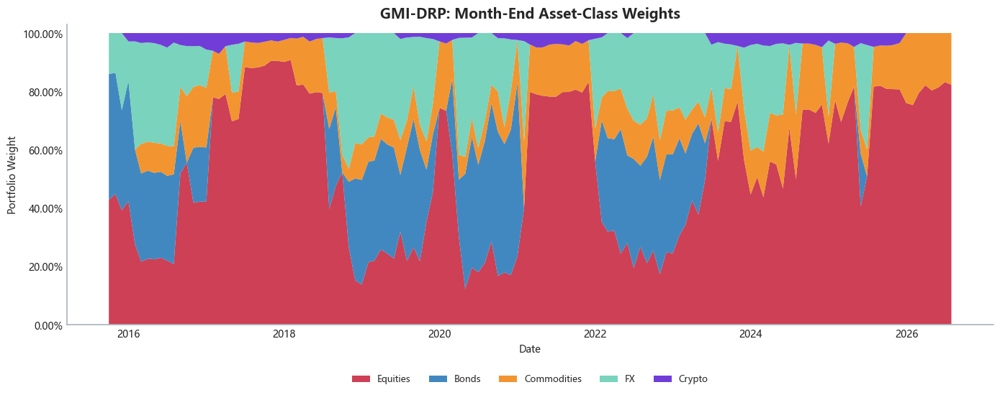

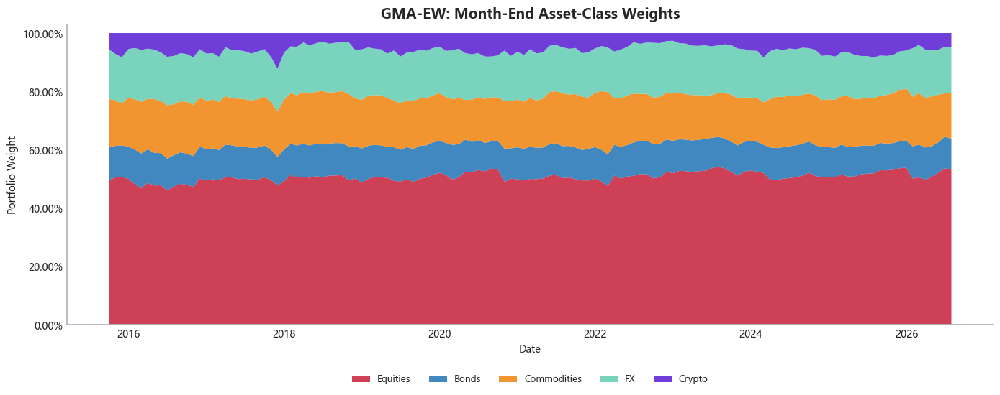

...

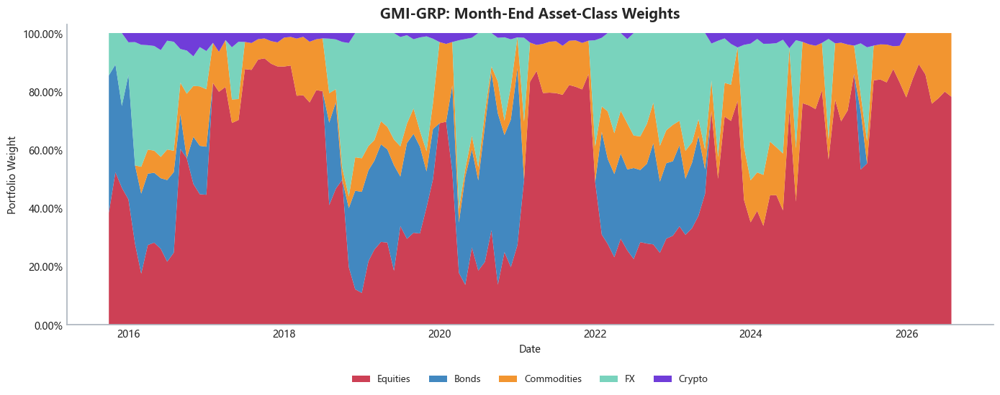

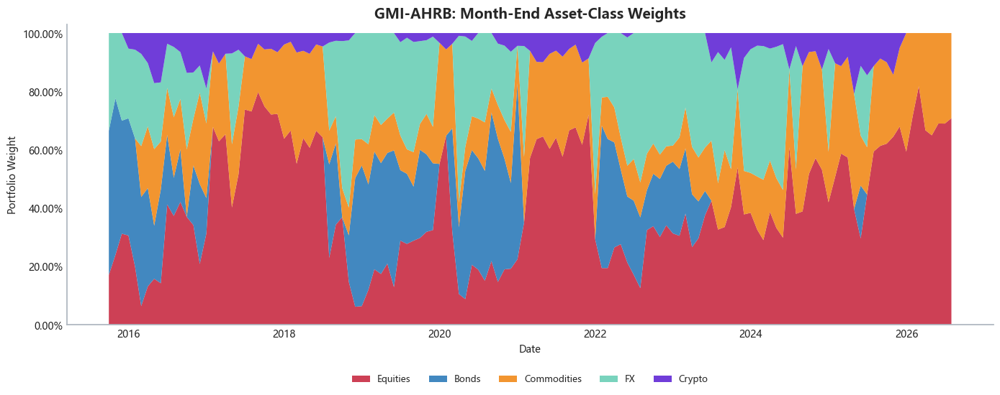

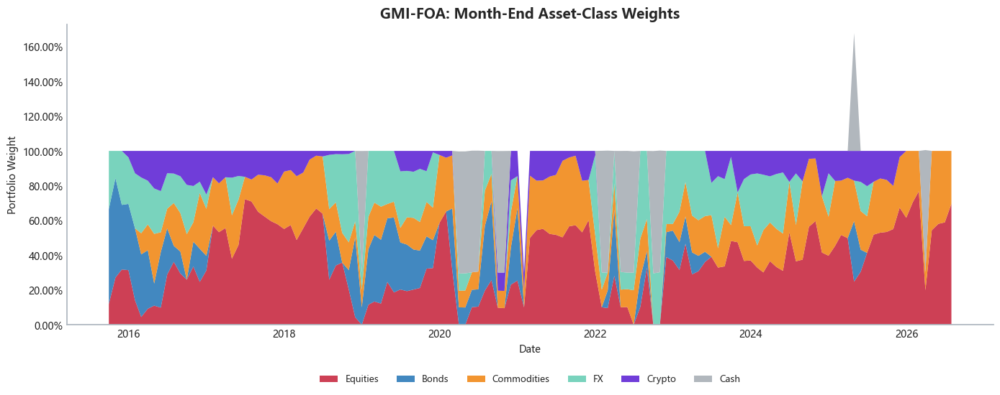

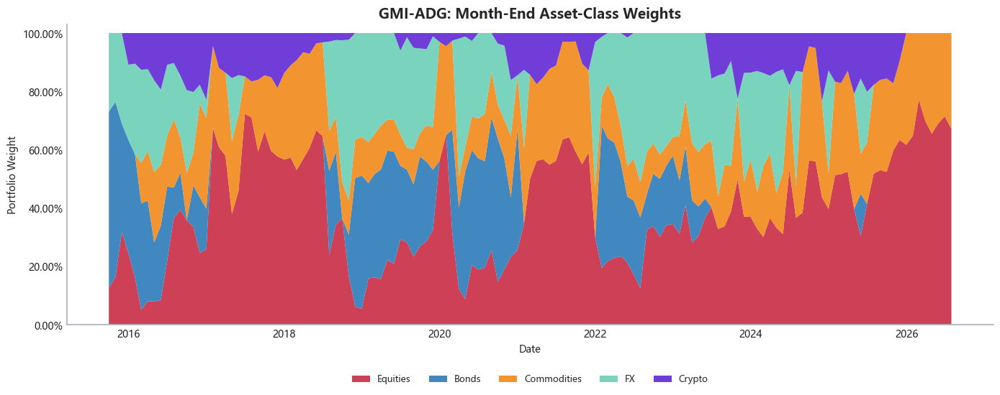

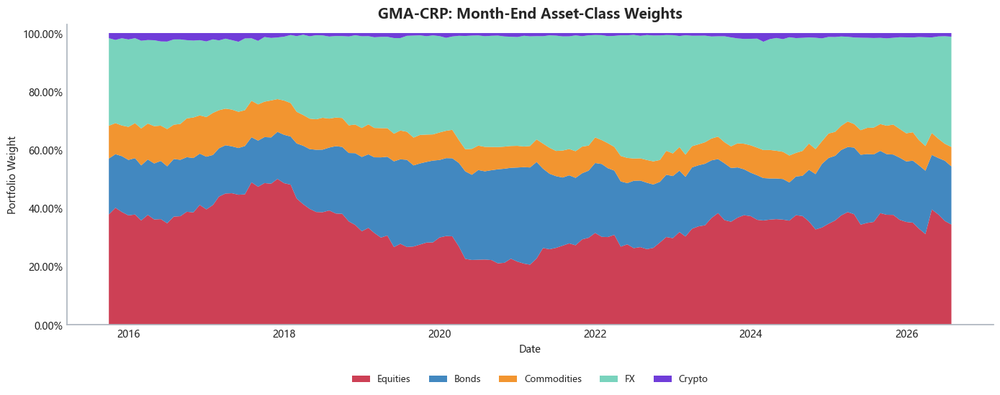

In [17]:
CORE_COMPARISON_STRATEGIES = [
    FULLY_DYNAMIC_BUDGET_NAME,
    CORE_ATTACK_NAME,
    DYNAMIC_ATTACK_NAME,
]
if len(CORE_COMPARISON_STRATEGIES) != 3 or len(set(CORE_COMPARISON_STRATEGIES)) != 3:
    raise RuntimeError('The core group must contain exactly three elements without repetition.')
missing_core_comparison = [name for name in CORE_COMPARISON_STRATEGIES if name not in results]
if missing_core_comparison:
    raise RuntimeError(f'The core comparison strategy is not yet registered:{missing_core_comparison}')

latest_tables = []
latest_strategy_names = [
    STRATEGY_NAMES['inverse_vol'], STRATEGY_NAMES['classic_erc'],
    STRATEGY_NAMES['ewma_erc'], STRATEGY_NAMES['downside_erc'],
    DYNAMIC_BUDGET_NAME, HIERARCHICAL_BUDGET_NAME, GARCH_MOMENTUM_NAME,
    *CORE_COMPARISON_STRATEGIES,
]
latest_strategy_names = list(dict.fromkeys(latest_strategy_names))

for name in latest_strategy_names:
    obj = results[name]
    if 'end_of_day_weights' not in obj or obj['end_of_day_weights'].empty:
        raise RuntimeError(f'{name}Lack of real hold at the end of the day.')
    last_date = obj['end_of_day_weights'].loc[:RESEARCH_END].index[-1]
    latest_weights = obj['end_of_day_weights'].loc[last_date].reindex(ALL_ASSETS).fillna(0.0)
    latest_weights = latest_weights[latest_weights.abs() > 1e-10]

    momentum_lookup = pd.Series(dtype=float)
    selections = obj.get('selections', pd.DataFrame())
    if not selections.empty and {'Rebalance Date', 'Code', 'Motion Score'}.issubset(selections.columns):
        selection_dates = pd.to_datetime(selections['Rebalance Date'])
        eligible_dates = selection_dates.loc[selection_dates <= pd.Timestamp(last_date)]
        latest_selection = selections.loc[selection_dates == eligible_dates.max()] if not eligible_dates.empty else pd.DataFrame()
        if not latest_selection.empty:
            momentum_lookup = latest_selection.drop_duplicates('Code').set_index('Code')['Motion Score']

    latest = pd.DataFrame({
        'Policy': name,
        'Code': latest_weights.index,
        'Asset Name': [asset_metadata.loc[ticker, 'Asset Name'] for ticker in latest_weights.index],
        'Motion Score': [momentum_lookup.get(ticker, np.nan) for ticker in latest_weights.index],
        'Real weight at end of period': latest_weights.values,
        'Warehousing record date': last_date,
    })
    latest['Motion Score'] = latest['Motion Score'].map(
        lambda value: '—' if pd.isna(value) else f'{value:.2%}'
    )
    latest['Real weight at end of period'] = latest['Real weight at end of period'].map(lambda value: f'{value:.2%}')
    latest_tables.append(latest)

display(pd.concat(latest_tables, ignore_index=True))

# Broad asset weights for each official strategy: a strategy-by-strategy map, uniform category colour and vertical calibration.
def build_class_weight_history(result):
    source = result['end_of_day_weights'].loc[strategy_start:RESEARCH_END].copy()
    class_weights = pd.DataFrame(index=source.index)
    for asset_class in asset_metadata['Asset Class'].dropna().unique():
        members = [ticker for ticker in source.columns
                   if ticker in asset_metadata.index
                   and asset_metadata.loc[ticker, 'Asset Class'] == asset_class]
        if members:
            class_weights[asset_class] = source[members].sum(axis=1)
    recorded_cash = result.get('cash_weight', pd.Series(dtype=float)).reindex(source.index)
    class_weights['Cash'] = recorded_cash.fillna(1.0 - source.sum(axis=1)).clip(lower=0.0)
    return class_weights.resample('ME').last().dropna(how='all')


strategy_class_weight_histories = {}
for strategy_name, strategy_result in results.items():
    class_history = build_class_weight_history(strategy_result)
    strategy_class_weight_histories[strategy_name] = class_history
    active_columns = [column for column in ASSET_CLASS_COLORS
                      if column in class_history and class_history[column].abs().max() > 1e-10]
    fig, ax = plt.subplots(figsize=(14, 6.5))
    ax.stackplot(
        class_history.index,
        *[class_history[column].to_numpy(dtype=float) for column in active_columns],
        labels=active_columns,
        colors=[ASSET_CLASS_COLORS[column] for column in active_columns],
        alpha=0.88,
    )
    ax.set_title(f'{strategy_label(strategy_name)}: Month-End Asset-Class Weights',
                 fontsize=14, fontweight='bold')
    ax.set_xlabel('Date')
    ax.set_ylabel('Portfolio Weight')
    ax.set_ylim(0.0, max(1.02, float(class_history[active_columns].sum(axis=1).max()) * 1.03))
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f'{value:.2%}'))
    style_axis(ax, axis='y')
    place_legend(ax, item_count=len(active_columns))
    fig.tight_layout(rect=[0, 0.12 if len(active_columns) > 4 else 0, 1, 1])
    plt.show()


### 4.3 Cumulative-Return Plotting Function for Formal Strategies

In [18]:
BASELINE_STRATEGY = STRATEGY_NAMES['equal_weight']
FOCUS_STRATEGIES = [
    DYNAMIC_BUDGET_NAME, *CORE_COMPARISON_STRATEGIES,
    STRATEGY_NAMES['ewma_erc'], STATIC_CLASSIC_NAME, BASELINE_STRATEGY,
]
if len(FOCUS_STRATEGIES) != 7 or len(set(FOCUS_STRATEGIES)) != 7:
    raise RuntimeError('The priority strategy list must contain seven items and should not be repeated.')
missing_focus = [name for name in FOCUS_STRATEGIES if name not in results]
if missing_focus:
    raise RuntimeError(f'Focus strategy not yet registered:{missing_focus}')

HIGHLIGHT_STRATEGIES = FOCUS_STRATEGIES.copy()
HIGHLIGHT_COLORS = STRATEGY_COLORS.copy()
MUTED_COLOR = '#DCE2E8'


def plot_all_strategy_cumulative(strategy_return_frame):
    cumulative = (1.0 + strategy_return_frame).cumprod() - 1.0
    strategy_names = cumulative.columns.tolist()
    color_map = {
        name: HIGHLIGHT_COLORS.get(name, MUTED_COLOR)
        for name in strategy_names
    }

    fig, ax = plt.subplots(figsize=(17, 9))
    # Draw unfocused strategies to ensure that the eight focus curves are not shielded.
    for strategy_name in [name for name in strategy_names if name not in FOCUS_STRATEGIES]:
        ax.plot(
            cumulative.index, cumulative[strategy_name],
            color=MUTED_COLOR, linewidth=1.0, linestyle='-', alpha=0.34,
            zorder=1, label=strategy_label(strategy_name),
        )
    for strategy_name in FOCUS_STRATEGIES:
        is_baseline = strategy_name == BASELINE_STRATEGY
        is_submission = strategy_name == DYNAMIC_ATTACK_NAME
        ax.plot(
            cumulative.index, cumulative[strategy_name],
            color=HIGHLIGHT_COLORS.get(strategy_name, '#4C78A8'),
            linewidth=4.0 if is_submission else (3.4 if is_baseline else 2.6),
            linestyle='-',
            alpha=1.0, zorder=9 if is_submission else (8 if is_baseline else 5),
            label=(f'{strategy_label(strategy_name)}(baseline)' if is_baseline
                   else strategy_label(strategy_name)),
        )

    # All cumulative income maps are superseded with ES3.SI and VT, using the same starting point and the same SDD total return.
    benchmark_frame = benchmark_returns_sgd[['ES3.SI', 'VT']].reindex(
        strategy_return_frame.index
    ).dropna(how='any')
    benchmark_cumulative = (1.0 + benchmark_frame).cumprod() - 1.0
    benchmark_styles = {
        'ES3.SI': {'color': MARKET_BENCHMARK_COLORS['ES3.SI'], 'linestyle': '-'},
        'VT': {'color': MARKET_BENCHMARK_COLORS['VT'], 'linestyle': '-'},
    }
    for ticker, label in MARKET_BENCHMARK_NAMES.items():
        ax.plot(
            benchmark_cumulative.index, benchmark_cumulative[ticker],
            linewidth=2.6, alpha=1.0, zorder=6,
            label=f'Market Benchmark: {label}', **benchmark_styles[ticker],
        )
    ax.axvline(IN_SAMPLE_END, color='#AAB2BD', linestyle='-', linewidth=1.0,
               label='In-Sample End')
    ax.axhline(0.0, color='#555555', linewidth=0.8)
    ax.set_title(
        f'Cumulative Net Returns: {len(strategy_names)} Strategies and Two Market Benchmarks (SGD)',
        fontsize=15, fontweight='bold'
    )
    ax.set_xlabel('Date')
    ax.set_ylabel('Cumulative Return')
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f'{value:.2%}'))
    style_axis(ax)
    place_legend(ax)
    plt.tight_layout(rect=[0, 0.16, 1, 1])
    plt.show()
    return cumulative, color_map


### 4.4 Drawdown Plotting Function for Formal Strategies

In [19]:
def plot_all_strategy_drawdowns(strategy_return_frame, color_map):
    """Plot filled drawdowns for the final strategy and benchmark, with supporting strategies."""
    drawdowns = strategy_return_frame.apply(drawdown_series)
    fig, ax = plt.subplots(figsize=(17, 9))

    for strategy_name in drawdowns.columns:
        is_focus = strategy_name in FOCUS_STRATEGIES
        is_submission = strategy_name == DYNAMIC_ATTACK_NAME
        is_base = strategy_name == BASELINE_STRATEGY
        color = color_map[strategy_name]
        if is_submission or is_base:
            fill_color = color if is_submission else '#8C9299'
            fill_alpha = 0.52 if is_submission else 0.22
            ax.fill_between(
                drawdowns.index, drawdowns[strategy_name].to_numpy(dtype=float), 0.0,
                color=fill_color, alpha=fill_alpha, linewidth=0, edgecolor='none',
                label=strategy_label(strategy_name), zorder=4 if is_submission else 1,
            )
        else:
            ax.plot(
                drawdowns.index, drawdowns[strategy_name], color=color,
                linewidth=1.5 if is_focus else 0.75,
                alpha=0.72 if is_focus else 0.16,
                label=strategy_label(strategy_name), zorder=3 if is_focus else 2,
            )

    ax.axvline(IN_SAMPLE_END, color='#AAB2BD', linestyle='-', linewidth=1.0,
               label='In-Sample End')
    ax.axhline(0.0, color='#555555', linewidth=0.8)
    ax.set_title(f'Drawdown Curves for All {len(drawdowns.columns)} Formal Strategies',
                 fontsize=16, fontweight='bold')
    ax.set_xlabel('Date')
    ax.set_ylabel('Drawdown')
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f'{value:.2%}'))
    style_axis(ax)
    place_legend(ax)
    fig.tight_layout(rect=[0, 0.16, 1, 1])
    plt.show()
    return drawdowns


### 4.5 Independent Realistic-Cost Scenario: Final Strategy and Market Benchmarks

Formal master feedback continues to use a unified unilateral 0.05 per cent. This section considers sub-market commissions, swaps, price differential slips, market shocks and withholding taxes as independent realities, with only the final strategy, 18 rights-based benchmarks, VT Global Stock and ES3.SI Timeline Index indicators and cumulative yield maps not covering formal results.

,Cumulative Return,Annualized Return,Annualized Volatility,Sharpe Ratio,Maximum Drawdown
GMI-ADG (Fixed 0.05%),441.52%,16.19%,10.77%,1.32,-14.98%
GMI-ADG (Realistic Costs),364.12%,14.61%,10.79%,1.20,-15.44%
GMA-EW (Fixed 0.05%),211.15%,10.61%,9.26%,0.99,-17.87%
ES3.SI Straits Times Index (SGD),190.93%,9.95%,12.85%,0.70,-33.77%
VT Global Equities (SGD),219.50%,10.87%,17.46%,0.60,-31.09%


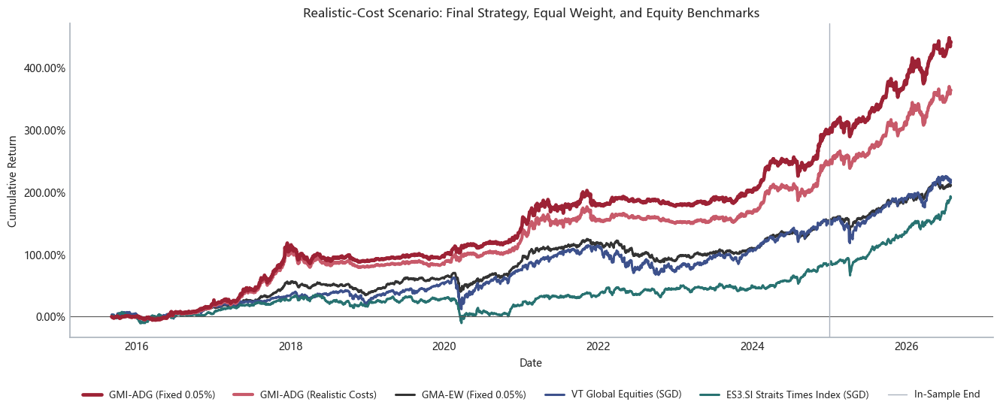

The cost of real differences is exported only as a stand-alone scenario; formal results still use a unified unilateral of 0.05 per cent.


In [20]:
REALISTIC_SCENARIO_NAMES = {
    'fixed_submission': f'{strategy_label(SUBMISSION_STRATEGY)} (Fixed 0.05%)',
    'realistic_submission': f'{strategy_label(SUBMISSION_STRATEGY)} (Realistic Costs)',
    'fixed_equal': f'{strategy_label(BASELINE_STRATEGY)} (Fixed 0.05%)',
    'VT': 'VT Global Equities (SGD)',
    'ES3.SI': 'ES3.SI Straits Times Index (SGD)',
}

realistic_cost_comparison_returns = pd.concat({
    REALISTIC_SCENARIO_NAMES['fixed_submission']:
        results[SUBMISSION_STRATEGY]['returns'],
    REALISTIC_SCENARIO_NAMES['realistic_submission']:
        realistic_submission_result['returns'],
    REALISTIC_SCENARIO_NAMES['fixed_equal']:
        results[BASELINE_STRATEGY]['returns'],
    REALISTIC_SCENARIO_NAMES['VT']:
        benchmark_returns_sgd['VT'],
    REALISTIC_SCENARIO_NAMES['ES3.SI']:
        benchmark_returns_sgd['ES3.SI'],
}, axis=1).loc[strategy_start:RESEARCH_END].dropna(how='any')

realistic_cost_rf = results[SUBMISSION_STRATEGY]['risk_free_daily'].reindex(
    realistic_cost_comparison_returns.index
).ffill()
if realistic_cost_rf.isna().any():
    raise RuntimeError('The SORA coverage of the real-cost stand-alone scenario is incomplete.')


def compact_return_metrics(return_series, risk_free_series):
    """Generate streamlined and comparable indicators of the same calibre for strategic and non-tradable indicators."""
    aligned = pd.concat([return_series, risk_free_series], axis=1).dropna()
    r = aligned.iloc[:, 0].astype(float)
    rf = aligned.iloc[:, 1].astype(float)
    years = len(r) / TRADING_DAYS
    cumulative = float((1.0 + r).prod() - 1.0)
    annual_return = float((1.0 + cumulative) ** (1.0 / years) - 1.0)
    annual_volatility = float(r.std(ddof=1) * np.sqrt(TRADING_DAYS))
    excess = r - rf
    sharpe = float(excess.mean() / excess.std(ddof=1) * np.sqrt(TRADING_DAYS))
    maximum_drawdown = float(drawdown_series(r).min())
    return pd.Series({
        'Cumulative Return': cumulative,
        'Annualized Return': annual_return,
        'Annualized Volatility': annual_volatility,
        'Sharpe Ratio': sharpe,
        'Maximum Drawdown': maximum_drawdown,
    })


realistic_cost_comparison_table = pd.DataFrame({
    name: compact_return_metrics(series, realistic_cost_rf)
    for name, series in realistic_cost_comparison_returns.items()
}).T.sort_values('Sharpe Ratio', ascending=False)
display(realistic_cost_comparison_table.style.format({
    'Cumulative Return': '{:.2%}', 'Annualized Return': '{:.2%}',
    'Annualized Volatility': '{:.2%}', 'Sharpe Ratio': '{:.2f}', 'Maximum Drawdown': '{:.2%}',
}))

realistic_cost_colors = {
    REALISTIC_SCENARIO_NAMES['fixed_submission']: STRATEGY_COLORS[SUBMISSION_STRATEGY],
    REALISTIC_SCENARIO_NAMES['realistic_submission']: '#C85A6A',
    REALISTIC_SCENARIO_NAMES['fixed_equal']: STRATEGY_COLORS[BASELINE_STRATEGY],
    REALISTIC_SCENARIO_NAMES['VT']: MARKET_BENCHMARK_COLORS['VT'],
    REALISTIC_SCENARIO_NAMES['ES3.SI']: MARKET_BENCHMARK_COLORS['ES3.SI'],
}
realistic_cost_cumulative = (1.0 + realistic_cost_comparison_returns).cumprod() - 1.0
fig, ax = plt.subplots(figsize=(14, 7))
for name in realistic_cost_cumulative.columns:
    is_fixed_submission = name == REALISTIC_SCENARIO_NAMES['fixed_submission']
    is_realistic_submission = name == REALISTIC_SCENARIO_NAMES['realistic_submission']
    ax.plot(
        realistic_cost_cumulative.index,
        realistic_cost_cumulative[name],
        color=realistic_cost_colors[name],
        linewidth=3.4 if is_fixed_submission else (3.0 if is_realistic_submission else 2.2),
        linestyle='-',
        label=name,
        zorder=5 if is_fixed_submission else (4 if is_realistic_submission else 2),
    )
ax.axhline(0.0, color='#555555', linewidth=0.8)
ax.axvline(IN_SAMPLE_END, color='#AAB2BD', linewidth=1.0, label='In-Sample End')
ax.set_title('Realistic-Cost Scenario: Final Strategy, Equal Weight, and Equity Benchmarks')
ax.set_xlabel('Date')
ax.set_ylabel('Cumulative Return')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f'{value:.2%}'))
style_axis(ax)
place_legend(ax, item_count=6)
fig.tight_layout(rect=[0, 0.18, 1, 1])
plt.show()

assert 'cost_model' not in results[SUBMISSION_STRATEGY], 'The formal results were unexpectedly covered by realistic cost scenarios.'
assert realistic_submission_result['cost_model'] == 'Real cost scenarios for independent sub-markets'
print('The cost of real differences is exported only as a stand-alone scenario; formal results still use a unified unilateral of 0.05 per cent.')


# Part V. Stress Testing and Out-of-Sample Validation

### 5.1 Base pressure test


Pressure tests are used only to compare strategic vulnerabilities and not to reverse adjustment parameters to enforce positive gains.

Start date    End Date Cumulative Return Maximum Drawdown Annualized Volatility  \
Pressure scenario           Policy                                                                                                                                
Impact of the 2020 epidemic Global Momentum Dynamic Risk Budget (GMI-DRB)       2020-02-19  2020-03-23            -3.51%           -7.31%                15.76%   
                            Global Momentum Adaptive Hierarchical Risk Budg...  2020-02-19  2020-03-23             0.65%           -5.30%                14.96%   
                            Global Momentum Fixed Offensive Allocation (GMI...  2020-02-19  2020-03-23            -2.93%           -5.44%                11.50%   
                            Global Momentum Adaptive Defense and Growth (GM...  2020-02-19  2020-03-23             0.79%           -5.17%                15.09%   
                            Global Momentum EWMA Risk Parity (GMI-ERP)          2020-02-19  2020-03-23            -4.39%           -7.73%                15.56%   
                            Global Multi-Asset Classic Risk Parity (GMA-CRP)    2020-02-19  2020-03-23            -7.18%           -8.30%                13.22%   
                            Global Multi-Asset Equal Weight (GMA-EW)            2020-02-19  2020-03-23           -16.84%          -17.87%                30.34%   
2022 stock, double-kill.    Global Momentum Dynamic Risk Budget (GMI-DRB)       2022-01-03  2022-12-30            -2.72%           -6.55%                 4.63%   
                            Global Momentum Adaptive Hierarchical Risk Budg...  2022-01-03  2022-12-30            -1.12%           -5.56%                 4.31%   
                            Global Momentum Fixed Offensive Allocation (GMI...  2022-01-03  2022-12-30            -2.99%           -6.39%                 5.73%   
                            Global Momentum Adaptive Defense and Growth (GM...  2022-01-03  2022-12-30            -0.43%           -5.18%                 4.87%   
                            Global Momentum EWMA Risk Parity (GMI-ERP)          2022-01-03  2022-12-30            -2.48%           -5.65%                 4.60%   
                            Global Multi-Asset Classic Risk Parity (GMA-CRP)    2022-01-03  2022-12-30            -6.30%           -6.61%                 4.54%   
                            Global Multi-Asset Equal Weight (GMA-EW)            2022-01-03  2022-12-30           -12.78%          -15.66%                10.72%   

                                                                               Worst day of earnings  
Pressure scenario           Policy                                                                    
Impact of the 2020 epidemic Global Momentum Dynamic Risk Budget (GMI-DRB)                     -2.18%  
                            Global Momentum Adaptive Hierarchical Risk Budg...                -1.94%  
                            Global Momentum Fixed Offensive Allocation (GMI...                -1.57%  
                            Global Momentum Adaptive Defense and Growth (GM...                -1.94%  
                            Global Momentum EWMA Risk Parity (GMI-ERP)                        -2.51%  
                            Global Multi-Asset Classic Risk Parity (GMA-CRP)                  -2.28%  
                            Global Multi-Asset Equal Weight (GMA-EW)                          -5.73%  
2022 stock, double-kill.    Global Momentum Dynamic Risk Budget (GMI-DRB)                     -0.92%  
                            Global Momentum Adaptive Hierarchical Risk Budg...                -0.96%  
                            Global Momentum Fixed Offensive Allocation (GMI...                -1.31%  
                            Global Momentum Adaptive Defense and Growth (GM...                -1.48%  
                            Global Momentum EWMA Risk Parity (GMI-ERP)                        -1.05%  
                            G

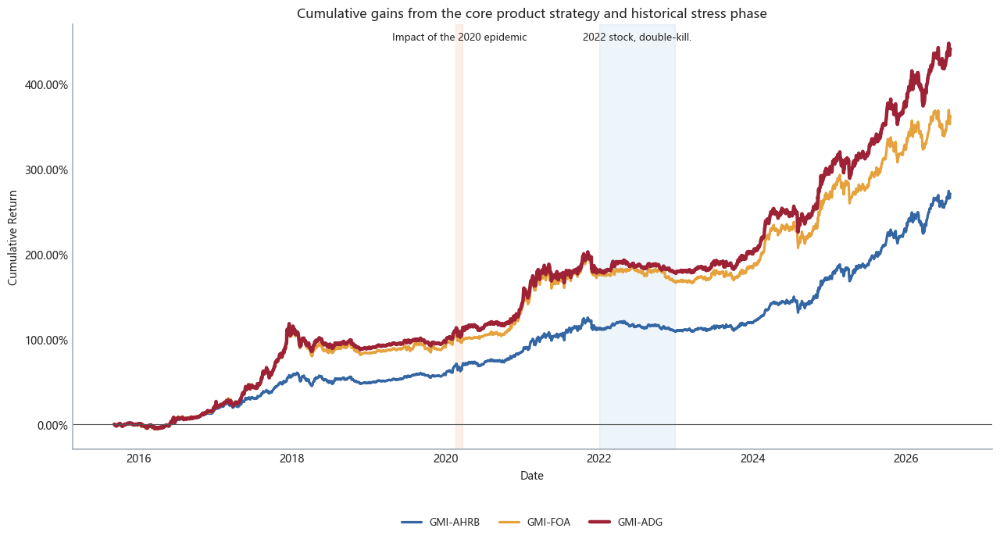

In [21]:
stress_windows = {
    'Impact of the 2020 epidemic': ('2020-02-19', '2020-03-23'),
    '2022 stock, double-kill.': ('2022-01-03', '2022-12-30'),
}

stress_records = []
for scenario, (start, end) in stress_windows.items():
    period_returns = strategy_returns.loc[start:end, FOCUS_STRATEGIES]
    for strategy in period_returns.columns:
        r = period_returns[strategy].dropna()
        if len(r) < 2:
            continue
        stress_records.append({
            'Pressure scenario': scenario,
            'Policy': strategy,
            'Start date': r.index.min().date(),
            'End Date': r.index.max().date(),
            'Cumulative Return': (1.0 + r).prod() - 1.0,
            'Maximum Drawdown': drawdown_series(r).min(),
            'Annualized Volatility': r.std(ddof=1) * np.sqrt(TRADING_DAYS),
            'Worst day of earnings': r.min(),
        })

stress_test = pd.DataFrame(stress_records).set_index(['Pressure scenario', 'Policy'])
stress_display = stress_test.copy()
for column in ['Cumulative Return', 'Maximum Drawdown', 'Annualized Volatility', 'Worst day of earnings']:
    stress_display[column] = stress_display[column].map(lambda x: f'{x:.2%}')
display(stress_display)

# The cumulative benefits of pressure windows: three product strategies are the same, and the pressure phase is marked with a light rectangle.
stress_curve_returns = strategy_returns.loc[:RESEARCH_END, CORE_COMPARISON_STRATEGIES].dropna()
stress_curves = (1.0 + stress_curve_returns).cumprod() - 1.0
fig, ax = plt.subplots(figsize=(15, 7))
for name in CORE_COMPARISON_STRATEGIES:
    ax.plot(stress_curves.index, stress_curves[name], color=STRATEGY_COLORS[name],
            linewidth=3.2 if name == SUBMISSION_STRATEGY else 2.3,
            linestyle='-', label=strategy_label(name))
span_colors = ['#F4B183', '#9DC3E6']
for idx, (scenario, (start, end)) in enumerate(stress_windows.items()):
    start_ts, end_ts = pd.Timestamp(start), pd.Timestamp(end)
    ax.axvspan(start_ts, end_ts, color=span_colors[idx % len(span_colors)], alpha=0.18)
    ax.text(start_ts + (end_ts - start_ts) / 2, 0.98, scenario,
            transform=ax.get_xaxis_transform(), ha='center', va='top', fontsize=9)
ax.axhline(0.0, color='#555555', linewidth=0.8)
ax.set_title('Cumulative gains from the core product strategy and historical stress phase')
ax.set_xlabel('Date')
ax.set_ylabel('Cumulative Return')
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=2))
style_axis(ax)
place_legend(ax)
fig.tight_layout(rect=[0, 0, 0.86, 1])
plt.show()


### 5.2 Diagnostics for Single-Level and Hierarchical Dynamic Risk Budgets

In [22]:
dynamic_result = results[DYNAMIC_BUDGET_NAME]
latest_date = dynamic_result['weights'].index[-1]
latest_trigger = dynamic_result['triggers'].loc[dynamic_result['triggers']['Execution Date'].eq(latest_date)].iloc[-1]
latest_signal_date = pd.Timestamp(latest_trigger['Signal Date'])
position = returns.index.get_loc(latest_signal_date)
history = returns.iloc[position - LOOKBACK + 1:position + 1]
selected, score = select_top10(history)
target_budget = dynamic_risk_budget(history, selected, score)
covariance = ewma_covariance(history[selected])
latest_weights = dynamic_result['weights'].loc[latest_date, selected]
actual_rc = risk_contribution_share(latest_weights, covariance)

dynamic_diagnostics = pd.DataFrame({
    'Target risk budget': target_budget,
    'Actual risk contribution': actual_rc,
    'Target weights': latest_weights,
    'Motion Score': score[selected],
})
dynamic_diagnostics.index.name = 'Assets'
dynamic_display = dynamic_diagnostics.copy()
for column in dynamic_display.columns:
    dynamic_display[column] = dynamic_display[column].map(lambda x: f'{x:.2%}')
display(dynamic_display)

max_error = float((actual_rc - target_budget).abs().max())
print(f'Maximum risk contribution error in dynamic risk budget:{max_error:.8%}')
assert max_error <= 1e-4

hierarchical_result = results[HIERARCHICAL_BUDGET_NAME]
hierarchical_date = hierarchical_result['weights'].index[-1]
hierarchical_trigger = hierarchical_result['triggers'].loc[hierarchical_result['triggers']['Execution Date'].eq(hierarchical_date)].iloc[-1]
hierarchical_signal_date = pd.Timestamp(hierarchical_trigger['Signal Date'])
hierarchical_position = returns.index.get_loc(hierarchical_signal_date)
hierarchical_history = returns.iloc[hierarchical_position - LOOKBACK + 1:hierarchical_position + 1]
hierarchical_selected, hierarchical_score = select_top10(hierarchical_history)
hierarchical_budget = hierarchical_dynamic_risk_budget(
    hierarchical_history, hierarchical_selected, hierarchical_score
)
hierarchical_covariance = ewma_covariance(hierarchical_history[hierarchical_selected])
hierarchical_weights = hierarchical_result['weights'].loc[hierarchical_date, hierarchical_selected]
hierarchical_actual_rc = risk_contribution_share(hierarchical_weights, hierarchical_covariance)

hierarchical_diagnostics = pd.DataFrame({
    'Asset Class': assets.loc[hierarchical_selected, 'Asset Class'],
    'Target risk budget': hierarchical_budget,
    'Actual risk contribution': hierarchical_actual_rc,
    'Target weights': hierarchical_weights,
    'Motion Score': hierarchical_score[hierarchical_selected],
})
hierarchical_diagnostics.index.name = 'Assets'
hierarchical_display = hierarchical_diagnostics.copy()
for column in ['Target risk budget', 'Actual risk contribution', 'Target weights', 'Motion Score']:
    hierarchical_display[column] = hierarchical_display[column].map(lambda x: f'{x:.2%}')
display(hierarchical_display)

hierarchical_class_summary = hierarchical_diagnostics.groupby('Asset Class')[
    ['Target risk budget', 'Actual risk contribution', 'Target weights']
].sum()
hierarchical_class_display = hierarchical_class_summary.copy()
for column in hierarchical_class_display.columns:
    hierarchical_class_display[column] = hierarchical_class_display[column].map(lambda x: f'{x:.2%}')
display(hierarchical_class_display)

hierarchical_error = float((hierarchical_actual_rc - hierarchical_budget).abs().max())
print(f'Bulk budget double risk contribution error:{hierarchical_error:.8%}')
assert hierarchical_error <= 1e-4


garch_fit_table = pd.DataFrame(GARCH_FIT_DIAGNOSTICS)
garch_fit_summary = pd.DataFrame({
    'Value': [len(garch_fit_table), int((garch_fit_table['Depress marks'] != 0).sum())]
}, index=['GRCH Total proposed number', 'Number of Non-Zero Depression Marks'])
display(garch_fit_summary)


,Target risk budget,Actual risk contribution,Target weights,Motion Score
Assets,,,,
USO,12.95%,12.95%,6.39%,42.17%
IWM,12.44%,12.44%,14.00%,38.51%
510300.SS,11.92%,11.92%,5.95%,30.75%
QQQ,11.40%,11.40%,5.60%,27.97%
DBB,10.88%,10.88%,7.97%,26.67%
ES3.SI,10.36%,10.36%,16.41%,25.30%
1308.T,9.84%,9.84%,6.57%,23.54%
GLD,3.11%,3.11%,1.77%,19.46%
SPY,8.81%,8.81%,10.18%,19.41%


Maximum risk contribution error in dynamic risk budget:0.00000006%


,Asset Class,Target risk budget,Actual risk contribution,Target weights,Motion Score
Assets,,,,,
USO,Commodities,12.92%,12.92%,6.37%,42.17%
IWM,Equities,12.54%,12.54%,14.06%,38.51%
510300.SS,Equities,11.82%,11.82%,5.92%,30.75%
QQQ,Equities,11.11%,11.11%,5.44%,27.97%
DBB,Commodities,11.20%,11.20%,8.17%,26.67%
ES3.SI,Equities,10.39%,10.39%,16.46%,25.30%
1308.T,Equities,9.67%,9.67%,6.47%,23.54%
GLD,Commodities,3.16%,3.16%,1.80%,19.46%
SPY,Equities,8.96%,8.96%,10.33%,19.41%


,Target risk budget,Actual risk contribution,Target weights
Asset Class,,,
Commodities,27.27%,27.27%,16.34%
Equities,72.73%,72.73%,83.66%


Bulk budget double risk contribution error:0.00000005%


,Value
GRCH Total proposed number,1900
Number of Non-Zero Depression Marks,0


### 5.3 Asset Inclusion Frequency of the Core Strategies


This section examines only two strategies:

1. **Commercial confirmation of momentum plus strict risk budget for EWMA**;
2. ** Trend is selective and agile.**

“overall assets” means that the assets are combined with positive weights at least once in a full historical return, and does not mean that a single turnkey holds all assets. Each strategy still chooses Top10 at any set point. The results are shown only in DataFrame and are not written in local files.

In [23]:
def build_asset_inclusion_summary(backtest_results):
    records = []
    for strategy_name, result in backtest_results.items():
        weights_history = result['weights'].copy().reindex(columns=ALL_ASSETS, fill_value=0.0)
        total_rebalances = len(weights_history)
        if 'end_of_day_weights' not in result or result['end_of_day_weights'].empty:
            raise RuntimeError(f'{strategy_name}There is a lack of real warehouse records at the end of the period.')
        latest_weights = result['end_of_day_weights'].loc[:RESEARCH_END].iloc[-1].reindex(
            ALL_ASSETS, fill_value=0.0
        )
        for ticker in ALL_ASSETS:
            positive_weights = weights_history[ticker][weights_history[ticker] > 1e-10]
            selected_count = int(positive_weights.count())
            records.append({
                'Policy': strategy_name,
                'Code': ticker,
                'Asset Class': assets.loc[ticker, 'Asset Class'],
                'Asset Name': assets.loc[ticker, 'Asset Name'],
                'Total number of transfers': total_rebalances,
                'Number of selections': selected_count,
                'Selection Ratio': selected_count / total_rebalances if total_rebalances else np.nan,
                'Date of first selection': positive_weights.index.min() if selected_count else pd.NaT,
                'Final selection date': positive_weights.index.max() if selected_count else pd.NaT,
                'Average weight on selection': positive_weights.mean() if selected_count else 0.0,
                'Maximum weight of history': positive_weights.max() if selected_count else 0.0,
                'Current holdings': bool(latest_weights[ticker] > 1e-10),
                'Current weight': float(latest_weights[ticker]),
            })
    return pd.DataFrame(records)


INCLUSION_ANALYSIS_STRATEGIES = [
    STRATEGY_NAMES['ewma_erc'],
    *CORE_COMPARISON_STRATEGIES,
]
focused_results = {name: results[name] for name in INCLUSION_ANALYSIS_STRATEGIES}
asset_inclusion_summary = build_asset_inclusion_summary(focused_results)

coverage_records = []
for strategy_name in INCLUSION_ANALYSIS_STRATEGIES:
    strategy_rows = asset_inclusion_summary.loc[
        asset_inclusion_summary['Policy'].eq(strategy_name)
    ]
    selected_assets = strategy_rows.loc[strategy_rows['Number of selections'] > 0, 'Code'].tolist()
    missing_assets = [ticker for ticker in ALL_ASSETS if ticker not in selected_assets]
    coverage_records.append({
        'Policy': strategy_name,
        'Number of asset pools': len(ALL_ASSETS),
        'Number of assets selected at least once in history': len(selected_assets),
        'Whether all assets are covered': len(missing_assets) == 0,
        'Assets never selected': 'None' if not missing_assets else ', '.join(missing_assets),
    })
coverage_check = pd.DataFrame(coverage_records).set_index('Policy')
display(coverage_check)

comparison = asset_inclusion_summary.pivot(
    index=['Asset Class', 'Code', 'Asset Name'], columns='Policy', values='Selection Ratio'
).fillna(0.0)
comparison = comparison.rename(columns={
    STRATEGY_NAMES['ewma_erc']: 'Trend agility: proportion selected',
    FULLY_DYNAMIC_BUDGET_NAME: 'Full Dynamic Double Layer EWMA: Selection Ratio',
    CORE_ATTACK_NAME: 'Fixed 70 + 30 per cent offensive: selection ratio',
    DYNAMIC_ATTACK_NAME: 'Dynamic 0-30% offensive: selected ratio',
})
comparison = comparison.map(lambda x: f'{x:.1%}')
display(comparison)

current_comparison = asset_inclusion_summary.pivot(
    index=['Asset Class', 'Code', 'Asset Name'], columns='Policy', values='Current weight'
).fillna(0.0)
current_comparison = current_comparison.rename(columns={
    STRATEGY_NAMES['ewma_erc']: 'Trend agility: current weight',
    FULLY_DYNAMIC_BUDGET_NAME: 'Full Dynamic Double Layer EWMA: Current weight',
    CORE_ATTACK_NAME: 'Fixed 70 + 30% offensive: current weight',
    DYNAMIC_ATTACK_NAME: 'Dynamic 0-30% offensive: current weight',
})
current_comparison = current_comparison.loc[current_comparison.max(axis=1).sort_values(ascending=False).index]
current_comparison = current_comparison.map(lambda x: f'{x:.2%}')
display(current_comparison)


,Number of asset pools,Number of assets selected at least once in history,Whether all assets are covered,Assets never selected
Policy,,,,
Global Momentum EWMA Risk Parity (GMI-ERP),18,18,True,None
Global Momentum Adaptive Hierarchical Risk Budget (GMI-AHRB),18,18,True,None
Global Momentum Fixed Offensive Allocation (GMI-FOA),18,18,True,None
Global Momentum Adaptive Defense and Growth (GMI-ADG),18,18,True,None


Policy                                                  Dynamic 0-30% offensive: selected ratio Full Dynamic Double Layer EWMA: Selection Ratio  \
Asset Class Code      Asset Name                                                                                                                  
Bonds       511010.SS China 5-Year Government Bond                                        37.9%                                           38.6%   
            IEF       United States Treasury 7-10 years                                   39.5%                                           40.2%   
Commodities DBB       Industrial metals                                                   52.1%                                           52.2%   
            GLD       Gold                                                                70.0%                                           70.1%   
            USO       Energy (oil)                                                        38.9%                                           39.1%   
Crypto      BTC-USD   Bitcoin                                                             72.1%                                           72.3%   
Equities    1308.T    TOPIX                                                               68.4%                                           67.4%   
            2800.HK   Hang Seng Index                                                     45.3%                                           45.7%   
            510300.SS CSI 300                                                             51.1%                                           51.1%   
            ES3.SI    Straits Times Index                                                 66.8%                                           66.3%   
            EXS1.DE   DAX, Germany                                                        61.1%                                           60.3%   
            ISF.L     FTSE 100                                                            46.3%                                           45.1%   
            IWM       Russell 2000                                                        59.5%                                           59.2%   
            QQQ       NASDAQ 100                                                          91.1%                                           91.3%   
            SPY       S&P 500                                                             95.8%                                           96.2%   
FX          FXE       Euro                                                                32.1%                                           31.5%   
            FXY       Japanese yen                                                        25.8%                                           26.1%   
            UUP       United States dollar index                                          46.3%                                           47.3%   

Policy                                                  Trend agility: proportion selected Fixed 70 + 30 per cent offensive: selection ratio  
Asset Class Code      Asset Name                                                                                                              
Bonds       511010.SS China 5-Year Government Bond                                   39.0%                                             31.0%  
            IEF       United States Treasury 7-10 years                              40.7%                                             36.9%  
Commodities DBB       Industrial metals                                              52.0%                                             47.3%  
            GLD       Gold                                                           69.5%                                             67.5%  
            USO       Energy (oil)                                                   39.5%                                             39.4%  
Crypto      BTC-USD   Bitcoin                             

Policy                                                  Dynamic 0-30% offensive: current weight Full Dynamic Double Layer EWMA: Current weight Trend agility: current weight  \
Asset Class Code      Asset Name                                                                                                                                               
Equities    ISF.L     FTSE 100                                                           12.97%                                         22.34%                        25.94%   
            ES3.SI    Straits Times Index                                                19.43%                                         13.30%                        15.87%   
            IWM       Russell 2000                                                       14.26%                                         12.24%                        11.41%   
Commodities DBB       Industrial metals                                                  12.88%                                         16.82%                         7.23%   
            USO       Energy (oil)                                                       15.61%                                          8.43%                         5.92%   
Equities    510300.SS CSI 300                                                             5.89%                                          4.60%                         5.30%   
            SPY       S&P 500                                                             5.39%                                          8.91%                        11.34%   
            1308.T    TOPIX                                                               5.89%                                          5.19%                         6.83%   
Commodities GLD       Gold                                                                4.29%                                          3.94%                         5.20%   
Equities    QQQ       NASDAQ 100                                                          3.39%                                          4.22%                         4.95%   
Bonds       IEF       United States Treasury 7-10 years                                   0.00%                                          0.00%                         0.00%   
            511010.SS China 5-Year Government Bond                                        0.00%                                          0.00%                         0.00%   
Equities    2800.HK   Hang Seng Index                                                     0.00%                                          0.00%                         0.00%   
Crypto      BTC-USD   Bitcoin                                                             0.00%                                          0.00%                         0.00%   
Equities    EXS1.DE   DAX, Germany                                                        0.00%                                          0.00%                         0.00%   
FX          FXE       Euro                                                                0.00%                                          0.00%                         0.00%   
            FXY       Japanese yen                                                        0.00%                                          0.00%                         0.00%   
            UUP       United States dollar index                                          0.00%                                          0.00%                         0.00%   

Policy                                                  Fixed 70 + 30% offensive: current weight  
Asset Class Code      Asset Name                                                                  
Equities    ISF.L     FTSE 100                                                            15.64%  
            ES3.SI    Straits Times Index                                                  9.31%  
            IWM       Russell 2000                                                 

### 5.4 Asset Price Trends and Correlations


This section uses the strategy to convert the actual intra-temporal price to the Singapore dollar (SGD). For comparison purposes, assets are consolidated at a common starting point of 100 and price movements are shown using a logarithmic axis; the correlation of assets is calculated using the Pearson-day rate of return of SGD for the same period. Both results are displayed in the same visualized window and are not written in the local picture file.

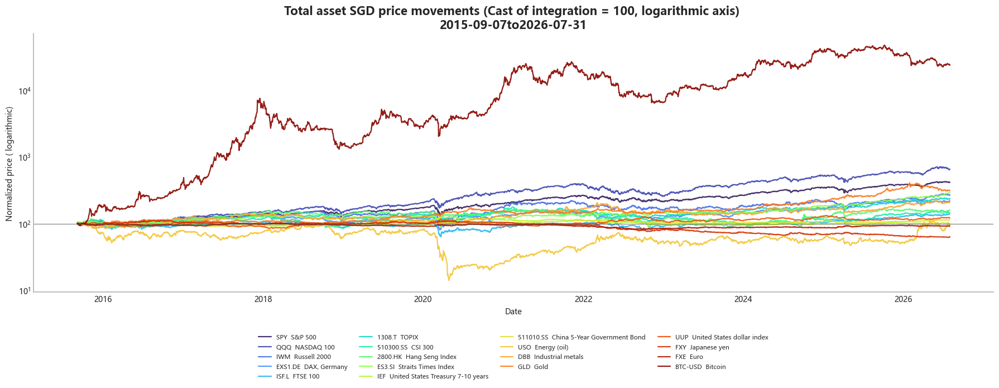

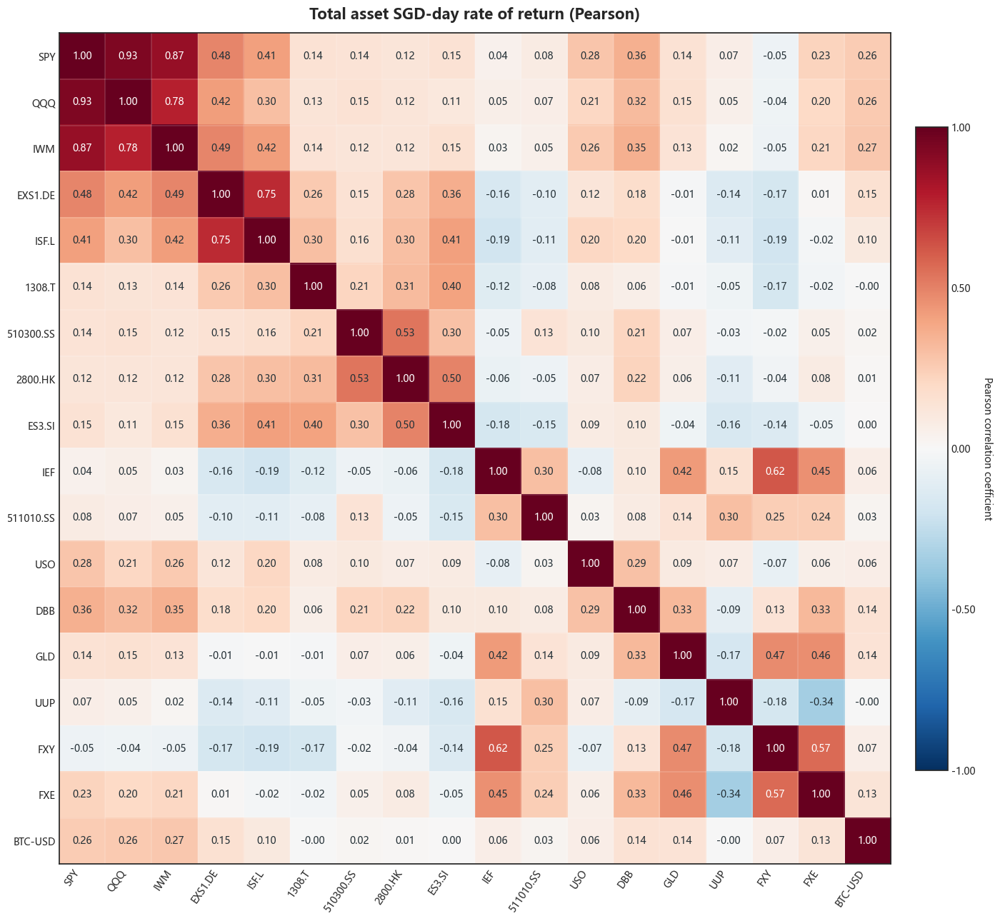

In [24]:
# Asset price trends and correlations: shown in Notebook only, no pictures saved
visual_prices = prices_sgd.loc[(prices_sgd.index >= strategy_start) & (prices_sgd.index <= RESEARCH_END), ALL_ASSETS].dropna(how='any')
if visual_prices.empty:
    raise ValueError('There is no complete asset price data in the actual range.')

normalized_prices = visual_prices.div(visual_prices.iloc[0]).mul(100)
visual_returns = visual_prices.pct_change(fill_method=None).dropna(how='any')
asset_correlation = visual_returns.corr(method='pearson')

# Sets a high-diverse colour for all assets; all price lines are used uniformly.
asset_colors = plt.cm.turbo(np.linspace(0.02, 0.98, len(ALL_ASSETS)))
asset_name_map = assets['Asset Name'].to_dict()

fig, price_ax = plt.subplots(figsize=(18, 9))
for idx, ticker in enumerate(ALL_ASSETS):
    price_ax.plot(
        normalized_prices.index,
        normalized_prices[ticker],
        color=asset_colors[idx],
        linestyle='-',
        linewidth=1.6,
        alpha=0.92,
        label=f"{ticker}  {asset_name_map.get(ticker, ticker)}"
    )
price_ax.axhline(100, color='#555555', linewidth=0.9, linestyle='-', alpha=0.7)
price_ax.set_yscale('log')
price_ax.set_title(
    f"Total asset SGD price movements (Cast of integration = 100, logarithmic axis) \n"
    f"{normalized_prices.index[0].date()}to{normalized_prices.index[-1].date()}",
    fontsize=15, fontweight='bold'
)
price_ax.set_ylabel('Normalized price ( logarithmic)')
price_ax.set_xlabel('Date')
style_axis(price_ax)
place_legend(price_ax)
fig.tight_layout(rect=[0, 0.18, 1, 1])
plt.show()

fig, corr_ax = plt.subplots(figsize=(15, 13))
heatmap = corr_ax.imshow(
    asset_correlation.values,
    cmap='RdBu_r', vmin=-1, vmax=1,
    interpolation='nearest', aspect='equal'
)
corr_ax.set_title(
    'Total asset SGD-day rate of return (Pearson)',
    fontsize=15, fontweight='bold', pad=14
)
corr_ax.set_xticks(np.arange(len(ALL_ASSETS)))
corr_ax.set_yticks(np.arange(len(ALL_ASSETS)))
corr_ax.set_xticklabels(ALL_ASSETS, rotation=55, ha='right', fontsize=10)
corr_ax.set_yticklabels(ALL_ASSETS, fontsize=10)
corr_ax.set_xticks(np.arange(-0.5, len(ALL_ASSETS), 1), minor=True)
corr_ax.set_yticks(np.arange(-0.5, len(ALL_ASSETS), 1), minor=True)
corr_ax.grid(which='minor', color='white', linestyle='-', linewidth=0.35, alpha=0.55)
corr_ax.tick_params(which='minor', bottom=False, left=False)

# Marks two decimals directly in the matrix; dark cells are readable using white words.
for row_index in range(len(ALL_ASSETS)):
    for column_index in range(len(ALL_ASSETS)):
        value = float(asset_correlation.iloc[row_index, column_index])
        text_color = 'white' if abs(value) >= 0.55 else '#263238'
        corr_ax.text(
            column_index, row_index, f'{value:.2f}',
            ha='center', va='center', fontsize=10, color=text_color,
        )

colorbar = fig.colorbar(heatmap, ax=corr_ax, fraction=0.032, pad=0.025)
colorbar.set_label('Pearson correlation coefficient', rotation=270, labelpad=18)
colorbar.set_ticks([-1, -0.5, 0, 0.5, 1])
colorbar.ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f'{value:.2f}'))
colorbar.ax.tick_params(labelsize=10)
fig.tight_layout()
plt.show()


### 5.5 Cumulative-Return Plotting Function for Validation Windows

In [25]:
def plot_all_strategy_oos(strategy_return_frame, color_map):
    oos_returns = strategy_return_frame.loc[OOS_START:RESEARCH_END].dropna(how='any')
    if oos_returns.empty:
        raise ValueError('There are no strategic gains to be compared between certification zones.')
    zero_row = pd.DataFrame(0.0, index=[OOS_START], columns=oos_returns.columns)
    oos_cumulative = (1.0 + pd.concat([zero_row, oos_returns]).sort_index()).cumprod() - 1.0
    fig, ax = plt.subplots(figsize=(17, 9))
    for strategy_name in oos_cumulative.columns:
        is_hl = strategy_name in HIGHLIGHT_STRATEGIES
        ax.plot(
            oos_cumulative.index, oos_cumulative[strategy_name],
            color=color_map[strategy_name],
            linewidth=3.0 if is_hl else 1.1,
            linestyle='-',
            alpha=1.0 if is_hl else 0.45,
            zorder=5 if is_hl else 1,
            label=strategy_label(strategy_name),
        )

    benchmark_oos_returns = benchmark_returns_sgd[['ES3.SI', 'VT']].reindex(
        oos_returns.index
    ).dropna(how='any')
    benchmark_zero = pd.DataFrame(
        0.0, index=[OOS_START], columns=benchmark_oos_returns.columns
    )
    benchmark_oos_cumulative = (
        1.0 + pd.concat([benchmark_zero, benchmark_oos_returns]).sort_index()
    ).cumprod() - 1.0
    benchmark_styles = {
        'ES3.SI': {'color': MARKET_BENCHMARK_COLORS['ES3.SI'], 'linestyle': '-'},
        'VT': {'color': MARKET_BENCHMARK_COLORS['VT'], 'linestyle': '-'},
    }
    for ticker, label in MARKET_BENCHMARK_NAMES.items():
        ax.plot(
            benchmark_oos_cumulative.index, benchmark_oos_cumulative[ticker],
            linewidth=2.6, alpha=1.0, zorder=6,
            label=f'Market benchmarks:{label}', **benchmark_styles[ticker],
        )
    ax.axvline(OOS_START, color='#AAB2BD', linestyle='-', linewidth=1.0,
               label='The starting point of the validation area')
    ax.axhline(0.0, color='#555555', linewidth=0.8)
    ax.set_title(
        f'All{len(oos_cumulative.columns)}Accumulated gains between formal strategies and double market benchmark certification'
        f'（{OOS_START.date()}to{RESEARCH_END.date()}）',
        fontsize=15, fontweight='bold',
    )
    ax.set_xlabel('Date')
    ax.set_ylabel('Cumulative rate of return between certified areas')
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f'{value:.2%}'))
    style_axis(ax)
    place_legend(ax)
    plt.tight_layout(rect=[0, 0.16, 1, 1])
    plt.show()
    return oos_cumulative


### 5.6 Expanding Out-of-Sample Windows


This section sets the starting point for validation at 2025-01-01 and expands the end point of the window in order to observe whether the strategic conclusions depend on a particular certification length. These windows are in the research phase and are all strictly closed to 2026-07-31, without reading the locking test set after 2026-08-01.

All official strategies go into detail. The graphics focus on comparing the original "Trends Selected Quick Balance" and "Top10+ fully dynamic double layer + VIX open silos " , and trying to display the full strategy ratio of Sharpes over different proven lengths.

The current study covers the first 19 months in full and ends up to 2026-07-31; subsequent months are clearly marked as data not allowed. Annualized earnings from one to several months and Sharp are heavily influenced by a small number of trading days, which are used only for stability observations.

,Plan end.,Actual available endpoint,Overwrite Status
Validation Length,,,
1Month,2025-01-31,2025-01-31,Full Overwrite
2Month,2025-02-28,2025-02-28,Full Overwrite
3Month,2025-03-31,2025-03-31,Full Overwrite
4Month,2025-04-30,2025-04-30,Full Overwrite
5Month,2025-05-31,2025-05-31,Full Overwrite
6Month,2025-06-30,2025-06-30,Full Overwrite
7Month,2025-07-31,2025-07-31,Full Overwrite
8Month,2025-08-31,2025-08-31,Full Overwrite
9Month,2025-09-30,2025-09-30,Full Overwrite


Window End Window Status Cumulative Return Annualized Return Annualized Volatility Sharpe Ratio  \
Validation Length Policy                                                                                                                                               
1Month            Global Momentum Inverse Volatility (GMI-IV)        2025-01-31          Full             3.00%            38.24%                 7.86%         3.81   
                  Global Momentum Classic Risk Parity (GMI-CRP)      2025-01-31          Full             2.79%            35.22%                 7.25%         3.82   
                  Global Momentum EWMA Risk Parity (GMI-ERP)         2025-01-31          Full             2.96%            37.64%                 6.91%         4.26   
                  Global Momentum Downside Risk Parity (GMI-DRP)     2025-01-31          Full             2.74%            34.47%                 7.40%         3.67   
                  Global Multi-Asset Equal Weight (GMA-EW)           2025-01-31          Full             2.33%            28.65%                 7.38%         3.09   
...                                                                         ...           ...               ...               ...                   ...          ...   
19Month           Global Momentum GARCH Risk Parity (GMI-GRP)        2026-07-31          Full            33.40%            19.38%                 9.57%         1.74   
                  Global Momentum Adaptive Hierarchical Risk Budg... 2026-07-31          Full            37.03%            21.37%                10.58%         1.74   
                  Global Momentum Fixed Offensive Allocation (GMI... 2026-07-31          Full            26.54%            15.57%                11.91%         1.15   
                  Global Momentum Adaptive Defense and Growth (GM... 2026-07-31          Full            37.08%            21.39%                11.51%         1.61   
                  Global Multi-Asset Classic Risk Parity (GMA-CRP)   2026-07-31          Full            15.30%             9.15%                 5.07%         1.46   

                                                                     Maximum Drawdown Annual One-Way Turnover  Number of Rebalances  Number of Trade Legs  
Validation Length Policy                                                                                                                                   
1Month            Global Momentum Inverse Volatility (GMI-IV)                  -1.63%                 231.36%                     1                    11  
                  Global Momentum Classic Risk Parity (GMI-CRP)                -1.42%                 369.01%                     1                    11  
                  Global Momentum EWMA Risk Parity (GMI-ERP)                   -1.51%                 258.20%                     1                    11  
                  Global Momentum Downside Risk Parity (GMI-DRP)               -1.51%                 286.90%                     1                    11  
                  Global Multi-Asset Equal Weight (GMA-EW)                     -1.41%                   0.00%                     0                     0  
...                                                                               ...                     ...                   ...                   ...  
19Month           Global Momentum GARCH Risk Parity (GMI-GRP)                  -9.66%                 254.02%                    21                   227  
                  Global Momentum Adaptive Hierarchical Risk Budg...           -7.21%                 349.89%                    26                   277  
                  Global Momentum Fixed Offensive Allocation (GMI...           -8.46%                 471.97%                    32                   328  
                  Global Momentum Adaptive Defense and Growth (GM...           -8.02%                 279.27%                    28                   297  
            

,Window End,Maximum accumulated gains strategy,Maximum accumulated proceeds,Sharp's top strategy.,Supreme Sharp.
Validation Length,,,,,
1Month,2025-01-31,Global Momentum Fixed Offensive Allocation (GM...,4.34%,Global Momentum Static Hierarchical Risk Budge...,4.59
2Month,2025-02-28,Global Momentum Static Hierarchical Risk Budge...,4.47%,Global Momentum Static Hierarchical Risk Budge...,3.26
3Month,2025-03-31,Global Momentum Static Hierarchical Risk Budge...,4.96%,Global Momentum Static Hierarchical Risk Budge...,2.00
4Month,2025-04-30,Global Momentum Dynamic Risk Budget (GMI-DRB),3.18%,Global Momentum Static Hierarchical Risk Budge...,0.69
5Month,2025-05-31,Global Momentum Dynamic Risk Budget (GMI-DRB),5.58%,Global Momentum EWMA Risk Parity (GMI-ERP),1.04
6Month,2025-06-30,Global Momentum Dynamic Risk Budget (GMI-DRB),7.03%,Global Momentum EWMA Risk Parity (GMI-ERP),1.17
7Month,2025-07-31,Global Momentum Dynamic Risk Budget (GMI-DRB),9.73%,Global Momentum Dynamic Risk Budget (GMI-DRB),1.45
8Month,2025-08-31,Global Momentum Dynamic Risk Budget (GMI-DRB),12.57%,Global Momentum EWMA Risk Parity (GMI-ERP),1.72
9Month,2025-09-30,Global Momentum Dynamic Risk Budget (GMI-DRB),17.71%,Global Momentum Static Hierarchical Risk Budge...,2.24


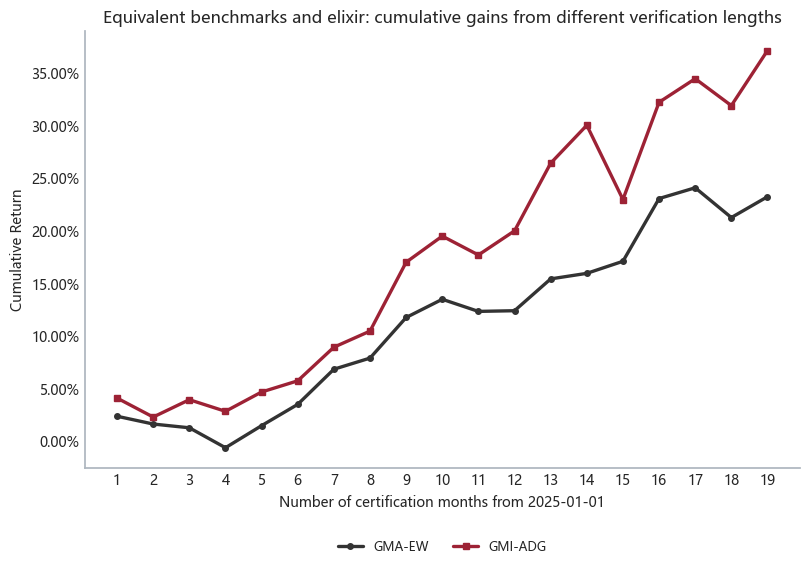

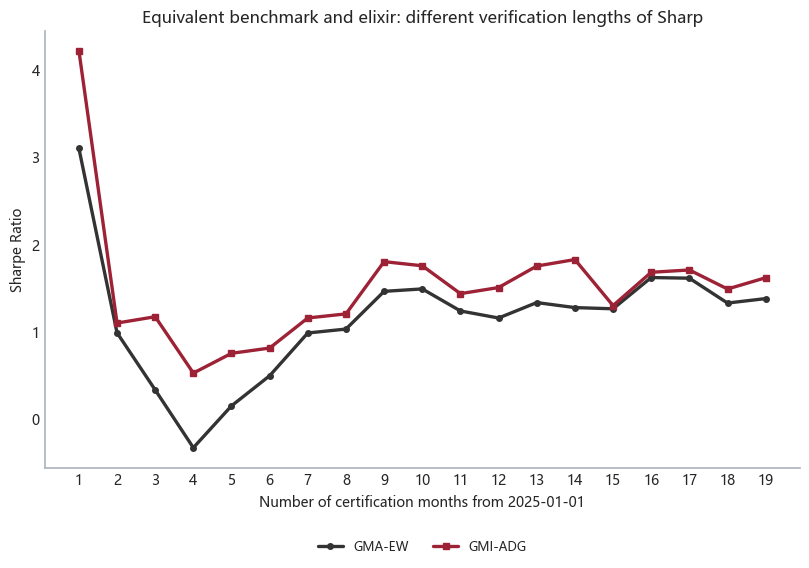

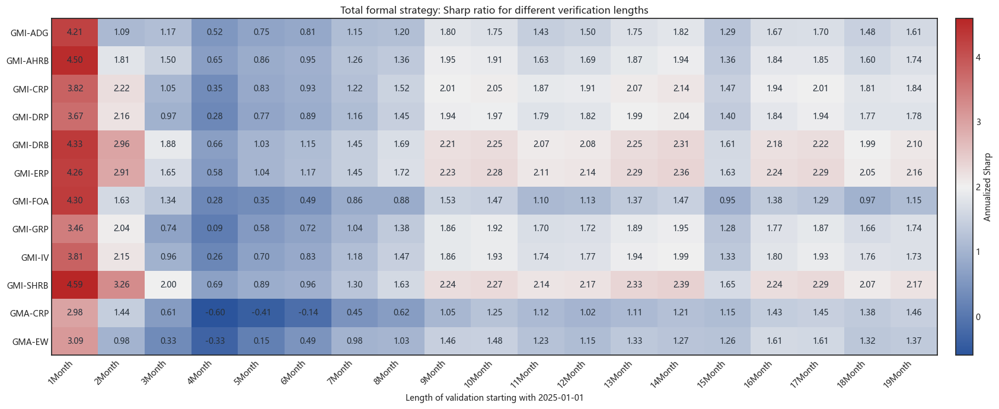

Strict deadline for research data2026-07-31；Full cover 1 to19Months;20Research indicators are not generated for 24 months.


In [26]:
# Fixed validation starting point, expanding endpoints on a monthly basis; future windows are not filled with data that have not yet occurred.
available_oos_end = min(
    RESEARCH_END,
    min(result['returns'].dropna().index.max() for result in results.values())
)

horizon_coverage_records = []
complete_horizons = []
partial_horizon = None
for months in range(1, 25):
    planned_end = (OOS_START + pd.DateOffset(months=months) - pd.Timedelta(days=1)).normalize()
    if available_oos_end >= planned_end:
        status = 'Full Overwrite'
        actual_end = planned_end
        complete_horizons.append((months, planned_end, f'{months}Month'))
    elif OOS_START <= available_oos_end and available_oos_end.to_period('M') == planned_end.to_period('M'):
        status = 'The current month is incomplete'
        actual_end = available_oos_end
        partial_horizon = (months, available_oos_end, f'{months}Month (incomplete)')
    else:
        status = 'Data not yet covered'
        actual_end = pd.NaT
    horizon_coverage_records.append({
        'Validation Length': f'{months}Month',
        'Plan end.': planned_end.date(),
        'Actual available endpoint': actual_end.date() if pd.notna(actual_end) else None,
        'Overwrite Status': status,
    })

horizon_coverage = pd.DataFrame(horizon_coverage_records).set_index('Validation Length')
display(horizon_coverage)

evaluated_horizons = complete_horizons.copy()
if partial_horizon is not None:
    evaluated_horizons.append(partial_horizon)

horizon_metric_frames = []
for months, window_end, horizon_label in evaluated_horizons:
    frame = pd.DataFrame({
        strategy_name: compute_metrics(result, OOS_START, window_end)
        for strategy_name, result in results.items()
    }).T
    frame['Number of months of windows'] = months
    frame['Window End'] = window_end
    frame['Window Status'] = 'Incomplete' if 'Incomplete' in horizon_label else 'Full'
    frame['Validation Length'] = horizon_label
    frame['Policy'] = frame.index
    horizon_metric_frames.append(frame.reset_index(drop=True))

oos_horizon_metrics = pd.concat(horizon_metric_frames, ignore_index=True)
oos_horizon_metrics = oos_horizon_metrics.set_index(['Validation Length', 'Policy'])

# Detailed DataFrame maintains all policies; displays are presented in Chinese format and limited to core indicators.
oos_horizon_metrics_display = oos_horizon_metrics[
    ['Window End', 'Window Status', 'Cumulative Return', 'Annualized Return', 'Annualized Volatility',
     'Sharpe Ratio', 'Maximum Drawdown', 'Annual One-Way Turnover', 'Number of Rebalances', 'Number of Trade Legs']
].copy()
for column in ['Cumulative Return', 'Annualized Return', 'Annualized Volatility', 'Maximum Drawdown', 'Annual One-Way Turnover']:
    oos_horizon_metrics_display[column] = oos_horizon_metrics_display[column].map(
        lambda value: f'{value:.2%}'
    )
oos_horizon_metrics_display['Sharpe Ratio'] = oos_horizon_metrics_display['Sharpe Ratio'].map(
    lambda value: f'{value:.2f}'
)
oos_horizon_metrics_display['Number of Rebalances'] = oos_horizon_metrics_display['Number of Rebalances'].astype(int)
oos_horizon_metrics_display['Number of Trade Legs'] = oos_horizon_metrics_display['Number of Trade Legs'].astype(int)
display(oos_horizon_metrics_display)

# Each window reports the highest cumulative returns and the highest Sharp ' s strategies respectively, avoiding observing only the last compartment.
horizon_best_records = []
for horizon_label, frame in oos_horizon_metrics.groupby(level='Validation Length', sort=False):
    local = frame.droplevel('Validation Length')
    return_winner = local['Cumulative Return'].idxmax()
    sharpe_winner = local['Sharpe Ratio'].idxmax()
    horizon_best_records.append({
        'Validation Length': horizon_label,
        'Window End': local['Window End'].iloc[0].date(),
        'Maximum accumulated gains strategy': return_winner,
        'Maximum accumulated proceeds': local.loc[return_winner, 'Cumulative Return'],
        'Sharp\'s top strategy.': sharpe_winner,
        'Supreme Sharp.': local.loc[sharpe_winner, 'Sharpe Ratio'],
    })
horizon_best = pd.DataFrame(horizon_best_records).set_index('Validation Length')
horizon_best_display = horizon_best.copy()
horizon_best_display['Maximum accumulated proceeds'] = horizon_best_display['Maximum accumulated proceeds'].map(lambda x: f'{x:.2%}')
horizon_best_display['Supreme Sharp.'] = horizon_best_display['Supreme Sharp.'].map(lambda x: f'{x:.2f}')
display(horizon_best_display)

baseline_name = BASELINE_STRATEGY
candidate_name = SUBMISSION_STRATEGY
focus = oos_horizon_metrics.reset_index()
focus = focus[focus['Policy'].isin([baseline_name, candidate_name])].copy()
focus['Show Months'] = focus['Validation Length'].str.extract(r'(\d+)').astype(int)

style_map = {
    baseline_name: {'color': STRATEGY_COLORS[baseline_name], 'linestyle': '-', 'marker': 'o'},
    candidate_name: {'color': STRATEGY_COLORS[candidate_name], 'linestyle': '-', 'marker': 's'},
}
fig, ax = plt.subplots(figsize=(10, 5.8))
for strategy_name in [baseline_name, candidate_name]:
    subset = focus[focus['Policy'] == strategy_name].sort_values('Show Months')
    style = style_map[strategy_name]
    ax.plot(subset['Show Months'], subset['Cumulative Return'], label=strategy_label(strategy_name),
            linewidth=2.4, markersize=4, **style)
ax.set_title('Equivalent benchmarks and elixir: cumulative gains from different verification lengths')
ax.set_ylabel('Cumulative Return')
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=2))
ax.set_xlabel('Number of certification months from 2025-01-01')
ax.set_xticks(range(1, max(focus['Show Months']) + 1))
style_axis(ax)
place_legend(ax)
fig.tight_layout(rect=[0, 0, 0.82, 1])
plt.show()

fig, ax = plt.subplots(figsize=(10, 5.8))
for strategy_name in [baseline_name, candidate_name]:
    subset = focus[focus['Policy'] == strategy_name].sort_values('Show Months')
    ax.plot(subset['Show Months'], subset['Sharpe Ratio'], label=strategy_label(strategy_name),
            linewidth=2.4, markersize=4, **style_map[strategy_name])
ax.set_title('Equivalent benchmark and elixir: different verification lengths of Sharp')
ax.set_ylabel('Sharpe Ratio')
ax.set_xlabel('Number of certification months from 2025-01-01')
ax.set_xticks(range(1, max(focus['Show Months']) + 1))
style_axis(ax)
place_legend(ax)
fig.tight_layout(rect=[0, 0, 0.82, 1])
plt.show()

# All the official strategies of Sharp's stability struggle.
sharpe_matrix = oos_horizon_metrics['Sharpe Ratio'].unstack(level='Validation Length')
ordered_horizons = [label for _, _, label in evaluated_horizons]
sharpe_matrix = sharpe_matrix.reindex(columns=ordered_horizons)
fig, ax = plt.subplots(figsize=(17, max(7, 0.48 * len(sharpe_matrix))))
sharpe_cmap = plt.matplotlib.colors.LinearSegmentedColormap.from_list(
    'sharpe_stability', ['#2b549c', '#f0f0f0', '#b82626']
)
image = ax.imshow(sharpe_matrix.values, aspect='auto', cmap=sharpe_cmap)
ax.set_xticks(np.arange(len(sharpe_matrix.columns)))
ax.set_xticklabels(sharpe_matrix.columns, rotation=45, ha='right', fontsize=10)
ax.set_yticks(np.arange(len(sharpe_matrix.index)))
ax.set_yticklabels([strategy_label(name) for name in sharpe_matrix.index], fontsize=10)
ax.set_xlabel('Length of validation starting with 2025-01-01')
ax.set_title('Total formal strategy: Sharp ratio for different verification lengths')
colorbar = fig.colorbar(image, ax=ax, fraction=0.025, pad=0.02)
colorbar.set_label('Annualized Sharp')
for row in range(sharpe_matrix.shape[0]):
    for column in range(sharpe_matrix.shape[1]):
        value = sharpe_matrix.iat[row, column]
        if pd.notna(value):
            ax.text(column, row, f'{value:.2f}', ha='center', va='center',
                    fontsize=10, color='#27313B')
colorbar.ax.tick_params(labelsize=10)
fig.tight_layout()
plt.show()

first_unavailable = complete_horizons[-1][0] + (2 if partial_horizon is not None else 1)
print(
    f'Strict deadline for research data{available_oos_end.date()}；'
    f'Full cover 1 to{complete_horizons[-1][0]}Months;'
    f'{first_unavailable}Research indicators are not generated for 24 months.'
)


### 5.7 Locked Holdout Test: 1 August 2026 to 1 October 2026


The unified downloading process will result in a complete original pattern, but all previously studied objects, indicators and graphics have been forced to be cut to 2026-07-31; this section is the only unit in Notebook that allows the transfer of 2026-08-01 and later data into a strategy evaluation function. This isolation belongs to the logical isolation of the code claiming protection, rather than to the physical isolation of independent documents or processes of independence. All policy rules, parameters, asset pools and warehousing mechanisms have been identified in the previous study and this section does not modify parameters or screening strategies based on test results.

The tests are day-by-day: only 252 trade-day information prior to that date can be used to generate signals and risk estimates. In order to preserve the real hold when 2026-08-01 enters the test set, each policy is re-run from the original return starting point to the locked end point, but the indicator only counts the locked range. The test results do not return to `results` or `strategy_returns` from the research phase.

The `end` parameter for Yahoo Finance is an exclusive date, so the download endpoint is set at 2026-10-02 to attempt to obtain 2026-10-01 data. If, at the time of implementation, certain markets had not provided a closing price as at 1 October, the actual test end would be based on a common available final date for all assets, with a clear indication that no future filling would take place.

,Shape Sorting Number (low to high),Initial funding (SGD),End of period net value (SGD),Cumulative gains and losses (SGD),Cumulative Return,Annualized Return,Annualized Volatility,Sharpe Ratio,Sortino Ratio,Maximum Drawdown,Calmar Ratio,Positive-Day Ratio,Annual One-Way Turnover,Annual Two-Way Traded Notional,Number of Rebalances,Number of Trade Legs,Average Gross Exposure
Policy,,,,,,,,,,,,,,,,,
Global Momentum EWMA Risk Parity (GMI-ERP),1,1000000.00,1001832.32,1832.32,0.18%,1.05%,5.74%,0.00,-0.04,-2.31%,0.46,50.00%,53.89%,107.79%,1,10,100.00%
Global Momentum Static Hierarchical Risk Budget (GMI-SHRB),2,1000000.00,1003304.65,3304.65,0.33%,1.91%,5.43%,0.15,0.18,-2.01%,0.95,54.55%,98.77%,197.53%,2,20,100.00%
Global Momentum Dynamic Risk Budget (GMI-DRB),3,1000000.00,1003387.53,3387.53,0.34%,1.96%,5.43%,0.16,0.20,-2.00%,0.98,52.27%,100.18%,200.36%,2,20,100.00%
Global Momentum Inverse Volatility (GMI-IV),4,1000000.00,1007059.84,7059.84,0.71%,4.11%,7.11%,0.43,0.57,-2.44%,1.68,54.55%,0.00%,0.00%,0,0,nan%
Global Momentum Adaptive Hierarchical Risk Budget (GMI-AHRB),5,1000000.00,1006624.69,6624.69,0.66%,3.85%,5.83%,0.47,0.65,-1.79%,2.15,52.27%,102.68%,205.37%,2,20,100.00%
Global Momentum GARCH Risk Parity (GMI-GRP),6,1000000.00,1007798.38,7798.38,0.78%,4.55%,5.83%,0.59,0.83,-2.16%,2.11,50.00%,53.15%,106.29%,1,10,100.00%
Global Multi-Asset Classic Risk Parity (GMA-CRP),7,1000000.00,1005835.60,5835.60,0.58%,3.39%,3.44%,0.64,0.93,-0.73%,4.64,59.09%,25.61%,51.22%,2,36,100.00%
Global Momentum Downside Risk Parity (GMI-DRP),8,1000000.00,1010376.91,10376.91,1.04%,6.09%,6.28%,0.78,1.13,-1.96%,3.11,52.27%,0.00%,0.00%,0,0,nan%
Global Momentum Classic Risk Parity (GMI-CRP),9,1000000.00,1012556.39,12556.39,1.26%,7.41%,5.99%,1.02,1.53,-1.76%,4.22,56.82%,35.08%,70.16%,1,10,100.00%


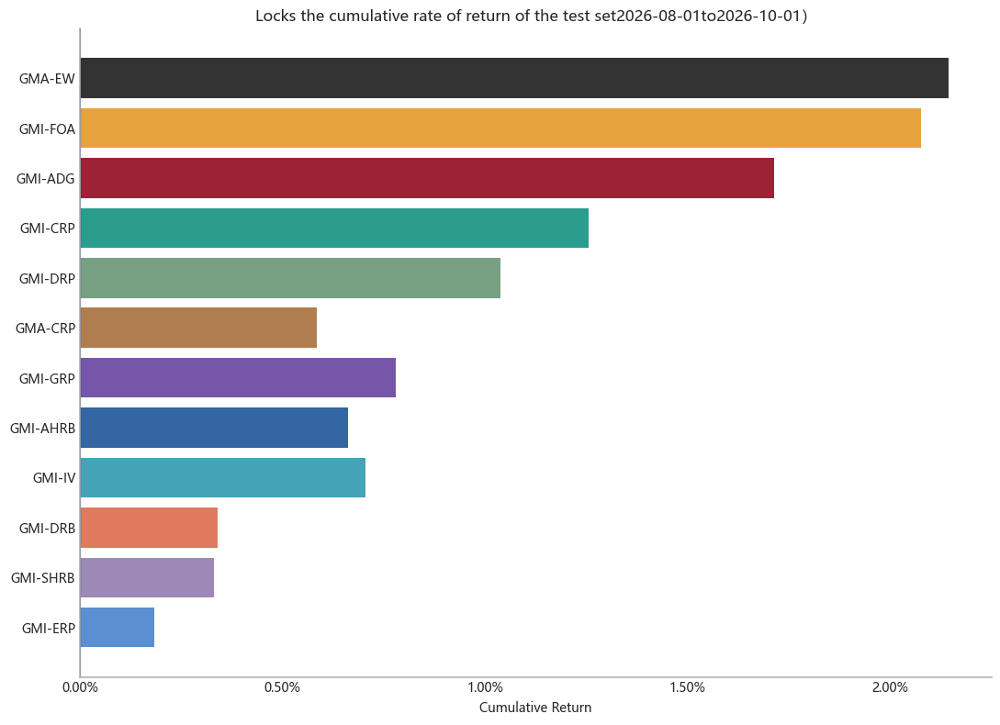

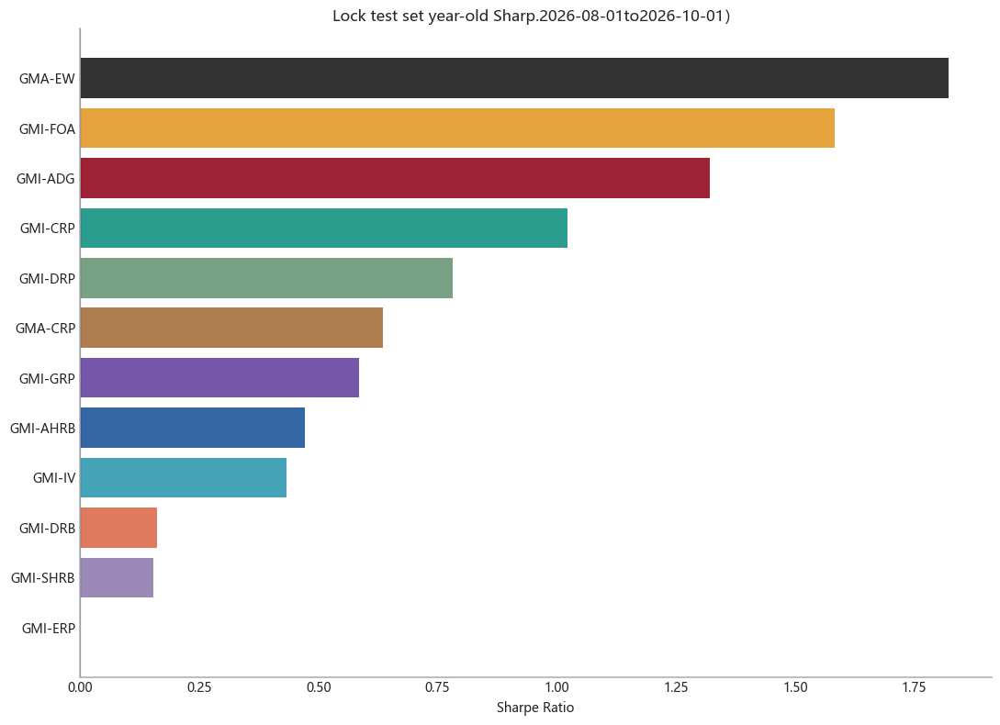

,Value
Lock Test Start,2026-08-01
Actual test endpoint,2026-10-01
Common Test Trade Day,44
Number of testing strategies,12
Late date for research results,2026-07-31


Lock-in test completed: As a short-term observation of the area not visible, not for long-term Alpha certification or parameter selection.


In [27]:
# The results must all be stopped before the lockdown test set.
research_end_by_strategy = pd.Series({
    name: result['returns'].dropna().index.max()
    for name, result in results.items()
}, name='Final date of research findings')
if not (research_end_by_strategy < HOLDOUT_START).all():
    leaked = research_end_by_strategy[research_end_by_strategy >= HOLDOUT_START]
    raise RuntimeError(f'The following results show data leakage:{leaked.to_dict()}')

# Lock the test module to allow SORA after 2026-07-31.
sora_holdout_df = load_sora_daily(HOLDOUT_END)
assert sora_holdout_df.index.max() <= HOLDOUT_END

holdout_results = {
    name: run_dynamic_backtest(
        name, allocator, covariance_function, end_date=HOLDOUT_END,
        sora_frame=sora_holdout_df, allow_holdout=True,
    )
    for name, (allocator, covariance_function) in strategy_specs.items()
}

holdout_results.update({
    CORE_ATTACK_NAME: run_core_attack_backtest(
        CORE_ATTACK_NAME, end_date=HOLDOUT_END,
        sora_frame=sora_holdout_df, allow_holdout=True,
    ),
    DYNAMIC_ATTACK_NAME: run_dynamic_attack_backtest(
        DYNAMIC_ATTACK_NAME, end_date=HOLDOUT_END,
        sora_frame=sora_holdout_df, allow_holdout=True,
    ),
    STATIC_CLASSIC_NAME: run_all_asset_monthly_backtest(
        STATIC_CLASSIC_NAME, target_all_asset_classic, end_date=HOLDOUT_END,
        sora_frame=sora_holdout_df, allow_holdout=True,
    ),})
required_holdout_strategies = {FULLY_DYNAMIC_BUDGET_NAME, CORE_ATTACK_NAME, DYNAMIC_ATTACK_NAME}
if not required_holdout_strategies.issubset(holdout_results):
    raise RuntimeError('The three core product strategies were not all tested outside the locked sample.')

actual_holdout_end = min(
    HOLDOUT_END,
    min(result['returns'].dropna().index.max() for result in holdout_results.values()),
)
if actual_holdout_end < HOLDOUT_START:
    raise RuntimeError('There are no commonly available strategic benefits for locking the test area.')

holdout_metric_table = pd.DataFrame({
    name: compute_metrics(result, HOLDOUT_START, actual_holdout_end)
    for name, result in holdout_results.items()
}).T
holdout_metric_table.index.name = 'Policy'
holdout_metric_table = holdout_metric_table.sort_values(
    'Sharpe Ratio', ascending=True, kind='mergesort'
)
holdout_metric_table.insert(
    0, 'Shape Sorting Number (low to high)', np.arange(1, len(holdout_metric_table) + 1)
)

holdout_display = holdout_metric_table.copy()
for column in ['Cumulative Return', 'Annualized Return', 'Annualized Volatility', 'Maximum Drawdown',
               'Positive-Day Ratio', 'Annual One-Way Turnover', 'Annual Two-Way Traded Notional', 'Average Gross Exposure']:
    holdout_display[column] = holdout_display[column].map(lambda x: f'{x:.2%}')
for column in ['Sharpe Ratio', 'Sortino Ratio', 'Calmar Ratio']:
    holdout_display[column] = holdout_display[column].map(lambda x: f'{x:.2f}')
holdout_display['Number of Rebalances'] = holdout_display['Number of Rebalances'].astype(int)
holdout_display['Number of Trade Legs'] = holdout_display['Number of Trade Legs'].astype(int)
display(holdout_display)

holdout_returns = pd.concat(
    [result['returns'].rename(name) for name, result in holdout_results.items()],
    axis=1,
).loc[HOLDOUT_START:actual_holdout_end].dropna(how='any')

ranked = holdout_metric_table.sort_values('Sharpe Ratio')
colors = [
    HIGHLIGHT_COLORS.get(strategy_name, MUTED_COLOR)
    for strategy_name in ranked.index
]

ranked_labels = [strategy_label(name) for name in ranked.index]
fig, ax = plt.subplots(figsize=(11, 8))
ax.barh(ranked_labels, ranked['Cumulative Return'], color=colors)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title(f'Locks the cumulative rate of return of the test set{HOLDOUT_START.date()}to{actual_holdout_end.date()}）')
ax.set_xlabel('Cumulative Return')
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=2))
style_axis(ax, axis='x')
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(11, 8))
ax.barh(ranked_labels, ranked['Sharpe Ratio'], color=colors)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title(f'Lock test set year-old Sharp.{HOLDOUT_START.date()}to{actual_holdout_end.date()}）')
ax.set_xlabel('Sharpe Ratio')
style_axis(ax, axis='x')
fig.tight_layout()
plt.show()

holdout_summary = pd.DataFrame({
    'Value': [
        HOLDOUT_START.date(), actual_holdout_end.date(), len(holdout_returns),
        len(holdout_results), research_end_by_strategy.max().date(),
    ]
}, index=['Lock Test Start', 'Actual test endpoint', 'Common Test Trade Day', 'Number of testing strategies', 'Late date for research results'])
display(holdout_summary)
print('Lock-in test completed: As a short-term observation of the area not visible, not for long-term Alpha certification or parameter selection.')


### 5.8 Extended Stress Tests: Historical Shocks, Costs, and Execution Delays


This section only uses research data up to 2026-07-31 and does not read the locking test set. The tests were divided into three groups:

1. **History Event Window**: Declines in risk assets in the fourth quarter of 2018, rebounding after March 2020, appreciation of the United States dollar in 2022, BITs collapse, commodity booms, abnormal fluctuations in crude oil and pound sterling and British asset shocks;
2. ** Transaction cost sensitivity**: increasing the unilateral cost from the benchmark of 0.05 per cent to 0.10, 0.15 per cent and 0.25 per cent in turn, maintaining the same path as in the original warehouse and re-charging the cost per real hand change;
** One-day delay in implementation**: maintenance of signals, selection of assets and target weights, postponement of one transaction date for each target weight, and recalculation of transaction costs, financing costs and warehousing.

Historical windows are situational analyses and do not represent the only official definition of events; multiple windows can overlap. Cost sensitivity is a fixed decision path test that does not assume that cost changes will in turn change the calibration signal. The delay in testing measures the risk at the time of execution rather than simply moving the whole sequence of proceeds.

Start date of transaction End date of transaction  Number of trading days  \
Pressure scenario                               Policy                                                                                                                         
2018Q4 risk asset decline                       Global Momentum Dynamic Risk Budget (GMI-DRB)                     2018-10-01              2018-12-31                      66   
                                                Global Momentum Adaptive Hierarchical Risk Budg...                2018-10-01              2018-12-31                      66   
                                                Global Momentum Fixed Offensive Allocation (GMI...                2018-10-01              2018-12-31                      66   
                                                Global Momentum Adaptive Defense and Growth (GM...                2018-10-01              2018-12-31                      66   
                                                Global Momentum EWMA Risk Parity (GMI-ERP)                        2018-10-01              2018-12-31                      66   
                                                Global Multi-Asset Classic Risk Parity (GMA-CRP)                  2018-10-01              2018-12-31                      66   
                                                Global Multi-Asset Equal Weight (GMA-EW)                          2018-10-01              2018-12-31                      66   
It's a quick rebound after the 2020 outbreak.   Global Momentum Dynamic Risk Budget (GMI-DRB)                     2020-03-24              2020-08-31                     115   
                                                Global Momentum Adaptive Hierarchical Risk Budg...                2020-03-24              2020-08-31                     115   
                                                Global Momentum Fixed Offensive Allocation (GMI...                2020-03-24              2020-08-31                     115   
                                                Global Momentum Adaptive Defense and Growth (GM...                2020-03-24              2020-08-31                     115   
                                                Global Momentum EWMA Risk Parity (GMI-ERP)                        2020-03-24              2020-08-31                     115   
                                                Global Multi-Asset Classic Risk Parity (GMA-CRP)                  2020-03-24              2020-08-31                     115   
                                                Global Multi-Asset Equal Weight (GMA-EW)                          2020-03-24              2020-08-31                     115   
A fast appreciation of $2022                    Global Momentum Dynamic Risk Budget (GMI-DRB)                     2022-01-03              2022-09-27                     192   
                                                Global Momentum Adaptive Hierarchical Risk Budg...                2022-01-03              2022-09-27                     192   
                                                Global Momentum Fixed Offensive Allocation (GMI...                2022-01-03              2022-09-27                     192   
                                                Global Momentum Adaptive Defense and Growth (GM...                2022-01-03              2022-09-27                     192   
                                                Global Momentum EWMA Risk Parity (GMI-ERP)                        2022-01-03              2022-09-27                     192   
                                                Global Multi-Asset Classic Risk Parity (GMA-CRP)                  2022-01-03              2022-09-27                     192   
                                                Global Multi-Asset Equal Weight (GMA-EW)                          2022-01-03              2022-09-27                     192   
Bitcoin was higher, and then independence fell. Glo

,Maximum yield strategy,Maximum accumulated proceeds,Revert Minimum Policy,Minimal maximum retreat,Case Line Cumulative Gain
Pressure scenario,,,,,
2018Q4 risk asset decline,Global Momentum Adaptive Hierarchical Risk Bud...,-4.05%,Global Momentum EWMA Risk Parity (GMI-ERP),-5.10%,-10.54%
It's a quick rebound after the 2020 outbreak.,Global Multi-Asset Equal Weight (GMA-EW),19.39%,Global Momentum Fixed Offensive Allocation (GM...,-1.73%,19.39%
A fast appreciation of $2022,Global Momentum Adaptive Defense and Growth (G...,3.45%,Global Momentum Adaptive Defense and Growth (G...,-3.45%,-13.00%
"Bitcoin was higher, and then independence fell.",Global Momentum Dynamic Risk Budget (GMI-DRB),-2.85%,Global Momentum EWMA Risk Parity (GMI-ERP),-4.10%,-11.88%
2021 to 2022 commodity boom,Global Momentum Dynamic Risk Budget (GMI-DRB),0.17%,Global Multi-Asset Classic Risk Parity (GMA-CRP),-4.06%,-4.94%
Unusually volatile 2020 crude oil,Global Momentum Adaptive Defense and Growth (G...,3.14%,Global Momentum Fixed Offensive Allocation (GM...,-2.25%,-6.51%
Pound2022 and British asset shock,Global Momentum Fixed Offensive Allocation (GM...,0.22%,Global Momentum Fixed Offensive Allocation (GM...,-1.41%,-4.39%


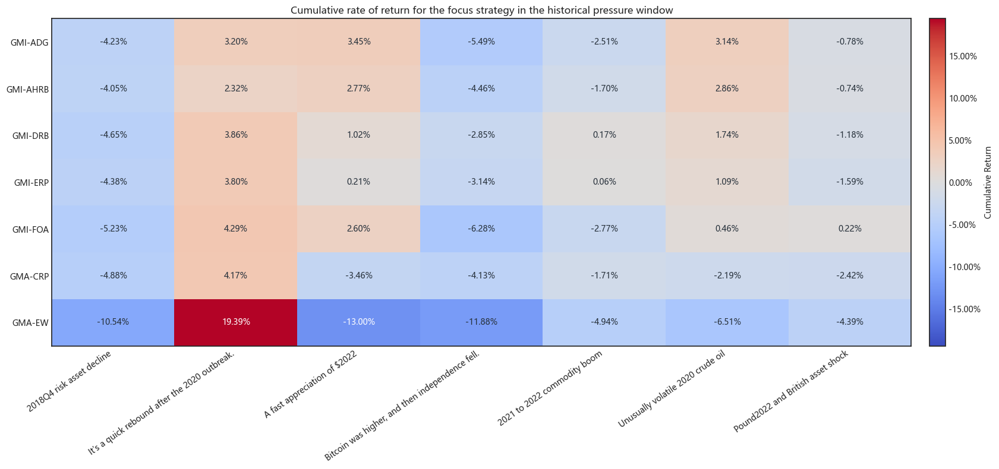

In [28]:
# Prevents unexpected reading of locking test sets in this section.
if strategy_returns.index.max() > RESEARCH_END:
    raise RuntimeError('Pressure tests have detected research returns exceeding 2026-07-31.')

extended_stress_windows = {
    '2018Q4 risk asset decline': ('2018-10-01', '2018-12-31'),
    'It\'s a quick rebound after the 2020 outbreak.': ('2020-03-24', '2020-08-31'),
    'A fast appreciation of $2022': ('2022-01-03', '2022-09-27'),
    'Bitcoin was higher, and then independence fell.': ('2021-11-10', '2022-06-17'),
    '2021 to 2022 commodity boom': ('2021-11-01', '2022-06-08'),
    'Unusually volatile 2020 crude oil': ('2020-03-09', '2020-04-28'),
    'Pound2022 and British asset shock': ('2022-09-01', '2022-10-31'),
}

historical_stress_records = []
for scenario, (start, end) in extended_stress_windows.items():
    scenario_returns = strategy_returns.loc[start:end, FOCUS_STRATEGIES]
    for strategy_name in scenario_returns.columns:
        r = scenario_returns[strategy_name].dropna()
        if len(r) < 2:
            continue
        historical_stress_records.append({
            'Pressure scenario': scenario,
            'Policy': strategy_name,
            'Start date of transaction': r.index.min().date(),
            'End date of transaction': r.index.max().date(),
            'Number of trading days': len(r),
            'Cumulative Return': float((1.0 + r).prod() - 1.0),
            'Maximum Drawdown': float(drawdown_series(r).min()),
            'Annualized Volatility': float(r.std(ddof=1) * np.sqrt(TRADING_DAYS)),
            'Worst day of earnings': float(r.min()),
        })

extended_stress_test = pd.DataFrame(historical_stress_records).set_index(['Pressure scenario', 'Policy'])
extended_stress_display = extended_stress_test.copy()
for column in ['Cumulative Return', 'Maximum Drawdown', 'Annualized Volatility', 'Worst day of earnings']:
    extended_stress_display[column] = extended_stress_display[column].map(lambda x: f'{x:.2%}')
display(extended_stress_display)

stress_summary_records = []
for scenario, frame in extended_stress_test.groupby(level='Pressure scenario', sort=False):
    local = frame.droplevel('Pressure scenario')
    best_return_strategy = local['Cumulative Return'].idxmax()
    best_drawdown_strategy = local['Maximum Drawdown'].idxmax()
    scenario_start, scenario_end = extended_stress_windows[scenario]
    baseline_returns = strategy_returns.loc[scenario_start:scenario_end, BASELINE_STRATEGY].dropna()
    baseline_cumulative_return = float((1.0 + baseline_returns).prod() - 1.0)
    stress_summary_records.append({
        'Pressure scenario': scenario,
        'Maximum yield strategy': best_return_strategy,
        'Maximum accumulated proceeds': local.loc[best_return_strategy, 'Cumulative Return'],
        'Revert Minimum Policy': best_drawdown_strategy,
        'Minimal maximum retreat': local.loc[best_drawdown_strategy, 'Maximum Drawdown'],
        'Case Line Cumulative Gain': baseline_cumulative_return,
    })
stress_scenario_summary = pd.DataFrame(stress_summary_records).set_index('Pressure scenario')
stress_scenario_summary_display = stress_scenario_summary.copy()
for column in ['Maximum accumulated proceeds', 'Minimal maximum retreat', 'Case Line Cumulative Gain']:
    stress_scenario_summary_display[column] = stress_scenario_summary_display[column].map(lambda x: f'{x:.2%}')
display(stress_scenario_summary_display)

stress_heatmap = extended_stress_test['Cumulative Return'].unstack(level='Pressure scenario')
stress_heatmap = stress_heatmap.reindex(columns=list(extended_stress_windows))
limit = float(np.nanmax(np.abs(stress_heatmap.values)))
fig, ax = plt.subplots(figsize=(17, max(8, 0.45 * len(stress_heatmap))))
image = ax.imshow(stress_heatmap.values, aspect='auto', cmap='coolwarm', vmin=-limit, vmax=limit)
ax.set_xticks(np.arange(len(stress_heatmap.columns)))
ax.set_xticklabels(stress_heatmap.columns, rotation=35, ha='right', fontsize=10)
ax.set_yticks(np.arange(len(stress_heatmap.index)))
ax.set_yticklabels([strategy_label(name) for name in stress_heatmap.index], fontsize=10)
ax.set_title('Cumulative rate of return for the focus strategy in the historical pressure window')
colorbar = fig.colorbar(image, ax=ax, fraction=0.025, pad=0.02)
colorbar.set_label('Cumulative Return')
colorbar.ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=2))
for row in range(stress_heatmap.shape[0]):
    for column in range(stress_heatmap.shape[1]):
        value = stress_heatmap.iat[row, column]
        if pd.notna(value):
            text_color = 'white' if abs(value) > 0.62 * limit else '#27313B'
            ax.text(column, row, f'{value:.2%}', ha='center', va='center',
                    fontsize=10, color=text_color)
colorbar.ax.tick_params(labelsize=10)
fig.tight_layout()
plt.show()


### 5.8.1 Transaction-Cost Sensitivity


The common strategy is revalued on the basis of uniform unilateral costs; the practical implementation strategy retains the relative differences between asset transactions and exchange costs, and is scaled down by the multiple of the relative underlying cost of the scenario. This treatment does not change signals, target weights or the date of the mobilization. 0.05 per cent is the optimistic benchmark and 0.1 per cent, 0.15 per cent and 0.25 per cent are more conservative scenarios.

Cumulative Return Annualized Return Sharpe Ratio Maximum Drawdown Annual One-Way Turnover
Policy                                             Fixed cost multiplier                                                                                          
Global Momentum Dynamic Risk Budget (GMI-DRB)      0.50                            230.25%            11.20%         1.27           -9.45%                 342.42%
                                                   1.00                            223.95%            11.01%         1.25           -9.48%                 342.42%
                                                   1.50                            217.76%            10.82%         1.23           -9.50%                 342.42%
                                                   2.00                            211.69%            10.63%         1.20           -9.52%                 342.42%
Global Momentum Adaptive Hierarchical Risk Budg... 0.50                            279.40%            12.57%         1.28           -9.73%                 397.89%
                                                   1.00                            270.99%            12.35%         1.26           -9.75%                 397.89%
                                                   1.50                            262.77%            12.13%         1.24           -9.78%                 397.89%
                                                   2.00                            254.74%            11.90%         1.21           -9.80%                 397.89%
Global Momentum Fixed Offensive Allocation (GMI... 0.50                            374.32%            14.83%         1.17          -15.45%                 446.31%
                                                   1.00                            362.55%            14.57%         1.15          -15.51%                 446.31%
                                                   1.50                            351.07%            14.32%         1.13          -15.57%                 446.31%
                                                   2.00                            339.87%            14.06%         1.11          -15.63%                 446.31%
Global Momentum Adaptive Defense and Growth (GM... 0.50                            452.05%            16.39%         1.34          -14.94%                 342.17%
                                                   1.00                            441.52%            16.19%         1.32          -14.98%                 342.17%
                                                   1.50                            431.18%            15.99%         1.31          -15.02%                 342.17%
                                                   2.00                            421.04%            15.79%         1.29          -15.05%                 342.17%
Global Momentum EWMA Risk Parity (GMI-ERP)         0.50                            214.72%            10.72%         1.25           -8.99%                 341.40%
                                                   1.00                            208.73%            10.53%         1.23           -9.01%                 341.40%
                                                   1.50                            202.85%            10.34%         1.20           -9.03%                 341.40%
                                                   2.00                            197.08%            10.15%         1.18           -9.05%                 341.40%
Global Multi-Asset Classic Risk Parity (GMA-CRP)   0.50                             80.12%             5.37%         0.81           -8.29%                  36.01%
                                                   1.00                             79.75%             5.35%         0.81           -8.30%                  36.01%
                                                   1.50                             79.39%             5.33%         0.80           -8.30%                  36.01

Cumulative Return Annualized Return Sharpe Ratio Maximum Drawdown Annual One-Way Turnover
Policy                                             Fixed cost multiplier                                                                                          
Global Momentum Dynamic Risk Budget (GMI-DRB)      0.50                            230.25%            11.20%         1.27           -9.45%                 342.42%
                                                   1.00                            223.95%            11.01%         1.25           -9.48%                 342.42%
                                                   1.50                            217.76%            10.82%         1.23           -9.50%                 342.42%
                                                   2.00                            211.69%            10.63%         1.20           -9.52%                 342.42%
Global Momentum Adaptive Hierarchical Risk Budg... 0.50                            279.40%            12.57%         1.28           -9.73%                 397.89%
                                                   1.00                            270.99%            12.35%         1.26           -9.75%                 397.89%
                                                   1.50                            262.77%            12.13%         1.24           -9.78%                 397.89%
                                                   2.00                            254.74%            11.90%         1.21           -9.80%                 397.89%
Global Momentum Fixed Offensive Allocation (GMI... 0.50                            374.32%            14.83%         1.17          -15.45%                 446.31%
                                                   1.00                            362.55%            14.57%         1.15          -15.51%                 446.31%
                                                   1.50                            351.07%            14.32%         1.13          -15.57%                 446.31%
                                                   2.00                            339.87%            14.06%         1.11          -15.63%                 446.31%
Global Momentum Adaptive Defense and Growth (GM... 0.50                            452.05%            16.39%         1.34          -14.94%                 342.17%
                                                   1.00                            441.52%            16.19%         1.32          -14.98%                 342.17%
                                                   1.50                            431.18%            15.99%         1.31          -15.02%                 342.17%
                                                   2.00                            421.04%            15.79%         1.29          -15.05%                 342.17%
Global Momentum EWMA Risk Parity (GMI-ERP)         0.50                            214.72%            10.72%         1.25           -8.99%                 341.40%
                                                   1.00                            208.73%            10.53%         1.23           -9.01%                 341.40%
                                                   1.50                            202.85%            10.34%         1.20           -9.03%                 341.40%
                                                   2.00                            197.08%            10.15%         1.18           -9.05%                 341.40%
Global Multi-Asset Classic Risk Parity (GMA-CRP)   0.50                             80.12%             5.37%         0.81           -8.29%                  36.01%
                                                   1.00                             79.75%             5.35%         0.81           -8.30%                  36.01%
                                                   1.50                             79.39%             5.33%         0.80           -8.30%                  36.01

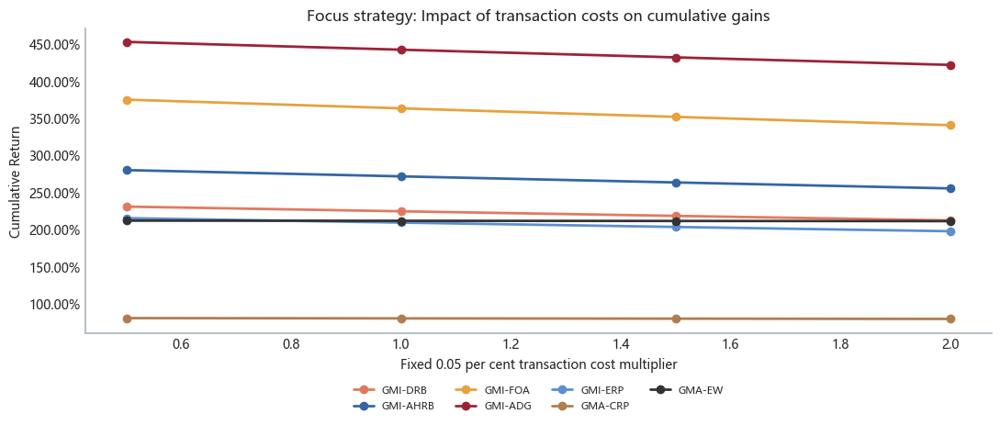

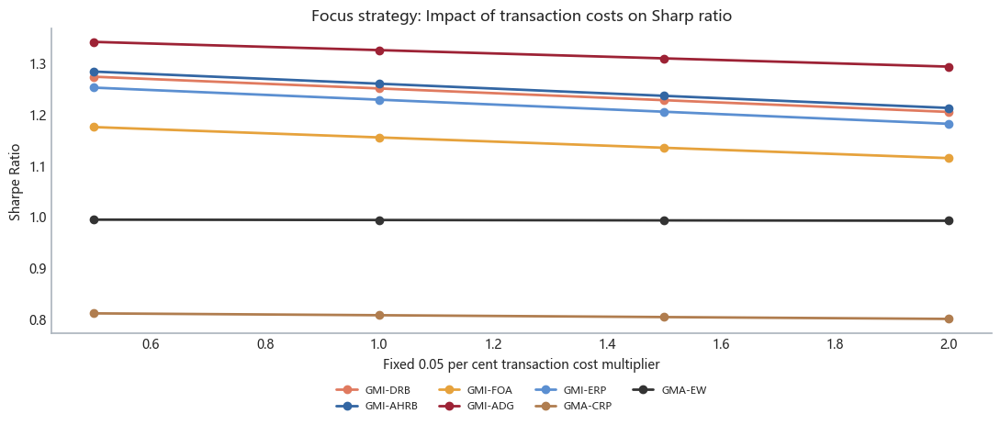

In [29]:
TRANSACTION_COST_MULTIPLIERS = [0.5, 1.0, 1.5, 2.0]


def returns_under_cost(result, cost_multiplier):
    """Revalue the cost without changing the signal and target weight path.

The uniform unilateral 0.05 per cent transaction fee is reduced by a factor, without changing the signal and hold path.
"""
    original_returns = result['returns'].loc[:RESEARCH_END].copy()
    original_cost_rate = result['transaction_cost'].reindex(original_returns.index).fillna(0.0)
    new_cost_rate = original_cost_rate * float(cost_multiplier)
    if (original_cost_rate >= 1.0).any() or (new_cost_rate >= 1.0).any():
        raise RuntimeError('A cost rate of 100 per cent or more cannot be reformulated.')
    after_tax_gross_factor = (1.0 + original_returns) / (1.0 - original_cost_rate)
    return after_tax_gross_factor * (1.0 - new_cost_rate) - 1.0


cost_sensitivity_records = []
for strategy_name in FOCUS_STRATEGIES:
    result = results[strategy_name]
    for cost_multiplier in TRANSACTION_COST_MULTIPLIERS:
        adjusted_returns = returns_under_cost(result, cost_multiplier)
        if cost_multiplier == 1.0:
            reconstruction_error = float(
                (adjusted_returns - result['returns'].loc[:RESEARCH_END]).abs().max()
            )
            if reconstruction_error > 1e-12:
                raise RuntimeError(
                    f'{strategy_name}Base cost gain re-engineering failed:{reconstruction_error:.3e}'
                )
        adjusted_result = {
            **result,
            'returns': adjusted_returns.rename(strategy_name),
        }
        metric = compute_metrics(adjusted_result, None, RESEARCH_END)
        cost_sensitivity_records.append({
            'Policy': strategy_name,
            'Fixed cost multiplier': cost_multiplier,
            'Cumulative Return': metric['Cumulative Return'],
            'Annualized Return': metric['Annualized Return'],
            'Sharpe Ratio': metric['Sharpe Ratio'],
            'Maximum Drawdown': metric['Maximum Drawdown'],
            'Annual One-Way Turnover': metric['Annual One-Way Turnover'],
        })

cost_sensitivity = pd.DataFrame(cost_sensitivity_records).set_index(['Policy', 'Fixed cost multiplier'])
cost_sensitivity_display = cost_sensitivity.copy()
for column in ['Cumulative Return', 'Annualized Return', 'Maximum Drawdown', 'Annual One-Way Turnover']:
    cost_sensitivity_display[column] = cost_sensitivity_display[column].map(lambda x: f'{x:.2%}')
cost_sensitivity_display['Sharpe Ratio'] = cost_sensitivity_display['Sharpe Ratio'].map(lambda x: f'{x:.2f}')
display(cost_sensitivity_display)

focus_cost_strategies = FOCUS_STRATEGIES.copy()
display(cost_sensitivity_display.loc[focus_cost_strategies])
cost_plot = cost_sensitivity.reset_index()
cost_plot = cost_plot[cost_plot['Policy'].isin(focus_cost_strategies)]
cost_colors = {name: HIGHLIGHT_COLORS.get(name, '#4C78A8') for name in focus_cost_strategies}
fig, ax = plt.subplots(figsize=(11, 6))
for strategy_name in focus_cost_strategies:
    subset = cost_plot[cost_plot['Policy'] == strategy_name].sort_values('Fixed cost multiplier')
    ax.plot(subset['Fixed cost multiplier'], subset['Cumulative Return'], marker='o', linestyle='-',
            color=cost_colors[strategy_name], label=strategy_label(strategy_name), linewidth=2)
ax.set_title('Focus strategy: Impact of transaction costs on cumulative gains')
ax.set_ylabel('Cumulative Return')
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=2))
ax.set_xlabel('Fixed 0.05 per cent transaction cost multiplier')
style_axis(ax)
place_legend(ax)
fig.tight_layout(rect=[0, 0.18, 1, 1])
plt.show()

fig, ax = plt.subplots(figsize=(11, 6))
for strategy_name in focus_cost_strategies:
    subset = cost_plot[cost_plot['Policy'] == strategy_name].sort_values('Fixed cost multiplier')
    ax.plot(subset['Fixed cost multiplier'], subset['Sharpe Ratio'], marker='o', linestyle='-',
            color=cost_colors[strategy_name], label=strategy_label(strategy_name), linewidth=2)
ax.set_title('Focus strategy: Impact of transaction costs on Sharp ratio')
ax.set_ylabel('Sharpe Ratio')
ax.set_xlabel('Fixed 0.05 per cent transaction cost multiplier')
style_axis(ax)
place_legend(ax)
fig.tight_layout(rect=[0, 0.18, 1, 1])
plt.show()


### 5.8.2 One-Day Execution-Delay Sensitivity


The formal strategy itself has adopted a letter number for at least one transaction. In this section, each strategy is extended by an existing transaction date to test additional implementation frictions; the cost-sharing strategy continues to use its own transaction and exchange costs rather than returning the flat 0.05 per cent cost.

,Original cumulative rate of return,Cumulative rate of return after delay,Change in cumulative proceeds,Former Sharp ratio,Sharp ratio after delay,Sharp changes,Max. Back.,Maximum retreat after delay,Annual change rate after delay
Policy,,,,,,,,,
Global Momentum Fixed Offensive Allocation (GMI-FOA),362.55%,361.96%,-0.58%,1.15,1.15,-0.00,-15.51%,-14.98%,444.04%
Global Momentum Dynamic Risk Budget (GMI-DRB),223.95%,211.32%,-12.63%,1.25,1.19,-0.05,-9.48%,-9.46%,341.63%
Global Momentum EWMA Risk Parity (GMI-ERP),208.73%,194.02%,-14.70%,1.23,1.16,-0.07,-9.01%,-9.76%,340.26%
Global Momentum Adaptive Defense and Growth (GMI-ADG),441.52%,425.01%,-16.50%,1.32,1.31,-0.02,-14.98%,-14.60%,342.66%
Global Momentum Adaptive Hierarchical Risk Budget (GMI-AHRB),270.99%,251.89%,-19.10%,1.26,1.20,-0.06,-9.75%,-9.40%,396.71%
Global Multi-Asset Classic Risk Parity (GMA-CRP),79.75%,80.78%,1.03%,0.81,0.82,0.01,-8.30%,-8.18%,35.95%
Global Multi-Asset Equal Weight (GMA-EW),211.15%,220.25%,9.10%,0.99,1.02,0.03,-17.87%,-17.87%,13.40%


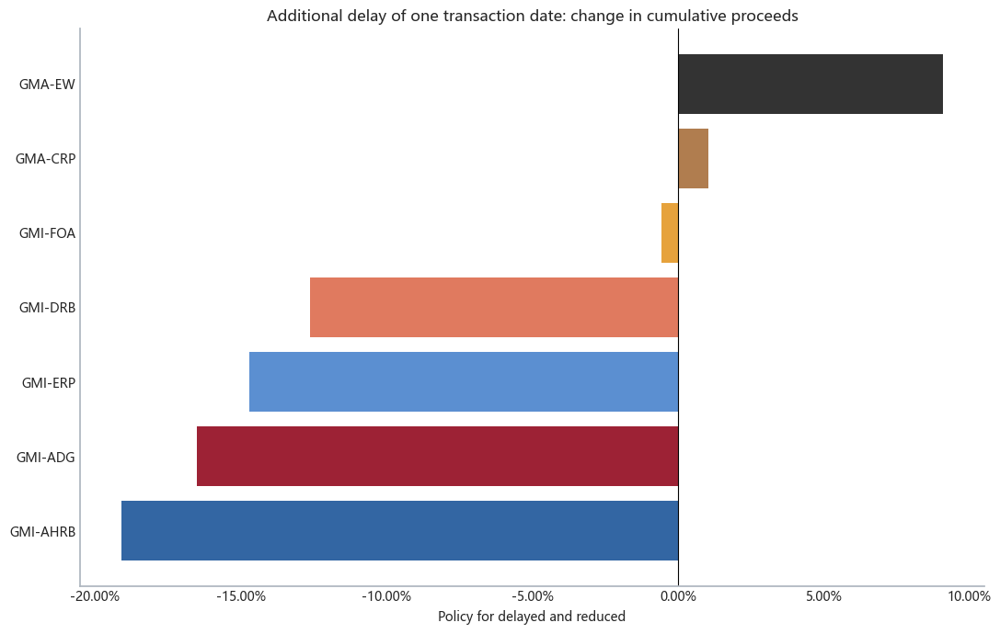

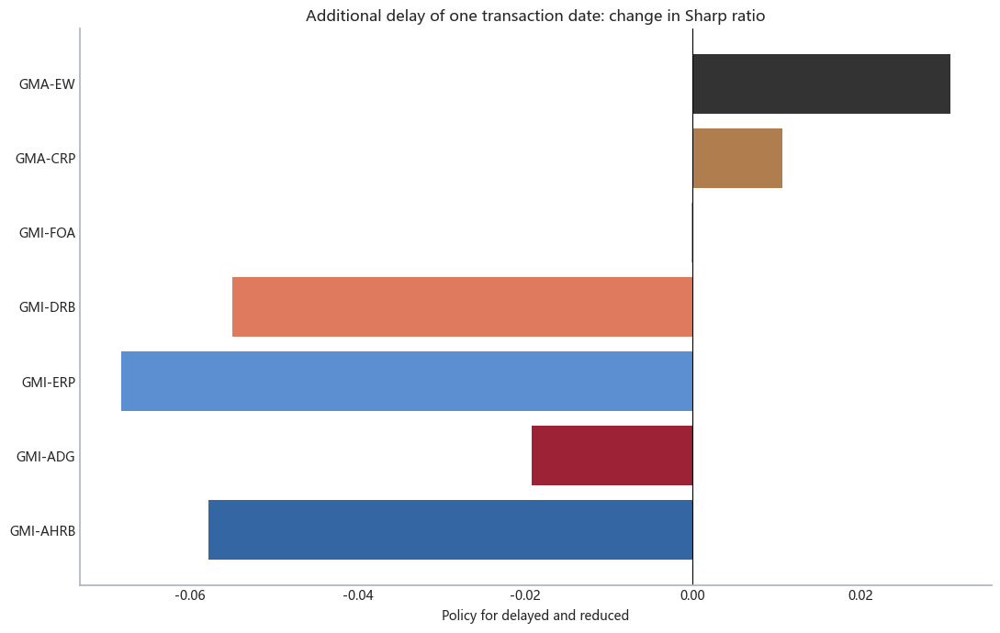

Pressure test data used as of2026-07-31；Lock test start to2026-08-01, not read in this section.


In [30]:
def one_day_delayed_execution(result):
    """An additional trade date is postponed from the official implementation date and the original strategic cost structure is followed."""
    research_calendar = returns.loc[strategy_start:RESEARCH_END].index
    original_targets = result['weights'].loc[:RESEARCH_END].copy()
    trade_assets = list(result.get('trade_assets', ALL_ASSETS))
    original_targets = original_targets.reindex(columns=trade_assets, fill_value=0.0)
    delayed_targets = {}
    for execution_date, target in original_targets.iterrows():
        location = research_calendar.searchsorted(execution_date, side='right')
        if location < len(research_calendar):
            delayed_targets[research_calendar[location]] = target.copy()

    current_weights = pd.Series(0.0, index=trade_assets)
    result_rf = result['risk_free_daily'].reindex(research_calendar).ffill()
    result_funding = result['funding_daily'].reindex(research_calendar).ffill()
    if result_rf.isna().any() or result_funding.isna().any():
        raise RuntimeError(f"{result['name']}SORA coverage is incomplete.")
    return_source = result.get('instrument_returns', portfolio_returns_for_backtest)
    return_source = return_source.reindex(index=research_calendar, columns=trade_assets).fillna(0.0)
    asset_cost = pd.Series(result.get('asset_cost_rate', COST), index=trade_assets, dtype=float)
    daily_records, turnover_records, trade_leg_records, cost_records, weight_records = [], [], [], [], []
    pre_return_records, end_of_day_records, trade_delta_records = [], [], []

    for date in research_calendar:
        pre_return_records.append(current_weights.rename(date))
        day_return = return_source.loc[date]
        cash_weight = 1.0 - float(current_weights.sum())
        cash_rate = float(result_rf.loc[date] if cash_weight >= 0 else result_funding.loc[date])
        before_cost_return = float(current_weights @ day_return) + cash_weight * cash_rate
        if 1.0 + before_cost_return <= 0:
            raise RuntimeError('The net value of the additional delay strategy is not positive.')
        current_weights = current_weights * (1.0 + day_return) / (1.0 + before_cost_return)

        cost_rate = 0.0
        if date in delayed_targets:
            target = delayed_targets[date]
            delta = target - current_weights
            turnover = float(delta.abs().sum())
            trade_legs = int((delta.abs() > 1e-10).sum())
            cost_rate = float((delta.abs() * asset_cost).sum())
            current_weights = target.copy()
            turnover_records.append((date, turnover))
            trade_leg_records.append((date, trade_legs))
            cost_records.append((date, cost_rate))
            weight_records.append(current_weights.rename(date))
            trade_delta_records.append(delta.rename(date))

        net_return = (1.0 - cost_rate) * (1.0 + before_cost_return) - 1.0
        daily_records.append((date, net_return))
        end_of_day_records.append(current_weights.rename(date))

    delayed_result = {
        'name': result['name'] + '(Additional delay of 1 day)',
        'returns': pd.Series(dict(daily_records), name=result['name'] + '(Additional delay of 1 day)'),
        'turnover': pd.Series(dict(turnover_records), dtype=float),
        'trade_legs': pd.Series(dict(trade_leg_records), dtype=float),
        'transaction_cost': pd.Series(dict(cost_records), dtype=float),
        'weights': pd.DataFrame(weight_records), 'risk_free_daily': result_rf,
        'pre_return_weights': pd.DataFrame(pre_return_records),
        'end_of_day_weights': pd.DataFrame(end_of_day_records),
        'trade_deltas': pd.DataFrame(trade_delta_records),
        'funding_daily': result_funding, 'asset_cost_rate': asset_cost,
        'trade_assets': trade_assets, 'instrument_returns': return_source,
    }
    return delayed_result


delayed_results = {
    name: one_day_delayed_execution(results[name])
    for name in FOCUS_STRATEGIES
}

delay_sensitivity_records = []
for strategy_name in FOCUS_STRATEGIES:
    original_result = results[strategy_name]
    original_metric = compute_metrics(original_result, None, RESEARCH_END)
    delayed_metric = compute_metrics(delayed_results[strategy_name], None, RESEARCH_END)
    delay_sensitivity_records.append({
        'Policy': strategy_name,
        'Original cumulative rate of return': original_metric['Cumulative Return'],
        'Cumulative rate of return after delay': delayed_metric['Cumulative Return'],
        'Change in cumulative proceeds': delayed_metric['Cumulative Return'] - original_metric['Cumulative Return'],
        'Former Sharp ratio': original_metric['Sharpe Ratio'],
        'Sharp ratio after delay': delayed_metric['Sharpe Ratio'],
        'Sharp changes': delayed_metric['Sharpe Ratio'] - original_metric['Sharpe Ratio'],
        'Max. Back.': original_metric['Maximum Drawdown'],
        'Maximum retreat after delay': delayed_metric['Maximum Drawdown'],
        'Annual change rate after delay': delayed_metric['Annual One-Way Turnover'],
    })

execution_delay_test = pd.DataFrame(delay_sensitivity_records).set_index('Policy')
execution_delay_display = execution_delay_test.copy()
for column in ['Original cumulative rate of return', 'Cumulative rate of return after delay', 'Change in cumulative proceeds',
               'Max. Back.', 'Maximum retreat after delay', 'Annual change rate after delay']:
    execution_delay_display[column] = execution_delay_display[column].map(lambda x: f'{x:.2%}')
for column in ['Former Sharp ratio', 'Sharp ratio after delay', 'Sharp changes']:
    execution_delay_display[column] = execution_delay_display[column].map(lambda x: f'{x:.2f}')
display(execution_delay_display.sort_values('Change in cumulative proceeds'))

delay_plot = execution_delay_test.sort_values('Change in cumulative proceeds')
bar_colors = [
    HIGHLIGHT_COLORS.get(name, '#4C78A8')
    for name in delay_plot.index
]
delay_labels = [strategy_label(name) for name in delay_plot.index]
fig, ax = plt.subplots(figsize=(11, 7))
ax.barh(delay_labels, delay_plot['Change in cumulative proceeds'], color=bar_colors)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Additional delay of one transaction date: change in cumulative proceeds')
ax.set_xlabel('Policy for delayed and reduced')
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=2))
style_axis(ax, axis='x')
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(11, 7))
ax.barh(delay_labels, delay_plot['Sharp changes'], color=bar_colors)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Additional delay of one transaction date: change in Sharp ratio')
ax.set_xlabel('Policy for delayed and reduced')
style_axis(ax, axis='x')
fig.tight_layout()
plt.show()

print(
    f'Pressure test data used as of{strategy_returns.index.max().date()}；'
    f'Lock test start to{HOLDOUT_START.date()}, not read in this section.'
)


### 5.9 Joint Hypothetical Shocks: Static Portfolio Stress Test

This section restores the economically meaningful simulation scenario tests and regularizes the following three core strategies:

1. **Software and sound configuration**;
2. **Swissling Chile **;
3. **Swissing Ji-chun Spirit.**

The table also shows their cumulative return ranking up to the research period of 2026-07-31. The ranking, current hold and SORA are all based on research-period data and do not read lock-in test sets.

The shock is interpreted as a change in the total return of SSD for a month and at the same time as a combination of weights currently recorded. It measures static losses when “shocks occur immediately and fail to adjust” and does not represent projections of future gains, nor is it used for reverse optimization parameters.

,Cumulative return ranking for the research period,Cumulative rate of return for the research period,Reason for inclusion
Policy,,,
Global Momentum Adaptive Hierarchical Risk Budget (GMI-AHRB),3,270.99%,Core risk budget strategy
Global Momentum Fixed Offensive Allocation (GMI-FOA),2,362.55%,Fixed attack sleeves
Global Momentum Adaptive Defense and Growth (GMI-ADG),1,441.52%,Dynamic attack sleeves.


Code,SPY,QQQ,IWM,EXS1.DE,ISF.L,1308.T,510300.SS,2800.HK,ES3.SI,IEF,511010.SS,USO,DBB,GLD,UUP,FXY,FXE,BTC-USD
Inflationary stock debt double kill,-18.0%,-18.0%,-18.0%,-18.0%,-18.0%,-18.0%,-18.0%,-18.0%,-18.0%,-12.0%,-5.0%,25.0%,12.0%,10.0%,8.0%,-6.0%,-8.0%,-35.0%
Global recession and risk aversion,-25.0%,-25.0%,-25.0%,-25.0%,-25.0%,-25.0%,-25.0%,-25.0%,-25.0%,7.0%,3.0%,-28.0%,-18.0%,6.0%,9.0%,5.0%,-6.0%,-50.0%
Global liquidity crisis,-30.0%,-30.0%,-30.0%,-30.0%,-30.0%,-30.0%,-30.0%,-30.0%,-30.0%,-6.0%,-6.0%,-22.0%,-22.0%,-10.0%,10.0%,3.0%,-10.0%,-55.0%
Asset and exchange rate shocks in Asia,-10.0%,-10.0%,-10.0%,-10.0%,-10.0%,-20.0%,-22.0%,-25.0%,-18.0%,-3.0%,-3.0%,-8.0%,-8.0%,4.0%,8.0%,-12.0%,-3.0%,-25.0%
Rapid post-crisis risk retreat,20.0%,20.0%,20.0%,20.0%,20.0%,20.0%,20.0%,20.0%,20.0%,-5.0%,-5.0%,12.0%,12.0%,0.0%,-6.0%,-4.0%,5.0%,40.0%


,,Warehousing record date,Total asset weights,Cash weights,Combination of one month of impact gains,Maximum negative contribution assets,Maximum negative contribution
Simulation,Policy,,,,,,
Inflationary stock debt double kill,Global Momentum Adaptive Hierarchical Risk Budget (GMI-AHRB),2026-07-31,100.00%,0.00%,-8.22%,ISF.L,-4.02%
Global recession and risk aversion,Global Momentum Adaptive Hierarchical Risk Budget (GMI-AHRB),2026-07-31,100.00%,0.00%,-22.85%,ISF.L,-5.58%
Global liquidity crisis,Global Momentum Adaptive Hierarchical Risk Budget (GMI-AHRB),2026-07-31,100.00%,0.00%,-27.19%,ISF.L,-6.70%
Asset and exchange rate shocks in Asia,Global Momentum Adaptive Hierarchical Risk Budget (GMI-AHRB),2026-07-31,100.00%,0.00%,-11.08%,ES3.SI,-2.39%
Rapid post-crisis risk retreat,Global Momentum Adaptive Hierarchical Risk Budget (GMI-AHRB),2026-07-31,100.00%,0.00%,17.19%,EXS1.DE,0.00%
Inflationary stock debt double kill,Global Momentum Fixed Offensive Allocation (GMI-FOA),2026-07-31,100.00%,0.00%,-6.86%,IWM,-3.34%
Global recession and risk aversion,Global Momentum Fixed Offensive Allocation (GMI-FOA),2026-07-31,100.00%,0.00%,-23.80%,IWM,-4.64%
Global liquidity crisis,Global Momentum Fixed Offensive Allocation (GMI-FOA),2026-07-31,100.00%,0.00%,-27.23%,IWM,-5.57%
Asset and exchange rate shocks in Asia,Global Momentum Fixed Offensive Allocation (GMI-FOA),2026-07-31,100.00%,0.00%,-11.75%,510300.SS,-2.91%


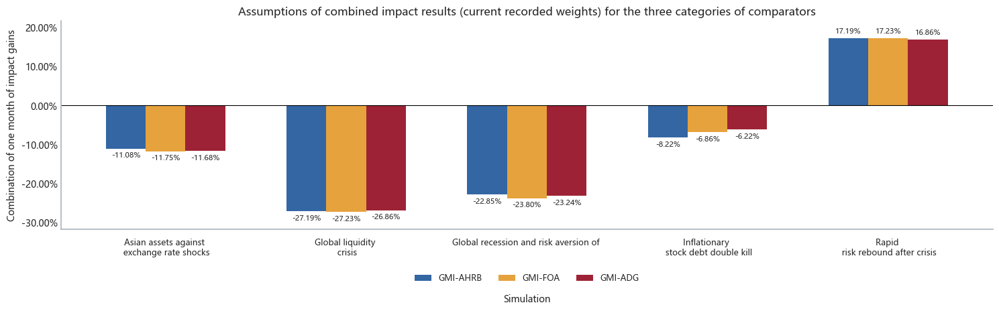

In [31]:
# The reading of the lock-down test set is prohibited by targeting the comparator solely on the basis of the cumulative proceeds from the study area.
research_strategy_returns = strategy_returns.loc[:RESEARCH_END].copy()
if research_strategy_returns.index.max() >= HOLDOUT_START:
    raise RuntimeError('Simulation pressure tests read lock test sets.')

research_cumulative_ranking = (
    (1.0 + research_strategy_returns).prod() - 1.0
).sort_values(ascending=False)
top_two_cumulative_names = research_cumulative_ranking.head(2).index.tolist()
SIMULATED_STRESS_STRATEGIES = CORE_COMPARISON_STRATEGIES.copy()

stress_strategy_selection = pd.DataFrame({
    'Policy': SIMULATED_STRESS_STRATEGIES,
    'Cumulative return ranking for the research period': [
        int(research_cumulative_ranking.index.get_loc(name) + 1)
        for name in SIMULATED_STRESS_STRATEGIES
    ],
    'Cumulative rate of return for the research period': [
        float(research_cumulative_ranking.loc[name])
        for name in SIMULATED_STRESS_STRATEGIES
    ],
    'Reason for inclusion': [
        'Core risk budget strategy' if name == FULLY_DYNAMIC_BUDGET_NAME
        else ('Fixed attack sleeves' if name == CORE_ATTACK_NAME else 'Dynamic attack sleeves.')
        for name in SIMULATED_STRESS_STRATEGIES
    ],
}).set_index('Policy')
display(stress_strategy_selection.style.format({'Cumulative rate of return for the research period': '{:.2%}'}))


def build_hypothetical_shock(category_shocks, overrides=None):
    shock = assets['Asset Class'].map(category_shocks).astype(float)
    if overrides:
        for ticker, value in overrides.items():
            shock.loc[ticker] = float(value)
    if shock.isna().any():
        raise RuntimeError(f'Simulation shock does not cover assets:{shock.index[shock.isna()].tolist()}')
    if (shock <= -1.0).any():
        raise RuntimeError('Simulation shocks cannot be less than or equal to -100%.')
    return shock.reindex(ALL_ASSETS)


hypothetical_scenarios = {
    'Inflationary stock debt double kill': build_hypothetical_shock(
        {'Equities': -0.18, 'Bonds': -0.12, 'Commodities': 0.12, 'FX': 0.00, 'Crypto': -0.35},
        {'USO': 0.25, 'GLD': 0.10, 'UUP': 0.08, 'FXY': -0.06, 'FXE': -0.08,
         '511010.SS': -0.05},
    ),
    'Global recession and risk aversion': build_hypothetical_shock(
        {'Equities': -0.25, 'Bonds': 0.07, 'Commodities': -0.18, 'FX': 0.00, 'Crypto': -0.50},
        {'USO': -0.28, 'GLD': 0.06, 'UUP': 0.09, 'FXY': 0.05, 'FXE': -0.06,
         '511010.SS': 0.03},
    ),
    'Global liquidity crisis': build_hypothetical_shock(
        {'Equities': -0.30, 'Bonds': -0.06, 'Commodities': -0.22, 'FX': -0.04, 'Crypto': -0.55},
        {'GLD': -0.10, 'UUP': 0.10, 'FXY': 0.03, 'FXE': -0.10},
    ),
    'Asset and exchange rate shocks in Asia': build_hypothetical_shock(
        {'Equities': -0.10, 'Bonds': -0.03, 'Commodities': -0.08, 'FX': -0.03, 'Crypto': -0.25},
        {'1308.T': -0.20, '510300.SS': -0.22, '2800.HK': -0.25,
         'ES3.SI': -0.18, 'FXY': -0.12, 'UUP': 0.08, 'GLD': 0.04},
    ),
    'Rapid post-crisis risk retreat': build_hypothetical_shock(
        {'Equities': 0.20, 'Bonds': -0.05, 'Commodities': 0.12, 'FX': -0.02, 'Crypto': 0.40},
        {'GLD': 0.00, 'UUP': -0.06, 'FXY': -0.04, 'FXE': 0.05},
    ),
}
hypothetical_shock_table = pd.DataFrame(hypothetical_scenarios).T
display(hypothetical_shock_table.style.format('{:.1%}'))

hypothetical_stress_records = []
hypothetical_contribution_records = []
for strategy_name in SIMULATED_STRESS_STRATEGIES:
    result = results[strategy_name]
    if 'end_of_day_weights' not in result or result['end_of_day_weights'].empty:
        raise RuntimeError(f'{strategy_name}Lack of real hold at the end of the study.')
    latest_weights = (
        result['end_of_day_weights'].loc[:RESEARCH_END].iloc[-1]
        .reindex(ALL_ASSETS).fillna(0.0).astype(float)
    )
    cash_weight = 1.0 - float(latest_weights.sum())
    latest_rf_daily = float(result['risk_free_daily'].loc[:RESEARCH_END].iloc[-21:].mean())
    cash_month_return = (1.0 + latest_rf_daily) ** 21 - 1.0

    for scenario_name, shock in hypothetical_scenarios.items():
        asset_contributions = latest_weights * shock
        cash_contribution = cash_weight * cash_month_return
        portfolio_shock_return = float(asset_contributions.sum() + cash_contribution)
        worst_asset = asset_contributions.idxmin()
        hypothetical_stress_records.append({
            'Simulation': scenario_name,
            'Policy': strategy_name,
            'Warehousing record date': result['end_of_day_weights'].loc[:RESEARCH_END].index[-1].date(),
            'Total asset weights': float(latest_weights.sum()),
            'Cash weights': cash_weight,
            'Combination of one month of impact gains': portfolio_shock_return,
            'Maximum negative contribution assets': worst_asset,
            'Maximum negative contribution': float(asset_contributions.loc[worst_asset]),
        })
        for ticker, contribution in asset_contributions.items():
            hypothetical_contribution_records.append({
                'Simulation': scenario_name, 'Policy': strategy_name,
                'Code': ticker, 'Contribution of shocks': float(contribution),
            })

hypothetical_stress_test = pd.DataFrame(hypothetical_stress_records).set_index(['Simulation', 'Policy'])
hypothetical_stress_contributions = pd.DataFrame(hypothetical_contribution_records)
display(hypothetical_stress_test.style.format({
    'Total asset weights': '{:.2%}', 'Cash weights': '{:.2%}',
    'Combination of one month of impact gains': '{:.2%}', 'Maximum negative contribution': '{:.2%}',
}))

hypothetical_plot = hypothetical_stress_test['Combination of one month of impact gains'].unstack('Policy')
hypothetical_plot = hypothetical_plot.reindex(columns=SIMULATED_STRESS_STRATEGIES)
hypothetical_plot = hypothetical_plot.rename(columns=strategy_label)
hypothetical_plot = hypothetical_plot.rename(index={
    'Asset and exchange rate shocks in Asia': 'Asian assets against \n exchange rate shocks',
    'Global liquidity crisis': 'Global liquidity \n crisis',
    'Global recession and risk aversion': 'Global recession and risk aversion of \n',
    'Rapid post-crisis risk retreat': 'Rapid \n risk rebound after crisis',
    'Inflationary stock debt double kill': 'Inflationary \n stock debt double kill',
})
stress_colors = [STRATEGY_COLORS[name] for name in SIMULATED_STRESS_STRATEGIES]
ax = hypothetical_plot.plot(kind='bar', figsize=(15, 8.2), width=0.66, color=stress_colors)
ax.axhline(0.0, color='black', linewidth=0.8)
ax.set_title('Assumptions of combined impact results (current recorded weights) for the three categories of comparators')
ax.set_xlabel('Simulation')
ax.set_ylabel('Combination of one month of impact gains')
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=2))
ax.tick_params(axis='x', rotation=0, labelsize=9, pad=10)
ax.margins(y=0.10)
style_axis(ax, axis='y')
handles, labels = ax.get_legend_handles_labels()
ax.legend(
    handles, labels,
    loc='upper center', bbox_to_anchor=(0.5, -0.18),
    ncol=3, fontsize=9, frameon=False,
)
ax.xaxis.set_label_coords(0.5, -0.31)
for container in ax.containers:
    ax.bar_label(container, labels=[f'{value:.2%}' for value in container.datavalues],
                 padding=3, fontsize=8)
plt.tight_layout(rect=[0, 0.30, 1, 1])
plt.show()


### 5.10 Bootstrap Monte Carlo Stress Test

This section draws blocks of 20 consecutive trading days from the net proceeds of the strategy up to 2026-07-31, generating 1,000 simulating paths per 252 trading days. A continuous block allows for a partial accumulation of associated and volatile short-term benefits.

-** Sample of general blocks**: all historical blocks are subject to the same probability;
-** Crisis-weighted sample**: Blocks containing cross-asset market agents with a date of less than 10 per cent of history increase their extraction weights to four times that of ordinary blocks.

The three comparators use the same sample date blocks in each path and preserve the same period of relationship between the strategies. The test is reordered with the net gains from the strategies achieved and therefore includes historical reconciliations and cost results of the original strategy, but does not solve Top10 and EWMA weights on the synthetic price path; it is a distributed pressure test, not a probabilistic projection for the future.

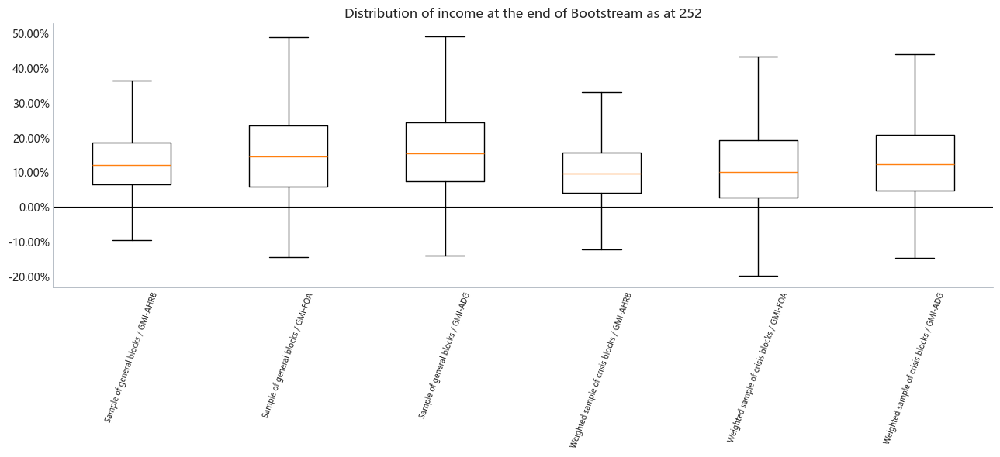

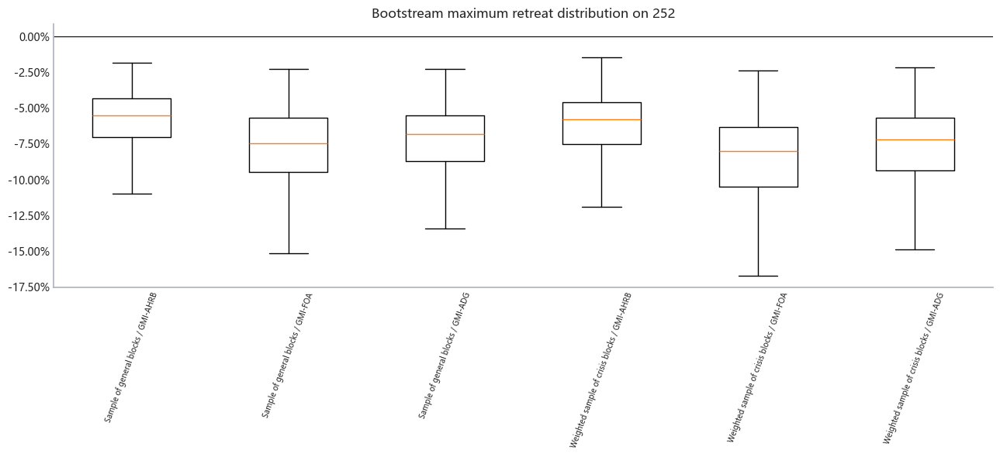

Bootstream only2015-09-07to2026-07-31Net gains during the research period;Simulation path =1000, path length =252I don't know.Length of blocks =20Day.


In [32]:
BOOTSTRAP_SEED = 202609
BOOTSTRAP_PATHS = 1000
BOOTSTRAP_HORIZON = 252
BOOTSTRAP_BLOCK = 20
CRISIS_BLOCK_MULTIPLIER = 4.0

bootstrap_returns = strategy_returns.loc[:RESEARCH_END, SIMULATED_STRESS_STRATEGIES].dropna()
if bootstrap_returns.index.max() >= HOLDOUT_START:
    raise RuntimeError('The Bootstream pressure test read the lock test set.')
if len(bootstrap_returns) < BOOTSTRAP_HORIZON + BOOTSTRAP_BLOCK:
    raise RuntimeError('The historical sample was insufficient to implement block Bootstream.')

market_proxy = returns[ALL_ASSETS].mean(axis=1).reindex(bootstrap_returns.index)
candidate_starts = np.arange(0, len(bootstrap_returns) - BOOTSTRAP_BLOCK + 1)
crisis_threshold = float(market_proxy.quantile(0.10))
crisis_blocks = np.array([
    bool((market_proxy.iloc[start:start + BOOTSTRAP_BLOCK] <= crisis_threshold).any())
    for start in candidate_starts
])
uniform_probability = np.full(len(candidate_starts), 1.0 / len(candidate_starts))
crisis_probability = np.where(crisis_blocks, CRISIS_BLOCK_MULTIPLIER, 1.0).astype(float)
crisis_probability /= crisis_probability.sum()


def block_bootstrap_paths(return_frame, start_probability, n_paths, horizon, block_length, seed):
    rng = np.random.default_rng(seed)
    values = return_frame.to_numpy(dtype=float)
    starts = np.arange(0, len(return_frame) - block_length + 1)
    simulations = np.empty((n_paths, horizon, values.shape[1]), dtype=float)
    blocks_needed = int(np.ceil(horizon / block_length))
    for path_number in range(n_paths):
        chosen = rng.choice(starts, size=blocks_needed, replace=True, p=start_probability)
        path = np.concatenate([values[s:s + block_length] for s in chosen], axis=0)[:horizon]
        simulations[path_number] = path
    return simulations


def summarize_bootstrap_paths(simulations, strategy_names, sampling_mode):
    cumulative_wealth = np.cumprod(1.0 + simulations, axis=1)
    terminal_returns = cumulative_wealth[:, -1, :] - 1.0
    running_peaks = np.maximum.accumulate(np.concatenate([
        np.ones((simulations.shape[0], 1, simulations.shape[2])), cumulative_wealth
    ], axis=1), axis=1)[:, 1:, :]
    max_drawdowns = (cumulative_wealth / running_peaks - 1.0).min(axis=1)
    records = []
    path_records = []
    for column_number, strategy_name in enumerate(strategy_names):
        terminal = terminal_returns[:, column_number]
        drawdown = max_drawdowns[:, column_number]
        records.append({
            'Sample method': sampling_mode,
            'Policy': strategy_name,
            '1 per cent end-of-cycle gains': float(np.quantile(terminal, 0.01)),
            '5% end-of-cycle earnings': float(np.quantile(terminal, 0.05)),
            'Middle income at end of period': float(np.median(terminal)),
            'Probability of loss': float((terminal < 0.0).mean()),
            'Maximum retreat median': float(np.median(drawdown)),
            'Maximum exit 5%.': float(np.quantile(drawdown, 0.05)),
            'Over 20% chance of retreat.': float((drawdown <= -0.20).mean()),
        })
        path_records.extend({
            'Sample method': sampling_mode, 'Policy': strategy_name,
            'Path Number': path_number, 'End of period rate of return': float(terminal[path_number]),
            'Maximum Drawdown': float(drawdown[path_number]),
        } for path_number in range(len(terminal)))
    return records, path_records


bootstrap_summary_records, bootstrap_path_records = [], []
for mode_number, (sampling_mode, probabilities) in enumerate([
    ('Sample of general blocks', uniform_probability),
    ('Weighted sample of crisis blocks', crisis_probability),
]):
    simulated_paths = block_bootstrap_paths(
        bootstrap_returns, probabilities, BOOTSTRAP_PATHS,
        BOOTSTRAP_HORIZON, BOOTSTRAP_BLOCK,
        BOOTSTRAP_SEED + mode_number,
    )
    summary_rows, path_rows = summarize_bootstrap_paths(
        simulated_paths, bootstrap_returns.columns.tolist(), sampling_mode
    )
    bootstrap_summary_records.extend(summary_rows)
    bootstrap_path_records.extend(path_rows)

bootstrap_stress_summary = pd.DataFrame(bootstrap_summary_records).set_index(['Sample method', 'Policy'])
bootstrap_stress_paths = pd.DataFrame(bootstrap_path_records)
display(bootstrap_stress_summary.style.format({
    '1 per cent end-of-cycle gains': '{:.2%}', '5% end-of-cycle earnings': '{:.2%}',
    'Middle income at end of period': '{:.2%}', 'Probability of loss': '{:.2%}',
    'Maximum retreat median': '{:.2%}', 'Maximum exit 5%.': '{:.2%}',
    'Over 20% chance of retreat.': '{:.2%}',
}))

for metric, title in [
    ('End of period rate of return', 'Distribution of income at the end of Bootstream as at 252'),
    ('Maximum Drawdown', 'Bootstream maximum retreat distribution on 252'),
]:
    fig, axis = plt.subplots(figsize=(13, 6))
    plot_groups, labels = [], []
    for sampling_mode in ['Sample of general blocks', 'Weighted sample of crisis blocks']:
        for strategy_name in SIMULATED_STRESS_STRATEGIES:
            values = bootstrap_stress_paths.loc[
                (bootstrap_stress_paths['Sample method'] == sampling_mode)
                & (bootstrap_stress_paths['Policy'] == strategy_name), metric
            ].to_numpy()
            plot_groups.append(values)
            labels.append(f'{sampling_mode} / {strategy_label(strategy_name)}')
    # Matpllotlib 3.9+ Renames ``labels`` as ``tick labels``.
    # Use new parameters to ensure that Notebook can be implemented from scratch in the current course environment.
    axis.boxplot(plot_groups, tick_labels=labels, showfliers=False)
    axis.axhline(0.0, color='black', linewidth=0.8)
    axis.set_title(title)
    axis.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=2))
    axis.tick_params(axis='x', rotation=70, labelsize=7)
    style_axis(axis, axis='y')
    fig.tight_layout()
    plt.show()

print(
    f'Bootstream only{bootstrap_returns.index.min().date()}to'
    f'{bootstrap_returns.index.max().date()}Net gains during the research period;'
    f'Simulation path ={BOOTSTRAP_PATHS}, path length ={BOOTSTRAP_HORIZON}I don\'t know.'
    f'Length of blocks ={BOOTSTRAP_BLOCK}Day.'
)


### 5.11 VaR and Expected Shortfall: Historical Simulation and Bootstrap Tail Risk

This section continues to use the three comparative strategies described above and reports on two types of tail risks:

1. **History Simulation 1-day VaR/ES**: direct use of daily net gains from strategy up to 2026-07-31 calculated at 95 per cent and 99 per cent confidence levels respectively;
2. **VaR/ES** for the one-year period of Bootstream: 95 per cent and 99 per cent end-of-cycle loss is calculated using 1,000 items in the previous section, 252 general blocks on trading days and crisis weighted paths.

VaR states that the threshold of loss will not normally be exceeded at the given level of confidence; ES indicates the average loss of the worst tail sample after the loss exceeds VaR. In the table, both VaR and ES are shown as losses in positive numbers, while the monetary amounts are converted as assumed ** SGD 1,000,000.

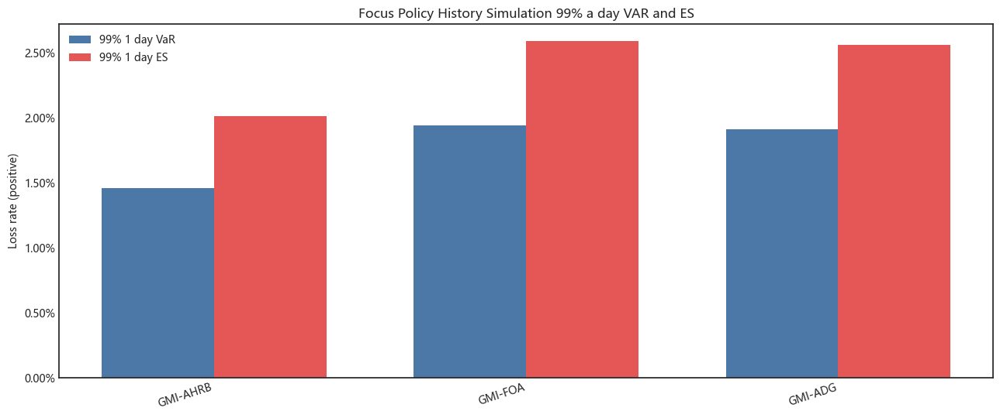

VaR/ES only as of2026-07-31Research data;Currency amount according to SGD1,000,000.00The principal amount is converted.


In [33]:
VAR_ES_CAPITAL_SGD = 1_000_000.0
VAR_ES_LEVELS = [0.95, 0.99]


def empirical_var_es(return_values, confidence_level):
    values = pd.Series(return_values, dtype=float).dropna().to_numpy()
    if len(values) < 30:
        raise RuntimeError('There are less than 30 VAR/ES effective observations.')
    losses = -values
    value_at_risk = float(np.quantile(losses, confidence_level))
    tail_losses = losses[losses >= value_at_risk]
    expected_shortfall = float(tail_losses.mean())
    return value_at_risk, expected_shortfall, len(values), len(tail_losses)


# I. Historical simulation 1 day VAR and ES
historical_var_es_records = []
for strategy_name in SIMULATED_STRESS_STRATEGIES:
    daily_net_returns = strategy_returns.loc[:RESEARCH_END, strategy_name].dropna()
    if daily_net_returns.index.max() >= HOLDOUT_START:
        raise RuntimeError('History VAR/ES reads the lock test set.')
    for confidence_level in VAR_ES_LEVELS:
        var_value, es_value, observations, tail_count = empirical_var_es(
            daily_net_returns, confidence_level
        )
        historical_var_es_records.append({
            'Policy': strategy_name,
            'Trust Horizontal': confidence_level,
            'Observation': observations,
            'End observations': tail_count,
            '1 VaR': var_value,
            '1 January ES': es_value,
            'VAR Amount (ZXQ0QZ)': var_value * VAR_ES_CAPITAL_SGD,
            'ES Amount (SGD)': es_value * VAR_ES_CAPITAL_SGD,
        })

historical_var_es = pd.DataFrame(historical_var_es_records).set_index(['Policy', 'Trust Horizontal'])
display(historical_var_es.style.format({
    '1 VaR': '{:.2%}', '1 January ES': '{:.2%}',
    'VAR Amount (ZXQ0QZ)': 'SGD {:,.2f}', 'ES Amount (SGD)': 'SGD {:,.2f}',
}))


# VAR and ES of the cumulative distribution of proceeds as at 252
bootstrap_var_es_records = []
for sampling_mode in ['Sample of general blocks', 'Weighted sample of crisis blocks']:
    for strategy_name in SIMULATED_STRESS_STRATEGIES:
        terminal_returns = bootstrap_stress_paths.loc[
            (bootstrap_stress_paths['Sample method'] == sampling_mode)
            & (bootstrap_stress_paths['Policy'] == strategy_name),
            'End of period rate of return',
        ]
        for confidence_level in VAR_ES_LEVELS:
            var_value, es_value, observations, tail_count = empirical_var_es(
                terminal_returns, confidence_level
            )
            bootstrap_var_es_records.append({
                'Sample method': sampling_mode,
                'Policy': strategy_name,
                'Trust Horizontal': confidence_level,
                'Simulation of paths': observations,
                'Number of tail paths': tail_count,
                '252 VaR': var_value,
                '252 ES': es_value,
                'VAR Amount (ZXQ0QZ)': var_value * VAR_ES_CAPITAL_SGD,
                'ES Amount (SGD)': es_value * VAR_ES_CAPITAL_SGD,
            })

bootstrap_var_es = pd.DataFrame(bootstrap_var_es_records).set_index(
    ['Sample method', 'Policy', 'Trust Horizontal']
)
display(bootstrap_var_es.style.format({
    '252 VaR': '{:.2%}', '252 ES': '{:.2%}',
    'VAR Amount (ZXQ0QZ)': 'SGD {:,.2f}', 'ES Amount (SGD)': 'SGD {:,.2f}',
}))


# 3. End risk comparison: The lower the value, the smaller the tail loss.
plot_table = historical_var_es.reset_index()
plot_table = plot_table[plot_table['Trust Horizontal'] == 0.99].set_index('Policy')
fig, ax = plt.subplots(figsize=(13, 5.5))
x = np.arange(len(plot_table))
width = 0.36
ax.bar(x - width / 2, plot_table['1 VaR'], width, label='99% 1 day VaR', color='#4C78A8')
ax.bar(x + width / 2, plot_table['1 January ES'], width, label='99% 1 day ES', color='#E45756')
ax.set_xticks(x)
ax.set_xticklabels([strategy_label(name) for name in plot_table.index], rotation=18, ha='right')
ax.set_title('Focus Policy History Simulation 99% a day VAR and ES')
ax.set_ylabel('Loss rate (positive)')
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=2))
ax.legend()
plt.tight_layout()
plt.show()

print(
    f'VaR/ES only as of{RESEARCH_END.date()}Research data;'
    f'Currency amount according to SGD{VAR_ES_CAPITAL_SGD:,.2f}The principal amount is converted.'
)


# Part VI. Performance Summary and Market Comparisons

6.1 P&L in monetary amounts and additional display of transactions


This section does not create new strategies or recalculate another set of benefits. It converts the same line of net proceeds used for this part of the harmonized indicator into net end-of-period, cumulative and daily gains and losses on the assumption of initial funding** SGD 1,000,000** and separates the number of “ports of asset transactions” from the “number of portfolio transfers”.

The harmonized indicator table is the official calibre; this section is a supplementary view of monetary amounts and transactions. Previously, only a graphic hard-code display of an EWMA policy had been replaced by a simultaneous display of all 12 retention strategies.

Study the complete range:2015-09-07to2026-07-31


,Initial funding (SGD),End of period net value (SGD),Cumulative gains and losses (SGD),Average daily surplus/loss (SGD),Maximum single-day gain/loss (SGD),Positive-Day Ratio,Number of Rebalances,Number of Trade Legs
Policy,,,,,,,,
Global Momentum Inverse Volatility (GMI-IV),"S$1,000,000.00","S$2,750,699.05","S$1,750,699.05",S$617.10,"S$-78,369.09",54.99%,136,1529
Global Momentum Classic Risk Parity (GMI-CRP),"S$1,000,000.00","S$2,784,216.88","S$1,784,216.88",S$628.91,"S$-73,270.45",55.41%,128,1449
Global Momentum EWMA Risk Parity (GMI-ERP),"S$1,000,000.00","S$3,087,267.43","S$2,087,267.43",S$735.73,"S$-81,891.26",55.62%,177,1939
Global Momentum Downside Risk Parity (GMI-DRP),"S$1,000,000.00","S$2,749,488.01","S$1,749,488.01",S$616.67,"S$-74,498.09",54.60%,126,1429
Global Multi-Asset Equal Weight (GMA-EW),"S$1,000,000.00","S$3,111,510.02","S$2,111,510.02",S$744.28,"S$-87,416.30",55.62%,17,306
Global Momentum Dynamic Risk Budget (GMI-DRB),"S$1,000,000.00","S$3,239,451.52","S$2,239,451.52",S$789.37,"S$-91,797.40",55.06%,183,1999
Global Momentum Static Hierarchical Risk Budget (GMI-SHRB),"S$1,000,000.00","S$3,073,576.33","S$2,073,576.33",S$730.90,"S$-72,692.49",55.13%,181,1979
Global Momentum GARCH Risk Parity (GMI-GRP),"S$1,000,000.00","S$2,829,114.25","S$1,829,114.25",S$644.74,"S$-83,008.31",55.41%,162,1789
Global Momentum Adaptive Hierarchical Risk Budget (GMI-AHRB),"S$1,000,000.00","S$3,709,942.67","S$2,709,942.67",S$955.21,"S$-89,412.31",55.13%,184,2009


Lock test range:2026-08-01to2026-10-01


,Initial funding (SGD),End of period net value (SGD),Cumulative gains and losses (SGD),Average daily surplus/loss (SGD),Maximum single-day gain/loss (SGD),Positive-Day Ratio,Number of Rebalances,Number of Trade Legs
Policy,,,,,,,,
Global Momentum Inverse Volatility (GMI-IV),"S$1,000,000.00","S$1,007,059.84","S$7,059.84",S$160.45,"S$-10,316.47",54.55%,0,0
Global Momentum Classic Risk Parity (GMI-CRP),"S$1,000,000.00","S$1,012,556.39","S$12,556.39",S$285.37,"S$-9,385.33",56.82%,1,10
Global Momentum EWMA Risk Parity (GMI-ERP),"S$1,000,000.00","S$1,001,832.32","S$1,832.32",S$41.64,"S$-8,321.21",50.00%,1,10
Global Momentum Downside Risk Parity (GMI-DRP),"S$1,000,000.00","S$1,010,376.91","S$10,376.91",S$235.84,"S$-9,626.43",52.27%,0,0
Global Multi-Asset Equal Weight (GMA-EW),"S$1,000,000.00","S$1,021,445.11","S$21,445.11",S$487.39,"S$-6,769.86",54.55%,0,0
Global Momentum Dynamic Risk Budget (GMI-DRB),"S$1,000,000.00","S$1,003,387.53","S$3,387.53",S$76.99,"S$-8,198.90",52.27%,2,20
Global Momentum Static Hierarchical Risk Budget (GMI-SHRB),"S$1,000,000.00","S$1,003,304.65","S$3,304.65",S$75.11,"S$-8,218.05",54.55%,2,20
Global Momentum GARCH Risk Parity (GMI-GRP),"S$1,000,000.00","S$1,007,798.38","S$7,798.38",S$177.24,"S$-9,721.57",50.00%,1,10
Global Momentum Adaptive Hierarchical Risk Budget (GMI-AHRB),"S$1,000,000.00","S$1,006,624.69","S$6,624.69",S$150.56,"S$-8,840.89",52.27%,2,20


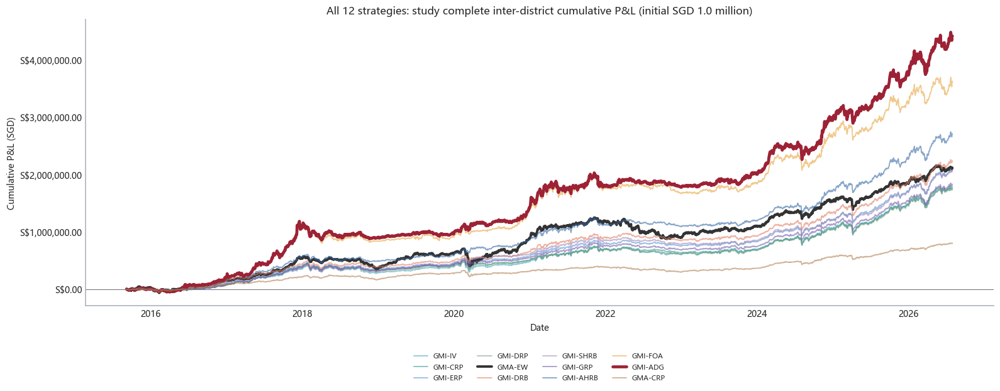

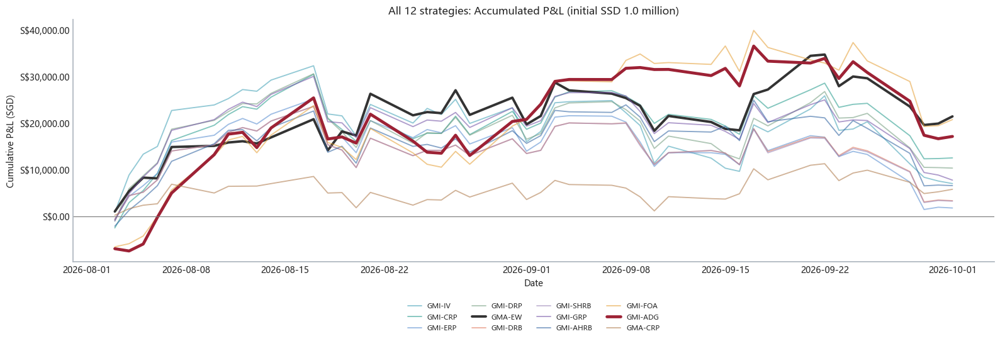

Note: This section uses the same net income as the harmonized indicator table; the amount of P&L is only expressed as the SDD of the rate of return.
Note: The proportion of positive returns on a daily basis is not a trade-off; the number of legs of an asset transaction is not a number of times a combination of a warehouse.


In [34]:
def build_pnl_activity_summary(result_map, start, end):
    records = []
    pnl_paths = {}
    for strategy_name, result in result_map.items():
        r = result['returns'].loc[start:end].dropna()
        if r.empty:
            continue
        nav = INITIAL_CAPITAL_SGD * (1.0 + r).cumprod()
        daily_pnl = nav.diff()
        daily_pnl.iloc[0] = nav.iloc[0] - INITIAL_CAPITAL_SGD
        turnover = result['turnover'].loc[start:end]
        trade_legs = result.get('trade_legs', pd.Series(dtype=float)).loc[start:end]
        records.append({
            'Policy': strategy_name,
            'Initial funding (SGD)': INITIAL_CAPITAL_SGD,
            'End of period net value (SGD)': float(nav.iloc[-1]),
            'Cumulative gains and losses (SGD)': float(nav.iloc[-1] - INITIAL_CAPITAL_SGD),
            'Average daily surplus/loss (SGD)': float(daily_pnl.mean()),
            'Maximum single-day gain/loss (SGD)': float(daily_pnl.min()),
            'Positive-Day Ratio': float((r > 0.0).mean()),
            'Number of Rebalances': int(len(turnover)),
            'Number of Trade Legs': int(trade_legs.sum()),
        })
        pnl_paths[strategy_name] = nav - INITIAL_CAPITAL_SGD
    return pd.DataFrame(records).set_index('Policy'), pd.DataFrame(pnl_paths)


research_pnl_summary, research_pnl_paths = build_pnl_activity_summary(
    results, strategy_start, RESEARCH_END
)
holdout_pnl_summary, holdout_pnl_paths = build_pnl_activity_summary(
    holdout_results, HOLDOUT_START, actual_holdout_end
)


def format_pnl_activity_table(table):
    shown = table.copy()
    for column in ['Initial funding (SGD)', 'End of period net value (SGD)', 'Cumulative gains and losses (SGD)',
                   'Average daily surplus/loss (SGD)', 'Maximum single-day gain/loss (SGD)']:
        shown[column] = shown[column].map(lambda x: f'S${x:,.2f}')
    shown['Positive-Day Ratio'] = shown['Positive-Day Ratio'].map(lambda x: f'{x:.2%}')
    return shown


print(f'Study the complete range:{strategy_start.date()}to{RESEARCH_END.date()}')
display(format_pnl_activity_table(research_pnl_summary))
print(f'Lock test range:{HOLDOUT_START.date()}to{actual_holdout_end.date()}')
display(format_pnl_activity_table(holdout_pnl_summary))

fig, ax = plt.subplots(figsize=(16, 8))
for strategy_name in final_strategy_names if 'final_strategy_names' in globals() else list(results):
    research_style = HIGHLIGHT_COLORS.get(strategy_name, MUTED_COLOR)
    linewidth = 3.4 if strategy_name == SUBMISSION_STRATEGY else (2.8 if strategy_name == BASELINE_STRATEGY else 1.35)
    alpha = 1.0 if strategy_name in {BASELINE_STRATEGY, SUBMISSION_STRATEGY} else 0.58
    ax.plot(research_pnl_paths.index, research_pnl_paths[strategy_name], linestyle='-',
            color=research_style, linewidth=linewidth, alpha=alpha,
            label=strategy_label(strategy_name))
ax.axhline(0.0, color='#777777', linewidth=0.8)
ax.set_title('All 12 strategies: study complete inter-district cumulative P&L (initial SGD 1.0 million)')
ax.set_xlabel('Date')
ax.set_ylabel('Cumulative P&L (SGD)')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f'S${value:,.2f}'))
style_axis(ax)
place_legend(ax)
fig.tight_layout(rect=[0, 0.18, 1, 1])
plt.show()

fig, ax = plt.subplots(figsize=(16, 7))
for strategy_name in holdout_pnl_paths.columns:
    color = HIGHLIGHT_COLORS.get(strategy_name, MUTED_COLOR)
    linewidth = 3.4 if strategy_name == SUBMISSION_STRATEGY else (2.8 if strategy_name == BASELINE_STRATEGY else 1.35)
    alpha = 1.0 if strategy_name in {BASELINE_STRATEGY, SUBMISSION_STRATEGY} else 0.58
    ax.plot(holdout_pnl_paths.index, holdout_pnl_paths[strategy_name], linestyle='-',
            color=color, linewidth=linewidth, alpha=alpha, label=strategy_label(strategy_name))
ax.axhline(0.0, color='#777777', linewidth=0.8)
ax.set_title('All 12 strategies: Accumulated P&L (initial SSD 1.0 million)')
ax.set_xlabel('Date')
ax.set_ylabel('Cumulative P&L (SGD)')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f'S${value:,.2f}'))
style_axis(ax)
place_legend(ax)
fig.tight_layout(rect=[0, 0.18, 1, 1])
plt.show()

print('Note: This section uses the same net income as the harmonized indicator table; the amount of P&L is only expressed as the SDD of the rate of return.')
print('Note: The proportion of positive returns on a daily basis is not a trade-off; the number of legs of an asset transaction is not a number of times a combination of a warehouse.')


### 6.2 Course-Required Trading and Drawdown Metrics


The four transactional indicators listed in this section and previously not strictly covered, as well as the frequency of evacuations, do not change any strategy, weight, signal or return returns.

### 6.2.1 Indicator calibration

-** Definition of transaction**: each increase forms an independent hold-up batch; first-in-first-out (FIFO) matches the first batch. A single sale that matches more than one purchase order will result in more than one completed transaction.
- **The trade-off**: net profit is greater than 0 per cent of the completed FIFO transaction batch, after deducting the cost of buying and selling the unilateral transaction.
- **The total number of transactions**: the number of FIFO transactions that have been completed at the level of the return zone; the unsold batch is shown separately as “the number of unsettled shipments at the end of the period”, the non-transaction rate and the single profit.
- ** Average holding period**: average number of trading days from purchase to date of sale of completed batches.
- ** Average profit for individual transactions**: average net profit for completed transactions, expressed in SSD amounts and relative capital investment return.
- ** Recovery event**: Net value starts when it first breaks its historical peak and ends when it returns to or exceeds its previous peak; withdrawals that remain unrecovered at the end of the evaluation are counted separately as unrecovered events.

The turnover here is different from the “proportion of positive returns on a daily basis”; the total number of transactions is different from the number of combinations and legs of asset transactions. Qualitative indicators apply to comparison of transactions, but there may be more uncompleted lead times for long-term, continuous-held asset allocation strategies, which must be explained at the same time as unsettled amounts at the end of the period.

>FIFO statistics only describe the number of asset batches achieved in the rebalancing process, do not represent Alpha for independent trading signals and should not be used as the main basis for recommended strategies.

In [35]:
def drawdown_event_statistics(return_series):
    """Statistics of independent evacuations; one event begins with a break in historical peaks and ends with a return to peaks."""
    r = pd.Series(return_series, dtype=float).dropna()
    if r.empty:
        return {
            'Number of evacuations': 0, 'Number of retreats repaired': 0, 'Unrecovered evacuations at the end of the period': 0,
            'Average retreat range': np.nan, 'Average withdrawal duration (trade date)': np.nan,
            'Maximum withdrawal duration (trade date)': np.nan,
        }

    wealth = (1.0 + r).cumprod()
    running_peak = wealth.cummax().clip(lower=1.0)
    drawdown = wealth / running_peak - 1.0
    underwater = drawdown < -1e-12
    events = []
    start_position = None

    for position, date in enumerate(drawdown.index):
        if bool(underwater.iloc[position]) and start_position is None:
            start_position = position
        recovery = (
            start_position is not None
            and not bool(underwater.iloc[position])
            and position > start_position
        )
        if recovery:
            episode = drawdown.iloc[start_position:position]
            events.append({
                'Start date': drawdown.index[start_position], 'End Date': date,
                'Maximum Drawdown': float(episode.min()),
                'Duration (trade date)': int(position - start_position + 1),
                'Rehabilitation': True,
            })
            start_position = None

    if start_position is not None:
        episode = drawdown.iloc[start_position:]
        events.append({
            'Start date': drawdown.index[start_position], 'End Date': drawdown.index[-1],
            'Maximum Drawdown': float(episode.min()),
            'Duration (trade date)': int(len(drawdown) - start_position),
            'Rehabilitation': False,
        })

    event_table = pd.DataFrame(events)
    if event_table.empty:
        return {
            'Number of evacuations': 0, 'Number of retreats repaired': 0, 'Unrecovered evacuations at the end of the period': 0,
            'Average retreat range': 0.0, 'Average withdrawal duration (trade date)': 0.0,
            'Maximum withdrawal duration (trade date)': 0,
        }
    return {
        'Number of evacuations': int(len(event_table)),
        'Number of retreats repaired': int(event_table['Rehabilitation'].sum()),
        'Unrecovered evacuations at the end of the period': int((~event_table['Rehabilitation']).sum()),
        'Average retreat range': float(event_table['Maximum Drawdown'].mean()),
        'Average withdrawal duration (trade date)': float(event_table['Duration (trade date)'].mean()),
        'Maximum withdrawal duration (trade date)': int(event_table['Duration (trade date)'].max()),
    }


def build_fifo_trade_ledger(result, metric_start, metric_end, initial_capital=INITIAL_CAPITAL_SGD):
    """Reconstruct FIFO units from post-fee closing NAV and actual weights.

    Allocate the engine's recorded costs, not a second estimate of costs.
    Small sales financing fees are retained for reconciliation but flagged so
    they do not inflate ordinary completed-trade statistics.
    """
    dates = result['returns'].dropna().loc[metric_start:metric_end].index
    lots = {ticker: [] for ticker in result.get('trade_assets', PORTFOLIO_ASSETS)}
    assets = list(lots)
    prices = result.get('instrument_prices', portfolio_prices_sgd).reindex(columns=assets)
    opening = prices.shift(1)
    before = result['pre_return_weights'].reindex(index=dates, columns=assets).fillna(0.0)
    closing = result['end_of_day_weights'].reindex(index=dates, columns=assets).fillna(0.0)
    deltas = result['trade_deltas'].reindex(index=dates, columns=assets).fillna(0.0)
    rates = pd.Series(result.get('asset_cost_rate', COST), index=assets, dtype=float)
    effective = result.get('effective_asset_cost_rate')
    fees = result.get('transaction_cost')
    nav, rows, lot_number, max_error = float(initial_capital), [], 0, 0.0
    positions = {date: i for i, date in enumerate(dates)}
    if len(dates):
        first = dates[0]
        for ticker in assets:
            weight = float(before.loc[first, ticker])
            if weight < -1e-10:
                raise ValueError('FIFO ledger supports long-only holdings.')
            if weight > 1e-10:
                price = float(opening.loc[first, ticker])
                if not np.isfinite(price) or price <= 0:
                    raise ValueError(f'Missing opening price for held asset {ticker}.')
                lot_number += 1
                lots[ticker].append({'Batch Number': lot_number, 'Date of purchase': first,
                    'Purchase price': price, 'Remaining share': weight * nav / price,
                    'Unit buy-in cost': 0.0, 'Inheritance at the beginning of the period': True})
    for date in dates:
        day_rates = effective.loc[date].reindex(assets).fillna(0.0) if effective is not None and date in effective.index else rates
        cost_weights = deltas.loc[date].abs() * day_rates
        fee_fraction = float(fees.get(date, 0.0)) if fees is not None else float(cost_weights.sum())
        if not 0 <= fee_fraction < 1:
            raise ValueError('Invalid recorded transaction-cost fraction.')
        nav_after = nav * (1.0 + float(result['returns'].loc[date]))
        nav_before = nav_after / (1.0 - fee_fraction)
        total_fee = nav_before - nav_after
        if total_fee > 1e-8 and cost_weights.sum() <= 0:
            raise ValueError('Recorded costs cannot be allocated to executed trades.')
        allocated = cost_weights * (total_fee / cost_weights.sum()) if cost_weights.sum() > 0 else cost_weights * 0
        for ticker in assets:
            available = sum(lot['Remaining share'] for lot in lots[ticker])
            target_value = float(closing.loc[date, ticker]) * nav_after
            if target_value < -1e-8:
                raise ValueError('FIFO ledger supports long-only holdings.')
            if available <= 1e-12 and abs(target_value) <= 1e-8 and allocated[ticker] <= 1e-8:
                continue
            price = float(prices.loc[date, ticker])
            if not np.isfinite(price) or price <= 0:
                raise ValueError(f'Missing execution price for held asset {ticker} on {date}.')
            target = max(0.0, target_value / price)
            change = target - available
            fee = float(allocated[ticker])
            tolerance = max(1e-12, abs(nav_after) * 1e-12 / price)
            if change < -tolerance:
                selling = -change
                exit_cost_per_unit = fee / selling
                fee_funding_only = float(deltas.loc[date, ticker]) >= -1e-10
                while selling > tolerance and lots[ticker]:
                    lot = lots[ticker][0]
                    matched = min(selling, lot['Remaining share'])
                    invested = matched * (lot['Purchase price'] + lot['Unit buy-in cost'])
                    profit = matched * (price - exit_cost_per_unit) - invested
                    rows.append({'Policy': result['name'], 'Assets': ticker,
                        'Date of purchase': lot['Date of purchase'], 'Date of sale': date,
                        'Warehousing period (trade date)': positions[date] - positions[lot['Date of purchase']],
                        'Purchase price (SGD)': lot['Purchase price'], 'Sale price (SGD)': price,
                        'Match share': matched, 'Input amount (SGD)': invested,
                        'Net profit (SGD)': profit, 'Single net gain': profit / invested if invested > 0 else np.nan,
                        'Inheritance at the beginning of the period': bool(lot['Inheritance at the beginning of the period']),
                        'Fee funding only': fee_funding_only})
                    lot['Remaining share'] -= matched
                    selling -= matched
                    if lot['Remaining share'] <= tolerance:
                        lots[ticker].pop(0)
            elif change > tolerance:
                lot_number += 1
                lots[ticker].append({'Batch Number': lot_number, 'Date of purchase': date,
                    'Purchase price': price, 'Remaining share': change,
                    'Unit buy-in cost': fee / change,
                    'Inheritance at the beginning of the period': False})
            elif fee > 1e-8:
                # A tiny intended buy can exactly offset its fee-financing sale.
                if available <= 0:
                    raise ValueError('Cannot attach trading costs to an empty position.')
                for lot in lots[ticker]:
                    lot['Unit buy-in cost'] += fee / available
            error = abs(sum(lot['Remaining share'] for lot in lots[ticker]) * price - target_value)
            max_error = max(max_error, error)
            if error > max(1e-7, abs(nav_after) * 1e-9):
                raise RuntimeError(f'FIFO holdings do not reconcile for {ticker} on {date}.')
        nav = nav_after
    open_lots = [lot for group in lots.values() for lot in group if lot['Remaining share'] > 1e-12]
    diagnostics = {'Number of unprocessed authorizations at end of period': len(open_lots),
        'Unsettled assets at end of period': sum(bool(group) for group in lots.values()),
        'Maximum FIFO holding reconciliation error (SGD)': max_error}
    return pd.DataFrame(rows), diagnostics


def completed_trade_statistics(ledger, diagnostics):
    if not ledger.empty and 'Fee funding only' in ledger:
        ledger = ledger.loc[~ledger['Fee funding only']]
    if ledger.empty:
        return {
            'The odds.': np.nan, 'Total number of transactions completed': 0,
            'Average holding period (trade date)': np.nan,
            'Average profit for single transactions (SGD)': np.nan,
            'Average rate of return on individual transactions': np.nan,
            **diagnostics,
        }
    return {
        'The odds.': float((ledger['Net profit (SGD)'] > 0.0).mean()),
        'Total number of transactions completed': int(len(ledger)),
        'Average holding period (trade date)': float(ledger['Warehousing period (trade date)'].mean()),
        'Average profit for single transactions (SGD)': float(ledger['Net profit (SGD)'].mean()),
        'Average rate of return on individual transactions': float(ledger['Single net gain'].mean()),
        **diagnostics,
    }


def build_course_required_metrics(result_map, start, end):
    records, ledgers = [], {}
    for strategy_name, result in result_map.items():
        base = compute_metrics(result, start, end)
        ledger, diagnostics = build_fifo_trade_ledger(result, start, end)
        ledgers[strategy_name] = ledger
        trade_stats = completed_trade_statistics(ledger, diagnostics)
        drawdown_stats = drawdown_event_statistics(result['returns'].loc[start:end])
        records.append({
            'Policy': strategy_name,
            'Cumulative gains and losses (SGD)': base['Cumulative gains and losses (SGD)'],
            'Annualized Return': base['Annualized Return'],
            'Sharpe Ratio': base['Sharpe Ratio'],
            'Maximum Drawdown': base['Maximum Drawdown'],
            'The odds.': trade_stats['The odds.'],
            'Annualized Volatility': base['Annualized Volatility'],
            'Number of evacuations': drawdown_stats['Number of evacuations'],
            'Number of retreats repaired': drawdown_stats['Number of retreats repaired'],
            'Unrecovered evacuations at the end of the period': drawdown_stats['Unrecovered evacuations at the end of the period'],
            'Average withdrawal duration (trade date)': drawdown_stats['Average withdrawal duration (trade date)'],
            'Maximum withdrawal duration (trade date)': drawdown_stats['Maximum withdrawal duration (trade date)'],
            'Total number of transactions completed': trade_stats['Total number of transactions completed'],
            'Average holding period (trade date)': trade_stats['Average holding period (trade date)'],
            'Average profit for single transactions (SGD)': trade_stats['Average profit for single transactions (SGD)'],
            'Average rate of return on individual transactions': trade_stats['Average rate of return on individual transactions'],
            'Number of unprocessed authorizations at end of period': trade_stats['Number of unprocessed authorizations at end of period'],
            'Unsettled assets at end of period': trade_stats['Unsettled assets at end of period'],
            'Number of Rebalances': base['Number of Rebalances'],
            'Number of Trade Legs': base['Number of Trade Legs'],
        })
    return pd.DataFrame(records).set_index('Policy'), ledgers


def format_course_required_metrics(table):
    shown = table.copy()
    for column in ['Annualized Return', 'Maximum Drawdown', 'The odds.', 'Annualized Volatility', 'Average rate of return on individual transactions']:
        shown[column] = shown[column].map(lambda value: '' if pd.isna(value) else f'{value:.2%}')
    shown['Sharpe Ratio'] = shown['Sharpe Ratio'].map(lambda value: f'{value:.2f}')
    for column in ['Cumulative gains and losses (SGD)', 'Average profit for single transactions (SGD)']:
        shown[column] = shown[column].map(lambda value: '' if pd.isna(value) else f'S${value:,.2f}')
    for column in ['Average withdrawal duration (trade date)', 'Maximum withdrawal duration (trade date)',
                   'Average holding period (trade date)']:
        shown[column] = shown[column].map(lambda value: '' if pd.isna(value) else f'{value:.2f}')
    integer_columns = [
        'Number of evacuations', 'Number of retreats repaired', 'Unrecovered evacuations at the end of the period',
        'Total number of transactions completed', 'Number of unprocessed authorizations at end of period', 'Unsettled assets at end of period',
        'Number of Rebalances', 'Number of Trade Legs',
    ]
    for column in integer_columns:
        shown[column] = shown[column].astype(int)
    return shown


research_course_metrics, research_trade_ledgers = build_course_required_metrics(
    results, strategy_start, RESEARCH_END
)
holdout_course_metrics, holdout_trade_ledgers = build_course_required_metrics(
    holdout_results, HOLDOUT_START, actual_holdout_end
)

print(f'Study full inter-territory content indicators:{strategy_start.date()}to{RESEARCH_END.date()}')
display(format_course_required_metrics(research_course_metrics))
print(f'Lock test inter-temporal content indicators:{HOLDOUT_START.date()}to{actual_holdout_end.date()}')
display(format_course_required_metrics(holdout_course_metrics))

# The details of the main policy are kept as auditable DataFrame and are not written in local files.
baseline_name = SUBMISSION_STRATEGY
baseline_research_trade_ledger = research_trade_ledgers[baseline_name]
baseline_holdout_trade_ledger = holdout_trade_ledgers[baseline_name]
print('Submitting a list of transactions completed by FIFO between candidate strategy studies (first 20 lines):')
display(baseline_research_trade_ledger.head(20).style.format({
    'Purchase price (SGD)': '{:,.2f}', 'Sale price (SGD)': '{:,.2f}',
    'Match share': '{:,.2f}', 'Input amount (SGD)': 'S${:,.2f}',
    'Net profit (SGD)': 'S${:,.2f}', 'Single net gain': '{:.2%}',
}))

if research_course_metrics['Total number of transactions completed'].sum() <= 0:
    raise RuntimeError('The transaction book does not identify any completed transactions. Please check FIFO reconstruction logic.')
if research_course_metrics['Number of evacuations'].sum() <= 0:
    raise RuntimeError('No evacuations have been identified. Please check the evacuation logic.')
print('The indicators for missing items have been added: the success of transactions, the total number of transactions, the average holding period, the average profit of individual transactions and the frequency of evacuations.')


Study full inter-territory content indicators:2015-09-07to2026-07-31


,Cumulative gains and losses (SGD),Annualized Return,Sharpe Ratio,Maximum Drawdown,The odds.,Annualized Volatility,Number of evacuations,Number of retreats repaired,Unrecovered evacuations at the end of the period,Average withdrawal duration (trade date),Maximum withdrawal duration (trade date),Total number of transactions completed,Average holding period (trade date),Average profit for single transactions (SGD),Average rate of return on individual transactions,Number of unprocessed authorizations at end of period,Unsettled assets at end of period,Number of Rebalances,Number of Trade Legs
Policy,,,,,,,,,,,,,,,,,,,
Global Momentum Inverse Volatility (GMI-IV),"S$1,750,699.05",9.40%,1.00,-12.13%,69.90%,8.01%,146,145,1,18.18,585.00,1309,161.07,"S$1,060.99",18.03%,49,10,136,1529
Global Momentum Classic Risk Parity (GMI-CRP),"S$1,784,216.88",9.52%,1.05,-10.35%,68.29%,7.66%,141,140,1,18.90,596.00,1249,156.69,"S$1,031.91",16.17%,31,10,128,1449
Global Momentum EWMA Risk Parity (GMI-ERP),"S$2,087,267.43",10.53%,1.23,-9.01%,67.87%,7.30%,169,168,1,15.59,507.00,1721,101.66,"S$1,068.54",8.72%,49,10,177,1939
Global Momentum Downside Risk Parity (GMI-DRP),"S$1,749,488.01",9.40%,1.01,-10.52%,68.76%,7.89%,145,144,1,18.44,589.00,1229,171.52,"S$1,030.96",18.62%,31,10,126,1429
Global Multi-Asset Equal Weight (GMA-EW),"S$2,111,510.02",10.61%,0.99,-17.87%,83.48%,9.26%,137,136,1,19.32,603.00,115,1273.30,"S$8,584.46",189.25%,191,18,17,306
Global Momentum Dynamic Risk Budget (GMI-DRB),"S$2,239,451.52",11.01%,1.25,-9.48%,64.29%,7.52%,166,165,1,15.89,500.00,1792,93.46,"S$1,121.30",7.46%,38,10,183,1999
Global Momentum Static Hierarchical Risk Budget (GMI-SHRB),"S$2,073,576.33",10.49%,1.22,-8.77%,64.55%,7.32%,184,183,1,14.38,585.00,1766,85.57,"S$1,054.96",9.01%,43,10,181,1979
Global Momentum GARCH Risk Parity (GMI-GRP),"S$1,829,114.25",9.68%,1.10,-9.66%,66.24%,7.43%,156,155,1,17.00,591.00,1573,118.50,"S$1,032.06",10.80%,46,10,162,1789
Global Momentum Adaptive Hierarchical Risk Budget (GMI-AHRB),"S$2,709,942.67",12.35%,1.26,-9.75%,62.36%,8.49%,167,166,1,16.04,585.00,1804,80.45,"S$1,388.19",6.38%,36,10,184,2009


Lock test inter-temporal content indicators:2026-08-01to2026-10-01


,Cumulative gains and losses (SGD),Annualized Return,Sharpe Ratio,Maximum Drawdown,The odds.,Annualized Volatility,Number of evacuations,Number of retreats repaired,Unrecovered evacuations at the end of the period,Average withdrawal duration (trade date),Maximum withdrawal duration (trade date),Total number of transactions completed,Average holding period (trade date),Average profit for single transactions (SGD),Average rate of return on individual transactions,Number of unprocessed authorizations at end of period,Unsettled assets at end of period,Number of Rebalances,Number of Trade Legs
Policy,,,,,,,,,,,,,,,,,,,
Global Momentum Inverse Volatility (GMI-IV),"S$7,059.84",4.11%,0.43,-2.44%,,7.11%,2,1,1,17.50,33.00,0,,,,10,10,0,0
Global Momentum Classic Risk Parity (GMI-CRP),"S$12,556.39",7.41%,1.02,-1.76%,80.00%,5.99%,3,2,1,12.33,33.00,5,29.00,S$504.89,5.49%,15,10,1,10
Global Momentum EWMA Risk Parity (GMI-ERP),"S$1,832.32",1.05%,0.00,-2.31%,40.00%,5.74%,3,2,1,12.33,33.00,5,29.00,S$116.05,0.78%,15,10,1,10
Global Momentum Downside Risk Parity (GMI-DRP),"S$10,376.91",6.09%,0.78,-1.96%,,6.28%,3,2,1,12.33,33.00,0,,,,10,10,0,0
Global Multi-Asset Equal Weight (GMA-EW),"S$21,445.11",12.92%,1.82,-1.46%,,6.11%,7,6,1,5.14,12.00,0,,,,18,18,0,0
Global Momentum Dynamic Risk Budget (GMI-DRB),"S$3,387.53",1.96%,0.16,-2.00%,66.67%,5.43%,3,2,1,12.33,33.00,6,19.00,S$3.05,2.44%,24,10,2,20
Global Momentum Static Hierarchical Risk Budget (GMI-SHRB),"S$3,304.65",1.91%,0.15,-2.01%,71.43%,5.43%,3,2,1,12.33,33.00,7,18.29,S$19.37,2.18%,23,10,2,20
Global Momentum GARCH Risk Parity (GMI-GRP),"S$7,798.38",4.55%,0.59,-2.16%,100.00%,5.83%,3,2,1,12.33,33.00,7,14.00,S$711.45,3.33%,13,10,1,10
Global Momentum Adaptive Hierarchical Risk Budget (GMI-AHRB),"S$6,624.69",3.85%,0.47,-1.79%,75.00%,5.83%,6,5,1,6.17,13.00,8,19.62,S$199.71,2.05%,22,10,2,20


Submitting a list of transactions completed by FIFO between candidate strategy studies (first 20 lines):


,Policy,Assets,Date of purchase,Date of sale,Warehousing period (trade date),Purchase price (SGD),Sale price (SGD),Match share,Input amount (SGD),Net profit (SGD),Single net gain,Inheritance at the beginning of the period,Fee funding only
0,Global Momentum Adaptive Defense and Growth (GMI-ADG),SPY,2015-09-08 00:00:00,2015-09-29 00:00:00,15,234.27,225.03,0.36,S$83.24,S$-3.36,-4.04%,False,False
1,Global Momentum Adaptive Defense and Growth (GMI-ADG),QQQ,2015-09-08 00:00:00,2015-09-29 00:00:00,15,138.16,131.53,0.58,S$80.85,S$-3.96,-4.89%,False,False
2,Global Momentum Adaptive Defense and Growth (GMI-ADG),IWM,2015-09-08 00:00:00,2015-09-29 00:00:00,15,142.69,133.66,0.05,S$7.69,S$-0.49,-6.41%,False,False
3,Global Momentum Adaptive Defense and Growth (GMI-ADG),EXS1.DE,2015-09-08 00:00:00,2015-09-29 00:00:00,15,144.53,134.19,0.79,S$114.38,S$-8.29,-7.25%,False,False
4,Global Momentum Adaptive Defense and Growth (GMI-ADG),IEF,2015-09-08 00:00:00,2015-09-29 00:00:00,15,117.67,119.50,31.14,"S$3,665.66",S$53.37,1.46%,False,False
5,Global Momentum Adaptive Defense and Growth (GMI-ADG),511010.SS,2015-09-08 00:00:00,2015-09-29 00:00:00,15,23.47,23.48,"2,544.96","S$59,753.46",S$-32.00,-0.05%,False,False
6,Global Momentum Adaptive Defense and Growth (GMI-ADG),510300.SS,2015-09-08 00:00:00,2015-10-20 00:00:00,30,0.63,0.66,85.30,S$53.50,S$2.56,4.79%,False,False
7,Global Momentum Adaptive Defense and Growth (GMI-ADG),UUP,2015-09-08 00:00:00,2015-10-20 00:00:00,30,29.85,28.66,"1,045.66","S$31,224.32","S$-1,266.06",-4.05%,False,False
8,Global Momentum Adaptive Defense and Growth (GMI-ADG),EXS1.DE,2015-09-08 00:00:00,2015-11-10 00:00:00,45,144.53,146.47,116.43,"S$16,836.56",S$208.32,1.24%,False,False
9,Global Momentum Adaptive Defense and Growth (GMI-ADG),EXS1.DE,2015-10-20 00:00:00,2015-11-10 00:00:00,15,140.94,146.47,1.48,S$208.24,S$7.96,3.82%,False,False


The indicators for missing items have been added: the success of transactions, the total number of transactions, the average holding period, the average profit of individual transactions and the frequency of evacuations.


### 6.3 Market Benchmarks: Singapore and Global Equities


This section uses two SSD total returns that can be invested in ETF as the market benchmark and maintains exactly the same trading date and valuation currency with all official strategies:

- **ES3.SI**: SPDR Times Index ETF, representing the Singapore stock market;
- ** VT**: Vanguard Total World Stock ETF, representing the global stock market.

ES3.SI directly uses the SPD compound price; VT's United States dollar compound price is converted to SSD at the USSD/SPD exchange rate for the same period. Alpha and Beta used daily earnings estimates after the deduction of the daily SORA, and Alpha used the same cut-off distance of 252 days for arithmetical anaesthesia; the information ratio was based on the active daily gain of the strategic reduction baseline; and the monthly gain calculation was used for increases and decreases in catch rates. The duration of the study was more stringently closed to 2026-07-31, with the locked test range being evaluated separately only after the completion of the locked test module.

> Interpret limits: This strategy is a multi-asset portfolio, with stocks in Beta significantly below 1; Alpha, as compared to the estimate of the single equity index, includes differences between asset allocation and risk levels and cannot be fully interpreted as Alpha. ES3.SI and VT are retained as external market benchmarks; 18 rights to assets etc., 60/40, all-asset classic risk parities and random Top10 are used to test strategic structure and momentum screening contributions.

The annual revenue portion retains all 12 strategies and two benchmarks, DataFrame; in order to ensure the readability of classroom projection, the column chart uses a single grouping form of a single axis, highlighting nine formal focus strategies and ES3.SI, VT. The end year is incomplete and is clearly marked with an asterisk.

Common trading day Strategy cumulative rate of return Baseline cumulative rate of return Cumulative excess gains  \
Period                    Market benchmarks                                                                                                                                   
In Sample                 Singapore Stock Market (ES3.SI)                2427                            295.05%                             83.23%                 211.81%   
                          Global stock market (VT)                       2427                            295.05%                            148.92%                 146.13%   
Validation interval       Singapore Stock Market (ES3.SI)                 410                             37.08%                             58.78%                 -21.70%   
                          Global stock market (VT)                        410                             37.08%                             28.36%                   8.72%   
Study the complete range. Singapore Stock Market (ES3.SI)                2837                            441.52%                            190.93%                 250.58%   
                          Global stock market (VT)                       2837                            441.52%                            219.50%                 222.02%   
Lock Test Range           Singapore Stock Market (ES3.SI)                  44                              1.72%                              1.60%                   0.12%   
                          Global stock market (VT)                         44                              1.72%                              1.18%                   0.54%   

                                                          Strategy annualized rate of return Base yearized rate of return Annualized positive returns Alpha (calculation)  Beta  \
Period                    Market benchmarks                                                                                                                                       
In Sample                 Singapore Stock Market (ES3.SI)                             15.33%                        6.49%                       8.84%              13.06%  0.08   
                          Global stock market (VT)                                    15.33%                        9.93%                       5.40%              11.47%  0.21   
Validation interval       Singapore Stock Market (ES3.SI)                             21.39%                       32.87%                     -11.48%               9.27%  0.33   
                          Global stock market (VT)                                    21.39%                       16.58%                       4.81%              14.11%  0.29   
Study the complete range. Singapore Stock Market (ES3.SI)                             16.19%                        9.95%                       6.24%              13.20%  0.12   
                          Global stock market (VT)                                    16.19%                       10.87%                       5.32%              11.91%  0.22   
Lock Test Range           Singapore Stock Market (ES3.SI)                             10.23%                        9.51%                       0.72%               6.58%  0.26   
                          Global stock market (VT)                                    10.23%                        6.92%                       3.31%               7.77%  0.16   

                                                          Information ratio Yearly tracking error Increase catch rate Lower catch rate  Alpha/Beta used SORA  
Period                    Market benchmarks                                                                                                                   
In Sample                 Singapore Stock Market (ES3.SI)              0.49                15.84%              64.99%          -13.36%                  True  
                          Global stock m

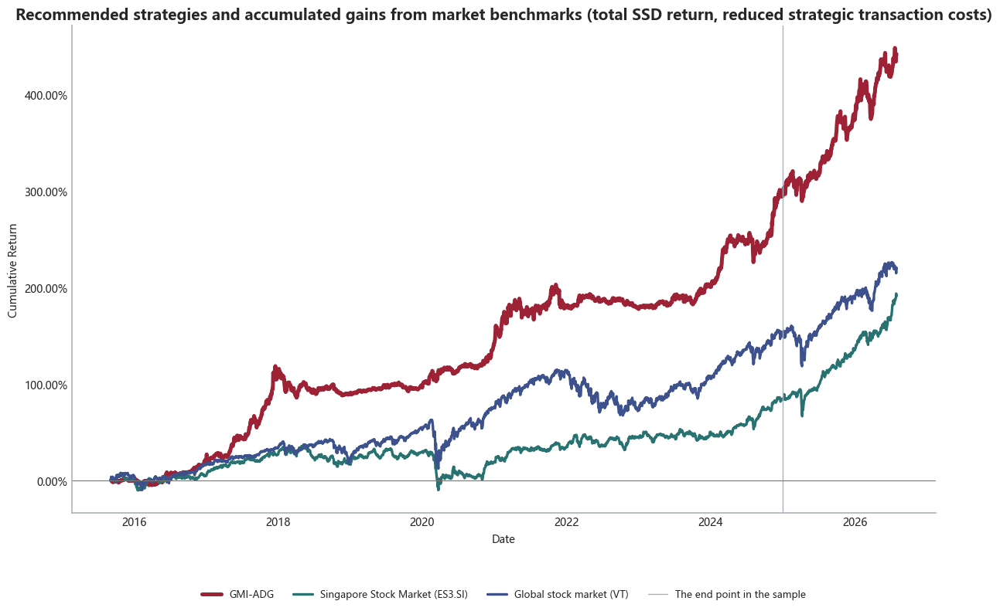

,2015(part of year),2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026(part of year)
Global Momentum Inverse Volatility (GMI-IV),1.82%,6.31%,24.39%,-4.63%,8.36%,6.24%,14.53%,-5.30%,5.62%,21.27%,19.99%,11.63%
Global Momentum Classic Risk Parity (GMI-CRP),1.70%,4.80%,30.51%,-5.25%,7.56%,6.23%,12.26%,-3.77%,3.11%,21.79%,21.02%,12.62%
Global Momentum EWMA Risk Parity (GMI-ERP),2.16%,8.27%,26.55%,-3.83%,7.77%,8.63%,13.72%,-2.48%,4.33%,20.69%,22.63%,14.41%
Global Momentum Downside Risk Parity (GMI-DRP),1.71%,5.18%,28.36%,-5.05%,7.90%,6.70%,12.23%,-4.85%,4.48%,21.32%,20.50%,12.31%
Global Multi-Asset Equal Weight (GMA-EW),2.79%,11.98%,33.43%,-11.49%,19.35%,16.32%,15.31%,-12.78%,10.53%,20.39%,12.35%,9.64%
Global Momentum Dynamic Risk Budget (GMI-DRB),1.54%,12.30%,25.49%,-3.05%,7.57%,10.95%,14.35%,-2.72%,4.36%,20.88%,22.43%,13.88%
Global Momentum Static Hierarchical Risk Budget (GMI-SHRB),1.61%,8.75%,23.83%,-3.33%,8.74%,11.93%,14.64%,-3.79%,3.92%,18.95%,22.35%,14.44%
Global Momentum GARCH Risk Parity (GMI-GRP),1.72%,5.12%,28.71%,-3.81%,7.75%,8.38%,13.13%,-3.92%,3.41%,22.04%,18.99%,12.11%
Global Momentum Adaptive Hierarchical Risk Budget (GMI-AHRB),0.79%,16.31%,33.50%,-4.89%,6.86%,16.65%,13.91%,-1.12%,4.75%,23.68%,20.76%,13.48%
Global Momentum Fixed Offensive Allocation (GMI-FOA),-0.16%,20.06%,72.04%,-10.87%,4.36%,23.25%,16.41%,-2.99%,6.23%,28.90%,15.84%,9.24%


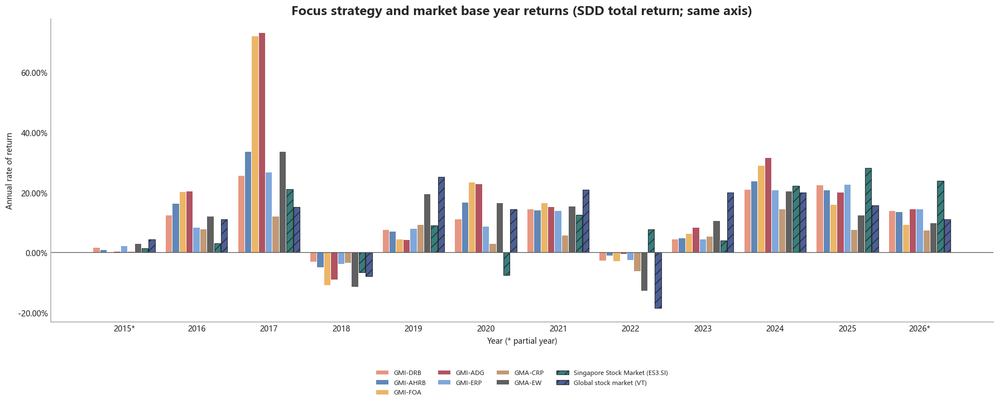

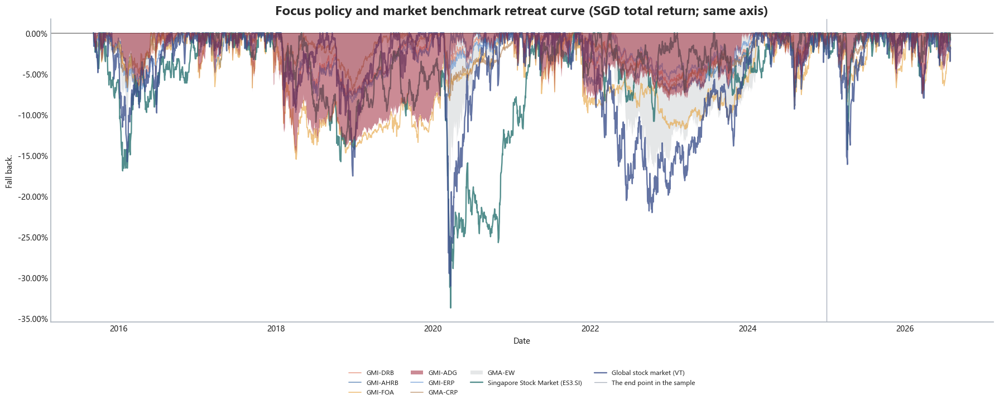

Market benchmarking is complete: Alpha/Beta has deducted SORA, and all research period indicators and graphics stop before lock-in test set.


In [36]:
MARKET_BENCHMARK_NAMES = {
    'ES3.SI': 'Singapore Stock Market (ES3.SI)',
    'VT': 'Global stock market (VT)',
}
SUBMISSION_STRATEGY = DYNAMIC_ATTACK_NAME


def annualized_compound_return(return_series):
    return_series = pd.Series(return_series, dtype=float).dropna()
    if len(return_series) < 2:
        return np.nan
    return float((1.0 + return_series).prod() ** (TRADING_DAYS / len(return_series)) - 1.0)


def benchmark_relative_metrics(result, benchmark_return, start=None, end=None):
    strategy_return = result['returns'].loc[start:end].rename('Strategic gains')
    benchmark_return = benchmark_return.loc[start:end].rename('Baseline proceeds')
    risk_free = result['risk_free_daily'].loc[start:end].rename('SORA')
    aligned = pd.concat([strategy_return, benchmark_return, risk_free], axis=1).dropna()
    if len(aligned) < 20:
        return pd.Series(dtype=float)

    strategy_excess = aligned['Strategic gains'] - aligned['SORA']
    benchmark_excess = aligned['Baseline proceeds'] - aligned['SORA']
    benchmark_variance = float(benchmark_excess.var(ddof=1))
    beta = (float(strategy_excess.cov(benchmark_excess)) / benchmark_variance
            if benchmark_variance > 0 else np.nan)
    daily_alpha = float(strategy_excess.mean() - beta * benchmark_excess.mean())
    annual_alpha = daily_alpha * TRADING_DAYS

    active_return = aligned['Strategic gains'] - aligned['Baseline proceeds']
    tracking_error = float(active_return.std(ddof=1) * np.sqrt(TRADING_DAYS))
    information_ratio = (float(active_return.mean() / active_return.std(ddof=1)
                               * np.sqrt(TRADING_DAYS))
                         if active_return.std(ddof=1) > 0 else np.nan)

    monthly = (1.0 + aligned[['Strategic gains', 'Baseline proceeds']]).resample('ME').prod() - 1.0
    up_months = monthly['Baseline proceeds'] > 0.0
    down_months = monthly['Baseline proceeds'] < 0.0
    upside_capture = (float(monthly.loc[up_months, 'Strategic gains'].mean()
                            / monthly.loc[up_months, 'Baseline proceeds'].mean())
                      if up_months.any() else np.nan)
    downside_capture = (float(monthly.loc[down_months, 'Strategic gains'].mean()
                              / monthly.loc[down_months, 'Baseline proceeds'].mean())
                        if down_months.any() else np.nan)

    strategy_total = float((1.0 + aligned['Strategic gains']).prod() - 1.0)
    benchmark_total = float((1.0 + aligned['Baseline proceeds']).prod() - 1.0)
    strategy_annual = annualized_compound_return(aligned['Strategic gains'])
    benchmark_annual = annualized_compound_return(aligned['Baseline proceeds'])
    return pd.Series({
        'Common trading day': len(aligned),
        'Strategy cumulative rate of return': strategy_total,
        'Baseline cumulative rate of return': benchmark_total,
        'Cumulative excess gains': strategy_total - benchmark_total,
        'Strategy annualized rate of return': strategy_annual,
        'Base yearized rate of return': benchmark_annual,
        'Annualized positive returns': strategy_annual - benchmark_annual,
        'Alpha (calculation)': annual_alpha,
        'Beta': beta,
        'Information ratio': information_ratio,
        'Yearly tracking error': tracking_error,
        'Increase catch rate': upside_capture,
        'Lower catch rate': downside_capture,
        'Alpha/Beta used SORA': True,
    })


# The full formal strategy is to be retained as an ordinary DataFrame that can continue to be filtered.
market_benchmark_records = []
for strategy_name, result in results.items():
    for benchmark_ticker, benchmark_label in MARKET_BENCHMARK_NAMES.items():
        metric = benchmark_relative_metrics(
            result,
            benchmark_returns_sgd[benchmark_ticker],
            strategy_start,
            RESEARCH_END,
        )
        record = metric.to_dict()
        record.update({
            'Policy': strategy_name,
            'Market benchmarks': benchmark_label,
            'Comparison': 'Study the complete range.',
        })
        market_benchmark_records.append(record)

market_benchmark_metrics = pd.DataFrame(market_benchmark_records).set_index(
    ['Market benchmarks', 'Policy']
).sort_index()

# Towards final submission: presentation of recommended strategy sub-species, validation period, full research period and lock-in test period.
submission_benchmark_records = []
submission_periods = {
    'In Sample': (None, IN_SAMPLE_END, results[SUBMISSION_STRATEGY]),
    'Validation interval': (OOS_START, RESEARCH_END, results[SUBMISSION_STRATEGY]),
    'Study the complete range.': (None, RESEARCH_END, results[SUBMISSION_STRATEGY]),
    'Lock Test Range': (HOLDOUT_START, actual_holdout_end, holdout_results[SUBMISSION_STRATEGY]),
}
for period_name, (start, end, result) in submission_periods.items():
    for benchmark_ticker, benchmark_label in MARKET_BENCHMARK_NAMES.items():
        metric = benchmark_relative_metrics(
            result, benchmark_returns_sgd[benchmark_ticker], start, end
        )
        record = metric.to_dict()
        record.update({'Period': period_name, 'Market benchmarks': benchmark_label})
        submission_benchmark_records.append(record)

submission_benchmark_comparison = pd.DataFrame(submission_benchmark_records).set_index(
    ['Period', 'Market benchmarks']
)


def format_benchmark_table(frame):
    formatted = frame.copy()
    percent_columns = [
        'Strategy cumulative rate of return', 'Baseline cumulative rate of return', 'Cumulative excess gains',
        'Strategy annualized rate of return', 'Base yearized rate of return', 'Annualized positive returns',
        'Alpha (calculation)', 'Yearly tracking error', 'Increase catch rate', 'Lower catch rate',
    ]
    for column in percent_columns:
        formatted[column] = formatted[column].map(lambda value: f'{value:.2%}')
    for column in ['Beta', 'Information ratio']:
        formatted[column] = formatted[column].map(lambda value: f'{value:.2f}')
    formatted['Common trading day'] = formatted['Common trading day'].astype(int)
    return formatted


display(format_benchmark_table(submission_benchmark_comparison))

# Cumulative inter-research benefits: recommended strategies use product main coarse lines and all sequences use solid lines.
benchmark_plot_returns = pd.concat({
    SUBMISSION_STRATEGY: results[SUBMISSION_STRATEGY]['returns'],
    MARKET_BENCHMARK_NAMES['ES3.SI']: benchmark_returns_sgd['ES3.SI'],
    MARKET_BENCHMARK_NAMES['VT']: benchmark_returns_sgd['VT'],
}, axis=1).loc[strategy_start:RESEARCH_END].dropna(how='any')
benchmark_cumulative = (1.0 + benchmark_plot_returns).cumprod() - 1.0

benchmark_plot_style = {
    SUBMISSION_STRATEGY: {'color': STRATEGY_COLORS[SUBMISSION_STRATEGY], 'linewidth': 3.6, 'linestyle': '-'},
    MARKET_BENCHMARK_NAMES['ES3.SI']: {'color': MARKET_BENCHMARK_COLORS['ES3.SI'], 'linewidth': 2.4, 'linestyle': '-'},
    MARKET_BENCHMARK_NAMES['VT']: {'color': MARKET_BENCHMARK_COLORS['VT'], 'linewidth': 2.4, 'linestyle': '-'},
}
fig, ax = plt.subplots(figsize=(15, 8))
for column in benchmark_cumulative:
    ax.plot(benchmark_cumulative.index, benchmark_cumulative[column],
            label=column, **benchmark_plot_style[column])
ax.axvline(IN_SAMPLE_END, color='#AAB2BD', linestyle='-', linewidth=1.0,
           label='The end point in the sample')
ax.axhline(0.0, color='#777777', linewidth=0.8)
ax.set_title('Recommended strategies and accumulated gains from market benchmarks (total SSD return, reduced strategic transaction costs)',
             fontsize=14, fontweight='bold')
ax.set_xlabel('Date')
ax.set_ylabel('Cumulative Return')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f'{value:.2%}'))
style_axis(ax)
place_legend(ax)
plt.tight_layout(rect=[0, 0, 0.82, 1])
plt.show()


# Annual returns on all 12 strategies and two market benchmarks; 2015 and 2026 are part of the year, with clear indications.
annual_strategy_returns = pd.DataFrame({
    strategy_name: (1.0 + result['returns'].loc[:RESEARCH_END]).groupby(
        result['returns'].loc[:RESEARCH_END].index.year
    ).prod() - 1.0
    for strategy_name, result in results.items()
})
annual_benchmark_returns = (1.0 + benchmark_returns_sgd.loc[
    strategy_start:RESEARCH_END, ['ES3.SI', 'VT']
]).groupby(benchmark_returns_sgd.loc[strategy_start:RESEARCH_END].index.year).prod() - 1.0
annual_benchmark_returns = annual_benchmark_returns.rename(columns=MARKET_BENCHMARK_NAMES)
annual_returns_all = pd.concat(
    [annual_strategy_returns, annual_benchmark_returns], axis=1
).sort_index()
annual_returns_all.index.name = 'Year'

annual_returns_display = annual_returns_all.T.copy()
annual_returns_display.columns = [
    f'{year}(part of year)' if year in {annual_returns_all.index.min(), annual_returns_all.index.max()}
    else str(year)
    for year in annual_returns_all.index
]
display(annual_returns_display.map(lambda value: '' if pd.isna(value) else f'{value:.2%}'))

# The focus strategy and the two market benchmarks are presented in the same column chart.
annual_plot_names = FOCUS_STRATEGIES + list(MARKET_BENCHMARK_NAMES.values())
annual_plot_colors = {
    **HIGHLIGHT_COLORS,
    MARKET_BENCHMARK_NAMES['ES3.SI']: MARKET_BENCHMARK_COLORS['ES3.SI'],
    MARKET_BENCHMARK_NAMES['VT']: MARKET_BENCHMARK_COLORS['VT'],
}
annual_plot_frame = annual_returns_all[annual_plot_names]
year_labels = [
    f'{year}*' if year in {annual_plot_frame.index.min(), annual_plot_frame.index.max()}
    else str(year)
    for year in annual_plot_frame.index
]

fig, ax = plt.subplots(figsize=(18, 9))
x_positions = np.arange(len(annual_plot_frame.index), dtype=float)
group_width = 0.86
bar_width = group_width / len(annual_plot_names)
for series_position, series_name in enumerate(annual_plot_names):
    is_benchmark = series_name in MARKET_BENCHMARK_NAMES.values()
    offset = (series_position - (len(annual_plot_names) - 1) / 2) * bar_width
    ax.bar(
        x_positions + offset,
        annual_plot_frame[series_name].to_numpy(dtype=float),
        width=bar_width * 0.92,
        color=annual_plot_colors[series_name],
        alpha=0.92 if is_benchmark else 0.78,
        edgecolor='#222222' if is_benchmark else 'none',
        linewidth=0.8,
        hatch='//' if is_benchmark else None,
        label=strategy_label(series_name),
    )

ax.axhline(0.0, color='#555555', linewidth=0.9)
ax.set_xticks(x_positions)
ax.set_xticklabels(year_labels, rotation=0)
ax.set_xlabel('Year (* partial year)')
ax.set_ylabel('Annual rate of return')
ax.set_title('Focus strategy and market base year returns (SDD total return; same axis)',
             fontsize=16, fontweight='bold')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f'{value:.2%}'))
style_axis(ax, axis='y')
place_legend(ax)
fig.tight_layout(rect=[0, 0.16, 1, 1])
plt.show()


# The withdrawal of the same set of priority strategies and market benchmarks is also shown in a chart.
focus_benchmark_returns = pd.concat({
    **{name: results[name]['returns'] for name in FOCUS_STRATEGIES},
    MARKET_BENCHMARK_NAMES['ES3.SI']: benchmark_returns_sgd['ES3.SI'],
    MARKET_BENCHMARK_NAMES['VT']: benchmark_returns_sgd['VT'],
}, axis=1).loc[strategy_start:RESEARCH_END].dropna(how='any')
focus_benchmark_wealth = (1.0 + focus_benchmark_returns).cumprod()
focus_benchmark_drawdowns = focus_benchmark_wealth.div(
    focus_benchmark_wealth.cummax()
) - 1.0

fig, ax = plt.subplots(figsize=(18, 9))
for series_name in focus_benchmark_drawdowns.columns:
    is_submission = series_name == SUBMISSION_STRATEGY
    is_base = series_name == BASELINE_STRATEGY
    is_benchmark = series_name in MARKET_BENCHMARK_NAMES.values()
    series_label = strategy_label(series_name) if series_name in STRATEGY_LABELS else series_name
    if is_submission or is_base:
        fill_color = annual_plot_colors[series_name] if is_submission else '#8C9299'
        fill_alpha = 0.52 if is_submission else 0.22
        ax.fill_between(
            focus_benchmark_drawdowns.index,
            focus_benchmark_drawdowns[series_name].to_numpy(dtype=float), 0.0,
            color=fill_color, linewidth=0, edgecolor='none', alpha=fill_alpha,
            label=series_label, zorder=4 if is_submission else 1,
        )
    else:
        ax.plot(
            focus_benchmark_drawdowns.index,
            focus_benchmark_drawdowns[series_name],
            color=annual_plot_colors[series_name], linewidth=1.7 if is_benchmark else 1.3,
            alpha=0.80 if is_benchmark else 0.62,
            label=series_label, zorder=3 if is_benchmark else 2,
        )

ax.axvline(IN_SAMPLE_END, color='#AAB2BD', linestyle='-', linewidth=1.0,
           label='The end point in the sample')
ax.axhline(0.0, color='#555555', linewidth=0.8)
ax.set_title('Focus policy and market benchmark retreat curve (SGD total return; same axis)',
             fontsize=16, fontweight='bold')
ax.set_xlabel('Date')
ax.set_ylabel('Fall back.')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f'{value:.2%}'))
style_axis(ax)
place_legend(ax)
fig.tight_layout(rect=[0, 0.16, 1, 1])
plt.show()

if annual_returns_all.index.max() != RESEARCH_END.year:
    raise RuntimeError('Annual returns do not cover the final year of the study.')

if benchmark_plot_returns.index.max() >= HOLDOUT_START:
    raise RuntimeError('The market benchmark study map read the lock-in test range.')
if not {'ES3.SI', 'VT'}.issubset(benchmark_returns_sgd.columns):
    raise RuntimeError('Market baseline returns data are incomplete.')
print('Market benchmarking is complete: Alpha/Beta has deducted SORA, and all research period indicators and graphics stop before lock-in test set.')


### 6.4 Unified Summary of All 12 Formal Strategies


This section is the only formal consolidated portal. The table of indicators, the complete study of the cumulative inter-area income map, the fall-back map and the cumulative inter-validation income map are all read together and therefore contain the same 13 strategies. The previous drawing section defines only functions and does not produce another set of formal results.

SORA uniform inspection passes: study space12/12Item,Lock Test Range12/12The policies are fully covered.
Number of harmonized aggregate strategies:12
Study interval:2015-09-07to2026-07-31
Samples, certification areas and complete study areas are sorted from small to large, respectively; colour gradients are not used for the indicator tables.


Initial funding (SGD)  \
Period                                   Shape Sorting Number (low to high) Policy                                                                      
In Sample (through 2024-12-31)           1                                  Global Multi-Asset Classic Risk Parity (GMA-CRP)               1000000.00   
                                         2                                  Global Momentum Inverse Volatility (GMI-IV)                    1000000.00   
                                         3                                  Global Momentum Downside Risk Parity (GMI-DRP)                 1000000.00   
                                         4                                  Global Momentum Classic Risk Parity (GMI-CRP)                  1000000.00   
                                         5                                  Global Multi-Asset Equal Weight (GMA-EW)                       1000000.00   
                                         6                                  Global Momentum GARCH Risk Parity (GMI-GRP)                    1000000.00   
                                         7                                  Global Momentum Static Hierarchical Risk Budget...             1000000.00   
                                         8                                  Global Momentum EWMA Risk Parity (GMI-ERP)                     1000000.00   
                                         9                                  Global Momentum Dynamic Risk Budget (GMI-DRB)                  1000000.00   
                                         10                                 Global Momentum Fixed Offensive Allocation (GMI...             1000000.00   
                                         11                                 Global Momentum Adaptive Hierarchical Risk Budg...             1000000.00   
                                         12                                 Global Momentum Adaptive Defense and Growth (GM...             1000000.00   
Validation (2025-01-01 to 2026-07-31)    1                                  Global Momentum Fixed Offensive Allocation (GMI...             1000000.00   
                                         2                                  Global Multi-Asset Equal Weight (GMA-EW)                       1000000.00   
                                         3                                  Global Multi-Asset Classic Risk Parity (GMA-CRP)               1000000.00   
                                         4                                  Global Momentum Adaptive Defense and Growth (GM...             1000000.00   
                                         5                                  Global Momentum Inverse Volatility (GMI-IV)                    1000000.00   
                                         6                                  Global Momentum Adaptive Hierarchical Risk Budg...             1000000.00   
                                         7                                  Global Momentum GARCH Risk Parity (GMI-GRP)                    1000000.00   
                                         8                                  Global Momentum Downside Risk Parity (GMI-DRP)                 1000000.00   
                                         9                                  Global Momentum Classic Risk Parity (GMI-CRP)                  1000000.00   
                                         10                                 Global Momentum Dynamic Risk Budget (GMI-DRB)                  1000000.00   
                                         11                                 Global Momentum EWMA Risk Parity (GMI-ERP)                     1000000.00   
                                         12                                 Global Momentum Static Hierarchical Risk Budget...             1000000.00   
Full Research Period (excluding holdout) 1                                  Global Multi-Asset Classic Risk Parity (GMA-CRP)               1000000.00 

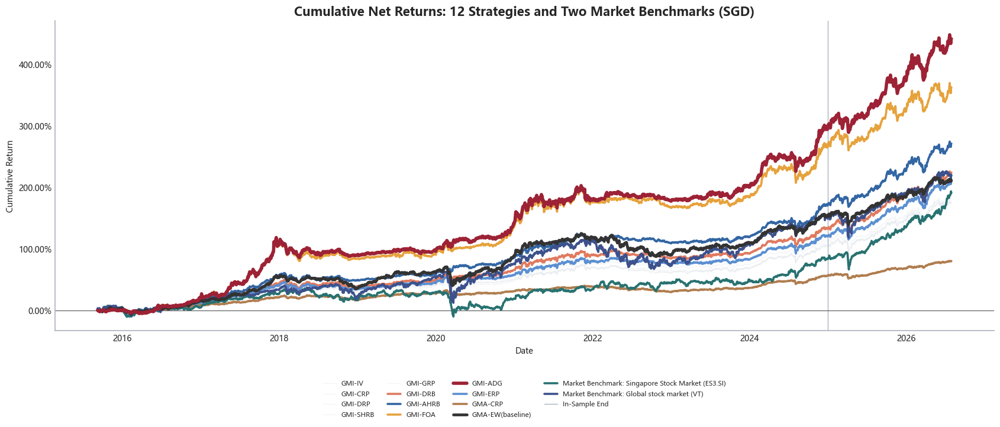

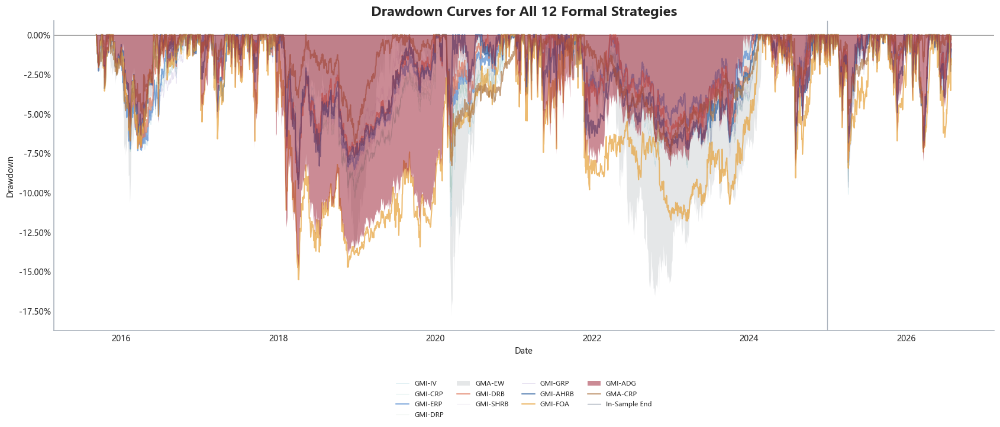

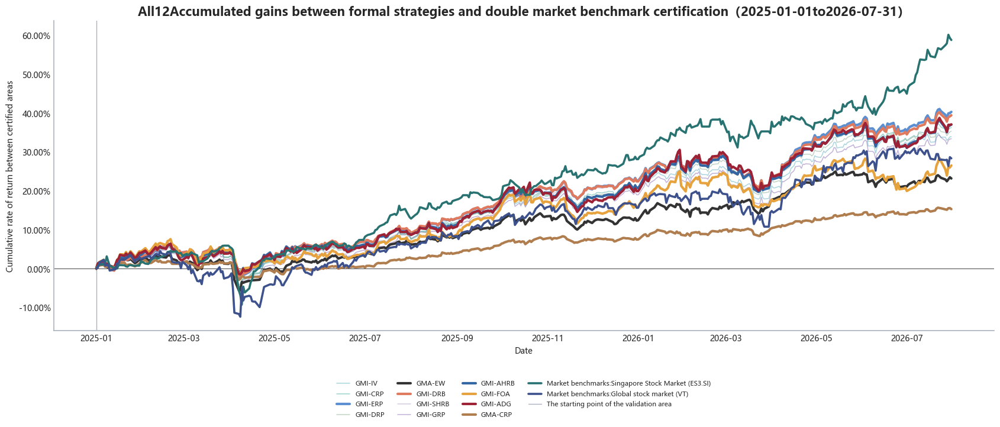

Uniform checks were carried out: a table of indicators, a map of cumulative gains, a map of fallbacks and a map of certification zones contained the same set of 12 formal strategies.


In [37]:
FINAL_EXPECTED_STRATEGY_COUNT = 12
final_strategy_names = list(results.keys())
if len(final_strategy_names) != FINAL_EXPECTED_STRATEGY_COUNT:
    raise RuntimeError(
        f'The number of formal strategies should read{FINAL_EXPECTED_STRATEGY_COUNT}, actual{len(final_strategy_names)}。'
    )
if len(set(final_strategy_names)) != len(final_strategy_names):
    raise RuntimeError('There is a duplication of official policy names.')

sora_audit_records = []
for scope_name, result_map in [('Area of study', results), ('Lock Test Range', holdout_results)]:
    for strategy_name, result in result_map.items():
        if 'risk_free_daily' not in result or 'funding_daily' not in result:
            raise RuntimeError(f'{scope_name}Yes.{strategy_name}No single SORA is used.')
        strategy_index = result['returns'].dropna().index
        rf_series = result['risk_free_daily'].reindex(strategy_index)
        funding_series = result['funding_daily'].reindex(strategy_index)
        if rf_series.isna().any() or funding_series.isna().any():
            raise RuntimeError(f'{scope_name}Yes.{strategy_name}There is a SORA coverage gap.')
        sora_audit_records.append({
            'Scope': scope_name, 'Policy': strategy_name,
            'Number of days of trading in proceeds': len(strategy_index), 'SORA covers transaction days': int(rf_series.notna().sum()),
            'Finance interest rate covers transaction days': int(funding_series.notna().sum()),
        })
sora_usage_audit = pd.DataFrame(sora_audit_records).set_index(['Scope', 'Policy'])
print(
    f'SORA uniform inspection passes: study space{len(results)}/{len(results)}Item,'
    f'Lock Test Range{len(holdout_results)}/{len(holdout_results)}The policies are fully covered.'
)

strategy_returns = pd.concat(
    [results[name]['returns'].rename(name) for name in final_strategy_names], axis=1
).dropna(how='any')
if strategy_returns.index.max() >= HOLDOUT_START:
    raise RuntimeError('A uniform summary of data leaks from locked tests.')

metrics_by_period = pd.concat({
    period: pd.DataFrame({
        name: compute_metrics(results[name], start, end)
        for name in final_strategy_names
    }).T
    for period, (start, end) in periods.items()
}, names=['Period', 'Policy'])

# Each test period is ranked independently from small to large according to the Sharp ratio.
sorted_period_frames = []
for period_name in metrics_by_period.index.get_level_values('Period').unique():
    period_frame = metrics_by_period.xs(period_name, level='Period').sort_values(
        'Sharpe Ratio', ascending=True, kind='mergesort'
    )
    period_frame.insert(
        0, 'Shape Sorting Number (low to high)', np.arange(1, len(period_frame) + 1)
    )
    period_frame['Period'] = period_name
    sorted_period_frames.append(period_frame.reset_index())

metrics_by_period_sorted = pd.concat(sorted_period_frames, ignore_index=True)
metrics_by_period_sorted = metrics_by_period_sorted.set_index(['Period', 'Shape Sorting Number (low to high)', 'Policy'])

# Normal DataFrame is displayed without background gradients, heat attempts or colour encoding.
formatted_metrics = metrics_by_period_sorted.copy()
for column in ['Cumulative Return', 'Annualized Return', 'Annualized Volatility', 'Maximum Drawdown',
               'Positive-Day Ratio', 'Annual One-Way Turnover', 'Annual Two-Way Traded Notional', 'Average Gross Exposure']:
    formatted_metrics[column] = formatted_metrics[column].map(lambda value: f'{value:.2%}')
for column in ['Sharpe Ratio', 'Sortino Ratio', 'Calmar Ratio']:
    formatted_metrics[column] = formatted_metrics[column].map(lambda value: f'{value:.2f}')
for column in ['Number of Rebalances', 'Number of Trade Legs']:
    formatted_metrics[column] = formatted_metrics[column].map(lambda value: f'{value:.0f}')

print(f'Number of harmonized aggregate strategies:{len(final_strategy_names)}')
print(f'Study interval:{strategy_returns.index.min().date()}to{strategy_returns.index.max().date()}')
print('Samples, certification areas and complete study areas are sorted from small to large, respectively; colour gradients are not used for the indicator tables.')
display(formatted_metrics)

final_cumulative, final_strategy_color_map = plot_all_strategy_cumulative(strategy_returns)
final_drawdowns = plot_all_strategy_drawdowns(strategy_returns, final_strategy_color_map)
final_oos_cumulative = plot_all_strategy_oos(strategy_returns, final_strategy_color_map)

assert list(final_cumulative.columns) == final_strategy_names
assert list(final_drawdowns.columns) == final_strategy_names
assert list(final_oos_cumulative.columns) == final_strategy_names
print('Uniform checks were carried out: a table of indicators, a map of cumulative gains, a map of fallbacks and a map of certification zones contained the same set of 12 formal strategies.')


### 6.5 Statistical Tests of Market Outperformance


This section examines whether the strategy defeats the market at four levels: absolute gain, risk adjustment gain, back protection and statistical visibility. The market benchmark remains ** ES3.SI (Singapore equities)** and ** VT (global equities)**, using all SSD returns and aligning them with the strategy with the common trading date.

- Alpha and Beta: the return of excess earnings from the use of the strategy and the relative date of SORA, and the misprocessing of differences and sequences by the Newey-West (HAC) standard;
- Information ratio: average active daily earnings divided by tracking errors and annualization;
- Upper- and lower-line capture rates: calculated on a monthly basis;
- Bootstream: an estimated 95 per cent confidence interval of annualized active earnings using a sample of 20 trading days of mobile blocks;
- Comprehensive determination: Only annualized active returns are positive, information ratios are positive, and Alpha is positive and significant will be marked as “a statistically significant defeat”; if proceeds are ahead but Alpha is not significant, they are marked as “proceeds ahead but insufficient”.

These tests are ex post performance evaluations, do not participate in vouchers, risk budgets or reconciliations, and therefore do not pass benchmark future gains into strategies. Locks the test range to read only `holdout_results` that was previously independently generated.

The proposed strategy, interdivisional market victory test:


Strategy cumulative rate of return Baseline cumulative rate of return Annualized positive returns Strategy Sharp Ratio  \
Period                    Market benchmarks                                                                                                                                        
In Sample                 Singapore Stock Market (ES3.SI)                            295.05%                             83.23%                       8.84%                 1.27   
                          Global stock market (VT)                                   295.05%                            148.92%                       5.40%                 1.27   
Validation interval       Singapore Stock Market (ES3.SI)                             37.08%                             58.78%                     -11.48%                 1.61   
                          Global stock market (VT)                                    37.08%                             28.36%                       4.81%                 1.61   
Study the complete range. Singapore Stock Market (ES3.SI)                            441.52%                            190.93%                       6.24%                 1.32   
                          Global stock market (VT)                                   441.52%                            219.50%                       5.32%                 1.32   
Lock Test Range           Singapore Stock Market (ES3.SI)                              1.72%                              1.60%                       0.72%                 1.32   
                          Global stock market (VT)                                     1.72%                              1.18%                       3.31%                 1.32   

                                                          Base Sharp ratio Maximum retreat of strategy Maximum benchmark retreat   Alpha Alpha t (HAC) Alpha p (HAC)  Beta  \
Period                    Market benchmarks                                                                                                                                  
In Sample                 Singapore Stock Market (ES3.SI)             0.45                     -14.98%                   -33.77%  13.06%          3.94          0.00  0.08   
                          Global stock market (VT)                    0.55                     -14.98%                   -31.09%  11.47%          3.53          0.00  0.21   
Validation interval       Singapore Stock Market (ES3.SI)             2.14                      -8.02%                   -14.33%   9.27%          1.27          0.20  0.33   
                          Global stock market (VT)                    0.91                      -8.02%                   -16.14%  14.11%          1.97          0.05  0.29   
Study the complete range. Singapore Stock Market (ES3.SI)             0.70                     -14.98%                   -33.77%  13.20%          4.32          0.00  0.12   
                          Global stock market (VT)                    0.60                     -14.98%                   -31.09%  11.91%          4.02          0.00  0.22   
Lock Test Range           Singapore Stock Market (ES3.SI)             0.87                      -1.91%                    -2.94%   6.58%          0.48          0.63  0.26   
                          Global stock market (VT)                    0.51                      -1.91%                    -3.58%   7.77%          0.49          0.62  0.16   

                                                          Information ratio Bootstream 95% floor Bootstrap 95 per cent cap Increase catch rate Lower catch rate  \
Period                    Market benchmarks                                                                                                                       
In Sample                 Singapore Stock Market (ES3.SI)              0.49               -1.84%                    18.47%              64.99%          -13.36%   
                          G

The market victory test for all formal strategy studies (high to low information ratios):


Strategy cumulative rate of return Baseline cumulative rate of return  \
Market benchmarks               Policy                                                                                                                     
Singapore Stock Market (ES3.SI) Global Momentum Adaptive Defense and Growth (GM...                            441.52%                            190.93%   
                                Global Momentum Fixed Offensive Allocation (GMI...                            362.55%                            190.93%   
Global stock market (VT)        Global Momentum Adaptive Defense and Growth (GM...                            441.52%                            219.50%   
                                Global Momentum Fixed Offensive Allocation (GMI...                            362.55%                            219.50%   
Singapore Stock Market (ES3.SI) Global Momentum Adaptive Hierarchical Risk Budg...                            270.99%                            190.93%   
                                Global Momentum Dynamic Risk Budget (GMI-DRB)                                 223.95%                            190.93%   
                                Global Multi-Asset Equal Weight (GMA-EW)                                      211.15%                            190.93%   
Global stock market (VT)        Global Momentum Adaptive Hierarchical Risk Budg...                            270.99%                            219.50%   
Singapore Stock Market (ES3.SI) Global Momentum EWMA Risk Parity (GMI-ERP)                                    208.73%                            190.93%   
                                Global Momentum Static Hierarchical Risk Budget...                            207.36%                            190.93%   
                                Global Momentum GARCH Risk Parity (GMI-GRP)                                   182.91%                            190.93%   
                                Global Momentum Classic Risk Parity (GMI-CRP)                                 178.42%                            190.93%   
Global stock market (VT)        Global Momentum Dynamic Risk Budget (GMI-DRB)                                 223.95%                            219.50%   
Singapore Stock Market (ES3.SI) Global Momentum Inverse Volatility (GMI-IV)                                   175.07%                            190.93%   
                                Global Momentum Downside Risk Parity (GMI-DRP)                                174.95%                            190.93%   
Global stock market (VT)        Global Momentum EWMA Risk Parity (GMI-ERP)                                    208.73%                            219.50%   
                                Global Momentum Static Hierarchical Risk Budget...                            207.36%                            219.50%   
                                Global Multi-Asset Equal Weight (GMA-EW)                                      211.15%                            219.50%   
                                Global Momentum GARCH Risk Parity (GMI-GRP)                                   182.91%                            219.50%   
                                Global Momentum Classic Risk Parity (GMI-CRP)                                 178.42%                            219.50%   
                                Global Momentum Downside Risk Parity (GMI-DRP)                                174.95%                            219.50%   
                                Global Momentum Inverse Volatility (GMI-IV)                                   175.07%                            219.50%   
Singapore Stock Market (ES3.SI) Global Multi-Asset Classic Risk Parity (GMA-CRP)                               79.75%                            190.93%   
Global stock market (VT)        Global Multi-Asset Classic Risk Parity (GMA-CRP)                               79.75%                            219.50%   

                          

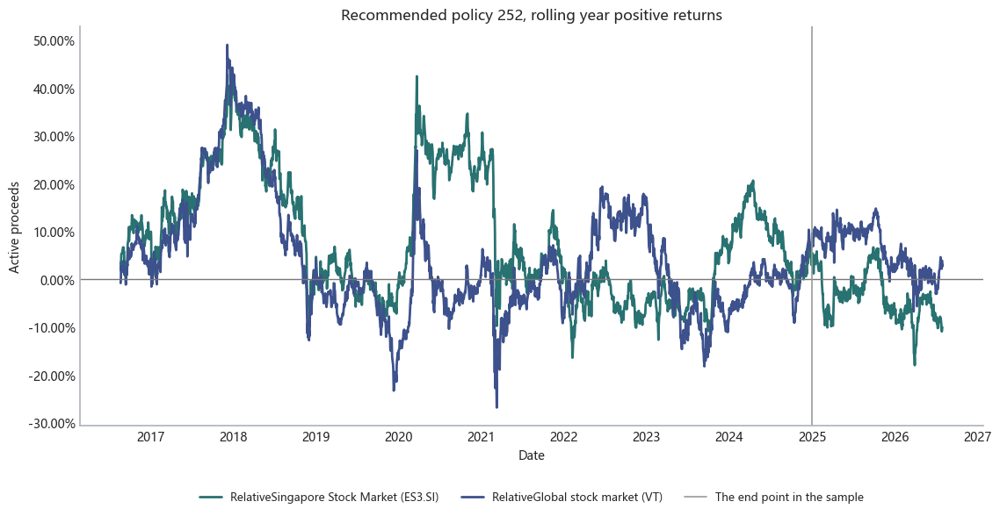

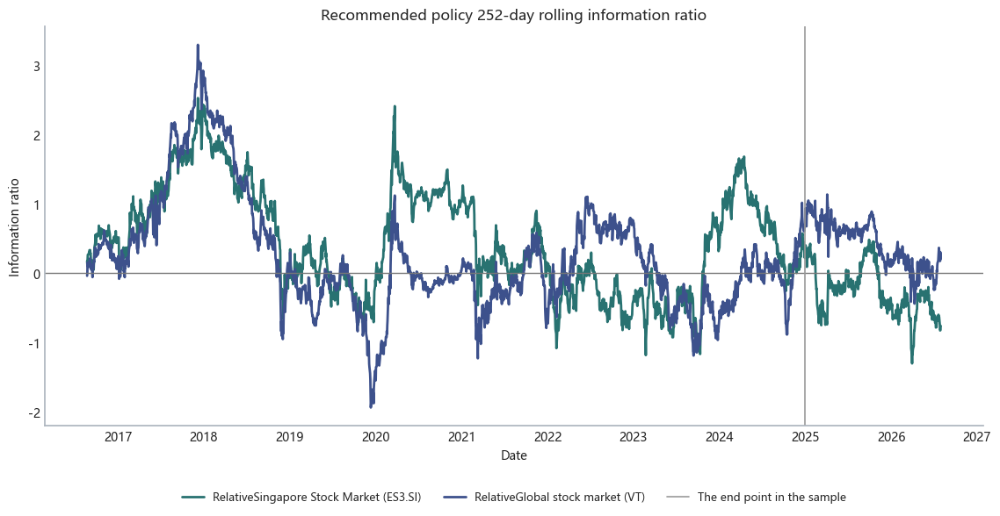

Test complete: The test for the research period did not read the locked data outside the sample; the locked range was only evaluated separately from the existing holdout results.


In [38]:
import statsmodels.api as sm

OUTPERFORMANCE_BOOTSTRAP_SEED = 20260908
OUTPERFORMANCE_BOOTSTRAP_SAMPLES = 2000
OUTPERFORMANCE_BLOCK_LENGTH = 20


def maximum_drawdown(return_series):
    wealth = (1.0 + pd.Series(return_series, dtype=float).dropna()).cumprod()
    if wealth.empty:
        return np.nan
    running_peak = wealth.cummax().clip(lower=1.0)
    return float((wealth / running_peak - 1.0).min())


def moving_block_active_return_ci(
    active_returns, samples=OUTPERFORMANCE_BOOTSTRAP_SAMPLES,
    block_length=OUTPERFORMANCE_BLOCK_LENGTH, seed=OUTPERFORMANCE_BOOTSTRAP_SEED,
):
    """Move block Bootstream: Keep short-term sequences associated and return 95% of the annualized active yield."""
    values = pd.Series(active_returns, dtype=float).dropna().to_numpy()
    n = len(values)
    if n < max(60, block_length * 2):
        return np.nan, np.nan
    rng = np.random.default_rng(seed)
    block_count = int(np.ceil(n / block_length))
    starts = np.arange(n)
    estimates = np.empty(samples, dtype=float)
    offsets = np.arange(block_length)
    for sample_id in range(samples):
        selected_starts = rng.choice(starts, size=block_count, replace=True)
        positions = (selected_starts[:, None] + offsets[None, :]) % n
        resampled = values[positions.ravel()[:n]]
        estimates[sample_id] = resampled.mean() * TRADING_DAYS
    return tuple(np.quantile(estimates, [0.025, 0.975]))


def market_outperformance_test(result, benchmark_return, start=None, end=None):
    strategy = result['returns'].loc[start:end].rename('Strategic gains')
    benchmark = benchmark_return.loc[start:end].rename('Baseline proceeds')
    risk_free = result['risk_free_daily'].loc[start:end].rename('SORA')
    aligned = pd.concat([strategy, benchmark, risk_free], axis=1).dropna()
    if len(aligned) < 20:
        return pd.Series(dtype=float)

    strategy_excess = aligned['Strategic gains'] - aligned['SORA']
    benchmark_excess = aligned['Baseline proceeds'] - aligned['SORA']
    regression_x = sm.add_constant(benchmark_excess.rename('Market excess earnings'))
    max_lags = max(1, int(4 * (len(aligned) / 100) ** (2 / 9)))
    regression = sm.OLS(strategy_excess, regression_x).fit(
        cov_type='HAC', cov_kwds={'maxlags': max_lags}
    )
    daily_alpha = float(regression.params['const'])
    annual_alpha = daily_alpha * TRADING_DAYS
    alpha_t = float(regression.tvalues['const'])
    alpha_p = float(regression.pvalues['const'])
    beta = float(regression.params['Market excess earnings'])
    alpha_ci_daily = regression.conf_int(alpha=0.05).loc['const']

    active = aligned['Strategic gains'] - aligned['Baseline proceeds']
    tracking_error = float(active.std(ddof=1) * np.sqrt(TRADING_DAYS))
    information_ratio = (
        float(active.mean() / active.std(ddof=1) * np.sqrt(TRADING_DAYS))
        if active.std(ddof=1) > 0 else np.nan
    )
    bootstrap_low, bootstrap_high = moving_block_active_return_ci(active)

    monthly = (1.0 + aligned[['Strategic gains', 'Baseline proceeds']]).resample('ME').prod() - 1.0
    up = monthly['Baseline proceeds'] > 0
    down = monthly['Baseline proceeds'] < 0
    upside_capture = (
        float(monthly.loc[up, 'Strategic gains'].mean() / monthly.loc[up, 'Baseline proceeds'].mean())
        if up.any() else np.nan
    )
    downside_capture = (
        float(monthly.loc[down, 'Strategic gains'].mean() / monthly.loc[down, 'Baseline proceeds'].mean())
        if down.any() else np.nan
    )

    strategy_total = float((1.0 + aligned['Strategic gains']).prod() - 1.0)
    benchmark_total = float((1.0 + aligned['Baseline proceeds']).prod() - 1.0)
    strategy_annual = annualized_compound_return(aligned['Strategic gains'])
    benchmark_annual = annualized_compound_return(aligned['Baseline proceeds'])
    strategy_sharpe = float(
        strategy_excess.mean() / strategy_excess.std(ddof=1) * np.sqrt(TRADING_DAYS)
    )
    benchmark_sharpe = float(
        benchmark_excess.mean() / benchmark_excess.std(ddof=1) * np.sqrt(TRADING_DAYS)
    )
    strategy_mdd = maximum_drawdown(aligned['Strategic gains'])
    benchmark_mdd = maximum_drawdown(aligned['Baseline proceeds'])

    return pd.Series({
        'Common trading day': len(aligned),
        'Strategy cumulative rate of return': strategy_total,
        'Baseline cumulative rate of return': benchmark_total,
        'Strategy annualized rate of return': strategy_annual,
        'Base yearized rate of return': benchmark_annual,
        'Annualized positive returns': strategy_annual - benchmark_annual,
        'Strategy Sharp Ratio': strategy_sharpe,
        'Base Sharp ratio': benchmark_sharpe,
        'Maximum retreat of strategy': strategy_mdd,
        'Maximum benchmark retreat': benchmark_mdd,
        'Alpha': annual_alpha,
        'Alpha age 95% lower limit': float(alpha_ci_daily.iloc[0] * TRADING_DAYS),
        'Alpha \' s 95% upper limit': float(alpha_ci_daily.iloc[1] * TRADING_DAYS),
        'Alpha t (HAC)': alpha_t,
        'Alpha p (HAC)': alpha_p,
        'Beta': beta,
        'Information ratio': information_ratio,
        'Yearly tracking error': tracking_error,
        'Bootstream 95% floor': bootstrap_low,
        'Bootstrap 95 per cent cap': bootstrap_high,
        'Increase catch rate': upside_capture,
        'Lower catch rate': downside_capture,
    })


def outperformance_verdict(row):
    return_lead = row['Annualized positive returns'] > 0
    risk_adjusted_lead = row['Information ratio'] > 0
    significant_alpha = row['Alpha'] > 0 and row['Alpha p (HAC)'] < 0.05
    bootstrap_positive = row['Bootstream 95% floor'] > 0
    if return_lead and risk_adjusted_lead and significant_alpha and bootstrap_positive:
        return 'A statistically significant defeat of the market.'
    if return_lead and risk_adjusted_lead:
        return 'Gains ahead, but lack of statistical evidence'
    return 'Not beat the market.'


# Full formal strategy: study of the whole zone versus two market benchmark tests.
outperformance_records = []
for strategy_name, result in results.items():
    for benchmark_ticker, benchmark_label in MARKET_BENCHMARK_NAMES.items():
        metric = market_outperformance_test(
            result, benchmark_returns_sgd[benchmark_ticker], strategy_start, RESEARCH_END
        )
        record = metric.to_dict()
        record.update({'Policy': strategy_name, 'Market benchmarks': benchmark_label})
        outperformance_records.append(record)

market_outperformance_results = pd.DataFrame(outperformance_records).set_index(
    ['Market benchmarks', 'Policy']
)
market_outperformance_results['Consolidated determination'] = market_outperformance_results.apply(
    outperformance_verdict, axis=1
)


# Recommended policy: Tests within the sample, during validation, throughout research and during lock-in testing.
submission_test_records = []
submission_test_periods = {
    'In Sample': (None, IN_SAMPLE_END, results[SUBMISSION_STRATEGY]),
    'Validation interval': (OOS_START, RESEARCH_END, results[SUBMISSION_STRATEGY]),
    'Study the complete range.': (None, RESEARCH_END, results[SUBMISSION_STRATEGY]),
    'Lock Test Range': (HOLDOUT_START, actual_holdout_end, holdout_results[SUBMISSION_STRATEGY]),
}
for period_name, (start, end, result) in submission_test_periods.items():
    for benchmark_ticker, benchmark_label in MARKET_BENCHMARK_NAMES.items():
        metric = market_outperformance_test(
            result, benchmark_returns_sgd[benchmark_ticker], start, end
        )
        record = metric.to_dict()
        record.update({'Period': period_name, 'Market benchmarks': benchmark_label})
        submission_test_records.append(record)

submission_market_test = pd.DataFrame(submission_test_records).set_index(
    ['Period', 'Market benchmarks']
)
submission_market_test['Consolidated determination'] = submission_market_test.apply(
    outperformance_verdict, axis=1
)


def format_outperformance_table(frame):
    formatted = frame.copy()
    percent_columns = [
        'Strategy cumulative rate of return', 'Baseline cumulative rate of return', 'Strategy annualized rate of return', 'Base yearized rate of return',
        'Annualized positive returns', 'Maximum retreat of strategy', 'Maximum benchmark retreat', 'Alpha',
        'Alpha age 95% lower limit', 'Alpha \' s 95% upper limit', 'Yearly tracking error',
        'Bootstream 95% floor', 'Bootstrap 95 per cent cap',
        'Increase catch rate', 'Lower catch rate',
    ]
    for column in percent_columns:
        formatted[column] = formatted[column].map(
            lambda value: '—' if pd.isna(value) else f'{value:.2%}'
        )
    for column in ['Strategy Sharp Ratio', 'Base Sharp ratio', 'Alpha t (HAC)', 'Beta', 'Information ratio']:
        formatted[column] = formatted[column].map(
            lambda value: '—' if pd.isna(value) else f'{value:.2f}'
        )
    formatted['Alpha p (HAC)'] = formatted['Alpha p (HAC)'].map(
        lambda value: '—' if pd.isna(value) else f'{value:.2f}'
    )
    formatted['Common trading day'] = formatted['Common trading day'].fillna(0).astype(int)
    return formatted


display_columns = [
    'Strategy cumulative rate of return', 'Baseline cumulative rate of return', 'Annualized positive returns',
    'Strategy Sharp Ratio', 'Base Sharp ratio', 'Maximum retreat of strategy', 'Maximum benchmark retreat',
    'Alpha', 'Alpha t (HAC)', 'Alpha p (HAC)', 'Beta', 'Information ratio',
    'Bootstream 95% floor', 'Bootstrap 95 per cent cap',
    'Increase catch rate', 'Lower catch rate', 'Consolidated determination',
]
print('The proposed strategy, interdivisional market victory test:')
display(format_outperformance_table(submission_market_test)[display_columns])

print('The market victory test for all formal strategy studies (high to low information ratios):')
display(
    format_outperformance_table(
        market_outperformance_results.sort_values('Information ratio', ascending=False)
    )[display_columns]
)


# The rolling test only uses each date and 252 prior common trading days, without affecting strategic transaction decisions.
rolling_source = pd.concat({
    SUBMISSION_STRATEGY: results[SUBMISSION_STRATEGY]['returns'],
    MARKET_BENCHMARK_NAMES['ES3.SI']: benchmark_returns_sgd['ES3.SI'],
    MARKET_BENCHMARK_NAMES['VT']: benchmark_returns_sgd['VT'],
}, axis=1).loc[strategy_start:RESEARCH_END].dropna()

rolling_active_return = pd.DataFrame(index=rolling_source.index)
rolling_information_ratio = pd.DataFrame(index=rolling_source.index)
for benchmark_label in [MARKET_BENCHMARK_NAMES['ES3.SI'], MARKET_BENCHMARK_NAMES['VT']]:
    active = rolling_source[SUBMISSION_STRATEGY] - rolling_source[benchmark_label]
    rolling_active_return[benchmark_label] = active.rolling(TRADING_DAYS).mean() * TRADING_DAYS
    rolling_information_ratio[benchmark_label] = (
        active.rolling(TRADING_DAYS).mean()
        / active.rolling(TRADING_DAYS).std(ddof=1)
        * np.sqrt(TRADING_DAYS)
    )

rolling_colors = {
    MARKET_BENCHMARK_NAMES['ES3.SI']: MARKET_BENCHMARK_COLORS['ES3.SI'],
    MARKET_BENCHMARK_NAMES['VT']: MARKET_BENCHMARK_COLORS['VT'],
}
rolling_styles = {
    MARKET_BENCHMARK_NAMES['ES3.SI']: '-',
    MARKET_BENCHMARK_NAMES['VT']: '-',
}
fig, ax = plt.subplots(figsize=(14, 6))
for benchmark_label in rolling_active_return.columns:
    ax.plot(
        rolling_active_return.index, rolling_active_return[benchmark_label],
        color=rolling_colors[benchmark_label], linestyle=rolling_styles[benchmark_label],
        linewidth=2.0, label=f'Relative{benchmark_label}',
    )
ax.axhline(0, color='#777777', linewidth=1.0)
ax.axvline(IN_SAMPLE_END, color='#999999', linestyle='-', linewidth=1.2, label='The end point in the sample')
style_axis(ax)
place_legend(ax)
ax.set_title('Recommended policy 252, rolling year positive returns')
ax.set_ylabel('Active proceeds')
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=2))
ax.set_xlabel('Date')
plt.tight_layout(rect=[0, 0, 0.82, 1])
plt.show()

fig, ax = plt.subplots(figsize=(14, 6))
for benchmark_label in rolling_information_ratio.columns:
    ax.plot(
        rolling_information_ratio.index, rolling_information_ratio[benchmark_label],
        color=rolling_colors[benchmark_label], linestyle=rolling_styles[benchmark_label],
        linewidth=2.0, label=f'Relative{benchmark_label}',
    )
ax.axhline(0, color='#777777', linewidth=1.0)
ax.axvline(IN_SAMPLE_END, color='#999999', linestyle='-', linewidth=1.2, label='The end point in the sample')
style_axis(ax)
place_legend(ax)
ax.set_title('Recommended policy 252-day rolling information ratio')
ax.set_ylabel('Information ratio')
ax.set_xlabel('Date')
plt.tight_layout(rect=[0, 0, 0.82, 1])
plt.show()


# Data segregation and integrity of results.
assert results[SUBMISSION_STRATEGY]['returns'].index.max() < HOLDOUT_START
assert rolling_source.index.max() < HOLDOUT_START
assert set(market_outperformance_results.index.get_level_values('Market benchmarks')) == set(MARKET_BENCHMARK_NAMES.values())
print('Test complete: The test for the research period did not read the locked data outside the sample; the locked range was only evaluated separately from the existing holdout results.')


# Part VII. Robustness, Ablation, and Model Diagnostics

### 7.1 Structural benchmarks versus counter-fact


The official internal Benchmark is ** the global asset-equity benchmark**;** the global asset-class balance** serves as the structural benchmark that does not depend on a dynamic screening. In order to ensure that the formal strategy pool is strictly 13, this section no longer operates 60/40, 6-month kinetic equals or random Top10 simulations.

In [39]:
STRUCTURE_BENCHMARKS = [
    BASELINE_STRATEGY, STATIC_CLASSIC_NAME,
    STRATEGY_NAMES['ewma_erc'], *CORE_COMPARISON_STRATEGIES,
]
structure_benchmark_metrics = pd.DataFrame({
    name: compute_metrics(results[name], strategy_start, RESEARCH_END)
    for name in STRUCTURE_BENCHMARKS
}).T.sort_values('Sharpe Ratio', ascending=False)
display(structure_benchmark_metrics[[
    'Cumulative Return', 'Annualized Return', 'Annualized Volatility', 'Sharpe Ratio', 'Maximum Drawdown', 'Annual One-Way Turnover'
]].style.format({
    'Cumulative Return': '{:.2%}', 'Annualized Return': '{:.2%}', 'Annualized Volatility': '{:.2%}',
    'Sharpe Ratio': '{:.2f}', 'Maximum Drawdown': '{:.2%}', 'Annual One-Way Turnover': '{:.2%}',
}))


,Cumulative Return,Annualized Return,Annualized Volatility,Sharpe Ratio,Maximum Drawdown,Annual One-Way Turnover
Global Momentum Adaptive Defense and Growth (GMI-ADG),441.52%,16.19%,10.77%,1.32,-14.98%,342.17%
Global Momentum Adaptive Hierarchical Risk Budget (GMI-AHRB),270.99%,12.35%,8.49%,1.26,-9.75%,397.89%
Global Momentum EWMA Risk Parity (GMI-ERP),208.73%,10.53%,7.30%,1.23,-9.01%,341.40%
Global Momentum Fixed Offensive Allocation (GMI-FOA),362.55%,14.57%,11.19%,1.15,-15.51%,446.31%
Global Multi-Asset Equal Weight (GMA-EW),211.15%,10.61%,9.26%,0.99,-17.87%,13.11%
Global Multi-Asset Classic Risk Parity (GMA-CRP),79.75%,5.35%,4.97%,0.81,-8.30%,36.01%


### 7.2 BTC Ablation for the Core EWMA Model on a Common Sample


In order to avoid mixing model changes with sample changes, this section first compares “bTC-containing” and “bTC-free” between identical study areas; then separate reports report the results of extended samples “without BTC, using earlier common starting points”. The extended sample is used only for robustness and does not directly compare the cumulative yield with the results after 2015.

The following research functions are used uniformly: 12-1, Top N filter, EWMA strict risk parities, next transaction date execution and base transaction costs. All historical windows strictly end on a trading day before the signal.

> This section uses a simplified and harmonized core model (drive screening + EWMA strict ERC) to identify the marginal role of asset selection with BTC; it does not contain a dynamic two-tiered budget for the final submission strategy, group implementation and cost-sharing of assets, and therefore cannot be a direct substitute for the closing conclusions of the final strategy.

In [40]:
def run_research_ewma_model(
    return_frame, universe, start_date=None, end_date=RESEARCH_END,
    top_n=TOP_N, score_days=LOOKBACK - MOMENTUM_SKIP,
    decay=EWMA_LAMBDA, check_interval=CHECK_INTERVAL,
):
    """Model of freezing rules only for robustness tests; not registered in official results."""
    frame = return_frame.loc[:end_date, universe].dropna(how='any')
    minimum_history = max(LOOKBACK, score_days + MOMENTUM_SKIP)
    if start_date is None:
        start_date = frame.index[minimum_history]
    start_date = max(pd.Timestamp(start_date), frame.index[minimum_history])
    dates = frame.loc[start_date:end_date].index
    rf = align_sora_returns(dates, sora_daily_df)
    current = pd.Series(0.0, index=universe, dtype=float)
    pending = None
    daily_records, turnover_records, weight_records = [], [], []
    signal_records = []
    first_location = frame.index.get_loc(dates[0])

    for date in dates:
        location = frame.index.get_loc(date)
        day = frame.loc[date]
        cash_weight = 1.0 - float(current.sum())
        gross = float(current @ day) + cash_weight * float(rf.loc[date])
        if 1.0 + gross <= 0:
            raise RuntimeError('The robust retrospect combination is not positive.')
        current = current * (1.0 + day) / (1.0 + gross)

        cost_rate = 0.0
        if pending is not None:
            if not pending['Signal Date'] < date:
                raise RuntimeError('A robust retrospection of the presence signal is done by day.')
            target = pending['Target weights']
            turnover = float((target - current).abs().sum())
            cost_rate = COST * turnover
            current = target.copy()
            turnover_records.append((date, turnover))
            weight_records.append(current.rename(date))
            signal_records.append({'Signal Date': pending['Signal Date'], 'Execution Date': date})
            pending = None

        net = (1.0 - cost_rate) * (1.0 + gross) - 1.0
        daily_records.append((date, net))

        history = frame.iloc[location - LOOKBACK + 1:location + 1]
        if len(history) != LOOKBACK or history.index.max() != date:
            raise RuntimeError('A robust retrospect history window error.')
        if (location - first_location) % int(check_interval) == 0:
            scoring_window = history.iloc[-(score_days + MOMENTUM_SKIP):-MOMENTUM_SKIP]
            score = (1.0 + scoring_window).prod() - 1.0
            selected = score.nlargest(min(int(top_n), len(universe))).index.tolist()
            covariance = ewma_covariance(history[selected], decay=float(decay))
            selected_weights = strict_erc(covariance)
            target = selected_weights.reindex(universe, fill_value=0.0)
            target /= target.sum()
            pending = {'Signal Date': date, 'Target weights': target}

    result = {
        'returns': pd.Series(dict(daily_records), dtype=float),
        'turnover': pd.Series(dict(turnover_records), dtype=float),
        'weights': pd.DataFrame(weight_records), 'risk_free_daily': rf,
        'signals': pd.DataFrame(signal_records),
    }
    if not result['signals'].empty and not (
        result['signals']['Signal Date'] < result['signals']['Execution Date']
    ).all():
        raise RuntimeError('The robust model failed to isolate information in the future.')
    return result


def robustness_metrics(result):
    r = result['returns'].dropna()
    rf = result['risk_free_daily'].reindex(r.index)
    years = len(r) / TRADING_DAYS
    total = float((1.0 + r).prod() - 1.0)
    annual = (1.0 + total) ** (1.0 / years) - 1.0
    vol = float(r.std(ddof=1) * np.sqrt(TRADING_DAYS))
    excess = r - rf
    sharpe = float(excess.mean() / excess.std(ddof=1) * np.sqrt(TRADING_DAYS))
    max_dd = float(drawdown_series(r).min())
    traded_notional = float(result['turnover'].sum() / years)
    turnover = 0.5 * traded_notional
    return pd.Series({
        'Start': r.index.min(), 'Endpoint': r.index.max(), 'Trade day': len(r),
        'Cumulative Return': total, 'Annualized Return': annual, 'Annualized Volatility': vol,
        'Sharpe Ratio': sharpe, 'Maximum Drawdown': max_dd, 'Annual One-Way Turnover': turnover,
        'Annual Two-Way Traded Notional': traded_notional,
    })


NO_BTC_ASSETS = [ticker for ticker in ALL_ASSETS if ticker != 'BTC-USD']
no_btc_prices_full = pd.DataFrame(index=calendar, columns=NO_BTC_ASSETS, dtype=float)
for ticker in NO_BTC_ASSETS:
    currency = assets.loc[ticker, 'Local Currency']
    no_btc_prices_full[ticker] = (
        local_bday[ticker] if currency == 'SGD'
        else local_bday[ticker] * fx_to_sgd[currency]
    )
no_btc_start = max(no_btc_prices_full[ticker].first_valid_index() for ticker in NO_BTC_ASSETS)
no_btc_end = min(no_btc_prices_full[ticker].last_valid_index() for ticker in NO_BTC_ASSETS)
no_btc_returns_full = (
    no_btc_prices_full.loc[no_btc_start:no_btc_end]
    .dropna(how='any').pct_change(fill_method=None).dropna(how='any')
)

btc_same_sample = run_research_ewma_model(returns, ALL_ASSETS, strategy_start)
no_btc_same_sample = run_research_ewma_model(
    returns[NO_BTC_ASSETS], NO_BTC_ASSETS, strategy_start
)
no_btc_extended = run_research_ewma_model(
    no_btc_returns_full, NO_BTC_ASSETS, start_date=None
)
btc_ablation_metrics = pd.DataFrame({
    'Including BTC (same area)': robustness_metrics(btc_same_sample),
    'excluding BTC (same area)': robustness_metrics(no_btc_same_sample),
    'Excludes BTC (extended starting point)': robustness_metrics(no_btc_extended),
}).T
display(btc_ablation_metrics.style.format({
    'Cumulative Return': '{:.2%}', 'Annualized Return': '{:.2%}', 'Annualized Volatility': '{:.2%}',
    'Sharpe Ratio': '{:.2f}', 'Maximum Drawdown': '{:.2%}', 'Annual One-Way Turnover': '{:.2%}',
}))

btc_ablation_conclusion = pd.DataFrame({
    'Result': [btc_ablation_metrics.loc['Including BTC (same area)', 'Sharpe Ratio']
             - btc_ablation_metrics.loc['excluding BTC (same area)', 'Sharpe Ratio']]
}, index=['With BTC and no BTC.'])
display(btc_ablation_conclusion.style.format('{:.2f}'))


,Start,Endpoint,Trade day,Cumulative Return,Annualized Return,Annualized Volatility,Sharpe Ratio,Maximum Drawdown,Annual One-Way Turnover,Annual Two-Way Traded Notional
Including BTC (same area),2015-09-07 00:00:00,2026-07-31 00:00:00,2837,205.27%,10.42%,7.31%,1.21,-9.01%,348.72%,6.974500
excluding BTC (same area),2015-09-07 00:00:00,2026-07-31 00:00:00,2837,125.82%,7.50%,6.64%,0.92,-9.49%,328.44%,6.568849
Excludes BTC (extended starting point),2014-02-21 00:00:00,2026-07-31 00:00:00,3238,114.40%,6.12%,6.70%,0.74,-10.86%,346.23%,6.924511


,Result
With BTC and no BTC.,0.29


### 7.3 Key-Parameter Stability of the Core EWMA Model


Instead of looking for new best interests, this section examines the stability in the vicinity of the recommended parameters. Each time only one dimension is changed, the rest maintain baseline setting: Top10, 12-1, EWMA λ = 0.94, every 15 days. Test dimensions are Top N, kinetic window, EWMA decay factor and check interval. All results are based on the same research endpoint, implementation and uniform base costs for the next trading day.

> In order to avoid misreading the research tests as final product certification, this section only tests the TopN+EWMA strict ERC core layer of the motor mass. The robustness of the final submission strategy, which includes a dynamic double-tier budget, classification of implementation and cost-sharing of assets, will be judged mainly by the subsequent digestion of this component, forward evaluations and cost tests.

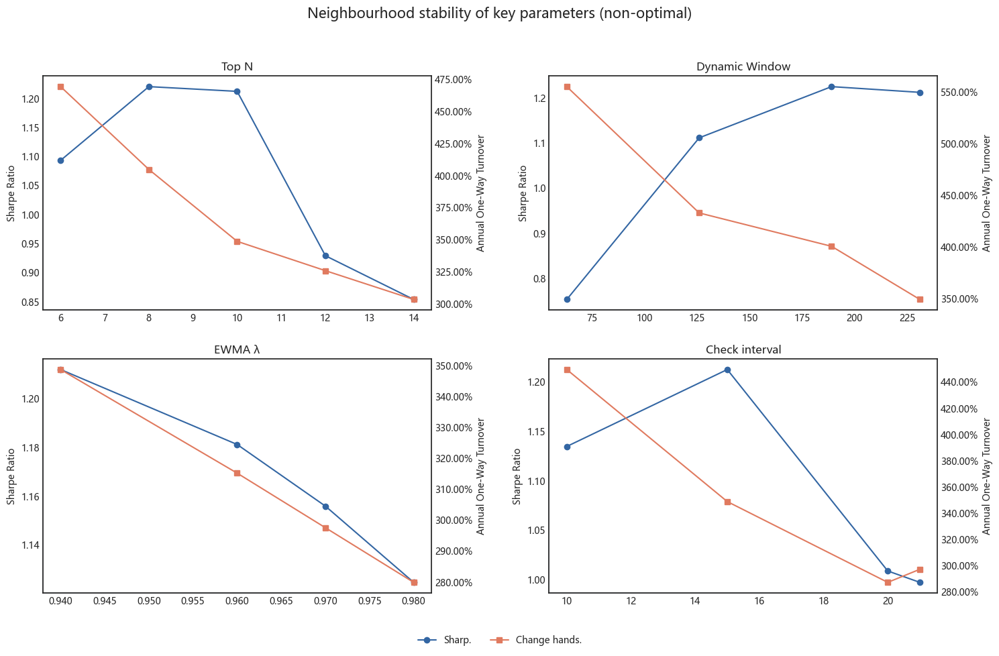

,sharp_minimum,sharp_maximum,sharp_s_standard_deviation,maximum_retreat_margin,minimal_exchange_rate,maximum_exchange_rate
Parameters,,,,,,
Check interval,0.997348,1.211959,0.103282,-0.153977,2.870782,4.494676
Dynamic Window,0.753101,1.224650,0.220667,-0.138315,3.487250,5.552589
EWMA λ,1.124547,1.211959,0.037153,-0.095896,2.798364,3.487250
Top N,0.853544,1.220097,0.165551,-0.235731,3.035140,4.690801


In [41]:
parameter_tests = {
    'Top N': [('Top N', value) for value in [6, 8, 10, 12, 14]],
    'Dynamic Window': [('Dynamic Window', value) for value in [63, 126, 189, LOOKBACK - MOMENTUM_SKIP]],
    'EWMA λ': [('EWMA λ', value) for value in [0.94, 0.96, 0.97, 0.98]],
    'Check interval': [('Check interval', value) for value in [10, 15, 20, 21]],
}

parameter_records = []
for dimension, settings in parameter_tests.items():
    for _, value in settings:
        kwargs = {
            'top_n': TOP_N, 'score_days': LOOKBACK - MOMENTUM_SKIP,
            'decay': EWMA_LAMBDA, 'check_interval': CHECK_INTERVAL,
        }
        if dimension == 'Top N':
            kwargs['top_n'] = int(value)
        elif dimension == 'Dynamic Window':
            kwargs['score_days'] = int(value)
        elif dimension == 'EWMA λ':
            kwargs['decay'] = float(value)
        elif dimension == 'Check interval':
            kwargs['check_interval'] = int(value)
        test_result = run_research_ewma_model(
            returns, ALL_ASSETS, strategy_start, **kwargs
        )
        metric = robustness_metrics(test_result)
        parameter_records.append({
            'Parameters': dimension, 'Parameter Value': value,
            'Cumulative Return': metric['Cumulative Return'], 'Annualized Return': metric['Annualized Return'],
            'Sharpe Ratio': metric['Sharpe Ratio'], 'Maximum Drawdown': metric['Maximum Drawdown'],
            'Annual One-Way Turnover': metric['Annual One-Way Turnover'],
        })

parameter_sensitivity = pd.DataFrame(parameter_records).set_index(['Parameters', 'Parameter Value'])
display(parameter_sensitivity.style.format({
    'Cumulative Return': '{:.2%}', 'Annualized Return': '{:.2%}', 'Sharpe Ratio': '{:.2f}',
    'Maximum Drawdown': '{:.2%}', 'Annual One-Way Turnover': '{:.2%}',
}))

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.ravel()
shared_handles = shared_labels = None
for ax, dimension in zip(axes, parameter_tests):
    view = parameter_sensitivity.xs(dimension)
    ax.plot(view.index.astype(float), view['Sharpe Ratio'], marker='o', linestyle='-', color='#3366A3', label='Sharp.')
    ax2 = ax.twinx()
    ax2.plot(view.index.astype(float), view['Annual One-Way Turnover'], marker='s', linestyle='-', color='#E07A5F', label='Change hands.')
    ax.set_title(dimension)
    ax.set_ylabel('Sharpe Ratio')
    ax2.set_ylabel('Annual One-Way Turnover')
    ax2.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=2))
    style_axis(ax)
    handles1, labels1 = ax.get_legend_handles_labels()
    handles2, labels2 = ax2.get_legend_handles_labels()
    if shared_handles is None:
        shared_handles = handles1 + handles2
        shared_labels = labels1 + labels2

fig.suptitle('Neighbourhood stability of key parameters (non-optimal)', fontsize=15, y=0.98)
fig.legend(
    shared_handles, shared_labels, loc='lower center', bbox_to_anchor=(0.5, 0.015),
    ncol=2, frameon=False, fontsize=10,
)
fig.tight_layout(rect=[0, 0.07, 1, 0.95], h_pad=2.2, w_pad=2.8)
plt.show()

parameter_stability_summary = parameter_sensitivity.groupby(level=0).agg(
    sharp_minimum=('Sharpe Ratio', 'min'), sharp_maximum=('Sharpe Ratio', 'max'),
    sharp_s_standard_deviation=('Sharpe Ratio', 'std'), maximum_retreat_margin=('Maximum Drawdown', 'min'),
    minimal_exchange_rate=('Annual One-Way Turnover', 'min'), maximum_exchange_rate=('Annual One-Way Turnover', 'max'),
)
display(parameter_stability_summary.style.format({
    'Sharp minimum': '{:.2f}', 'Sharp maximum': '{:.2f}', 'Sharp\'s standard deviation.': '{:.2f}',
    'Maximum retreat margin': '{:.2%}', 'Minimal exchange rate': '{:.2%}', 'Maximum exchange rate': '{:.2%}',
}))


### 7.4 Dynamic Risk-Budget Ablation


The digestion experiment uses the same inter-research and harmonized indicators to compare strictly EWMA ERC, single-layer dynamic budget, two layers of static categories, two layers of full dynamic and operational classification implementation. Since the single layer of dynamic and static categories are two different branches, the adjacent margin values in the table are used only to describe marginal changes and are not strictly causally explained.

In [42]:
ABLATION_STRATEGIES = [
    STRATEGY_NAMES['ewma_erc'],
    DYNAMIC_BUDGET_NAME,
    HIERARCHICAL_BUDGET_NAME,
    *CORE_COMPARISON_STRATEGIES,
]
ablation_table = pd.DataFrame({
    name: compute_metrics(results[name], strategy_start, RESEARCH_END)
    for name in ABLATION_STRATEGIES
}).T[[
    'Cumulative Return', 'Annualized Return', 'Annualized Volatility', 'Sharpe Ratio',
    'Maximum Drawdown', 'Annual One-Way Turnover', 'Number of Rebalances',
]]
ablation_table['Change over previous line of Sharp'] = ablation_table['Sharpe Ratio'].diff()
ablation_table['Change over previous line'] = ablation_table['Annual One-Way Turnover'].diff()
display(ablation_table.style.format({
    'Cumulative Return': '{:.2%}', 'Annualized Return': '{:.2%}', 'Annualized Volatility': '{:.2%}',
    'Sharpe Ratio': '{:.2f}', 'Maximum Drawdown': '{:.2%}', 'Annual One-Way Turnover': '{:.2%}',
    'Change over previous line of Sharp': '{:+.2f}', 'Change over previous line': '{:+.2%}',
    'Number of Rebalances': '{:.0f}',
}))


,Cumulative Return,Annualized Return,Annualized Volatility,Sharpe Ratio,Maximum Drawdown,Annual One-Way Turnover,Number of Rebalances,Change over previous line of Sharp,Change over previous line
Global Momentum EWMA Risk Parity (GMI-ERP),208.73%,10.53%,7.30%,1.23,-9.01%,341.40%,177,+nan,+nan%
Global Momentum Dynamic Risk Budget (GMI-DRB),223.95%,11.01%,7.52%,1.25,-9.48%,342.42%,183,+0.02,+1.01%
Global Momentum Static Hierarchical Risk Budget (GMI-SHRB),207.36%,10.49%,7.32%,1.22,-8.77%,377.83%,181,-0.03,+35.41%
Global Momentum Adaptive Hierarchical Risk Budget (GMI-AHRB),270.99%,12.35%,8.49%,1.26,-9.75%,397.89%,184,+0.04,+20.05%
Global Momentum Fixed Offensive Allocation (GMI-FOA),362.55%,14.57%,11.19%,1.15,-15.51%,446.31%,203,-0.10,+48.43%
Global Momentum Adaptive Defense and Growth (GMI-ADG),441.52%,16.19%,10.77%,1.32,-14.98%,342.17%,190,+0.17,-104.15%


### 7.5 Frozen-Rule Annual Walk-Forward Test


All policy rules and parameters are fixed and the study area is divided into a front-window for successive natural years. Each window evaluates only the current year ' s gains; the strategy still uses the previous 252-day historical signals before the window begins. The optimal parameters are not re-examined in each window, thus avoiding the duplication of annual evaluations. This test does not re-select parameters within each discount and is not equivalent to a full rolling training-valk-forward optimization.

Data from locked 2026-08-01 to 2026-10-01 are not included in this section. The first and last incomplete year is not used to determine the number of full-year wins.

,Median Annual Sharpe,Minimum Annual Sharpe,Positive-Year Ratio,Worst Annual Drawdown,Years Beating Benchmark Sharpe
Policy,,,,,
Global Momentum Adaptive Hierarchical Risk Budget (GMI-AHRB),1.48,-0.66,80.00%,-9.75%,60.00%
Global Multi-Asset Equal Weight (GMA-EW),1.23,-1.57,80.00%,-17.87%,0.00%
Global Momentum Adaptive Defense and Growth (GMI-ADG),1.23,-0.97,80.00%,-13.85%,60.00%
Global Momentum EWMA Risk Parity (GMI-ERP),1.18,-0.82,80.00%,-9.01%,60.00%
Global Multi-Asset Classic Risk Parity (GMA-CRP),1.09,-1.69,80.00%,-8.30%,20.00%
Global Momentum Fixed Offensive Allocation (GMI-FOA),1.05,-1.07,80.00%,-15.00%,50.00%


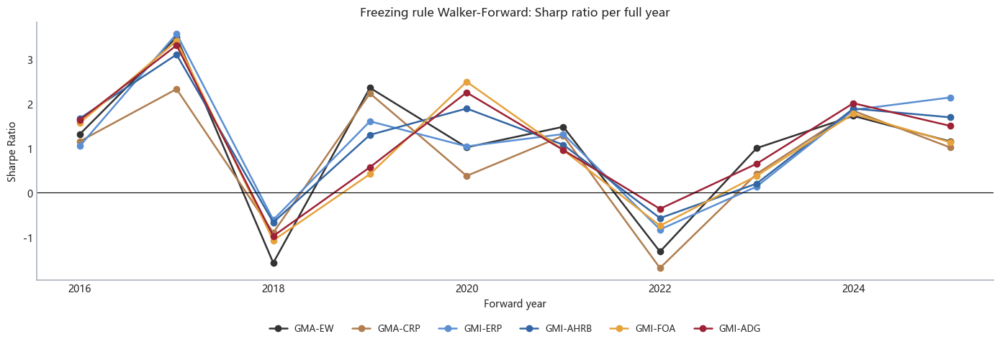

In [43]:
WALK_FORWARD_STRATEGIES = [
    BASELINE_STRATEGY, STATIC_CLASSIC_NAME, STRATEGY_NAMES['ewma_erc'],
    FULLY_DYNAMIC_BUDGET_NAME, CORE_ATTACK_NAME, DYNAMIC_ATTACK_NAME,
]
first_full_year = strategy_start.year + 1
last_full_year = RESEARCH_END.year - (RESEARCH_END.month < 12)
walk_forward_records = []
for year in range(first_full_year, last_full_year + 1):
    fold_start = pd.Timestamp(f'{year}-01-01')
    fold_end = min(pd.Timestamp(f'{year}-12-31'), RESEARCH_END)
    for strategy_name in WALK_FORWARD_STRATEGIES:
        metric = compute_metrics(results[strategy_name], fold_start, fold_end)
        walk_forward_records.append({
            'Forward year': year, 'Policy': strategy_name,
            'Cumulative Return': metric['Cumulative Return'], 'Sharpe Ratio': metric['Sharpe Ratio'],
            'Maximum Drawdown': metric['Maximum Drawdown'], 'Annual One-Way Turnover': metric['Annual One-Way Turnover'],
        })
walk_forward_metrics = pd.DataFrame(walk_forward_records).set_index(['Forward year', 'Policy'])
display(walk_forward_metrics.style.format({
    'Cumulative Return': '{:.2%}', 'Sharpe Ratio': '{:.2f}',
    'Maximum Drawdown': '{:.2%}', 'Annual One-Way Turnover': '{:.2%}',
}))

baseline_fold = walk_forward_metrics.xs(BASELINE_STRATEGY, level='Policy')['Sharpe Ratio']
walk_forward_summary = walk_forward_metrics.groupby(level='Policy').agg(**{
    'Median Annual Sharpe': ('Sharpe Ratio', 'median'),
    'Minimum Annual Sharpe': ('Sharpe Ratio', 'min'),
    'Positive-Year Ratio': ('Cumulative Return', lambda x: float((x > 0).mean())),
    'Worst Annual Drawdown': ('Maximum Drawdown', 'min'),
})
for strategy_name in WALK_FORWARD_STRATEGIES:
    strategy_fold = walk_forward_metrics.xs(strategy_name, level='Policy')['Sharpe Ratio']
    walk_forward_summary.loc[strategy_name, 'Years Beating Benchmark Sharpe'] = float(
        (strategy_fold > baseline_fold).mean()
    )
display(walk_forward_summary.sort_values('Median Annual Sharpe', ascending=False).style.format({
    'Median Annual Sharpe': '{:.2f}', 'Minimum Annual Sharpe': '{:.2f}',
    'Positive-Year Ratio': '{:.2%}', 'Worst Annual Drawdown': '{:.2%}',
    'Years Beating Benchmark Sharpe': '{:.2%}',
}))

walk_sharpe = walk_forward_metrics['Sharpe Ratio'].unstack('Policy')
walk_strategy_order = [name for name in WALK_FORWARD_STRATEGIES if name in walk_sharpe.columns]
walk_sharpe = walk_sharpe.reindex(columns=walk_strategy_order)
walk_plot = walk_sharpe.rename(columns=strategy_label)
ax = walk_plot.plot(
    figsize=(14, 6), marker='o', linewidth=1.8,
    color=[STRATEGY_COLORS[name] for name in walk_strategy_order],
)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title('Freezing rule Walker-Forward: Sharp ratio per full year')
ax.set_xlabel('Forward year')
ax.set_ylabel('Sharpe Ratio')
style_axis(ax)
place_legend(ax)
plt.tight_layout(rect=[0, 0.16, 1, 1])
plt.show()


### 7.6 Multifactor Alpha and the Deflated Sharpe Ratio


The return of ES3.SI or VT alone cannot be fully explained. This section adds four categories of total SSD return factors: global equities, US medium-term national debt, commodity basket and US dollar. Re-use SORA's excess earnings were wrong with the Newey-West standard and were only imputed ex post and did not enter the trading signal.

Deflad Sharpe has roughly revised the selection deviations resulting from the simultaneous comparison of 12 official strategies, taking into account the earnings bias and peak. Because of the high degree of relevance of the strategies, the statistics represent a conservative diagnosis rather than an accurate probability of independent testing.

In [44]:
from scipy.stats import norm, skew, kurtosis


def multifactor_alpha(result, start=strategy_start, end=RESEARCH_END):
    strategy = result['returns'].loc[start:end].rename('Policy')
    rf = result['risk_free_daily'].loc[start:end].rename('SORA')
    factors = pd.DataFrame({
        'Global equities': benchmark_returns_sgd['VT'].loc[start:end],
        'Medium-term national debt': returns['IEF'].loc[start:end],
        'Commodity basket': returns[['USO', 'DBB', 'GLD']].loc[start:end].mean(axis=1),
        'United States dollars': returns['UUP'].loc[start:end],
    })
    aligned = pd.concat([strategy, rf, factors], axis=1).dropna()
    y = aligned['Policy'] - aligned['SORA']
    x = aligned[factors.columns].sub(aligned['SORA'], axis=0)
    x = sm.add_constant(x)
    max_lags = max(1, int(4 * (len(aligned) / 100) ** (2 / 9)))
    model = sm.OLS(y, x).fit(cov_type='HAC', cov_kwds={'maxlags': max_lags})
    return pd.Series({
        'Yearic Multifactor Alpha': float(model.params['const'] * TRADING_DAYS),
        'Alpha t (HAC)': float(model.tvalues['const']),
        'Alpha p (HAC)': float(model.pvalues['const']),
        'Stock Beta': float(model.params['Global equities']),
        'Beta Bond': float(model.params['Medium-term national debt']),
        'Commodities Beta': float(model.params['Commodity basket']),
        'US$ Beta': float(model.params['United States dollars']),
        'Return to R2': float(model.rsquared),
    })


multifactor_alpha_table = pd.DataFrame({
    name: multifactor_alpha(results[name]) for name in final_strategy_names
}).T.sort_values('Yearic Multifactor Alpha', ascending=False)
display(multifactor_alpha_table.style.format({
    'Yearic Multifactor Alpha': '{:.2%}', 'Alpha t (HAC)': '{:.2f}',
    'Alpha p (HAC)': '{:.2f}', 'Stock Beta': '{:.2f}', 'Beta Bond': '{:.2f}',
    'Commodities Beta': '{:.2f}', 'US$ Beta': '{:.2f}', 'Return to R2': '{:.2f}',
}))


def deflated_sharpe_probability(result, trial_daily_sharpes):
    r = result['returns'].loc[strategy_start:RESEARCH_END].dropna()
    rf = result['risk_free_daily'].reindex(r.index)
    excess = (r - rf).dropna()
    daily_sr = float(excess.mean() / excess.std(ddof=1))
    trials = np.asarray(trial_daily_sharpes, dtype=float)
    trial_count = len(trials)
    if trial_count < 2 or not np.isfinite(trials).all():
        raise ValueError('Deflad Sharpe needs at least two limited candidate days.')
    trial_std = float(np.std(trials, ddof=1))
    euler_gamma = 0.5772156649015329
    trial_mean = float(np.mean(trials))
    expected_max = trial_mean + trial_std * (
        (1.0 - euler_gamma) * norm.ppf(1.0 - 1.0 / trial_count)
        + euler_gamma * norm.ppf(1.0 - 1.0 / (trial_count * np.e))
    )
    sample_skew = float(skew(excess, bias=False))
    sample_kurtosis = float(kurtosis(excess, fisher=False, bias=False))
    denominator = np.sqrt(max(
        1.0 - sample_skew * daily_sr
        + ((sample_kurtosis - 1.0) / 4.0) * daily_sr ** 2,
        1e-12,
    ))
    z_score = (daily_sr - expected_max) * np.sqrt(len(excess) - 1.0) / denominator
    return pd.Series({
        'General annual Sharp.': daily_sr * np.sqrt(TRADING_DAYS),
        'Multitest Base Day Sharp': expected_max,
        'Candidate strategy averaged Sharp': trial_mean,
        'Deflated Sharpe Probability': float(norm.cdf(z_score)),
        'Gain margin': sample_skew, 'Peak of return': sample_kurtosis,
        'Comparison of strategies': trial_count,
    })


trial_daily_sharpes = []
for name in final_strategy_names:
    r = results[name]['returns'].loc[strategy_start:RESEARCH_END].dropna()
    rf = results[name]['risk_free_daily'].reindex(r.index)
    trial_daily_sharpes.append(float((r - rf).mean() / (r - rf).std(ddof=1)))

deflated_sharpe_table = pd.DataFrame({
    name: deflated_sharpe_probability(results[name], trial_daily_sharpes)
    for name in final_strategy_names
}).T.sort_values('Deflated Sharpe Probability', ascending=False)
display(deflated_sharpe_table.style.format({
    'General annual Sharp.': '{:.2f}', 'Multitest Base Day Sharp': '{:.2f}',
    'Candidate strategy averaged Sharp': '{:.2f}',
    'Deflated Sharpe Probability': '{:.2%}', 'Gain margin': '{:.2f}', 'Peak of return': '{:.2f}',
    'Comparison of strategies': '{:.0f}',
}))


,Yearic Multifactor Alpha,Alpha t (HAC),Alpha p (HAC),Stock Beta,Beta Bond,Commodities Beta,US$ Beta,Return to R2
Global Momentum Adaptive Defense and Growth (GMI-ADG),11.47%,3.93,0.00,0.15,0.17,0.17,0.10,0.23
Global Momentum Fixed Offensive Allocation (GMI-FOA),10.04%,3.38,0.00,0.14,0.14,0.19,0.08,0.22
Global Momentum Adaptive Hierarchical Risk Budget (GMI-AHRB),8.12%,3.87,0.00,0.14,0.16,0.15,0.08,0.31
Global Momentum Dynamic Risk Budget (GMI-DRB),6.73%,3.69,0.00,0.18,0.12,0.10,0.07,0.36
Global Momentum Static Hierarchical Risk Budget (GMI-SHRB),6.38%,3.69,0.00,0.18,0.16,0.10,0.05,0.38
Global Momentum EWMA Risk Parity (GMI-ERP),6.28%,3.63,0.00,0.19,0.11,0.09,0.06,0.39
Global Momentum GARCH Risk Parity (GMI-GRP),5.30%,3.12,0.00,0.21,0.11,0.09,0.08,0.42
Global Momentum Classic Risk Parity (GMI-CRP),4.99%,3.01,0.00,0.22,0.11,0.10,0.08,0.44
Global Momentum Downside Risk Parity (GMI-DRP),4.70%,2.85,0.00,0.24,0.13,0.10,0.06,0.48
Global Momentum Inverse Volatility (GMI-IV),4.47%,2.79,0.01,0.27,0.12,0.09,0.05,0.53


,General annual Sharp.,Multitest Base Day Sharp,Candidate strategy averaged Sharp,Deflated Sharpe Probability,Gain margin,Peak of return,Comparison of strategies
Global Momentum Adaptive Defense and Growth (GMI-ADG),1.32,0.09,0.07,44.56%,0.03,8.96,12
Global Momentum Adaptive Hierarchical Risk Budget (GMI-AHRB),1.26,0.09,0.07,36.27%,-0.35,7.17,12
Global Momentum Dynamic Risk Budget (GMI-DRB),1.25,0.09,0.07,35.25%,-0.57,7.76,12
Global Momentum EWMA Risk Parity (GMI-ERP),1.23,0.09,0.07,32.65%,-0.61,8.05,12
Global Momentum Static Hierarchical Risk Budget (GMI-SHRB),1.22,0.09,0.07,31.47%,-0.49,7.51,12
Global Momentum Fixed Offensive Allocation (GMI-FOA),1.15,0.09,0.07,24.10%,-0.15,7.65,12
Global Momentum GARCH Risk Parity (GMI-GRP),1.10,0.09,0.07,19.54%,-0.65,8.68,12
Global Momentum Classic Risk Parity (GMI-CRP),1.05,0.09,0.07,15.32%,-0.67,8.84,12
Global Momentum Downside Risk Parity (GMI-DRP),1.01,0.09,0.07,12.22%,-0.63,8.53,12
Global Momentum Inverse Volatility (GMI-IV),1.00,0.09,0.07,11.37%,-0.66,8.78,12


### 7.7 Practical Tradability and Cost Boundaries

Formal master control is based on the unilateral use of 0.05 per cent transaction fees. Sub-market commissions, swaps, price differential slips, market shocks and withholding taxes serve only section 4.5 as stand-alone realistic cost scenarios and do not cover formal results. Parameters are a transparent research assumption and are not written-off by the history of the coupons. SORA cash gains are accounted for and the current strategy is not leveraged, so there are no financing costs.

In [45]:
tradability_limitations = pd.DataFrame({
    'Why can\'t we be reliable?': [
        'Formal master survey not separately listed; section 4.5 is recorded at a fixed rate in the currency of the transaction',
        'Formal master survey not listed; section 4.5 is based on market fixed price differential slide points Enter',
        'Formal master survey not separately listed; Section 4.5 modeled by ALV, Volatility and AUM',
        'Formal master survey not separately listed; section 4.5 is accounted for by annual asset tax negative agent',
    ],
    'Complete the data required for the model': [
        'FX quotes, real exchange transactions, cash accounts in currency',
        'Historical NBBO/order books, written-in and time stamp',
        'Target AUM, order size, ADV, participation rate and impact function calibration sample',
        'Accounts and tax status, place of registration, breakdown of funds and applicable tax rates',
    ],
    'Current processing': ['Independent reality', 'Independent reality', 'Independent reality', 'Independent reality'],
}, index=['FX Conversion Costs', 'Real trade price difference and slide point', 'Market Impact', 'Taxes and withholding taxes'])
display(tradability_limitations)


,Why can't we be reliable?,Complete the data required for the model,Current processing
FX Conversion Costs,Formal master survey not separately listed; se...,"FX quotes, real exchange transactions, cash ac...",Independent reality
Real trade price difference and slide point,Formal master survey not listed; section 4.5 i...,"Historical NBBO/order books, written-in and ti...",Independent reality
Market Impact,Formal master survey not separately listed; Se...,"Target AUM, order size, ADV, participation rat...",Independent reality
Taxes and withholding taxes,Formal master survey not separately listed; se...,"Accounts and tax status, place of registration...",Independent reality


# Part VIII. Performance Attribution

### 8.1 Credit calibration to daily reconciliation


This section starts with precise day-to-day attribution of the final submission strategy and ends with a single horizontal attribution of the three core strategies; no re-selection of parameters. The dynamic filter is fixed to **Top10** and the attribute range is up to the day before the outer starting point of the locked sample. All transaction signals continue to use data from the previous transaction date and earlier; attribution is an ex post interpretation tool and does not enter into transaction decision-making.

First, the daily weights are re-established and the net proceeds are broken down into gross asset gains, SORA cash gains, transaction cost agents, exchange costs and other accrued costs. The daily split must be closely reconciled with the net strategic gain. The use of geometrical links to aggregate contributions makes the sum of the contributions strictly equal to the benefits of the strategy, rather than simply adding the percentage per day.

In [46]:
ATTRIBUTION_STRATEGY = SUBMISSION_STRATEGY
attribution_result = results[ATTRIBUTION_STRATEGY]
ATTRIBUTION_START = strategy_start
ATTRIBUTION_END = RESEARCH_END


def build_daily_attribution_ledger(result, start, end):
    """Rebuild the weights before the transaction and generate daily contributions to the accounts; no data after the study area is read."""
    daily_return = result['returns'].loc[start:end].dropna()
    if daily_return.empty or daily_return.index.max() >= HOLDOUT_START:
        raise RuntimeError('Performance attribution is empty or beyond the point of departure of the lock test.')

    asset_columns = list(result['weights'].columns)
    if 'pre_return_weights' not in result or 'end_of_day_weights' not in result:
        raise RuntimeError('The results of the strategy lack real daily hold and cannot be accurately attributed.')
    pre_return_weights = result['pre_return_weights'].reindex(
        index=daily_return.index, columns=asset_columns, fill_value=0.0
    ).fillna(0.0)
    trade_deltas = result.get('trade_deltas', pd.DataFrame()).reindex(
        index=daily_return.index, columns=asset_columns, fill_value=0.0
    ).fillna(0.0)
    stored_cost = result['transaction_cost'].reindex(daily_return.index).fillna(0.0)
    stored_tax = result.get('withholding_tax_drag', pd.Series(0.0, index=daily_return.index)).reindex(
        daily_return.index
    ).fillna(0.0)
    stored_components = result.get('cost_components', pd.DataFrame()).reindex(
        index=daily_return.index,
        columns=['Commissions and transaction costs', 'FX Conversion Costs', 'Bid-Ask Spread and Slippage', 'Market Impact', 'Obsessed taxes'],
        fill_value=0.0,
    ).fillna(0.0)
    # The official master survey uses the unified unilateral 0.05 per cent. Full transaction costs if no real cost breakdown
    # The rest of the realistic cost components remain zero.
    missing_component_total = stored_components[
        ['Commissions and transaction costs', 'FX Conversion Costs', 'Bid-Ask Spread and Slippage', 'Market Impact']
    ].sum(axis=1).eq(0.0) & stored_cost.gt(0.0)
    stored_components.loc[missing_component_total, 'Commissions and transaction costs'] = stored_cost.loc[
        missing_component_total
    ]
    cash_return = result['risk_free_daily'].reindex(daily_return.index)
    if cash_return.isna().any():
        raise RuntimeError('The SORA-day gain during the performance attribution period was incomplete.')

    rows, weight_rows, trade_rows = [], [], []

    for date in daily_return.index:
        current_weights = pre_return_weights.loc[date].astype(float)
        delta = trade_deltas.loc[date].astype(float)
        if delta.abs().sum() > 1e-12:
            trade_rows.append(pd.Series(delta, name=date))

        day_asset_return = portfolio_returns_for_backtest.reindex(
            index=[date], columns=asset_columns
        ).iloc[0].fillna(0.0)
        cash_weight = float(result.get('cash_weight', pd.Series(dtype=float)).get(
            date, 1.0 - current_weights.sum()
        ))
        asset_contribution = current_weights * day_asset_return
        cash_contribution = cash_weight * float(cash_return.loc[date])
        gross_return = float(asset_contribution.sum() + cash_contribution)

        tax_drag = float(stored_tax.loc[date])
        after_tax_gross = gross_return - tax_drag
        cost_rate = float(stored_cost.loc[date])
        exact_cost_drag = (1.0 + after_tax_gross) * cost_rate
        raw_transaction_components = stored_components.loc[date, [
            'Commissions and transaction costs', 'FX Conversion Costs', 'Bid-Ask Spread and Slippage', 'Market Impact'
        ]]
        raw_total = float(raw_transaction_components.sum())
        if raw_total > 0:
            exact_transaction_components = exact_cost_drag * raw_transaction_components / raw_total
        else:
            exact_transaction_components = raw_transaction_components * 0.0

        row = asset_contribution.to_dict()
        row.update({
            'SORA Cash': cash_contribution,
            'Commissions and transaction costs': -float(exact_transaction_components['Commissions and transaction costs']),
            'FX Conversion Costs': -float(exact_transaction_components['FX Conversion Costs']),
            'Bid-Ask Spread and Slippage': -float(exact_transaction_components['Bid-Ask Spread and Slippage']),
            'Market Impact': -float(exact_transaction_components['Market Impact']),
            'Obsessed taxes': -tax_drag,
            'Other costed': 0.0,
        })
        rows.append(pd.Series(row, name=date))
        weight_rows.append(pd.Series({**current_weights.to_dict(), 'Cash': cash_weight}, name=date))

        reconstructed_net = after_tax_gross - exact_cost_drag
        if not np.isclose(reconstructed_net, float(daily_return.loc[date]), atol=1e-11, rtol=1e-9):
            raise RuntimeError(f'{date.date()}The attribution of proceeds was not reconciled with the net strategic gain.')
        if 1.0 + gross_return <= 0:
            raise RuntimeError(f'{date.date()}The combined gross proceeds resulted in a negative net value.')

    daily_components = pd.DataFrame(rows).fillna(0.0)
    pre_return_weights = pd.DataFrame(weight_rows).fillna(0.0)
    trades = pd.DataFrame(trade_rows).reindex(columns=asset_columns).fillna(0.0)
    reconciliation = daily_components.sum(axis=1) - daily_return
    if float(reconciliation.abs().max()) > 1e-10:
        raise RuntimeError('The day-to-day gains are attributed to errors in the reconciliation that go beyond tolerance.')
    return daily_components, pre_return_weights, trades, reconciliation


def geometrically_link_contributions(daily_components, total_returns):
    """Link the daily computational contribution to the total cumulative gain point."""
    aligned_components = daily_components.reindex(total_returns.index).fillna(0.0)
    total_returns = total_returns.reindex(aligned_components.index).astype(float)
    if not np.allclose(aligned_components.sum(axis=1), total_returns, atol=1e-10, rtol=1e-9):
        raise RuntimeError('Day-to-day contributions before geometric links cannot be reconciled with net gains.')
    wealth_after = (1.0 + total_returns).cumprod()
    wealth_before = wealth_after.shift(1, fill_value=1.0)
    terminal_wealth = float(wealth_after.iloc[-1])
    # W t-W_XQ1QXZZZ=W_X{t-1}r t, so that the cumulative income from the beginning of the period can be strictly increased by a net link.
    linked = aligned_components.mul(wealth_before, axis=0).sum(axis=0)
    if not np.isclose(float(linked.sum()), terminal_wealth - 1.0, atol=1e-9):
        raise RuntimeError('Accumulated revenue contributions cannot be reconciled with the cumulative benefit of the strategy.')
    return linked


daily_attribution, attribution_weights_daily, attribution_trades, _daily_reconciliation = build_daily_attribution_ledger(
    attribution_result, ATTRIBUTION_START, ATTRIBUTION_END
)
attribution_reconciliation = daily_attribution.sum(axis=1) - attribution_result['returns'].loc[
    ATTRIBUTION_START:ATTRIBUTION_END
]
attribution_audit = pd.DataFrame({
    'Value': [
        TOP_N, len(daily_attribution), attribution_reconciliation.abs().max(),
        attribution_result['returns'].loc[ATTRIBUTION_START:ATTRIBUTION_END].index.max(),
    ]
}, index=['Number of momentum filters', 'Number of transactions attributed', 'Maximum daily reconciliation error', 'Deadline for attribution'])
display(attribution_audit)


,Value
Number of momentum filters,10
Number of transactions attributed,2837
Maximum daily reconciliation error,0.00
Deadline for attribution,2026-07-31 00:00:00


### 8.2 Return Contribution by Asset and Asset Class


The contribution of assets is calculated using a daily weighting before the transaction and links the contribution after the compound gain to the end of the study. Positive is an increase in the final net value and negative is a drag on the final net value. The aggregation of categories and asset detail use the same set of lower-level contributions, so that the two tables can be reconciled with each other.

,Cumulative yield contribution (percentage points),End-of-cycle wealth contribution (SGD),Asset Name,Asset Class
BTC-USD,+149.62%,"+1,496,218",Bitcoin,Crypto
GLD,+85.93%,"+859,273",Gold,Commodities
ES3.SI,+52.53%,"+525,255",Straits Times Index,Equities
DBB,+28.82%,"+288,242",Industrial metals,Commodities
QQQ,+24.76%,"+247,580",NASDAQ 100,Equities
SPY,+18.13%,"+181,310",S&P 500,Equities
EXS1.DE,+14.75%,"+147,498","DAX, Germany",Equities
USO,+14.75%,"+147,487",Energy (oil),Commodities
1308.T,+14.66%,"+146,610",TOPIX,Equities
510300.SS,+13.42%,"+134,222",CSI 300,Equities


,Cumulative yield contribution (percentage points),End-of-cycle wealth contribution (SGD)
Asset Class,,
Equities,+164.58%,"+1,645,781"
Crypto,+149.62%,"+1,496,218"
Commodities,+129.50%,"+1,295,002"
FX,+10.50%,"+105,012"
Cash,+0.00%,+4
Bonds,-2.93%,"-29,298"
Trading Friction,-9.76%,"-97,553"


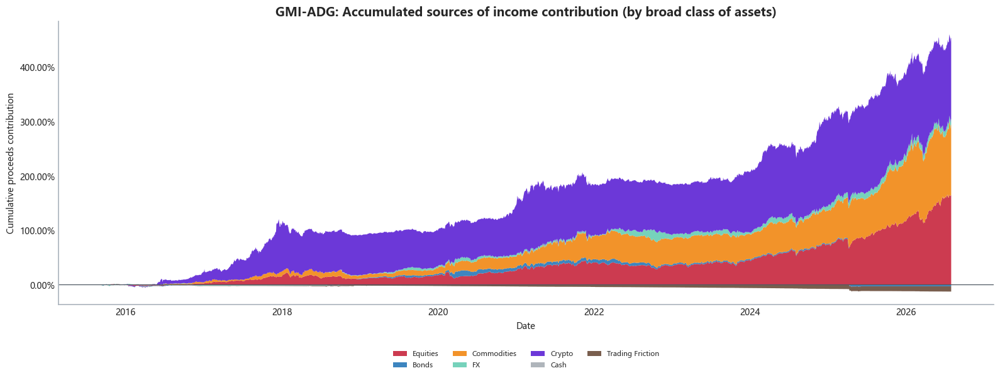

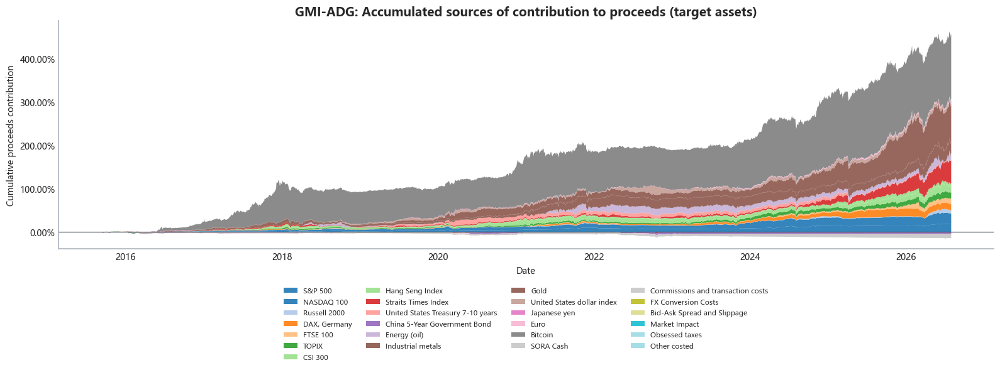

In [47]:
linked_asset_contribution = geometrically_link_contributions(
    daily_attribution,
    attribution_result['returns'].loc[ATTRIBUTION_START:ATTRIBUTION_END],
)

asset_contribution_table = pd.DataFrame({
    'Cumulative yield contribution (percentage points)': linked_asset_contribution,
    'End-of-cycle wealth contribution (SGD)': linked_asset_contribution * INITIAL_CAPITAL_SGD,
})
asset_contribution_table['Asset Name'] = [
    asset_metadata.loc[index, 'Asset Name'] if index in asset_metadata.index else index
    for index in asset_contribution_table.index
]
asset_contribution_table['Asset Class'] = [
    asset_metadata.loc[index, 'Asset Class'] if index in asset_metadata.index else (
        'Cash' if index == 'SORA Cash' else 'Trading Friction'
    )
    for index in asset_contribution_table.index
]
asset_contribution_table = asset_contribution_table.sort_values(
    'Cumulative yield contribution (percentage points)', ascending=False
)

class_contribution_table = asset_contribution_table.groupby('Asset Class', sort=False)[
    ['Cumulative yield contribution (percentage points)', 'End-of-cycle wealth contribution (SGD)']
].sum().sort_values('Cumulative yield contribution (percentage points)', ascending=False)
strategy_total_return = float(
    (1.0 + attribution_result['returns'].loc[ATTRIBUTION_START:ATTRIBUTION_END]).prod() - 1.0
)
if not np.isclose(class_contribution_table['Cumulative yield contribution (percentage points)'].sum(), strategy_total_return, atol=1e-9):
    raise RuntimeError('The contribution of category income was not reconciled with the cumulative benefit of the strategy.')

display(asset_contribution_table.style.format({
    'Cumulative yield contribution (percentage points)': '{:+.2%}', 'End-of-cycle wealth contribution (SGD)': '{:+,.0f}',
}))
display(class_contribution_table.style.format({
    'Cumulative yield contribution (percentage points)': '{:+.2%}', 'End-of-cycle wealth contribution (SGD)': '{:+,.0f}',
}))

def cumulative_linked_contribution_path(daily_components, total_returns):
    """Converts the daily computational contribution into a contribution path that can be aggregated on a day-to-day basis and at the end of the period consistent with the accumulated gain."""
    aligned_returns = total_returns.reindex(daily_components.index)
    wealth_before_return = (1.0 + aligned_returns).cumprod().shift(1).fillna(1.0)
    return daily_components.mul(wealth_before_return, axis=0).cumsum()


def plot_signed_stacked_contribution(frame, title, color_map, label_map=None):
    """is stacked from a zero-axis to a negative contribution to avoid a negative value being misread by the normal stacked area map."""
    label_map = label_map or {}
    columns = frame.columns.tolist()
    colors = [color_map.get(column, '#A7ADB4') for column in columns]
    labels = [label_map.get(column, column) for column in columns]
    positive = frame.clip(lower=0.0)
    negative = frame.clip(upper=0.0)
    fig, ax = plt.subplots(figsize=(16, 7.5))
    ax.stackplot(
        frame.index, *[positive[column].to_numpy(dtype=float) for column in columns],
        labels=labels, colors=colors, alpha=0.90,
    )
    ax.stackplot(
        frame.index, *[negative[column].to_numpy(dtype=float) for column in columns],
        labels=['_nolegend_'] * len(columns), colors=colors, alpha=0.90,
    )
    ax.axhline(0.0, color='#4F5963', linewidth=0.9)
    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.set_xlabel('Date')
    ax.set_ylabel('Cumulative proceeds contribution')
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f'{value:.2%}'))
    style_axis(ax, axis='y')
    place_legend(ax, item_count=len(columns))
    fig.tight_layout(rect=[0, 0.16 if len(columns) > 4 else 0, 1, 1])
    plt.show()


attribution_period_returns = attribution_result['returns'].loc[ATTRIBUTION_START:ATTRIBUTION_END]
asset_contribution_path = cumulative_linked_contribution_path(
    daily_attribution, attribution_period_returns
)
if not np.allclose(
    asset_contribution_path.iloc[-1].reindex(linked_asset_contribution.index),
    linked_asset_contribution, atol=1e-9,
):
    raise RuntimeError('The end value of the asset \' s cumulative contribution path was not reconciled with the attribution statement.')

contribution_class_lookup = {
    column: (asset_metadata.loc[column, 'Asset Class'] if column in asset_metadata.index
             else ('Cash' if column == 'SORA Cash' else 'Trading Friction'))
    for column in asset_contribution_path.columns
}
class_contribution_path = pd.DataFrame(index=asset_contribution_path.index)
for asset_class in dict.fromkeys(contribution_class_lookup.values()):
    members = [column for column, mapped_class in contribution_class_lookup.items()
               if mapped_class == asset_class]
    class_contribution_path[asset_class] = asset_contribution_path[members].sum(axis=1)

plot_signed_stacked_contribution(
    class_contribution_path,
    f'{strategy_label(ATTRIBUTION_STRATEGY)}: Accumulated sources of income contribution (by broad class of assets)',
    ASSET_CLASS_COLORS,
)

asset_palette = {
    column: plt.matplotlib.colors.to_hex(plt.cm.tab20(index / max(1, len(asset_contribution_path.columns) - 1)))
    for index, column in enumerate(asset_contribution_path.columns)
}
asset_label_map = {
    column: (asset_metadata.loc[column, 'Asset Name'] if column in asset_metadata.index else column)
    for column in asset_contribution_path.columns
}
plot_signed_stacked_contribution(
    asset_contribution_path,
    f'{strategy_label(ATTRIBUTION_STRATEGY)}: Accumulated sources of contribution to proceeds (target assets)',
    asset_palette,
    asset_label_map,
)


### 8.3 Incremental Contribution of Strategy Modules


This table compares the marginal changes in the module according to the fixed construction order: the equal rights baseline screens trends agilely balanced intelligence and sound mind agitation. The incrementality is the cumulative yield difference between counter-fact strategies that allows for an initial reconciliation but is affected by the order in which the modules are added, and therefore is not interpreted as the sole causal contribution.

,Module,Cumulative gains from this phase of the strategy,A step-by-step incremental contribution
Module Order,,,
1,GMA-EW,211.15%,+211.15%
2,Trends filter,330.55%,+119.40%
3,Agile balance.,208.73%,-121.82%
4,GMI-AHRB,270.99%,+62.27%
5,GMI-ADG,441.52%,+170.52%


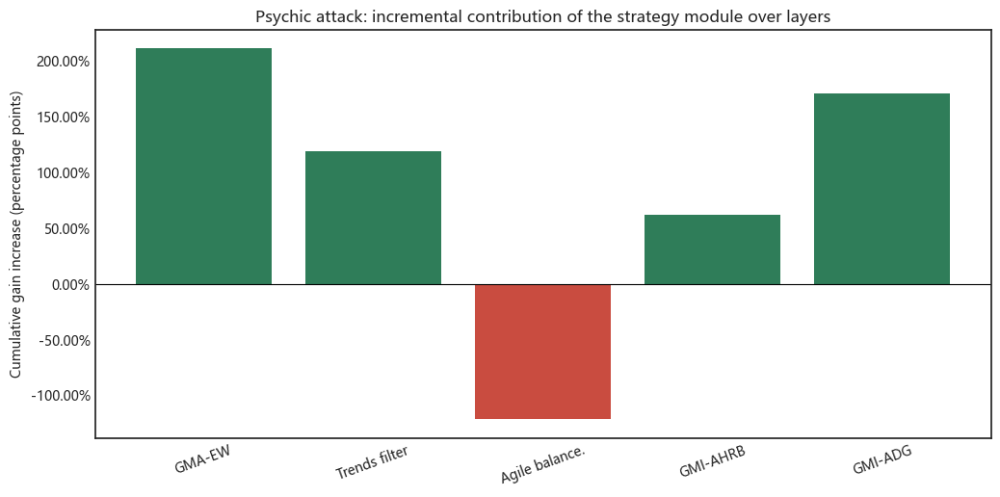

In [48]:
ATTRIBUTION_MOMENTUM_EQUAL_NAME = 'Dedicated: 12-1 month kinetic Top10, etc. Rights'


def target_momentum_12_1_equal(history):
    selected, score = select_top10(history)
    target = pd.Series(0.0, index=ALL_ASSETS, dtype=float)
    target.loc[selected] = 1.0 / len(selected)
    return target, selected, score


attribution_momentum_equal_result = run_dynamic_backtest(
    ATTRIBUTION_MOMENTUM_EQUAL_NAME, target_momentum_12_1_equal,
    covariance_function=None, end_date=RESEARCH_END,
)

module_sequence = [
    ('GMA-EW', results[STRATEGY_NAMES['equal_weight']]),
    ('Trends filter', attribution_momentum_equal_result),
    ('Agile balance.', results[STRATEGY_NAMES['ewma_erc']]),
    ('GMI-AHRB', results[FULLY_DYNAMIC_BUDGET_NAME]),
    ('GMI-ADG', results[DYNAMIC_ATTACK_NAME]),
]
module_rows = []
previous_total = 0.0
for order, (module_name, module_result) in enumerate(module_sequence):
    period_return = module_result['returns'].loc[ATTRIBUTION_START:ATTRIBUTION_END].dropna()
    total = float((1.0 + period_return).prod() - 1.0)
    increment = total if order == 0 else total - previous_total
    module_rows.append({
        'Module Order': order + 1, 'Module': module_name,
        'Cumulative gains from this phase of the strategy': total, 'A step-by-step incremental contribution': increment,
    })
    previous_total = total

module_attribution_table = pd.DataFrame(module_rows).set_index('Module Order')
if not np.isclose(
    module_attribution_table['A step-by-step incremental contribution'].sum(),
    module_attribution_table['Cumulative gains from this phase of the strategy'].iloc[-1], atol=1e-12,
):
    raise RuntimeError('The policy module increment failed to start the reconciliation.')
display(module_attribution_table.style.format({
    'Cumulative gains from this phase of the strategy': '{:.2%}', 'A step-by-step incremental contribution': '{:+.2%}',
}))

fig, ax = plt.subplots(figsize=(12, 5.5))
module_values = module_attribution_table['A step-by-step incremental contribution']
ax.bar(
    module_attribution_table['Module'], module_values,
    color=np.where(module_values >= 0, '#2F7D59', '#C94C40')
)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title('Psychic attack: incremental contribution of the strategy module over layers')
ax.set_ylabel('Cumulative gain increase (percentage points)')
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=2))
ax.tick_params(axis='x', rotation=20)
plt.show()


### 8.4 Factor Return Contribution and Residual Alpha


The current four-factor framework is followed: global equities, US medium-term national debt, commodity baskets and US dollars. The return was based on SORA as a risk-free gain, using the HAC standard wrongly. In addition to Beta, this section further disassemblys the daily strategic gains into SORA, four factors, regression distance Alpha and unexplained disability, and contributes to the cumulative gains by linking them to the same geometry as the asset attribution.

This is an ex post interpretation and does not participate in weight calculations; the “remnant Alpha” indicates that the average benefit for which the existing factor cannot be explained is not automatically equivalent to a sustainable projection capability.

,Beta/factor,Contribution of annual calculus benefits,Cumulative yield contribution (percentage points),HAC t,HAC p
SORA,nan,+1.33%,+44.83%,nan,nan
Global equities,0.15,+1.53%,+44.41%,nan,nan
Medium-term national debt,0.17,-0.16%,-7.84%,nan,nan
Commodity basket,0.17,+1.35%,+56.21%,nan,nan
United States dollars,0.10,+0.07%,+3.14%,nan,nan
Alpha Residual (Intersection),0.00,+11.47%,+333.60%,3.93,0.00
No explanation for disability,nan,-0.00%,-32.84%,nan,nan


Four factors back to R squared:0.23


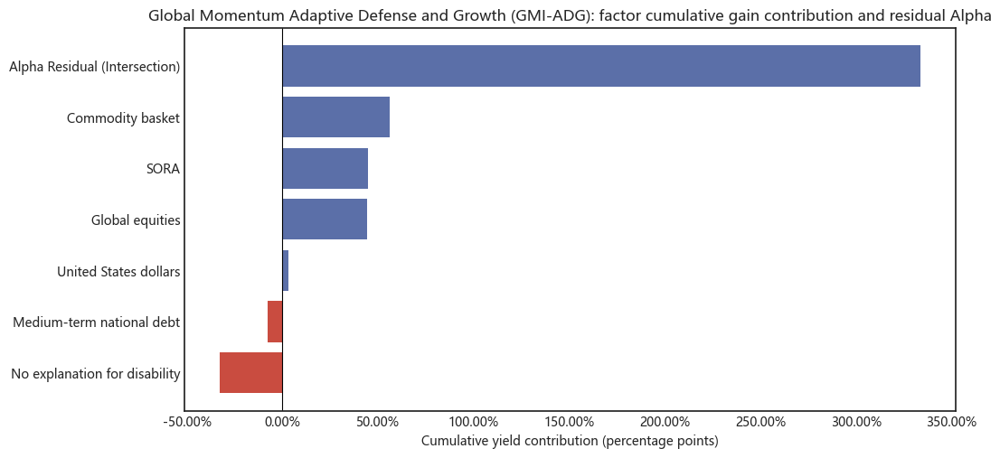

In [49]:
def factor_performance_attribution(result, start, end):
    strategy = result['returns'].loc[start:end].rename('Policy')
    rf = result['risk_free_daily'].loc[start:end].rename('SORA')
    factors = pd.DataFrame({
        'Global equities': benchmark_returns_sgd['VT'].loc[start:end],
        'Medium-term national debt': returns['IEF'].loc[start:end],
        'Commodity basket': returns[['USO', 'DBB', 'GLD']].loc[start:end].mean(axis=1),
        'United States dollars': returns['UUP'].loc[start:end],
    })
    aligned = pd.concat([strategy, rf, factors], axis=1).dropna()
    y = aligned['Policy'] - aligned['SORA']
    factor_excess = aligned[factors.columns].sub(aligned['SORA'], axis=0)
    design = sm.add_constant(factor_excess)
    max_lags = max(1, int(4 * (len(aligned) / 100) ** (2 / 9)))
    model = sm.OLS(y, design).fit(cov_type='HAC', cov_kwds={'maxlags': max_lags})

    daily = pd.DataFrame(index=aligned.index)
    daily['SORA'] = aligned['SORA']
    for factor_name in factors.columns:
        daily[factor_name] = float(model.params[factor_name]) * factor_excess[factor_name]
    daily['Alpha Residual (Intersection)'] = float(model.params['const'])
    daily['No explanation for disability'] = aligned['Policy'] - daily.sum(axis=1)
    if not np.allclose(daily.sum(axis=1), aligned['Policy'], atol=1e-11, rtol=1e-9):
        raise RuntimeError('It is not possible to reconcile with the strategic gain due to the daily break-up of the children.')

    linked = geometrically_link_contributions(daily, aligned['Policy'])
    annual_arithmetic = daily.mean() * TRADING_DAYS
    summary = pd.DataFrame({
        'Beta/factor': [
            np.nan if name in ['SORA', 'No explanation for disability'] else (
                float(model.params['const']) if name == 'Alpha Residual (Intersection)'
                else float(model.params[name])
            ) for name in daily.columns
        ],
        'Contribution of annual calculus benefits': annual_arithmetic,
        'Cumulative yield contribution (percentage points)': linked,
    }, index=daily.columns)
    summary.loc['Alpha Residual (Intersection)', 'HAC t'] = float(model.tvalues['const'])
    summary.loc['Alpha Residual (Intersection)', 'HAC p'] = float(model.pvalues['const'])
    return summary, daily, model


factor_attribution_table, factor_daily_contribution, factor_model = factor_performance_attribution(
    attribution_result, ATTRIBUTION_START, ATTRIBUTION_END
)
display(factor_attribution_table.style.format({
    'Beta/factor': '{:.2f}', 'Contribution of annual calculus benefits': '{:+.2%}',
    'Cumulative yield contribution (percentage points)': '{:+.2%}', 'HAC t': '{:.2f}', 'HAC p': '{:.2f}',
}))
print(f'Four factors back to R squared:{factor_model.rsquared:.2f}')

fig, ax = plt.subplots(figsize=(11, 5.5))
factor_plot = factor_attribution_table.sort_values('Cumulative yield contribution (percentage points)')
ax.barh(
    factor_plot.index, factor_plot['Cumulative yield contribution (percentage points)'],
    color=np.where(factor_plot['Cumulative yield contribution (percentage points)'] >= 0, '#5B6FA8', '#C94C40')
)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title(f'{ATTRIBUTION_STRATEGY}: factor cumulative gain contribution and residual Alpha')
ax.set_xlabel('Cumulative yield contribution (percentage points)')
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=2))
plt.show()


### 8.5 Trading-Friction Waterfall from Gross to Net Return

Using an independent, realistic cost copy of the final strategy, this section links the gross proceeds of assets and SORA cash proceeds to the actual net gains after the deduction of sub-market commissions, swaps, price differentials, square root market shocks and withholding taxes; and does not cover the formal result of the harmonization of 0.05 per cent.

,Cumulative yield contribution (percentage points),End-of-cycle wealth contribution (SGD)
Gross proceeds from assets,+408.19%,"+4,081,929"
SORA cash proceeds,+0.00%,+4
Commissions and transaction costs,-7.78%,"-77,789"
FX Conversion Costs,-19.91%,"-199,099"
Bid-Ask Spread and Slippage,-10.87%,"-108,656"
Market Impact,-1.20%,"-12,015"
Obsessed taxes,-4.31%,"-43,145"
Other costed,+0.00%,+0
Final net gain,+364.12%,"+3,641,229"


,Treatment,Model description and limitations,This falls caliber.
Commissions/transactions agents,A copy of the actual cost is accounted for by ...,Formal comparisons remain uniform at 0.05 per ...,Sub-market rates
FX Conversion Costs,A copy of the actual cost is recorded in the c...,The reality scenario uses a split-rate manual ...,Earmark rate
Real trade price difference and slide point,A copy of the actual cost is recorded on the m...,The reality scenario uses a market-based fixed...,Submarket agent
Market Impact,Actual cost copies are entered using square ro...,Use of square root impact models for delayed A...,Delay ADV square root model
Taxes and withholding taxes,A copy of the actual cost is presented on a da...,Use of asset-grade fixed annual tax negatives ...,Asset-grade agent
Financing Cost,SORA cash gains accounted for; no borrowing fo...,"Current strategy is unlevered and cashless, so...",Not applicable


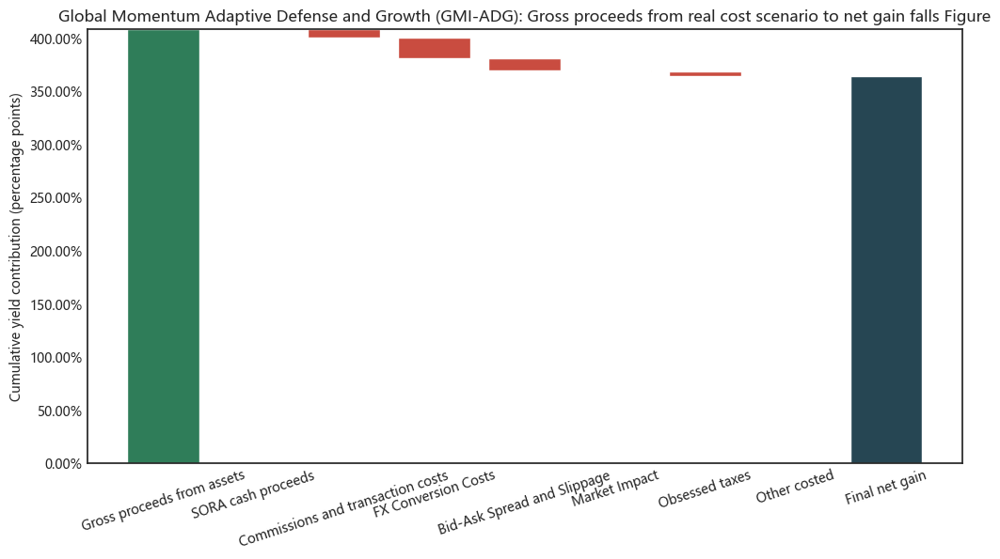

Performance attribution is completed: assets, categories, modules, factors and transaction wear and tear have been exported; daily reconciliation with accumulated gains is performed.


In [50]:
realistic_attribution_result = realistic_submission_result
realistic_daily_attribution, _, _, realistic_reconciliation_error = build_daily_attribution_ledger(
    realistic_attribution_result, ATTRIBUTION_START, ATTRIBUTION_END
)
asset_columns_for_attribution = [
    column for column in realistic_daily_attribution.columns
    if column in realistic_attribution_result['weights'].columns
]
wear_daily = pd.DataFrame(index=realistic_daily_attribution.index)
wear_daily['Gross proceeds from assets'] = realistic_daily_attribution[asset_columns_for_attribution].sum(axis=1)
wear_daily['SORA cash proceeds'] = realistic_daily_attribution['SORA Cash']
wear_daily['Commissions and transaction costs'] = realistic_daily_attribution['Commissions and transaction costs']
wear_daily['FX Conversion Costs'] = realistic_daily_attribution['FX Conversion Costs']
wear_daily['Bid-Ask Spread and Slippage'] = realistic_daily_attribution['Bid-Ask Spread and Slippage']
wear_daily['Market Impact'] = realistic_daily_attribution['Market Impact']
wear_daily['Obsessed taxes'] = realistic_daily_attribution['Obsessed taxes']
wear_daily['Other costed'] = realistic_daily_attribution['Other costed']

wear_linked = geometrically_link_contributions(
    wear_daily,
    realistic_attribution_result['returns'].loc[ATTRIBUTION_START:ATTRIBUTION_END],
)
wear_attribution_table = pd.DataFrame({
    'Cumulative yield contribution (percentage points)': wear_linked,
    'End-of-cycle wealth contribution (SGD)': wear_linked * INITIAL_CAPITAL_SGD,
})
wear_attribution_table.loc['Final net gain', 'Cumulative yield contribution (percentage points)'] = wear_linked.sum()
wear_attribution_table.loc['Final net gain', 'End-of-cycle wealth contribution (SGD)'] = (
    wear_linked.sum() * INITIAL_CAPITAL_SGD
)
display(wear_attribution_table.style.format({
    'Cumulative yield contribution (percentage points)': '{:+.2%}', 'End-of-cycle wealth contribution (SGD)': '{:+,.0f}',
}))

friction_coverage = pd.DataFrame({
    'Treatment': [
        'A copy of the actual cost is accounted for by market.', 'A copy of the actual cost is recorded in the currency of the transaction',
        'A copy of the actual cost is recorded on the market', 'Actual cost copies are entered using square root models',
        'A copy of the actual cost is presented on a daily basis by the annual agent of the asset', 'SORA cash gains accounted for; no borrowing for current non-leveraging strategy',
    ],
    'Model description and limitations': [
        'Formal comparisons remain uniform at 0.05 per cent; copies of stand-alone realistic costs are used in the Falls map',
        'The reality scenario uses a split-rate manual rate that does not pretend to be a real exchange of history.',
        'The reality scenario uses a market-based fixed agent, Yahoo has no historical order book',
        'Use of square root impact models for delayed ADV and volatility in realistic scenarios',
        'Use of asset-grade fixed annual tax negatives in realistic scenarios',
        'Current strategy is unlevered and cashless, so no borrowing takes place; future leverage needs to be added to SORA floating financing Bad',
    ],
    'This falls caliber.': ['Sub-market rates', 'Earmark rate', 'Submarket agent', 'Delay ADV square root model', 'Asset-grade agent', 'Not applicable'],
}, index=['Commissions/transactions agents', 'FX Conversion Costs', 'Real trade price difference and slide point', 'Market Impact', 'Taxes and withholding taxes', 'Financing Cost'])
display(friction_coverage)

waterfall_items = ['Gross proceeds from assets', 'SORA cash proceeds', 'Commissions and transaction costs', 'FX Conversion Costs', 'Bid-Ask Spread and Slippage', 'Market Impact', 'Obsessed taxes', 'Other costed']
waterfall_labels = [
    'Gross proceeds from assets', 'SORA cash proceeds', 'Commissions and transaction costs', 'FX Conversion Costs',
    'Bid-Ask Spread and Slippage', 'Market Impact', 'Obsessed taxes', 'Other costed',
]
increments = wear_linked.reindex(waterfall_items).fillna(0.0)
starts = increments.cumsum().shift(1, fill_value=0.0)
fig, ax = plt.subplots(figsize=(12, 6))
ax.bar(
    waterfall_labels, increments, bottom=starts,
    color=np.where(increments >= 0, '#2F7D59', '#C94C40'), edgecolor='white'
)
ax.bar(
    ['Final net gain'], [increments.sum()],
    color='#264653', edgecolor='white'
)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title(f'{ATTRIBUTION_STRATEGY}: Gross proceeds from real cost scenario to net gain falls Figure')
ax.set_ylabel('Cumulative yield contribution (percentage points)')
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=2))
ax.tick_params(axis='x', rotation=18)
plt.show()

assert TOP_N == 10, 'The official momentum filter must be Top10.'
assert daily_attribution.index.max() < HOLDOUT_START, 'Performance attribution does not allow access to locked test data.'
assert np.isclose(
    wear_attribution_table.loc['Final net gain', 'Cumulative yield contribution (percentage points)'],
    float((1.0 + realistic_attribution_result['returns'].loc[
        ATTRIBUTION_START:ATTRIBUTION_END
    ]).prod() - 1.0), atol=1e-9,
), 'Real cost wear waterfalls were not reconciled with real net gains.'
assert realistic_reconciliation_error.abs().max() <= 1e-10
print('Performance attribution is completed: assets, categories, modules, factors and transaction wear and tear have been exported; daily reconciliation with accumulated gains is performed.')


### 8.6 Extended Attribution: Bitcoin, Gold, Country, Momentum, and Dynamic Budgets


The base 4 factor model is used to provide a stable, interpretable reference; this section further disassembly the proceeds previously classified as residual Alpha. Extension models added:

1. **bitcoin, gold, energy, industrial metal factors**: avoid mixing different commodity risks into a basket;
** Relative national and regional factors**: the United States, Europe, Japan, China/Hong Kong and Singapore use “regional equity gains - global equity gains” to reduce duplication with global stocks Beta;
3. **Multi-asset momentum style factor**: use of 12-1 months of earnings up to the signal date, execution on the next transaction date, 1/3 more, 1/3 less;
4. ** Non-linear stock selection factor**: test of Treynor-Mazuy junction selection using global equity excess yield squares minus historical expansion averages;
5. ** Dynamic risk budget incremental factor**: the incremental interaction of internal budget rules is measured using a fully dynamic two-tiered risk budget strategy less the benefit of the static two-tiered risk budget strategy over the same period.

Regional, dynamic and dynamic budget factors are explanatory agents. The extended regression may be co-linear, so that both the correlation and condition numbers are exported; the factor contribution is a statistical interpretation and is not equivalent to a defined causal link.

In [51]:
def build_delayed_multi_asset_momentum_factor(return_frame, start, end):
    """Constructs a multi-assets motor multiple factor before cost without future information."""
    frame = return_frame.loc[:end, ALL_ASSETS].copy()
    dates = frame.loc[start:end].index
    long_assets, short_assets = [], []
    pending_signal = None
    records = []
    start_position = frame.index.get_loc(dates[0])
    group_size = max(1, len(ALL_ASSETS) // 3)

    for date in dates:
        position = frame.index.get_loc(date)

        day_return = frame.loc[date]
        factor_return = 0.0
        if long_assets and short_assets:
            factor_return = float(
                day_return[long_assets].mean() - day_return[short_assets].mean()
            )
        records.append((date, factor_return))

        # Orders formed on the closing date of the previous transaction and executed on the closing date,
        # The new multi-empty combination begins to yield benefits between the next closing and closing slots.
        if pending_signal is not None:
            if not pending_signal['Signal Date'] < date:
                raise RuntimeError('The kinetic style factor is active on the signal day.')
            long_assets = pending_signal['Multiple']
            short_assets = pending_signal['Empty']
            pending_signal = None

        if (position - start_position) % CHECK_INTERVAL == 0 and pending_signal is None:
            history = frame.iloc[position - LOOKBACK + 1:position + 1]
            if len(history) != LOOKBACK or history.index.max() != date:
                raise RuntimeError('The momentum style factor historical window does not strictly close to the signal day closing or insufficient length.')
            score = momentum_12_1(history)
            pending_signal = {
                'Signal Date': date,
                'Multiple': score.nlargest(group_size).index.tolist(),
                'Empty': score.nsmallest(group_size).index.tolist(),
            }

    factor = pd.Series(dict(records), name='Multi-asset momentum', dtype=float)
    if factor.index.max() >= HOLDOUT_START:
        raise RuntimeError('The kinetic style factor reads the locking out data.')
    return factor


def build_expanded_attribution_factors(result, start, end):
    strategy_index = result['returns'].loc[start:end].dropna().index
    rf = result['risk_free_daily'].reindex(strategy_index)
    if rf.isna().any():
        raise RuntimeError('Extension factor attribution SORA coverage is incomplete.')

    world = benchmark_returns_sgd['VT'].reindex(strategy_index)
    us_equity = returns[['SPY', 'QQQ', 'IWM']].reindex(strategy_index).mean(axis=1)
    europe_equity = returns[['EXS1.DE', 'ISF.L']].reindex(strategy_index).mean(axis=1)
    japan_equity = returns['1308.T'].reindex(strategy_index)
    greater_china = returns[['510300.SS', '2800.HK']].reindex(strategy_index).mean(axis=1)
    singapore_equity = returns['ES3.SI'].reindex(strategy_index)

    factor_frame = pd.DataFrame(index=strategy_index)
    factor_frame['Global equities'] = world - rf
    factor_frame['United States relative global'] = us_equity - world
    factor_frame['Europe relative global'] = europe_equity - world
    factor_frame['Japan relative global'] = japan_equity - world
    factor_frame['Hong Kong, China, relative global'] = greater_china - world
    factor_frame['Singapore relative global'] = singapore_equity - world
    factor_frame['US Medium Term National Debt'] = returns['IEF'].reindex(strategy_index) - rf
    factor_frame['Gold'] = returns['GLD'].reindex(strategy_index) - rf
    factor_frame['Energy'] = returns['USO'].reindex(strategy_index) - rf
    factor_frame['Industrial metals'] = returns['DBB'].reindex(strategy_index) - rf
    factor_frame['United States dollars'] = returns['UUP'].reindex(strategy_index) - rf
    factor_frame['Bitcoin.'] = returns['BTC-USD'].reindex(strategy_index) - rf
    factor_frame['Multi-asset momentum'] = build_delayed_multi_asset_momentum_factor(
        returns, start, end
    ).reindex(strategy_index)

    # Only the averages of current market returns and expansions up to the previous day are used and future averages are not read.
    market_square = factor_frame['Global equities'].pow(2)
    historical_square_mean = market_square.expanding(min_periods=2).mean().shift(1)
    factor_frame['Non-linear stock selection'] = (
        market_square - historical_square_mean
    ).fillna(0.0)

    dynamic_return = results[SUBMISSION_STRATEGY]['returns'].reindex(strategy_index)
    static_return = results[HIERARCHICAL_BUDGET_NAME]['returns'].reindex(strategy_index)
    factor_frame['Dynamic risk budget increment'] = dynamic_return - static_return

    if factor_frame.isna().any().any():
        missing = factor_frame.columns[factor_frame.isna().any()].tolist()
        raise RuntimeError(f'Extension factor is missing:{missing}')
    return factor_frame, rf


expanded_factor_returns, expanded_factor_rf = build_expanded_attribution_factors(
    attribution_result, ATTRIBUTION_START, ATTRIBUTION_END
)

expanded_factor_definition = pd.DataFrame({
    'Type': [
        'Market', 'Country/area', 'Country/area', 'Country/area', 'Country/area', 'Country/area',
        'Asset class', 'Asset class', 'Asset class', 'Asset class', 'Asset class', 'Asset class',
        'Style', 'Non-linear', 'Internal policy interaction',
    ],
    'Definition Summary': [
        'VT－SORA', 'United States stock basket-VT', 'European stock basket - VT', 'TOPIX－VT',
        'China/Hong Kong stock basket-VT', 'ES3.SI－VT', 'IEF－SORA', 'GLD－SORA',
        'USO－SORA', 'DBB－SORA', 'UUP－SORA', 'BTC-USD－SORA',
        '12-1 months of winners and losers behind schedule', 'Global Equities Excessed Earnings Zero minus Historical Growth Average',
        'Full dynamic double budget gains -- static double budget gains',
    ],
}, index=expanded_factor_returns.columns)
display(expanded_factor_definition)


,Type,Definition Summary
Global equities,Market,VT－SORA
United States relative global,Country/area,United States stock basket-VT
Europe relative global,Country/area,European stock basket - VT
Japan relative global,Country/area,TOPIX－VT
"Hong Kong, China, relative global",Country/area,China/Hong Kong stock basket-VT
Singapore relative global,Country/area,ES3.SI－VT
US Medium Term National Debt,Asset class,IEF－SORA
Gold,Asset class,GLD－SORA
Energy,Asset class,USO－SORA
Industrial metals,Asset class,DBB－SORA


### 8.6.1 Extended Factor Contribution, Residual Alpha, and Identification Diagnostics


The return is still based on the daily excess gains of the strategy relative to SORA as a variable and using the HAC standard error. The proposed daily income is broken down into SORA, extension factors, cut-off alpha and unexplained disability, and the net opening link is used to contribute to the aggregate cumulative income. The “remnant Alpha” in the table below is the cut-off after the control of these extension factors, rather than the unconditional guarantee of future sustainable gains.

,Beta/factor,Contribution of annual calculus benefits,Cumulative yield contribution (percentage points),HAC t,HAC p
Attribution,,,,,
SORA,nan,+1.33%,+44.83%,nan,nan
Global equities,0.30,+3.15%,+91.59%,9.22,0.00
United States relative global,0.10,+0.30%,+7.48%,2.27,0.02
Europe relative global,0.07,-0.36%,-7.92%,6.49,0.00
Japan relative global,0.07,-0.16%,-2.92%,8.12,0.00
"Hong Kong, China, relative global",0.08,-0.52%,-14.97%,9.59,0.00
Singapore relative global,0.05,-0.07%,+2.20%,3.01,0.00
US Medium Term National Debt,0.18,-0.17%,-8.50%,4.91,0.00
Gold,0.09,+0.92%,+30.47%,8.27,0.00


,Value
Effective trading date,2837.00
Number of extended factors,15.00
Return R Square,0.87
Adjusted R Square,0.86
Number of conditions (after standardization),4.84
Maximum factor absolute correlation factor,0.76
The legacy of Alpha's annual calculus contribution,0.03
Residual Alpha HAC t,2.45
Residual Alpha HAC p,0.01


,Base 4 factor model,Extension Factor Model,Extension model changes
Return R Square,0.23,0.87,0.64
The legacy of Alpha's annual calculus contribution,0.11,0.03,-0.09
Alpha HAC t,3.93,2.45,-1.48
Alpha HAC p,0.00,0.01,0.01


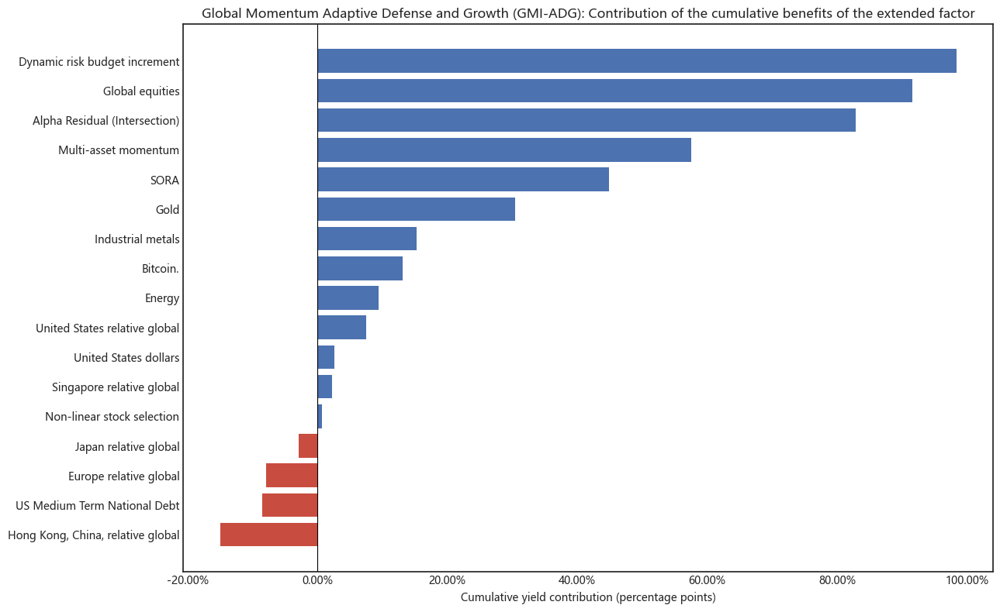

Extension factor attribution is complete: cumulative contribution is reconciled with strategic net gain and off-species is locked.


In [52]:
def expanded_factor_performance_attribution(result, factor_frame, rf, start, end):
    strategy = result['returns'].loc[start:end].rename('Policy').reindex(factor_frame.index)
    aligned = pd.concat([strategy, rf.rename('SORA'), factor_frame], axis=1).dropna()
    y = aligned['Policy'] - aligned['SORA']
    x = aligned[factor_frame.columns]
    design = sm.add_constant(x)
    max_lags = max(1, int(4 * (len(aligned) / 100) ** (2 / 9)))
    model = sm.OLS(y, design).fit(cov_type='HAC', cov_kwds={'maxlags': max_lags})

    daily = pd.DataFrame(index=aligned.index)
    daily['SORA'] = aligned['SORA']
    for factor_name in factor_frame.columns:
        daily[factor_name] = float(model.params[factor_name]) * aligned[factor_name]
    daily['Alpha Residual (Intersection)'] = float(model.params['const'])
    daily['No explanation for disability'] = aligned['Policy'] - daily.sum(axis=1)
    if not np.allclose(daily.sum(axis=1), aligned['Policy'], atol=1e-11, rtol=1e-9):
        raise RuntimeError('The daily contribution of the extended factor was not reconciled with the strategic gain.')

    linked = geometrically_link_contributions(daily, aligned['Policy'])
    annual_arithmetic = daily.mean() * TRADING_DAYS
    rows = []
    for name in daily.columns:
        if name == 'SORA' or name == 'No explanation for disability':
            coefficient = t_value = p_value = np.nan
        elif name == 'Alpha Residual (Intersection)':
            coefficient = float(model.params['const'])
            t_value = float(model.tvalues['const'])
            p_value = float(model.pvalues['const'])
        else:
            coefficient = float(model.params[name])
            t_value = float(model.tvalues[name])
            p_value = float(model.pvalues[name])
        rows.append({
            'Attribution': name, 'Beta/factor': coefficient,
            'Contribution of annual calculus benefits': annual_arithmetic[name],
            'Cumulative yield contribution (percentage points)': linked[name],
            'HAC t': t_value, 'HAC p': p_value,
        })
    summary = pd.DataFrame(rows).set_index('Attribution')

    standardized = (x - x.mean()) / x.std(ddof=1).replace(0.0, np.nan)
    standardized = standardized.dropna(axis=1, how='any')
    condition_number = float(np.linalg.cond(standardized.values))
    correlation = x.corr()
    off_diagonal = correlation.where(~np.eye(len(correlation), dtype=bool))
    maximum_correlation = float(off_diagonal.abs().max().max())
    diagnostics = pd.Series({
        'Effective trading date': len(aligned), 'Number of extended factors': len(factor_frame.columns),
        'Return R Square': float(model.rsquared), 'Adjusted R Square': float(model.rsquared_adj),
        'Number of conditions (after standardization)': condition_number,
        'Maximum factor absolute correlation factor': maximum_correlation,
        'The legacy of Alpha\'s annual calculus contribution': float(model.params['const'] * TRADING_DAYS),
        'Residual Alpha HAC t': float(model.tvalues['const']),
        'Residual Alpha HAC p': float(model.pvalues['const']),
    })
    return summary, daily, model, diagnostics, correlation


(
    expanded_factor_attribution_table,
    expanded_factor_daily_contribution,
    expanded_factor_model,
    expanded_factor_diagnostics,
    expanded_factor_correlation,
) = expanded_factor_performance_attribution(
    attribution_result, expanded_factor_returns, expanded_factor_rf,
    ATTRIBUTION_START, ATTRIBUTION_END,
)

display(expanded_factor_attribution_table.style.format({
    'Beta/factor': '{:.2f}', 'Contribution of annual calculus benefits': '{:+.2%}',
    'Cumulative yield contribution (percentage points)': '{:+.2%}',
    'HAC t': '{:.2f}', 'HAC p': '{:.2f}',
}))
display(expanded_factor_diagnostics.to_frame('Value').style.format({
    'Value': '{:.2f}',
}))

basic_alpha = float(factor_model.params['const'] * TRADING_DAYS)
expanded_alpha = float(expanded_factor_model.params['const'] * TRADING_DAYS)
model_comparison = pd.DataFrame({
    'Base 4 factor model': [
        factor_model.rsquared, basic_alpha,
        factor_model.tvalues['const'], factor_model.pvalues['const'],
    ],
    'Extension Factor Model': [
        expanded_factor_model.rsquared, expanded_alpha,
        expanded_factor_model.tvalues['const'], expanded_factor_model.pvalues['const'],
    ],
}, index=['Return R Square', 'The legacy of Alpha\'s annual calculus contribution', 'Alpha HAC t', 'Alpha HAC p'])
model_comparison['Extension model changes'] = (
    model_comparison['Extension Factor Model'] - model_comparison['Base 4 factor model']
)
display(model_comparison.style.format('{:.2f}'))

plot_table = expanded_factor_attribution_table.drop(index='No explanation for disability').sort_values(
    'Cumulative yield contribution (percentage points)'
)
fig, ax = plt.subplots(figsize=(13, 8))
colors = np.where(plot_table['Cumulative yield contribution (percentage points)'] >= 0, '#4C72B0', '#C94C40')
ax.barh(plot_table.index, plot_table['Cumulative yield contribution (percentage points)'], color=colors)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title(f'{ATTRIBUTION_STRATEGY}: Contribution of the cumulative benefits of the extended factor')
ax.set_xlabel('Cumulative yield contribution (percentage points)')
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=2))
plt.tight_layout()
plt.show()

assert expanded_factor_returns.index.max() < HOLDOUT_START, 'The extended factor reads lock test data.'
assert np.isclose(
    expanded_factor_attribution_table['Cumulative yield contribution (percentage points)'].sum(),
    strategy_total_return, atol=1e-9,
), 'The cumulative contribution of the expansion factor was not reconciled with the strategy \' s net gain.'
print('Extension factor attribution is complete: cumulative contribution is reconciled with strategic net gain and off-species is locked.')


### 8.7 Exact Decomposition of Local-Asset and Currency Returns


The previous section explains the contribution of assets in terms of total SGD returns, but no distinction has been made between the local market performance of assets and exchange rate changes. This section uses constant equations

\[
1+r^{SGD}_{i,t}=(1+r^{local}_{i,t})(1+r^{FX}_{i,t})
\]

The SSD proceeds for each asset are accurately broken down into “local asset gains, exchange rate gains, local income x exchange rate gains interaction items”. The inclusion of SORA cash proceeds and transaction costs is closely reconciled with the strategic net proceeds on a daily and cumulative basis. The split is accounting attribution and is not interpreted as a duplicate Alpha contribution.

,Cumulative yield contribution (percentage points),End-of-cycle wealth contribution (SGD)
Local asset price gains,+483.69%,"+4,836,888"
Exchange rate conversion gains,-31.83%,"-318,337"
Local income x exchange rate interaction,-0.58%,"-5,835"
SORA Cash,+0.00%,+4
Commissions and transaction costs,-9.76%,"-97,553"
FX Conversion Costs,+0.00%,+0
Bid-Ask Spread and Slippage,+0.00%,+0
Market Impact,+0.00%,+0
Obsessed taxes,+0.00%,+0
Other costed,+0.00%,+0


,Local market contributions,Contribution of exchange rates,Interactive contributions,Total SGD asset contribution,Local Currency,Asset Name
BTC-USD,+151.21%,-1.89%,+0.30%,+149.62%,USD,Bitcoin
GLD,+90.99%,-5.03%,-0.03%,+85.93%,USD,Gold
ES3.SI,+52.53%,+0.00%,+0.00%,+52.53%,SGD,Straits Times Index
DBB,+30.67%,-1.85%,+0.01%,+28.82%,USD,Industrial metals
QQQ,+24.28%,+0.50%,-0.03%,+24.76%,USD,NASDAQ 100
SPY,+18.80%,-0.65%,-0.02%,+18.13%,USD,S&P 500
EXS1.DE,+12.17%,+2.60%,-0.03%,+14.75%,EUR,"DAX, Germany"
USO,+12.22%,+2.56%,-0.03%,+14.75%,USD,Energy (oil)
1308.T,+22.55%,-7.44%,-0.45%,+14.66%,JPY,TOPIX
510300.SS,+10.66%,+2.87%,-0.11%,+13.42%,CNY,CSI 300


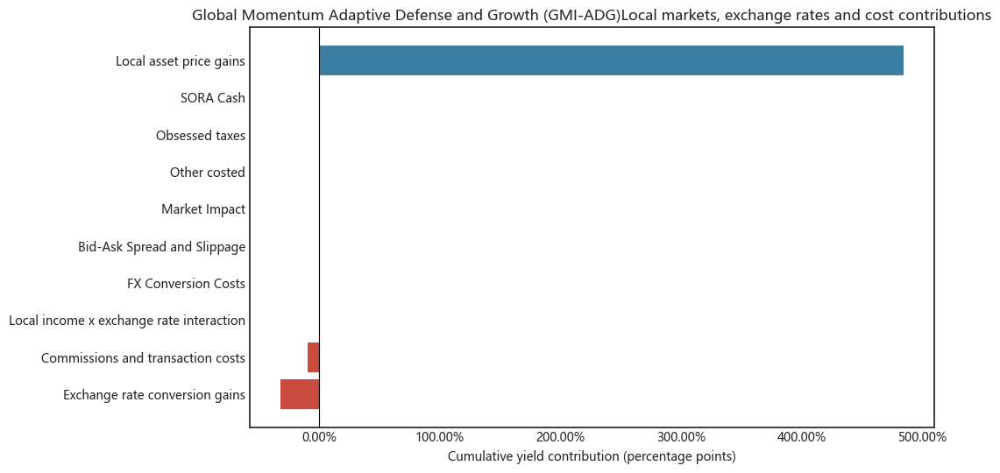

Local assets are attributed to the exchange rate: the SSD constant income equation, the daily net gain and the accumulated net gain have been reconciled.


In [53]:
def build_currency_attribution(daily_ledger, pre_return_weights, result, start, end):
    dates = result['returns'].loc[start:end].dropna().index
    asset_columns = list(result['weights'].columns)
    # The actual valuation calendar must be aligned before the proceeds are calculated. A common sample would remove dates that exceeded 5 days ' unquoted bid;
    # If the earnings are calculated first in the full workday calendar, China’s first gain after a long vacation will erroneously span only one day.
    valuation_index = portfolio_returns_for_backtest.index
    local_price_frame = local_bday.reindex(
        index=valuation_index, columns=asset_columns
    )
    local_return_frame = local_price_frame.pct_change(fill_method=None).reindex(dates)
    fx_return_frame = fx_to_sgd.reindex(valuation_index).pct_change(fill_method=None).reindex(dates)

    local_daily = pd.DataFrame(0.0, index=dates, columns=asset_columns)
    fx_daily = pd.DataFrame(0.0, index=dates, columns=asset_columns)
    interaction_daily = pd.DataFrame(0.0, index=dates, columns=asset_columns)
    reconstructed_asset_return = pd.DataFrame(0.0, index=dates, columns=asset_columns)

    for ticker in asset_columns:
        currency = asset_metadata.loc[ticker, 'Local Currency']
        local_r = local_return_frame[ticker].fillna(0.0)
        if currency == 'SGD':
            fx_r = pd.Series(0.0, index=dates)
        else:
            fx_r = fx_return_frame[currency].fillna(0.0)
        weights = pre_return_weights[ticker].reindex(dates).fillna(0.0)
        local_daily[ticker] = weights * local_r
        fx_daily[ticker] = weights * fx_r
        interaction_daily[ticker] = weights * local_r * fx_r
        reconstructed_asset_return[ticker] = local_r + fx_r + local_r * fx_r

    observed_asset_return = portfolio_returns_for_backtest.reindex(
        index=dates, columns=asset_columns
    ).fillna(0.0)
    active_mask = pre_return_weights.reindex(index=dates, columns=asset_columns).fillna(0.0).abs() > 1e-14
    pricing_error = (reconstructed_asset_return - observed_asset_return).where(active_mask, 0.0)
    maximum_pricing_error = float(pricing_error.abs().max().max())
    if maximum_pricing_error > 1e-10:
        largest = pricing_error.abs().stack().nlargest(8)
        raise RuntimeError(
            f'Local gains and exchange rate gains cannot re-construct SSD asset gains; maximum error ={maximum_pricing_error:.12g}；'
            f'Maximum error ={largest.to_dict()}'
        )

    components = pd.DataFrame(index=dates)
    components['Local asset price gains'] = local_daily.sum(axis=1)
    components['Exchange rate conversion gains'] = fx_daily.sum(axis=1)
    components['Local income x exchange rate interaction'] = interaction_daily.sum(axis=1)
    for column in ['SORA Cash', 'Commissions and transaction costs', 'FX Conversion Costs', 'Bid-Ask Spread and Slippage', 'Market Impact', 'Obsessed taxes', 'Other costed']:
        components[column] = daily_ledger[column].reindex(dates).fillna(0.0)
    strategy_return = result['returns'].reindex(dates)
    if not np.allclose(components.sum(axis=1), strategy_return, atol=1e-10, rtol=1e-9):
        raise RuntimeError('Currency attribution failed to reconcile with the daily net gains of the strategy.')
    return components, local_daily, fx_daily, interaction_daily, pricing_error


(
    currency_daily_components,
    local_asset_daily_contribution,
    fx_asset_daily_contribution,
    local_fx_interaction_daily,
    currency_pricing_error,
) = build_currency_attribution(
    daily_attribution, attribution_weights_daily, attribution_result,
    ATTRIBUTION_START, ATTRIBUTION_END,
)

currency_linked = geometrically_link_contributions(
    currency_daily_components,
    attribution_result['returns'].loc[ATTRIBUTION_START:ATTRIBUTION_END],
)
currency_attribution_table = pd.DataFrame({
    'Cumulative yield contribution (percentage points)': currency_linked,
    'End-of-cycle wealth contribution (SGD)': currency_linked * INITIAL_CAPITAL_SGD,
})
currency_attribution_table.loc['Final net gain'] = [
    currency_linked.sum(), currency_linked.sum() * INITIAL_CAPITAL_SGD,
]

def link_partial_components(partial_components, total_returns):
    # Linking a group of incomplete contributions with a grouping of assets at the beginning of the grouping period; this group is not required to be alone equal to a group of proceeds.
    total_returns = total_returns.reindex(partial_components.index).astype(float)
    wealth_before = (1.0 + total_returns).cumprod().shift(1, fill_value=1.0)
    return partial_components.mul(wealth_before, axis=0).sum(axis=0)


asset_currency_detail = pd.DataFrame({
    'Local market contributions': link_partial_components(
        local_asset_daily_contribution,
        attribution_result['returns'].loc[ATTRIBUTION_START:ATTRIBUTION_END],
    ),
    'Contribution of exchange rates': link_partial_components(
        fx_asset_daily_contribution,
        attribution_result['returns'].loc[ATTRIBUTION_START:ATTRIBUTION_END],
    ),
    'Interactive contributions': link_partial_components(
        local_fx_interaction_daily,
        attribution_result['returns'].loc[ATTRIBUTION_START:ATTRIBUTION_END],
    ),
})
asset_currency_detail['Total SGD asset contribution'] = asset_currency_detail.sum(axis=1)
asset_currency_detail['Local Currency'] = asset_metadata.loc[asset_currency_detail.index, 'Local Currency']
asset_currency_detail['Asset Name'] = asset_metadata.loc[asset_currency_detail.index, 'Asset Name']
asset_currency_detail = asset_currency_detail.sort_values('Total SGD asset contribution', ascending=False)

display(currency_attribution_table.style.format({
    'Cumulative yield contribution (percentage points)': '{:+.2%}', 'End-of-cycle wealth contribution (SGD)': '{:+,.0f}',
}))
display(asset_currency_detail.style.format({
    'Local market contributions': '{:+.2%}', 'Contribution of exchange rates': '{:+.2%}',
    'Interactive contributions': '{:+.2%}', 'Total SGD asset contribution': '{:+.2%}',
}))

plot_currency = currency_attribution_table.drop(index='Final net gain').sort_values('Cumulative yield contribution (percentage points)')
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.barh(
    plot_currency.index, plot_currency['Cumulative yield contribution (percentage points)'],
    color=np.where(plot_currency['Cumulative yield contribution (percentage points)'] >= 0, '#3B7EA1', '#C94C40'),
)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title(f'{ATTRIBUTION_STRATEGY}Local markets, exchange rates and cost contributions')
ax.set_xlabel('Cumulative yield contribution (percentage points)')
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=2))
plt.tight_layout()
plt.show()

assert currency_daily_components.index.max() < HOLDOUT_START
assert np.isclose(currency_linked.sum(), strategy_total_return, atol=1e-9)
print('Local assets are attributed to the exchange rate: the SSD constant income equation, the daily net gain and the accumulated net gain have been reconciled.')


### 8.8 External Market Factors and Internal Strategy Rules


“Dynamic risk budget increments” are strategic internal rules and are not tradable external market factors. In order to avoid increased mechanical alignment by adding internal variables, this section compares sequentially:

1. ** External market and style factors**: markets, regions, bonds, commodities, United States dollars, bitcoin and multi-asset momentum after one day;
** External factor + non-linear market status**: accession to non-linear items that are structured only by the global stock market history;
3. ** External factor + state + internal strategy rules**: dynamic risk budget increments are only added at the end.

Therefore, the first and second models should be given priority when judging whether there are remnants of Alpha in the strategy; the third model is mainly used to explain the strategy mechanisms.

,Number of factors,R Square,Adjusted R Square,Alphaization of remnants,Alpha HAC t,Alpha HAC p
Model,,,,,,
External markets and style factors,13,0.75,0.74,+3.45%,1.91,0.06
External factor + non-linear state,14,0.75,0.75,+3.21%,2.11,0.03
External factor + state + internal rules,15,0.87,0.86,+2.85%,2.45,0.01


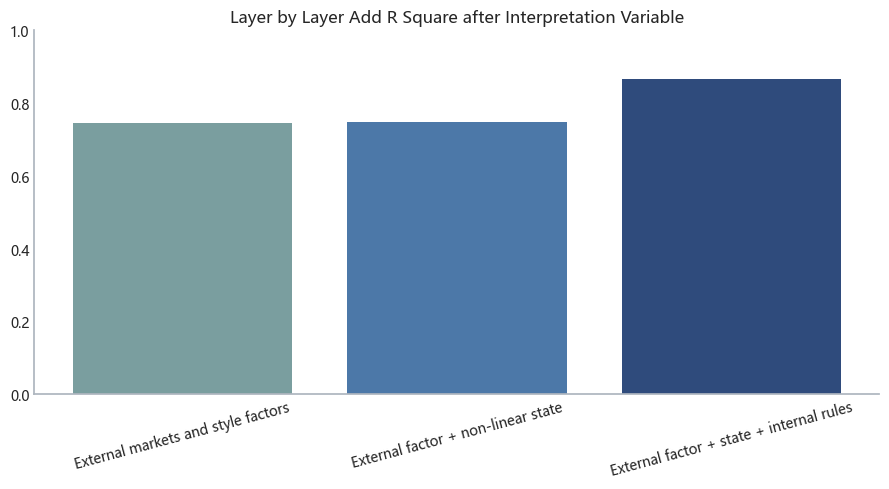

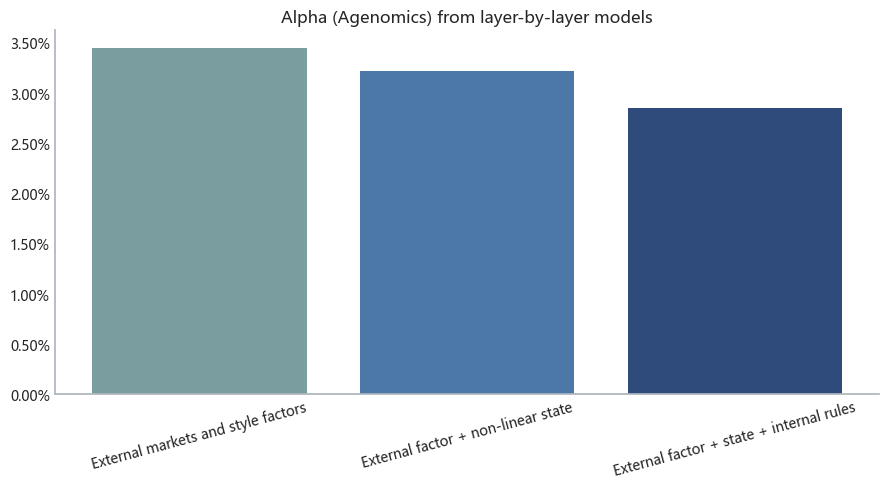

Principle of interpretation: External models are used to determine market and style exposure; internal rule models are used only for mechanism interpretation and not as primary evidence of Alpha ' s visibility.


In [54]:
def hac_factor_model(result, factor_frame, rf, start, end):
    strategy = result['returns'].loc[start:end].rename('Policy')
    aligned = pd.concat([
        strategy, rf.rename('SORA'), factor_frame,
    ], axis=1).dropna()
    y = aligned['Policy'] - aligned['SORA']
    x = sm.add_constant(aligned[factor_frame.columns])
    max_lags = max(1, int(4 * (len(aligned) / 100) ** (2 / 9)))
    model = sm.OLS(y, x).fit(cov_type='HAC', cov_kwds={'maxlags': max_lags})
    return model, aligned


internal_factor = 'Dynamic risk budget increment'
timing_factor = 'Non-linear stock selection'
external_columns = [
    column for column in expanded_factor_returns.columns
    if column not in [internal_factor, timing_factor]
]
factor_model_sets = {
    'External markets and style factors': external_columns,
    'External factor + non-linear state': external_columns + [timing_factor],
    'External factor + state + internal rules': external_columns + [timing_factor, internal_factor],
}

factor_layer_models = {}
factor_layer_records = []
for model_name, columns in factor_model_sets.items():
    model, aligned = hac_factor_model(
        attribution_result, expanded_factor_returns[columns], expanded_factor_rf,
        ATTRIBUTION_START, ATTRIBUTION_END,
    )
    factor_layer_models[model_name] = model
    factor_layer_records.append({
        'Model': model_name,
        'Number of factors': len(columns),
        'R Square': float(model.rsquared),
        'Adjusted R Square': float(model.rsquared_adj),
        'Alphaization of remnants': float(model.params['const'] * TRADING_DAYS),
        'Alpha HAC t': float(model.tvalues['const']),
        'Alpha HAC p': float(model.pvalues['const']),
    })

factor_layer_comparison = pd.DataFrame(factor_layer_records).set_index('Model')
display(factor_layer_comparison.style.format({
    'R Square': '{:.2f}', 'Adjusted R Square': '{:.2f}',
    'Alphaization of remnants': '{:+.2%}', 'Alpha HAC t': '{:.2f}', 'Alpha HAC p': '{:.2f}',
}))

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(factor_layer_comparison.index, factor_layer_comparison['R Square'], color=['#7A9E9F', '#4C78A8', '#2F4B7C'])
ax.set_title('Layer by Layer Add R Square after Interpretation Variable')
ax.set_ylim(0, 1)
ax.tick_params(axis='x', rotation=15)
style_axis(ax, axis='y')
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(factor_layer_comparison.index, factor_layer_comparison['Alphaization of remnants'], color=['#7A9E9F', '#4C78A8', '#2F4B7C'])
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title('Alpha (Agenomics) from layer-by-layer models')
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=2))
ax.tick_params(axis='x', rotation=15)
style_axis(ax, axis='y')
fig.tight_layout()
plt.show()

print('Principle of interpretation: External models are used to determine market and style exposure; internal rule models are used only for mechanism interpretation and not as primary evidence of Alpha \' s visibility.')


### 8.9 Two-Year Rolling Alpha and Beta Stability


The return of the whole sample will mean that the different stages of the market are on average combined. This section uses 504 trading day rolling windows to observe the stability of global exposures to stocks, bonds, gold, United States dollars, bitcoin and momentum on each date only using data from that date and earlier. A rolling cut-off is only a conditional description and cannot be interpreted as realizing future gains.

,Latest value [v],Medium,Ten percent.,90% part
const,+0.00,+0.00,-0.00,+0.00
Global equities,+0.02,+0.12,+0.07,+0.23
US Medium Term National Debt,+0.11,+0.03,-0.09,+0.24
Gold,+0.22,+0.14,+0.08,+0.24
United States dollars,+0.04,+0.15,+0.00,+0.17
Bitcoin.,+0.09,+0.06,+0.03,+0.11
Multi-asset momentum,+0.38,+0.24,+0.10,+0.36
Scroll Alpha Annualization,+0.12,+0.01,-0.03,+0.05


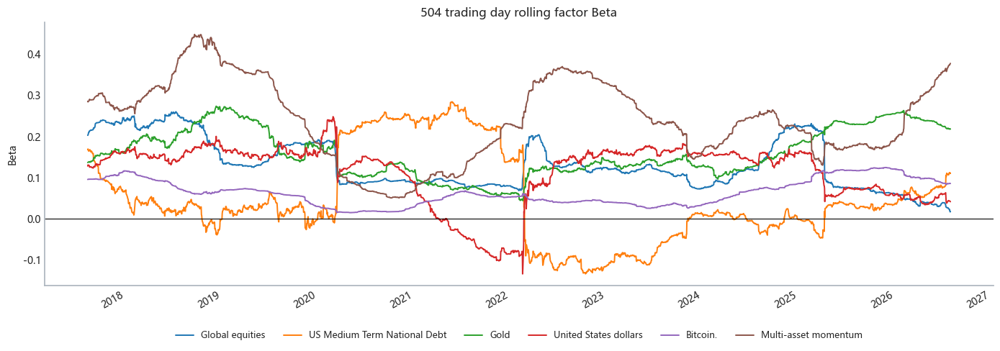

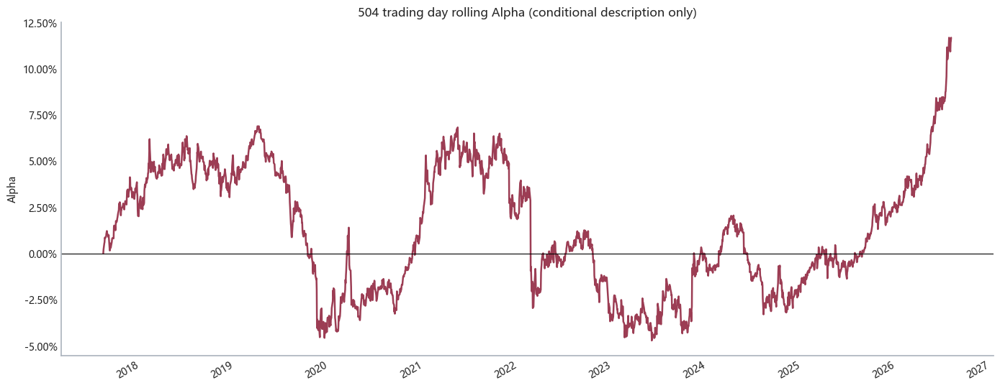

Rolling attribution complete: Only 504 transaction days backwards are used at each point of time without reading off-species locking data.


In [55]:
from statsmodels.regression.rolling import RollingOLS

ROLLING_FACTOR_COLUMNS = ['Global equities', 'US Medium Term National Debt', 'Gold', 'United States dollars', 'Bitcoin.', 'Multi-asset momentum']
rolling_strategy = attribution_result['returns'].loc[ATTRIBUTION_START:ATTRIBUTION_END].rename('Policy')
rolling_frame = pd.concat([
    rolling_strategy,
    expanded_factor_rf.rename('SORA'),
    expanded_factor_returns[ROLLING_FACTOR_COLUMNS],
], axis=1).dropna()
rolling_y = rolling_frame['Policy'] - rolling_frame['SORA']
rolling_x = sm.add_constant(rolling_frame[ROLLING_FACTOR_COLUMNS])
rolling_fit = RollingOLS(
    rolling_y, rolling_x, window=504, min_nobs=378,
).fit(params_only=True)
rolling_parameters = rolling_fit.params.dropna(how='all')
rolling_parameters['Scroll Alpha Annualization'] = rolling_parameters['const'] * TRADING_DAYS

rolling_parameter_summary = pd.DataFrame({
    'Latest value [v]': rolling_parameters.iloc[-1],
    'Medium': rolling_parameters.median(),
    'Ten percent.': rolling_parameters.quantile(0.10),
    '90% part': rolling_parameters.quantile(0.90),
})
display(rolling_parameter_summary.style.format('{:+.2f}'))

fig, ax = plt.subplots(figsize=(14, 6))
rolling_parameters[ROLLING_FACTOR_COLUMNS].plot(ax=ax, linewidth=1.4, style='-')
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title('504 trading day rolling factor Beta')
ax.set_ylabel('Beta')
style_axis(ax)
place_legend(ax)
fig.tight_layout(rect=[0, 0.16, 1, 1])
plt.show()

fig, ax = plt.subplots(figsize=(14, 5.5))
rolling_parameters['Scroll Alpha Annualization'].plot(ax=ax, color='#9C3D54', linewidth=1.8, linestyle='-')
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title('504 trading day rolling Alpha (conditional description only)')
ax.set_ylabel('Alpha')
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=2))
style_axis(ax)
fig.tight_layout()
plt.show()

assert rolling_parameters.index.max() < HOLDOUT_START
print('Rolling attribution complete: Only 504 transaction days backwards are used at each point of time without reading off-species locking data.')


### 8.10 Shapley Attribution for the Three Core Strategies


The elimination of a fixed order gives the module ' s interactive proceeds to all subsequent modules. This section re-measures all eight combinations of the following three modules under the same asset pool, frequency of inspection on the same 15-day date, execution on the same transaction date and the same cost assumption:

- Carbide Top10 screening;
- EWMA strict risk parity;
- A fully dynamic double-tier risk budget.

An average marginal contribution (Shapley value) is then taken for all accession sequences. It answers “what is the average increment of the modules to the cumulative proceeds in the unified anti-facts agreement” and is not a statistical factor, Alpha, nor is it equivalent to the causal conclusion.
This section only divides the three investment modules of the drive screening, EWMA strict risk parity and a fully dynamic double-tier risk budget. The classification of the final submission strategy, the no-trade zone, the 50 per cent partial implementation, the sub-asset transaction costs and the exchange costs do not enter the Shapley Alliance; these implementation impacts are explained by the incrementality of the strategy modules in this section and the attribution of the wear and tear of the transaction.

,Number of modules,Cumulative Return
Enable module,,
No module,0,201.13%
A fully dynamic two-tier risk budget,1,877.64%
Driver Top10 Filter,1,342.78%
EWMA strict risk parity,1,83.89%
Driver Top10 Filter＋A fully dynamic two-tier risk budget,2,1093.17%
Driver Top10 Filter＋EWMA strict risk parity,2,205.27%
EWMA strict risk parity＋A fully dynamic two-tier risk budget,2,107.55%
Driver Top10 Filter＋EWMA strict risk parity＋A fully dynamic two-tier risk budget,3,269.97%


,Cumulative gain increase
Driver Top10 Filter,+157.51%
EWMA strict risk parity,-464.75%
A fully dynamic two-tier risk budget,+376.07%
Cumulative gain from no module baseline,+201.13%
Cumulative benefits of a complete combination of three modules,+269.97%


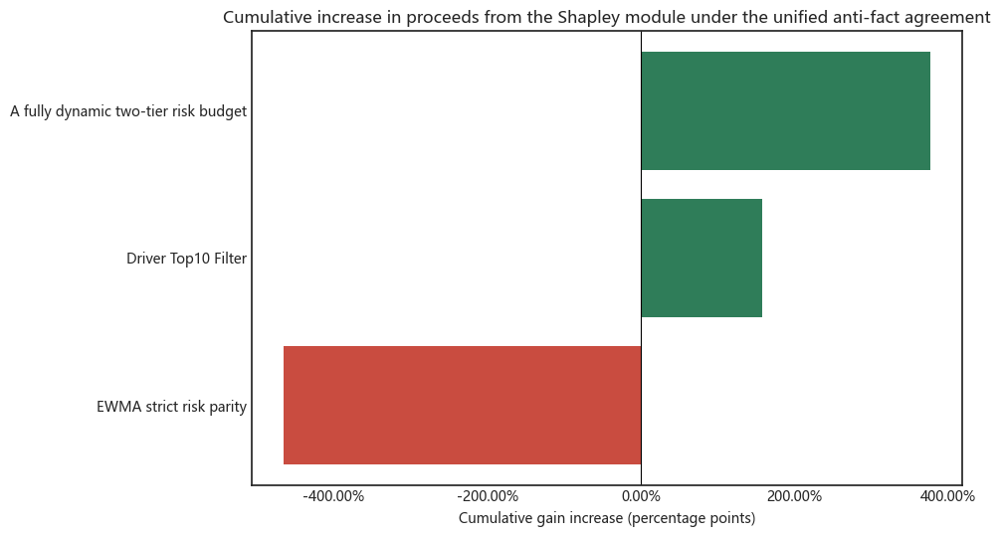

The Shapley module is attributed to the fact that all eight counterfacts use the same execution, cost and research areas, and the contribution can be strictly aggregated.


,Cumulative Return,Include dynamic offensive and classification execution
Shapley Three Module Full Alliance,269.97%,False
Final Submission Policy,441.52%,True


Synopsis: Shapley only explains the core investment model; the final enforcement layer is explained by a fixed sequence of increments and trade wear and tear.


In [56]:
from itertools import combinations
from math import factorial

SHAPLEY_MODULES = ['Driver Top10 Filter', 'EWMA strict risk parity', 'A fully dynamic two-tier risk budget']


def run_module_coalition(enabled_modules, start=ATTRIBUTION_START, end=ATTRIBUTION_END):
    enabled = set(enabled_modules)
    frame = returns.loc[:end, ALL_ASSETS]
    dates = frame.loc[start:end].index
    rf = align_sora_returns(dates, sora_daily_df)
    current = pd.Series(0.0, index=ALL_ASSETS, dtype=float)
    pending = None
    records = []
    first_location = frame.index.get_loc(dates[0])

    for date in dates:
        location = frame.index.get_loc(date)
        day = frame.loc[date]
        cash_weight = 1.0 - float(current.sum())
        gross = float(current @ day) + cash_weight * float(rf.loc[date])
        if 1.0 + gross <= 0:
            raise RuntimeError('Shapley\'s counter-fact net is not positive.')
        current = current * (1.0 + day) / (1.0 + gross)

        cost_rate = 0.0
        if pending is not None:
            if not pending['Signal Date'] < date:
                raise RuntimeError('Shapley\'s counter-fact signal is closed.')
            target = pending['Target weights']
            turnover = float((target - current).abs().sum())
            cost_rate = COST * turnover
            current = target.copy()
            pending = None

        net = (1.0 - cost_rate) * (1.0 + gross) - 1.0
        records.append((date, net))

        if (location - first_location) % CHECK_INTERVAL == 0:
            history = frame.iloc[location - LOOKBACK + 1:location + 1]
            if len(history) != LOOKBACK or history.index.max() != date:
                raise RuntimeError('The Shapley Anti-Fact History window does not strictly close to signal day closing or insufficient length.')
            score = momentum_12_1(history)
            if 'Driver Top10 Filter' in enabled:
                selected = score.nlargest(TOP_N).index.tolist()
            else:
                selected = ALL_ASSETS.copy()

            if 'A fully dynamic two-tier risk budget' in enabled:
                budget = fully_dynamic_budget(history, selected, score)
            else:
                budget = pd.Series(1.0 / len(selected), index=selected)

            if 'EWMA strict risk parity' in enabled:
                selected_weight = strict_risk_budget(
                    ewma_covariance(history[selected]), budget,
                )
            else:
                selected_weight = budget / budget.sum()
            target = selected_weight.reindex(ALL_ASSETS, fill_value=0.0)
            target = target / target.sum()
            pending = {'Signal Date': date, 'Target weights': target}

    series = pd.Series(dict(records), name='Strategic gains', dtype=float)
    if series.index.max() >= HOLDOUT_START:
        raise RuntimeError('Shapley read out-of-species lock data against the facts.')
    return series


coalition_returns = {}
coalition_values = {}
for size in range(len(SHAPLEY_MODULES) + 1):
    for subset in combinations(SHAPLEY_MODULES, size):
        key = frozenset(subset)
        series = run_module_coalition(key)
        coalition_returns[key] = series
        coalition_values[key] = float((1.0 + series).prod() - 1.0)

module_shapley = {}
n_modules = len(SHAPLEY_MODULES)
for module in SHAPLEY_MODULES:
    contribution = 0.0
    other_modules = [item for item in SHAPLEY_MODULES if item != module]
    for size in range(len(other_modules) + 1):
        for subset in combinations(other_modules, size):
            subset_key = frozenset(subset)
            weight = factorial(size) * factorial(n_modules - size - 1) / factorial(n_modules)
            contribution += weight * (
                coalition_values[subset_key | {module}] - coalition_values[subset_key]
            )
    module_shapley[module] = contribution

empty_key = frozenset()
full_key = frozenset(SHAPLEY_MODULES)
shapley_table = pd.DataFrame({
    'Cumulative gain increase': pd.Series(module_shapley),
})
shapley_table.loc['Cumulative gain from no module baseline', 'Cumulative gain increase'] = coalition_values[empty_key]
shapley_table.loc['Cumulative benefits of a complete combination of three modules', 'Cumulative gain increase'] = coalition_values[full_key]

coalition_table = pd.DataFrame([
    {
        'Enable module': '＋'.join([m for m in SHAPLEY_MODULES if m in key]) if key else 'No module',
        'Number of modules': len(key),
        'Cumulative Return': value,
    }
    for key, value in coalition_values.items()
]).sort_values(['Number of modules', 'Enable module']).set_index('Enable module')

display(coalition_table.style.format({'Cumulative Return': '{:.2%}'}))
display(shapley_table.style.format({'Cumulative gain increase': '{:+.2%}'}))

fig, ax = plt.subplots(figsize=(10, 5.5))
shapley_plot = pd.Series(module_shapley).sort_values()
ax.barh(shapley_plot.index, shapley_plot.values, color=np.where(shapley_plot.values >= 0, '#2F7D59', '#C94C40'))
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Cumulative increase in proceeds from the Shapley module under the unified anti-fact agreement')
ax.set_xlabel('Cumulative gain increase (percentage points)')
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=2))
plt.tight_layout()
plt.show()

assert np.isclose(
    sum(module_shapley.values()),
    coalition_values[full_key] - coalition_values[empty_key],
    atol=1e-10,
), 'The Shapley module contribution cannot be reconciled with the full combination of the incremental base.'
print('The Shapley module is attributed to the fact that all eight counterfacts use the same execution, cost and research areas, and the contribution can be strictly aggregated.')

# Shapley's complete alliance should only respond to the core investment model and should not be confused with a submission strategy containing dynamic offensive and classification enforcement rules.
shapley_scope_audit = pd.DataFrame({
    'Cumulative Return': [
        coalition_values[full_key],
        float((1.0 + results[SUBMISSION_STRATEGY]['returns'].loc[ATTRIBUTION_START:ATTRIBUTION_END]).prod() - 1.0),
    ],
    'Include dynamic offensive and classification execution': [False, True],
}, index=['Shapley Three Module Full Alliance', 'Final Submission Policy'])
display(shapley_scope_audit.style.format({'Cumulative Return': '{:.2%}'}))
print('Synopsis: Shapley only explains the core investment model; the final enforcement layer is explained by a fixed sequence of increments and trade wear and tear.')


### 8.11 Attribution Definitions and Interpretation Boundaries


- **The asset/currency attribution** is a precise accounting split that can be answered as to which assets, local market or exchange rate the net gain is derived;
- **External factor regression** depicts market Beta, region, asset class and dynamic style exposure, and the residual Alpha remains model-dependent estimation;
- **Scroll back** to check if exposure changes over time and not to select the best space;
- **Shapley module attribution** covers only the three core investment modules of kinetic, EWMA strict risk parity and a fully dynamic double-tier budget; it does not cover the implementation and cost-sharing of assets for the final submission strategy, nor does it prove economic causes and consequences;
- **The reason for the wear and tear of the transaction** continues to be responsible for explaining how gross gains are consumed at cost;
- All new analyses have been completed at 2026-07-31, without reading the off-species data from 2026-08-01.

### 8.12 Unified Cross-Sectional Attribution of the Three Core Strategies

The above details are attributed to the retention of the day-to-day audit depth of the final submission strategy; this section is then calculated in the same study compartments and functions as the three core strategies:

- Contribution of cumulative proceeds to asset classes;
- Gross proceeds of assets, SORA and losses due to transactions;
- The return of the 4-factor Beta, the residual Alpha and its prominence.

This makes it possible to make a direct judgement as to the type of asset from which the offensive pellets were increased, how much trade losses were incurred and whether the existing market, Beta, was only amplified. All attributions are up to 2026-07-31 without reading the locking test set.

Asset Class,Bonds,Cash,Commodities,Crypto,Equities,FX,Trading Friction
Policy,,,,,,,
Global Momentum Adaptive Hierarchical Risk Budget (GMI-AHRB),-1.10%,+0.00%,+83.83%,+69.78%,+116.55%,+10.52%,-8.59%
Global Momentum Fixed Offensive Allocation (GMI-FOA),+0.89%,+1.94%,+114.66%,+139.25%,+107.91%,+10.51%,-12.63%
Global Momentum Adaptive Defense and Growth (GMI-ADG),-2.93%,+0.00%,+129.50%,+149.62%,+164.58%,+10.50%,-9.76%


,Contribution of gross proceeds from assets,SORA Cash Contribution,Traded wear and tear,Final net accrued gain,Annual One-Way Turnover,Maximum daily reconciliation error
Policy,,,,,,
Global Momentum Adaptive Hierarchical Risk Budget (GMI-AHRB),+279.58%,+0.00%,-8.59%,+270.99%,397.89%,2.65e-16
Global Momentum Fixed Offensive Allocation (GMI-FOA),+373.23%,+1.94%,-12.63%,+362.55%,446.31%,2.23e-16
Global Momentum Adaptive Defense and Growth (GMI-ADG),+451.27%,+0.00%,-9.76%,+441.52%,342.17%,2.36e-16


,Global stocks Beta,Medium-term national debt Beta,Commodities Beta,US$ Beta,Alphaization of remnants,Alpha HAC t,Alpha HAC p,Return R Square
Policy,,,,,,,,
Global Momentum Adaptive Hierarchical Risk Budget (GMI-AHRB),0.14,0.16,0.15,0.08,+8.12%,3.87,0.00,0.31
Global Momentum Fixed Offensive Allocation (GMI-FOA),0.14,0.14,0.19,0.08,+10.04%,3.38,0.00,0.22
Global Momentum Adaptive Defense and Growth (GMI-ADG),0.15,0.17,0.17,0.10,+11.47%,3.93,0.00,0.23


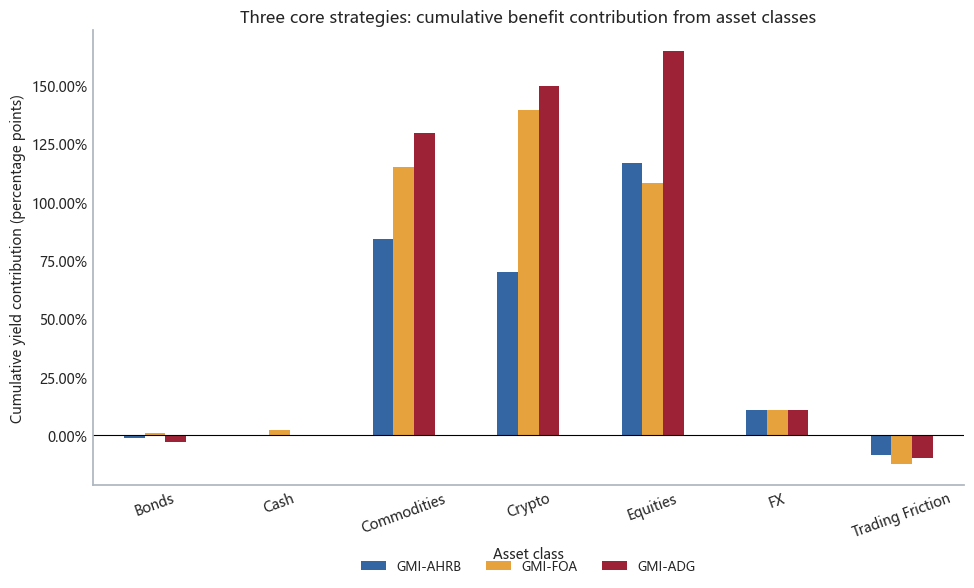

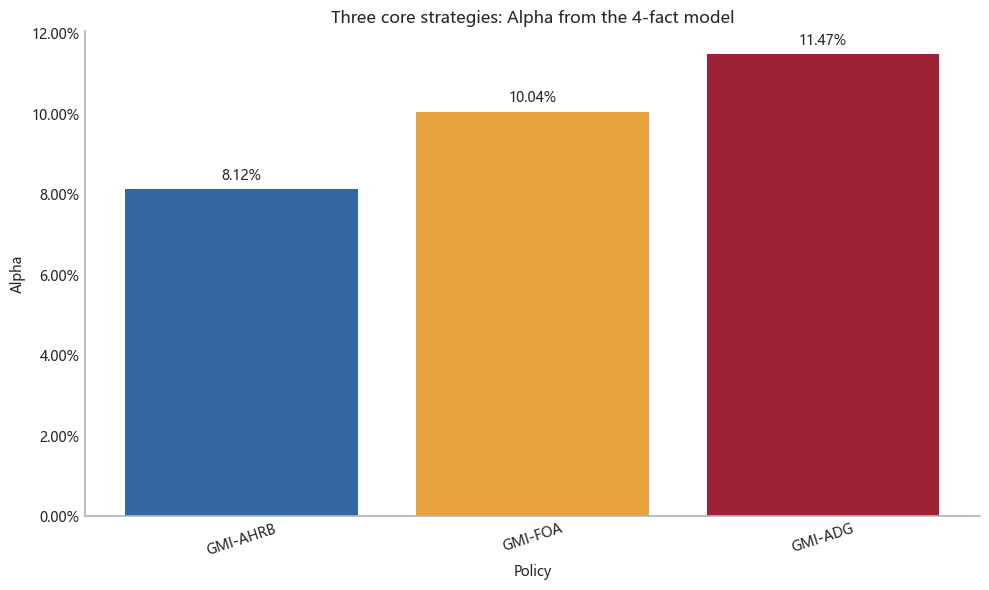

The three core strategy categories of contribution, trade wear and tear, and the 4-factor Alpha horizontal attribution were completed.


In [57]:
core_category_records = []
core_friction_records = []
core_factor_records = []

for strategy_name in CORE_COMPARISON_STRATEGIES:
    strategy_result = results[strategy_name]
    ledger, daily_weights, trades, reconciliation = build_daily_attribution_ledger(
        strategy_result, ATTRIBUTION_START, ATTRIBUTION_END
    )
    strategy_period_returns = strategy_result['returns'].loc[
        ATTRIBUTION_START:ATTRIBUTION_END
    ].dropna()
    linked = geometrically_link_contributions(ledger, strategy_period_returns)

    for item_name, contribution in linked.items():
        if item_name in asset_metadata.index:
            contribution_class = asset_metadata.loc[item_name, 'Asset Class']
        elif item_name == 'SORA Cash':
            contribution_class = 'Cash'
        else:
            contribution_class = 'Trading Friction'
        core_category_records.append({
            'Policy': strategy_name,
            'Asset Class': contribution_class,
            'Cumulative proceeds contribution': float(contribution),
        })

    asset_columns = [column for column in ledger.columns if column in strategy_result['weights'].columns]
    wear_daily_local = pd.DataFrame(index=ledger.index)
    wear_daily_local['Gross proceeds from assets'] = ledger[asset_columns].sum(axis=1)
    wear_daily_local['SORA cash proceeds'] = ledger['SORA Cash']
    wear_daily_local['Traded wear and tear'] = ledger[
        ['Commissions and transaction costs', 'FX Conversion Costs', 'Bid-Ask Spread and Slippage', 'Market Impact', 'Obsessed taxes', 'Other costed']
    ].sum(axis=1)
    wear_linked_local = geometrically_link_contributions(
        wear_daily_local, strategy_period_returns
    )
    metric = compute_metrics(strategy_result, ATTRIBUTION_START, ATTRIBUTION_END)
    core_friction_records.append({
        'Policy': strategy_name,
        'Contribution of gross proceeds from assets': float(wear_linked_local['Gross proceeds from assets']),
        'SORA Cash Contribution': float(wear_linked_local['SORA cash proceeds']),
        'Traded wear and tear': float(wear_linked_local['Traded wear and tear']),
        'Final net accrued gain': float(wear_linked_local.sum()),
        'Annual One-Way Turnover': float(metric['Annual One-Way Turnover']),
        'Maximum daily reconciliation error': float(reconciliation.abs().max()),
    })

    factor_table, factor_daily, factor_model_local = factor_performance_attribution(
        strategy_result, ATTRIBUTION_START, ATTRIBUTION_END
    )
    core_factor_records.append({
        'Policy': strategy_name,
        'Global stocks Beta': float(factor_model_local.params['Global equities']),
        'Medium-term national debt Beta': float(factor_model_local.params['Medium-term national debt']),
        'Commodities Beta': float(factor_model_local.params['Commodity basket']),
        'US$ Beta': float(factor_model_local.params['United States dollars']),
        'Alphaization of remnants': float(factor_model_local.params['const'] * TRADING_DAYS),
        'Alpha HAC t': float(factor_model_local.tvalues['const']),
        'Alpha HAC p': float(factor_model_local.pvalues['const']),
        'Return R Square': float(factor_model_local.rsquared),
    })

core_category_contribution = (
    pd.DataFrame(core_category_records)
    .groupby(['Policy', 'Asset Class'])['Cumulative proceeds contribution'].sum()
    .unstack('Asset Class').fillna(0.0)
    .reindex(CORE_COMPARISON_STRATEGIES)
)
core_friction_comparison = pd.DataFrame(core_friction_records).set_index('Policy')
core_factor_comparison = pd.DataFrame(core_factor_records).set_index('Policy')

display(core_category_contribution.style.format('{:+.2%}'))
display(core_friction_comparison.style.format({
    'Contribution of gross proceeds from assets': '{:+.2%}', 'SORA Cash Contribution': '{:+.2%}',
    'Traded wear and tear': '{:+.2%}', 'Final net accrued gain': '{:+.2%}',
    'Annual One-Way Turnover': '{:.2%}', 'Maximum daily reconciliation error': '{:.2e}',
}))
display(core_factor_comparison.style.format({
    'Global stocks Beta': '{:.2f}', 'Medium-term national debt Beta': '{:.2f}',
    'Commodities Beta': '{:.2f}', 'US$ Beta': '{:.2f}',
    'Alphaization of remnants': '{:+.2%}', 'Alpha HAC t': '{:.2f}',
    'Alpha HAC p': '{:.2f}', 'Return R Square': '{:.2f}',
}))

core_category_plot = core_category_contribution.rename(index=strategy_label)
fig, ax = plt.subplots(figsize=(12, 6))
core_category_plot.T.plot(
    kind='bar', ax=ax,
    color=[STRATEGY_COLORS[name] for name in core_category_contribution.index],
)
ax.axhline(0.0, color='black', linewidth=0.8)
ax.set_title('Three core strategies: cumulative benefit contribution from asset classes')
ax.set_xlabel('Asset class')
ax.set_ylabel('Cumulative yield contribution (percentage points)')
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=2))
ax.tick_params(axis='x', rotation=20)
style_axis(ax, axis='y')
place_legend(ax)
fig.tight_layout(rect=[0, 0, 0.82, 1])
plt.show()

core_factor_comparison = core_factor_comparison.reindex(CORE_COMPARISON_STRATEGIES)
factor_plot = core_factor_comparison[['Alphaization of remnants']].copy()
factor_plot.index = [strategy_label(name) for name in factor_plot.index]
fig, ax = plt.subplots(figsize=(10, 6))
alpha_values = factor_plot['Alphaization of remnants'].to_numpy(dtype=float)
alpha_bars = ax.bar(
    factor_plot.index, alpha_values,
    color=[STRATEGY_COLORS[name] for name in core_factor_comparison.index],
)
ax.bar_label(alpha_bars, labels=[f'{value:.2%}' for value in alpha_values],
             padding=4, fontsize=10)
ax.axhline(0.0, color='black', linewidth=0.8)
ax.set_title('Three core strategies: Alpha from the 4-fact model')
ax.set_xlabel('Policy')
ax.set_ylabel('Alpha')
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0, decimals=2))
ax.tick_params(axis='x', rotation=18)
style_axis(ax, axis='y')
fig.tight_layout()
plt.show()

if core_friction_comparison['Maximum daily reconciliation error'].max() > 1e-10:
    raise RuntimeError('The three core strategies are attributed horizontally to daily reconciliation errors.')
if any(results[name]['returns'].loc[ATTRIBUTION_START:ATTRIBUTION_END].index.max() >= HOLDOUT_START
       for name in CORE_COMPARISON_STRATEGIES):
    raise RuntimeError('The three core strategies are attributed horizontally to the reading of the lock test set.')
print('The three core strategy categories of contribution, trade wear and tear, and the 4-factor Alpha horizontal attribution were completed.')


# Part IX. Supplementary Visuals for Strategy Mechanics and Product Comparison

Use global colours and fonts without changing formal policy parameters. These include research paths, seven-step constructions, profit retreats, core annual hot pursuits, implementation of offensive targets and status, three risk budget snapshots, market status returns, and three joint retreat repair windows. Pictures with CSV exported to `report_work/visual_diagnostics`.

The EWMA matrix is available on the day of the use of the risk snapshot to hold the warehouse after the real deal. The object of the attack was not an independent offensive sub-account; the market situation was described ex post and was not used as evidence to predict Alpha in advance.

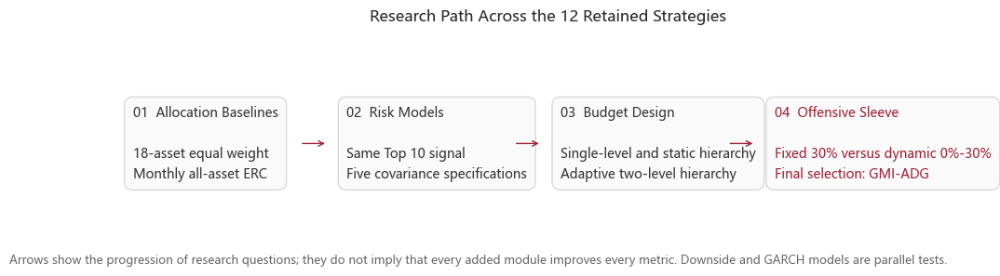

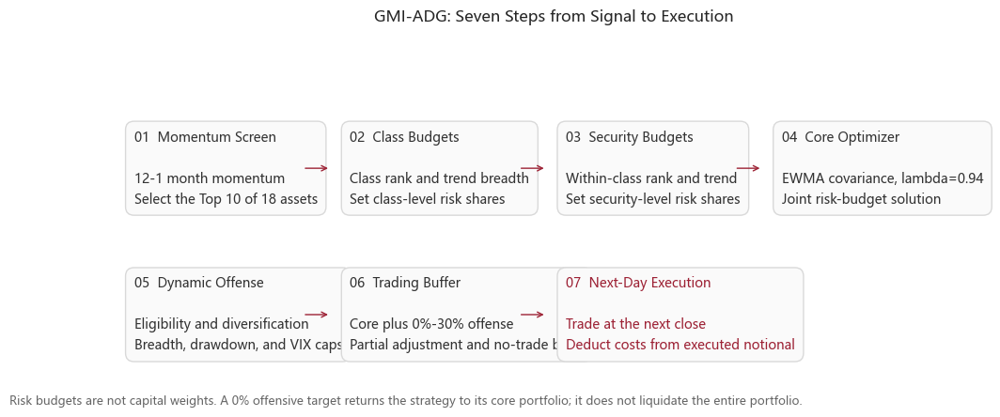

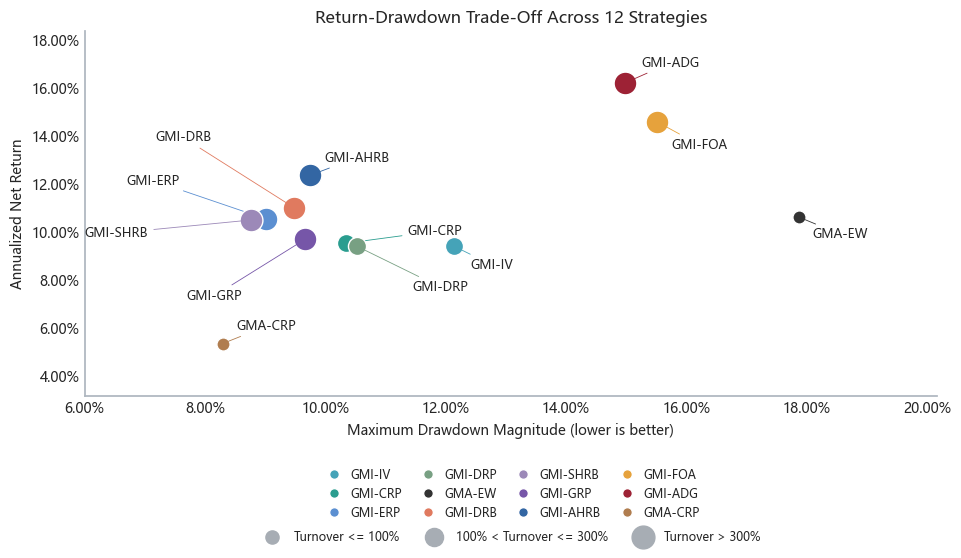

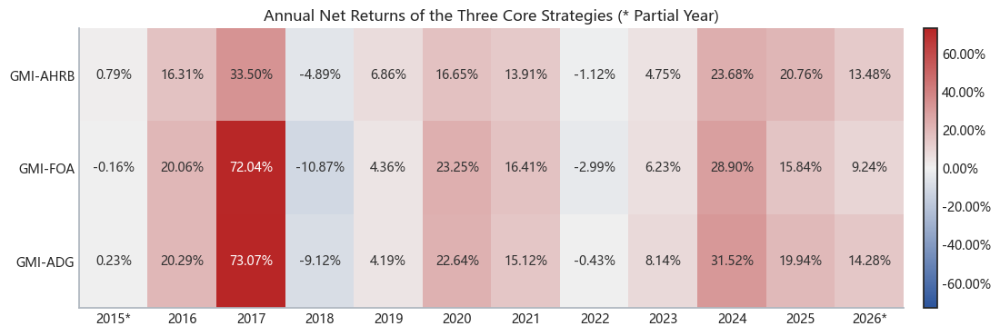

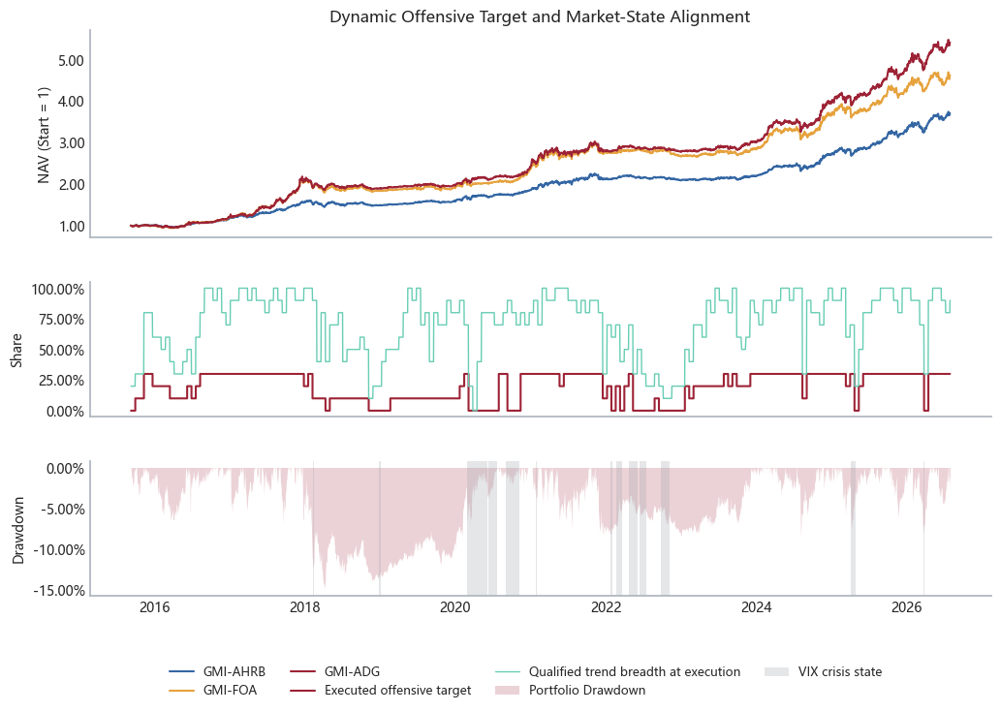

...

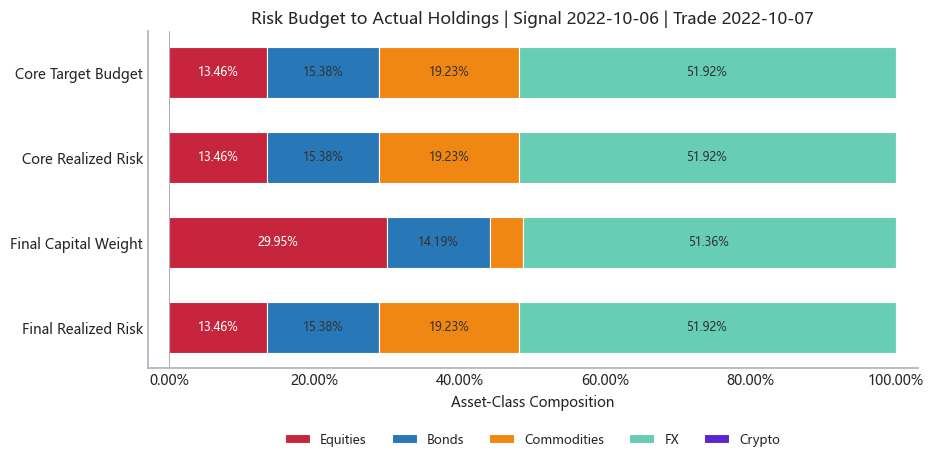

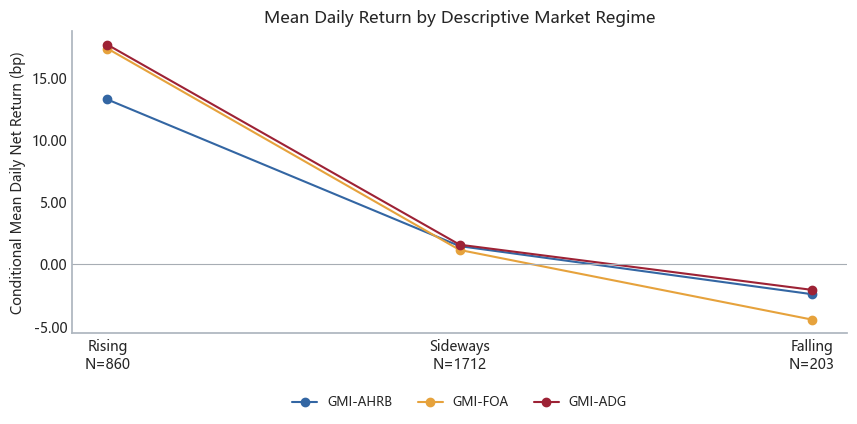

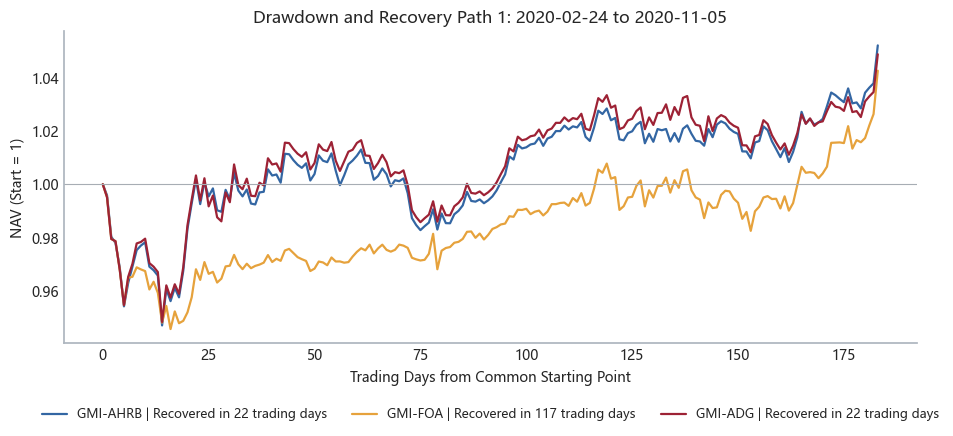

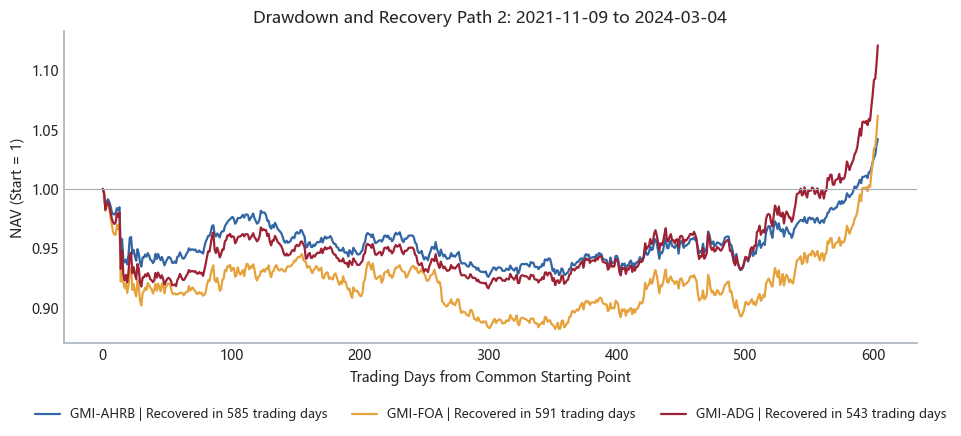

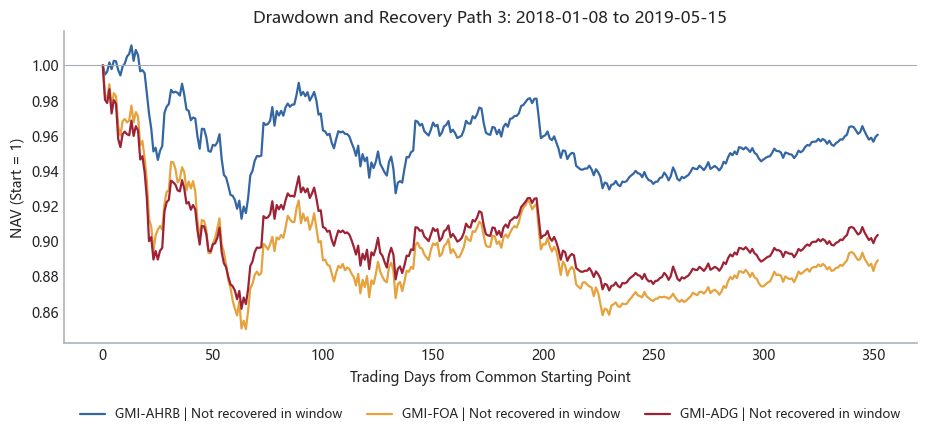

Supplementary charts and CSV directory: c:\Users\lenovo\desk\MF5209\MFE5209_Global_Multi_Asset_Adaptive_Allocation_English\explore\report_work\visual_diagnostics


In [58]:
from visual_diagnostics import build_visual_diagnostics
PROJECT_ROOT = Path.cwd()
visual_diagnostics = build_visual_diagnostics(globals())
print('Supplementary charts and CSV directory:', visual_diagnostics['output_dir'])


## Part X. Final Product Evaluation and Course Data Export

### 10.1 Historical validation and the October test

The final product is GMI-ADG. The planned formal evaluation is 2026-10-01 through 2026-10-31. Before the period finishes, the default evaluation returns PENDING. Historical validation can be reported separately, with its model-selection limitations disclosed. Update `data/raw/raw sora.csv` in the parent project folder with the unedited MAS export before running the final product.

### 10.2 One-call evaluation and closing-price export

The function below replays existing holdings and execution state, then evaluates only the requested interval. It delegates to the same standalone final-product evaluator as `code/main.py`, exporting four-series metrics, FIFO trades, daily NAV/P&L, weights and comparison figures. Observed exchange-session quotes are checked before a full test can be called complete. Price exports include all 18 assets, unadjusted local closes, adjusted local closes and adjusted SGD closes.

After October ends, call `evaluate_final_product()`. For a partial observation use `evaluate_final_product(allow_partial=True)`.

To export prices already loaded by this notebook, call `export_asset_closing_prices(globals(), 'submission_data', end=RESEARCH_END)`.

In [59]:
from product_evaluation import evaluate_final_product, export_asset_closing_prices
# Run after the formal test period ends and SORA has been updated:
# product = evaluate_final_product(start='2026-10-01', end='2026-10-31')
# Historical validation (report separately from the October test):
# historical = evaluate_final_product(start='2025-01-01', end='2026-07-31',
#     output_dir='historical_product_outputs')
# Export data from the current notebook session:
# price_files = export_asset_closing_prices(globals(), 'submission_data', end=RESEARCH_END)
